All cells must be independent

SCC (3 blocks): max |block - mean| = 0.69 kJ/mol; SE mean = 0.14, max = 0.35 kJ/mol
SCS (3 blocks): max |block - mean| = 1.78 kJ/mol; SE mean = 0.36, max = 0.90 kJ/mol
SCY (3 blocks): max |block - mean| = 0.76 kJ/mol; SE mean = 0.18, max = 0.42 kJ/mol
SCD (3 blocks): max |block - mean| = 1.24 kJ/mol; SE mean = 0.29, max = 0.63 kJ/mol
SCL (2 blocks): max |block - mean| = 0.87 kJ/mol; SE mean = 0.42, max = 0.87 kJ/mol
SCW (3 blocks): max |block - mean| = 1.82 kJ/mol; SE mean = 0.32, max = 0.95 kJ/mol


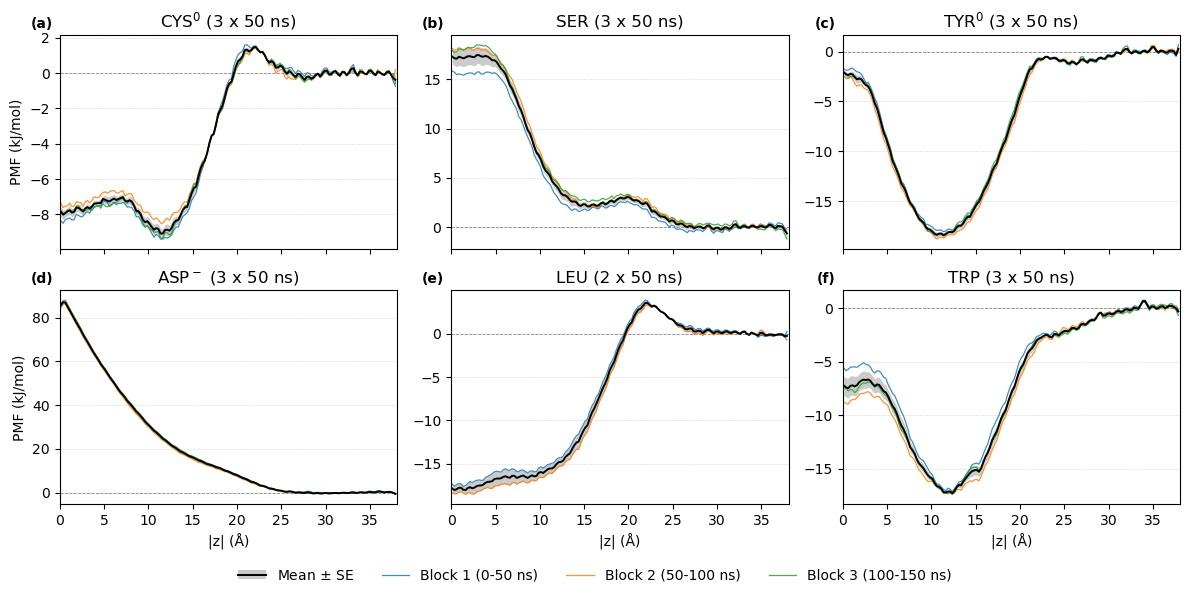

In [67]:
# Umbrella convergence: available 50 ns block PMFs and their final mean +/- SE (independent cell).
# SCL has two blocks; the other analogs, including SCW, have three.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ANALOGS = {"scc": r"CYS$^0$", "scs": "SER", "scy": r"TYR$^0$", "scd": r"ASP$^-$",
           "scl": "LEU", "scw": "TRP"}
BLOCKS = ("block1", "block2", "block3")
BLOCK_NS = 50
BLOCK_COLORS = ("tab:blue", "tab:orange", "tab:green")
ENERGY_UNIT = "kJ/mol"  # "kJ/mol" (manuscript convention) or "kcal/mol" (native WHAM output)
KCAL_TO_KJ = 4.184
SAVE_NAME = "FigureS_US_block_convergence"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures/data/SUPP_umbrella_sampling/pmf").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_pmf(path):
    df = pd.read_csv(path, sep=r"\s+", comment="#", header=None, names=["z", "pmf", "se", "n"])
    if (len(df) < 2 or not np.isfinite(df.to_numpy()).all()
            or (df["se"] < 0).any() or np.any(np.diff(df["z"]) <= 0)):
        raise ValueError(f"Invalid umbrella PMF: {path}")
    if ENERGY_UNIT == "kJ/mol":
        df[["pmf", "se"]] *= KCAL_TO_KJ
    return df


ROOT = find_repo_root()
PMF_DIR = ROOT / "figures/data/SUPP_umbrella_sampling/pmf"
SAVE_DIR = ROOT / "figures/plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(12.0, 6.0), sharex=True)
for ax, panel, (analog, label) in zip(axes.flat, "abcdef", ANALOGS.items()):
    ax.text(-0.02, 1.02, f"({panel})", transform=ax.transAxes, ha="right", va="bottom", fontweight="bold")
    main_path = PMF_DIR / analog / f"pmf-us-{analog}.dat"
    if not main_path.is_file():
        print(f"WARNING: {analog.upper()} PMF unavailable: {main_path}. Complete WHAM postprocessing first.")
        ax.set_title(f"{label} (unavailable)")
        ax.text(0.5, 0.5, "PMF unavailable\nWHAM postprocessing incomplete", transform=ax.transAxes,
                ha="center", va="center", fontsize=10)
        continue
    main = read_pmf(main_path)
    available_blocks = [block for block in BLOCKS
                        if (PMF_DIR / analog / block / f"pmf-us-{analog}-{block}.dat").is_file()]
    if len(available_blocks) < 2 or not (main["n"] == len(available_blocks)).all():
        raise ValueError(f"{analog}: final mean must match at least two available 50 ns blocks")
    ax.fill_between(main["z"], main["pmf"] - main["se"], main["pmf"] + main["se"],
                    color="0.55", alpha=0.45, lw=0, zorder=1)

    max_dev = 0.0
    for i, (block, color) in enumerate(zip(BLOCKS, BLOCK_COLORS)):
        if block not in available_blocks:
            print(f"WARNING: {analog.upper()} {block} unavailable; using {len(available_blocks)} blocks.")
            continue
        blk = read_pmf(PMF_DIR / analog / block / f"pmf-us-{analog}-{block}.dat")
        assert (blk["z"].values == main["z"].values).all(), f"z grid mismatch for {analog} {block}"
        max_dev = max(max_dev, (blk["pmf"] - main["pmf"]).abs().max())
        ax.plot(blk["z"], blk["pmf"], color=color, lw=0.9, alpha=0.85,
                label=f"Block {i + 1} ({i * BLOCK_NS}-{(i + 1) * BLOCK_NS} ns)", zorder=2)
    ax.plot(main["z"], main["pmf"], color="black", lw=1.4, zorder=3)

    print(f"{analog.upper()} ({len(available_blocks)} blocks): max |block - mean| = {max_dev:.2f} {ENERGY_UNIT}; "
          f"SE mean = {main['se'].mean():.2f}, max = {main['se'].max():.2f} {ENERGY_UNIT}")

    ax.axhline(0, color="gray", lw=0.6, ls="--", zorder=0)
    ax.set_xlim(0, main["z"].max() + 0.19)
    ax.set_title(f"{label} ({len(available_blocks)} x {BLOCK_NS} ns)")
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)

for ax in axes[1, :]:
    ax.set_xlabel("|z| (Å)")
for ax in axes[:, 0]:
    ax.set_ylabel(f"PMF ({ENERGY_UNIT})")

mean_handle = (Patch(facecolor="0.55", alpha=0.45, lw=0), Line2D([], [], color="black", lw=1.4))
block_handles, block_labels = axes[0, 0].get_legend_handles_labels()
handles, labels = [mean_handle, *block_handles], ["Mean $\\pm$ SE", *block_labels]
fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()

SCR: max inter-method spread on sampled bins = 8.21 kJ/mol; 5 unsampled bins; PMF(z=0.5) eps/bayes/latent/poisson = 17.8, 23.7, 22.8, 29.3
SCD: max inter-method spread on sampled bins = 11.33 kJ/mol; 10 unsampled bins; PMF(z=0.5) eps/bayes/latent/poisson = 19.3, 25.2, 25.5, 30.7
SCV: max inter-method spread on sampled bins = 1.93 kJ/mol; 0 unsampled bins; PMF(z=0.5) eps/bayes/latent/poisson = -19.3, -21.0, -21.2, -21.2
SCY: max inter-method spread on sampled bins = 0.14 kJ/mol; 0 unsampled bins; PMF(z=0.5) eps/bayes/latent/poisson = -1.1, -1.1, -1.1, -1.1
SCS: max inter-method spread on sampled bins = 2.74 kJ/mol; 0 unsampled bins; PMF(z=0.5) eps/bayes/latent/poisson = 17.3, 19.9, 19.2, 20.0
SCC: max inter-method spread on sampled bins = 0.01 kJ/mol; 0 unsampled bins; PMF(z=0.5) eps/bayes/latent/poisson = -8.3, -8.3, -8.3, -8.3


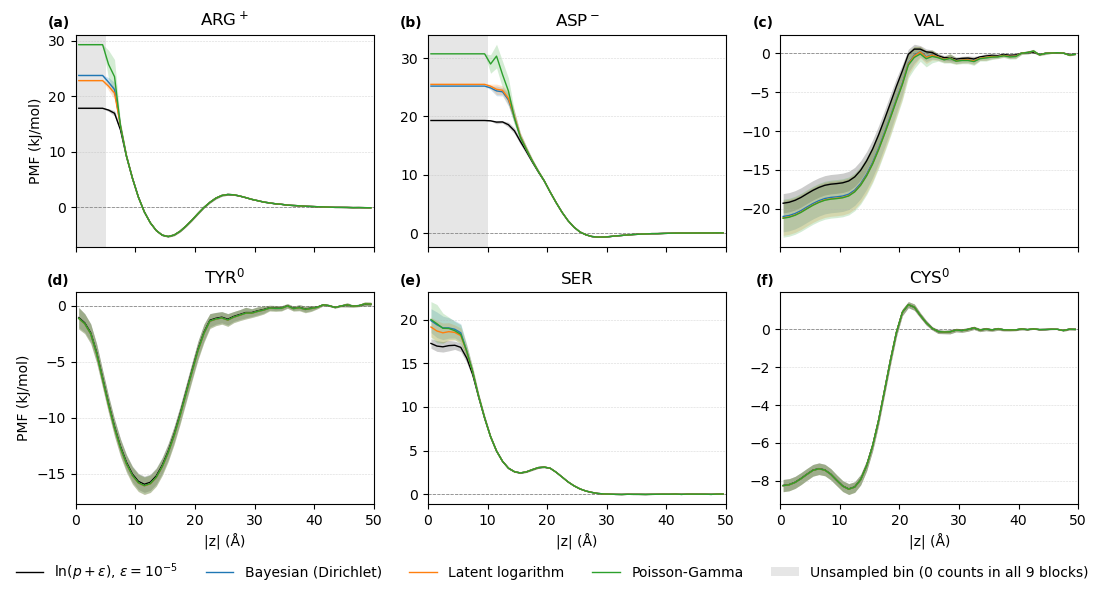

In [34]:
# Unbiased-MD PMFs: comparison of the four zero-handling estimators (4-pmf_calculation*/total) (independent cell)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

ANALOGS = {"scr": r"ARG$^+$", "scd": r"ASP$^-$", "scv": "VAL", "scy": r"TYR$^0$", "scs": "SER", "scc": r"CYS$^0$"}
METHODS = {  # directory suffix: (legend label, color)
    "": (r"$\ln(p+\varepsilon)$, $\varepsilon=10^{-5}$", "black"),
    "_bayesian": ("Bayesian (Dirichlet)", "tab:blue"),
    "_latent": ("Latent logarithm", "tab:orange"),
    "_poisson": ("Poisson-Gamma", "tab:green"),
}
N_BLOCKS = 9
XLIM = (0, 50)  # water reference window is 40-50 A; beyond ~60 A the periodic image of the bilayer appears
SAVE_NAME = "FigureS_PMF_estimator_comparison"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "supp_files/method_script/4-pmf_calculation").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


ROOT = find_repo_root()
METHOD_ROOT = ROOT / "supp_files/method_script"
SAVE_DIR = ROOT / "figures/plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(11.0, 6.0), sharex=True)
for ax, panel, (analog, label) in zip(axes.flat, "abcdef", ANALOGS.items()):
    pmfs = {suffix: pd.read_csv(METHOD_ROOT / f"4-pmf_calculation{suffix}" / "total" / analog / f"pmf_{analog}.dat", sep=r"\s+")
            for suffix in METHODS}
    pmfs = {suffix: df[df["z"] <= XLIM[1]].reset_index(drop=True) for suffix, df in pmfs.items()}
    z = pmfs[""]["z"].to_numpy()
    for suffix, df in pmfs.items():
        assert np.allclose(df["z"], z), f"z grid mismatch for {analog} ({suffix or 'standard'})"

    # Bins never visited in any of the 9 blocks: there the PMF is set by the zero-handling model only
    unsampled = pmfs["_bayesian"]["n_empty"].to_numpy() == N_BLOCKS
    for zc in z[unsampled]:
        ax.axvspan(zc - 0.5, zc + 0.5, color="0.9", lw=0, zorder=0)

    for suffix, df in pmfs.items():
        name, color = METHODS[suffix]
        ax.fill_between(df["z"], df["mean"] - df["se"], df["mean"] + df["se"], color=color, alpha=0.2, lw=0, zorder=1)
        ax.plot(df["z"], df["mean"], color=color, lw=1.0, label=name, zorder=2)

    sampled = ~unsampled
    spread = np.ptp(np.vstack([df["mean"].to_numpy() for df in pmfs.values()]), axis=0)
    centre = [df["mean"].iloc[0] for df in pmfs.values()]
    print(f"{analog.upper()}: max inter-method spread on sampled bins = {spread[sampled].max():.2f} kJ/mol; "
          f"{unsampled.sum()} unsampled bins; PMF(z=0.5) eps/bayes/latent/poisson = " + ", ".join(f"{v:.1f}" for v in centre))

    ax.axhline(0, color="gray", lw=0.6, ls="--", zorder=0)
    ax.set_xlim(*XLIM)
    ax.set_title(label)
    ax.text(-0.02, 1.02, f"({panel})", transform=ax.transAxes, ha="right", va="bottom", fontweight="bold")
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)

for ax in axes[1, :]:
    ax.set_xlabel("|z| (Å)")
for ax in axes[:, 0]:
    ax.set_ylabel("PMF (kJ/mol)")

handles, labels = axes[0, 0].get_legend_handles_labels()
handles.append(Patch(facecolor="0.9", lw=0))
labels.append(f"Unsampled bin (0 counts in all {N_BLOCKS} blocks)")
fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()

=== \ln(p+\varepsilon), \varepsilon=10^{-5}
SCV  : max |0.2M - 0.1M| =  3.67 kJ/mol at z = 19.5 A; bins with |diff| > 2 SE: 0/50
SCL  : max |0.2M - 0.1M| =  2.46 kJ/mol at z = 11.5 A; bins with |diff| > 2 SE: 0/50
SCI  : max |0.2M - 0.1M| =  2.72 kJ/mol at z =  6.5 A; bins with |diff| > 2 SE: 14/50
SCM  : max |0.2M - 0.1M| =  2.78 kJ/mol at z =  9.5 A; bins with |diff| > 2 SE: 15/50
SCF  : max |0.2M - 0.1M| =  4.06 kJ/mol at z =  8.5 A; bins with |diff| > 2 SE: 8/50
SCW  : max |0.2M - 0.1M| =  3.53 kJ/mol at z = 12.5 A; bins with |diff| > 2 SE: 15/50
SCY  : max |0.2M - 0.1M| =  5.86 kJ/mol at z = 14.5 A; bins with |diff| > 2 SE: 23/50; max |0.2M - US| = 2.60 kJ/mol; max |0.1M - US| = 5.70 kJ/mol
SCRN : max |0.2M - 0.1M| =  2.22 kJ/mol at z =  3.5 A; bins with |diff| > 2 SE: 12/50


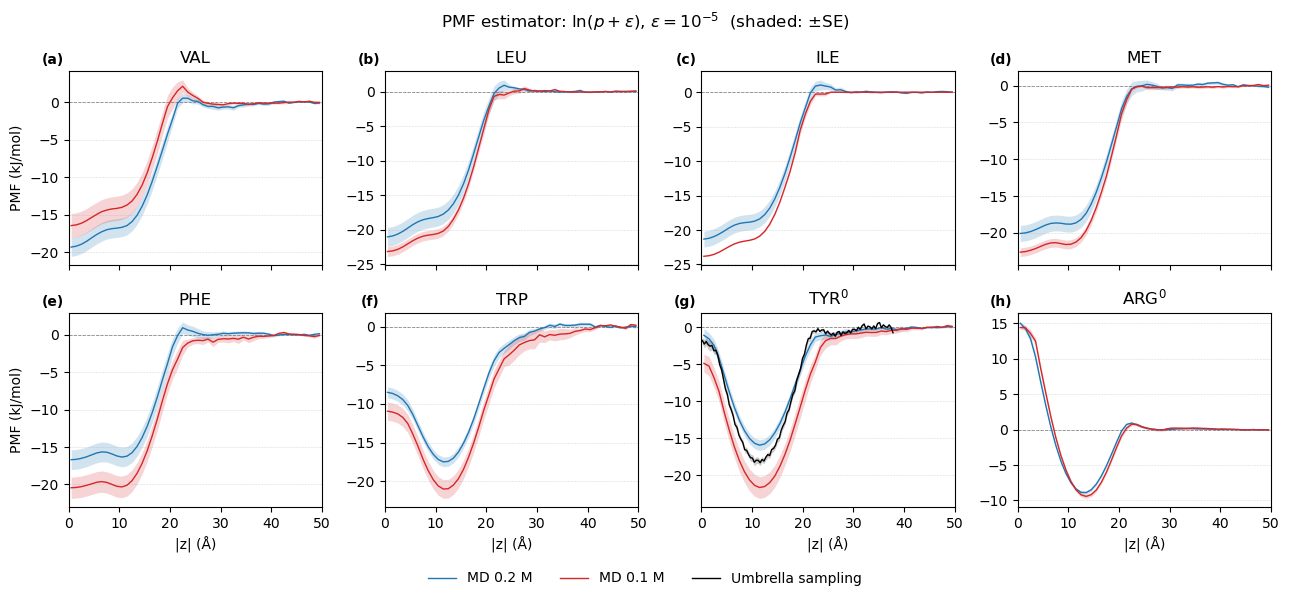

=== Bayesian (Dirichlet)
SCV  : max |0.2M - 0.1M| =  4.41 kJ/mol at z = 19.5 A; bins with |diff| > 2 SE: 0/50
SCL  : max |0.2M - 0.1M| =  2.70 kJ/mol at z = 11.5 A; bins with |diff| > 2 SE: 0/50
SCI  : max |0.2M - 0.1M| =  3.43 kJ/mol at z =  6.5 A; bins with |diff| > 2 SE: 1/50
SCM  : max |0.2M - 0.1M| =  4.06 kJ/mol at z =  9.5 A; bins with |diff| > 2 SE: 1/50
SCF  : max |0.2M - 0.1M| =  5.55 kJ/mol at z =  8.5 A; bins with |diff| > 2 SE: 0/50
SCW  : max |0.2M - 0.1M| =  5.20 kJ/mol at z = 12.5 A; bins with |diff| > 2 SE: 23/50
SCY  : max |0.2M - 0.1M| =  8.56 kJ/mol at z = 14.5 A; bins with |diff| > 2 SE: 24/50; max |0.2M - US| = 2.46 kJ/mol; max |0.1M - US| = 8.47 kJ/mol
SCRN : max |0.2M - 0.1M| =  3.33 kJ/mol at z =  3.5 A; bins with |diff| > 2 SE: 13/50


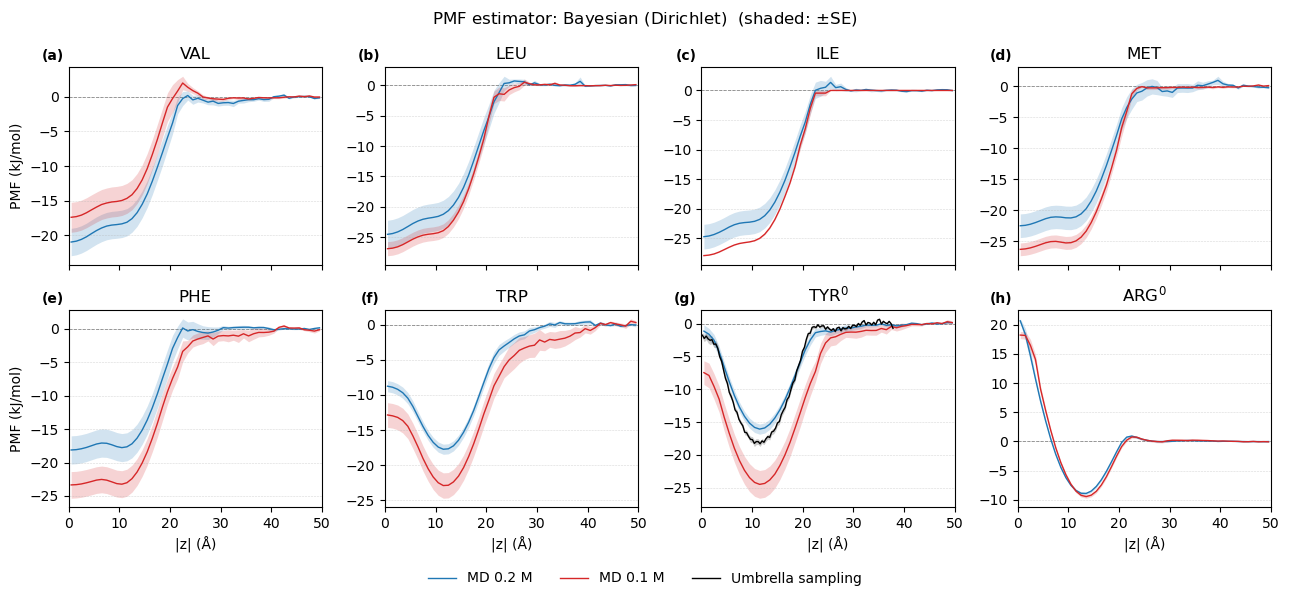

=== Latent logarithm
SCV  : max |0.2M - 0.1M| =  4.58 kJ/mol at z = 19.5 A; bins with |diff| > 2 SE: 0/50
SCL  : max |0.2M - 0.1M| =  4.27 kJ/mol at z = 11.5 A; bins with |diff| > 2 SE: 0/50
SCI  : max |0.2M - 0.1M| =  5.19 kJ/mol at z =  6.5 A; bins with |diff| > 2 SE: 1/50
SCM  : max |0.2M - 0.1M| =  6.22 kJ/mol at z =  9.5 A; bins with |diff| > 2 SE: 15/50
SCF  : max |0.2M - 0.1M| =  7.00 kJ/mol at z =  8.5 A; bins with |diff| > 2 SE: 0/50
SCW  : max |0.2M - 0.1M| =  5.66 kJ/mol at z = 12.5 A; bins with |diff| > 2 SE: 17/50
SCY  : max |0.2M - 0.1M| =  9.86 kJ/mol at z = 14.5 A; bins with |diff| > 2 SE: 24/50; max |0.2M - US| = 2.46 kJ/mol; max |0.1M - US| = 9.77 kJ/mol
SCRN : max |0.2M - 0.1M| =  2.96 kJ/mol at z =  3.5 A; bins with |diff| > 2 SE: 13/50


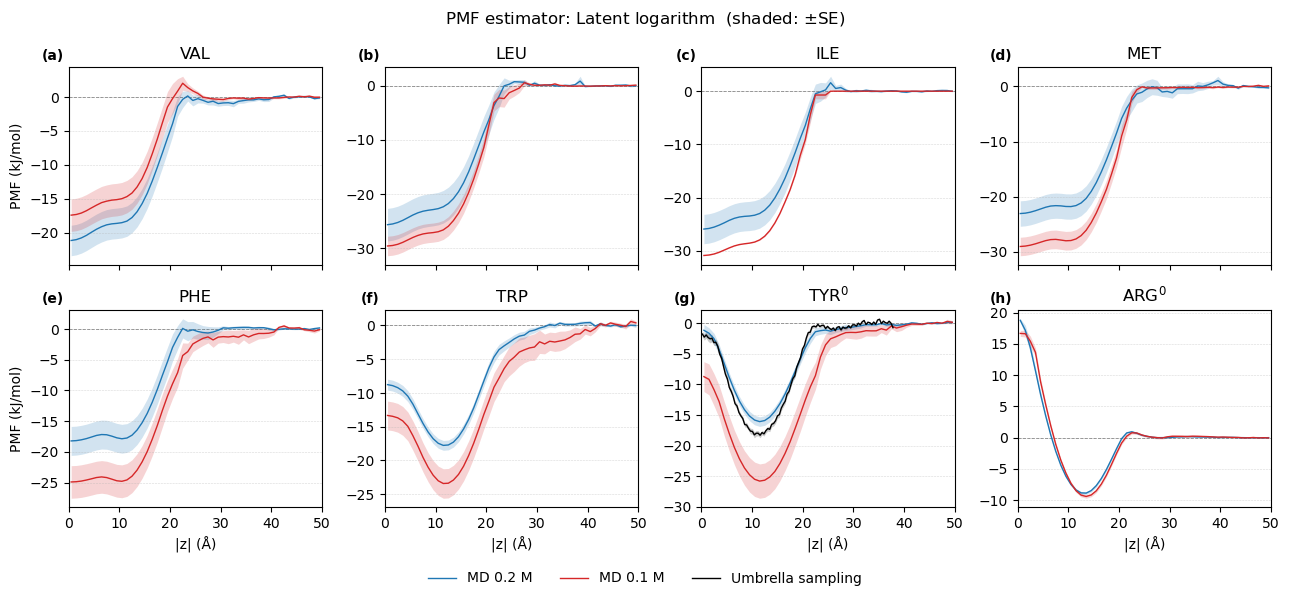

=== Poisson-Gamma
SCV  : max |0.2M - 0.1M| =  4.42 kJ/mol at z = 19.5 A; bins with |diff| > 2 SE: 0/50
SCL  : max |0.2M - 0.1M| =  7.26 kJ/mol at z = 11.5 A; bins with |diff| > 2 SE: 2/50
SCI  : max |0.2M - 0.1M| =  6.96 kJ/mol at z =  6.5 A; bins with |diff| > 2 SE: 0/50
SCM  : max |0.2M - 0.1M| =  9.96 kJ/mol at z =  9.5 A; bins with |diff| > 2 SE: 23/50
SCF  : max |0.2M - 0.1M| =  8.71 kJ/mol at z =  8.5 A; bins with |diff| > 2 SE: 6/50
SCW  : max |0.2M - 0.1M| =  6.04 kJ/mol at z = 12.5 A; bins with |diff| > 2 SE: 12/50
SCY  : max |0.2M - 0.1M| = 11.78 kJ/mol at z = 14.5 A; bins with |diff| > 2 SE: 24/50; max |0.2M - US| = 2.48 kJ/mol; max |0.1M - US| = 11.69 kJ/mol
SCRN : max |0.2M - 0.1M| =  4.34 kJ/mol at z =  1.5 A; bins with |diff| > 2 SE: 12/50


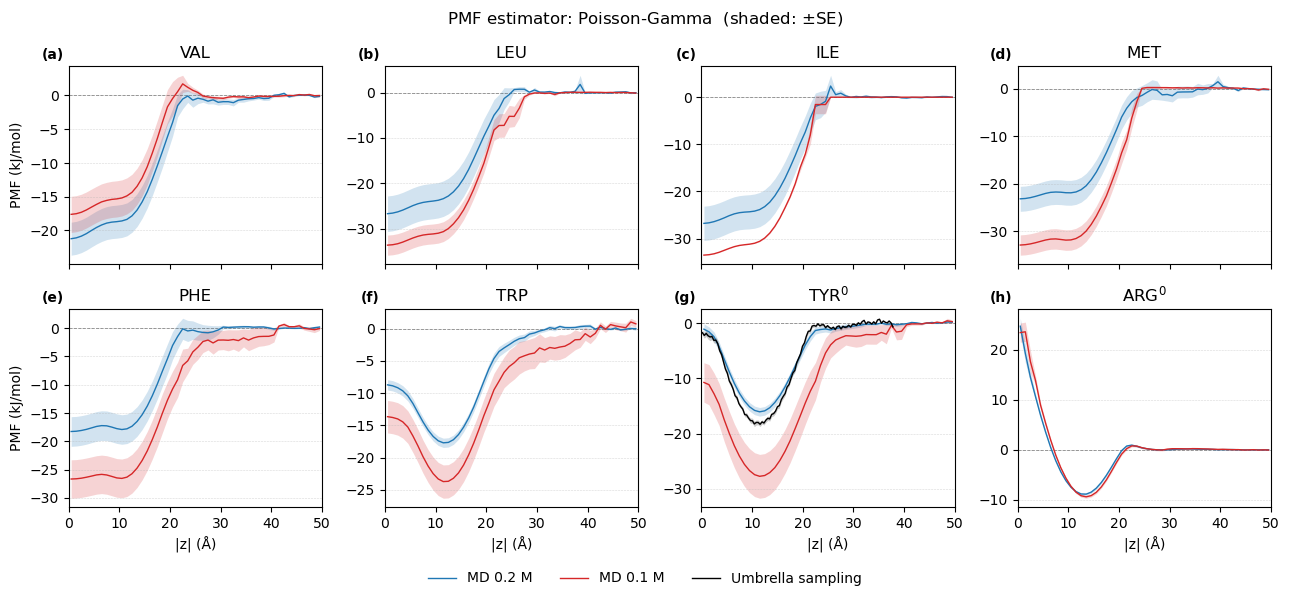

In [6]:
# Concentration effect (0.2 M vs 0.1 M) and umbrella sampling, one figure per PMF estimator (independent cell)
# Includes every available matching US PMF (LEU: two 50 ns blocks; TYR0: three).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOGS = {"scv": "VAL", "scl": "LEU", "sci": "ILE", "scm": "MET",
           "scf": "PHE", "scw": "TRP", "scy": r"TYR$^0$", "scrn": r"ARG$^0$"}  # analogs simulated at 0.2 M ({aa}) and 0.1 M ({aa}-1)
METHODS = {  # directory suffix: (title, file tag)
    "": (r"$\ln(p+\varepsilon)$, $\varepsilon=10^{-5}$", "epsilon"),
    "_bayesian": ("Bayesian (Dirichlet)", "bayesian"),
    "_latent": ("Latent logarithm", "latent"),
    "_poisson": ("Poisson-Gamma", "poisson"),
}
SERIES = {  # key: (legend label, color)
    "0.2M": ("MD 0.2 M", "tab:blue"),
    "0.1M": ("MD 0.1 M", "tab:red"),
    "US": ("Umbrella sampling", "black"),
}
KCAL_TO_KJ = 4.184  # US PMFs are written in kcal/mol, MD PMFs in kJ/mol
XLIM = (0, 50)  # water reference window is 40-50 A (MD) and 30-37.8 A (US)
SAVE_PREFIX = "FigureS_PMF_concentration_US"
MODE = "total_cyl"  # used to find distribution files and name output dir


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "supp_files/method_script/4-pmf_calculation").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_md(method_suffix, analog):
    df = pd.read_csv(METHOD_ROOT / f"4-pmf_calculation{method_suffix}" / MODE / analog / f"pmf_{analog}.dat", sep=r"\s+")
    return df[df["z"] <= XLIM[1]].reset_index(drop=True)


def read_us(analog):
    path = US_DIR / analog / f"pmf-us-{analog}.dat"
    if not path.is_file():
        if path.parent.is_dir():
            print(f"WARNING: {analog.upper()} umbrella data exist but its PMF is unavailable: {path}")
        return None
    df = pd.read_csv(path, sep=r"\s+", comment="#", header=None, names=["z", "mean", "se", "n"])
    if (len(df) < 2 or not np.isfinite(df.to_numpy()).all() or (df["se"] < 0).any()
            or np.any(np.diff(df["z"]) <= 0) or df["n"].nunique() != 1 or df["n"].iloc[0] < 2):
        raise ValueError(f"Invalid umbrella PMF: {path}")
    df[["mean", "se"]] *= KCAL_TO_KJ
    return df


ROOT = find_repo_root()
METHOD_ROOT = ROOT / "supp_files/method_script"
US_DIR = ROOT / "figures/data/SUPP_umbrella_sampling/pmf"
SAVE_DIR = ROOT / "figures/plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

for suffix, (method_title, tag) in METHODS.items():
    print(f"=== {method_title.replace('$', '')}")
    fig, axes = plt.subplots(2, 4, figsize=(13.0, 6.0), sharex=True)
    for ax, panel, (analog, label) in zip(axes.flat, "abcdefgh", ANALOGS.items()):
        curves = {"0.2M": read_md(suffix, analog), "0.1M": read_md(suffix, f"{analog}-1"), "US": read_us(analog)}
        for key, df in curves.items():
            if df is None:
                continue
            name, color = SERIES[key]
            ax.fill_between(df["z"], df["mean"] - df["se"], df["mean"] + df["se"], color=color, alpha=0.2, lw=0, zorder=1)
            ax.plot(df["z"], df["mean"], color=color, lw=1.0, label=name, zorder=2)

        hi, lo = curves["0.2M"], curves["0.1M"]
        assert np.allclose(hi["z"], lo["z"]), f"z grid mismatch between {analog} and {analog}-1"
        diff = (hi["mean"] - lo["mean"]).abs()
        z_scores = diff / np.sqrt(hi["se"] ** 2 + lo["se"] ** 2)
        msg = (f"{analog.upper():5s}: max |0.2M - 0.1M| = {diff.max():5.2f} kJ/mol at z = {hi['z'][diff.idxmax()]:4.1f} A; "
               f"bins with |diff| > 2 SE: {(z_scores > 2).sum()}/{len(diff)}")
        if curves["US"] is not None:
            us = curves["US"]
            for key in ("0.2M", "0.1M"):
                md_on_us = np.interp(us["z"], curves[key]["z"], curves[key]["mean"])
                msg += f"; max |{key} - US| = {np.abs(md_on_us - us['mean']).max():.2f} kJ/mol"
        print(msg)

        ax.axhline(0, color="gray", lw=0.6, ls="--", zorder=0)
        ax.set_xlim(*XLIM)
        us_note = f" (US: {int(curves['US']['n'].iloc[0])} blocks)" if curves["US"] is not None else ""
        ax.set_title(f"{label}{us_note}")
        ax.text(-0.02, 1.02, f"({panel})", transform=ax.transAxes, ha="right", va="bottom", fontweight="bold")
        ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)

    for ax in axes[1, :]:
        ax.set_xlabel("|z| (Å)")
    for ax in axes[:, 0]:
        ax.set_ylabel("PMF (kJ/mol)")

    handles, labels = [], []
    for ax in axes.flat:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, 0.0))
    fig.suptitle(f"PMF estimator: {method_title}  (shaded: $\\pm$SE)")
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(SAVE_DIR / f"{SAVE_PREFIX}_{tag}.png", dpi=600, bbox_inches="tight")
    fig.savefig(SAVE_DIR / f"{SAVE_PREFIX}_{tag}.pdf", bbox_inches="tight")
    plt.show()

scy-1 trajectory 1: sample size read from raw data (780000 molecule-frames)
scy-1 trajectory 2: sample size read from raw data (780000 molecule-frames)
scy-1 trajectory 3: sample size read from raw data (780000 molecule-frames)
TYR$^0$ (scy-1), 9 blocks, 75 |z| bins, 295 empty block/bin cells
a = 29.1534 kJ/mol (file 29.1534); sigma_a = 2.1145 (file 2.1145); independent-bin sigma_a = 0.6576
max |PMF - file| = 5.0e-07 kJ/mol; max |SE - file| = 5.0e-07 kJ/mol


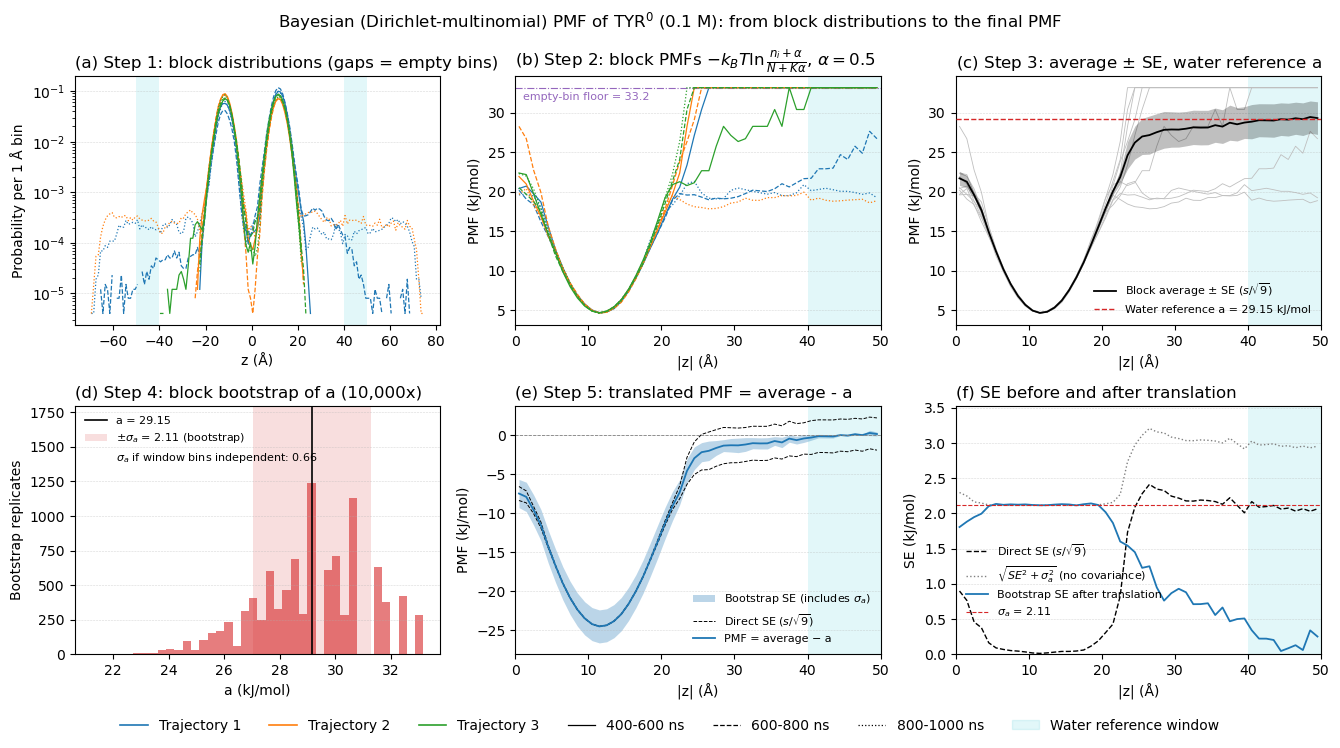

In [17]:
# Step-by-step construction of the Bayesian (Dirichlet-multinomial) PMF of TYR0 (scy-1, 0.1 M), replicating
# supp_files/method_script/4-pmf_calculation_bayesian/pmf-from-distribution.py (independent cell)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ANALOG, LABEL = "scy-1", r"TYR$^0$"
MODE = "total"
METHOD = "bayesian"
K_B, T = 0.008314, 303.15  # kJ/(mol K), K
ALPHA = 0.5  # Jeffreys pseudocount of the Dirichlet prior
REF_WINDOW = (40.0, 50.0)  # bulk-water window (A)
N_TRAJ, N_BATCH = 3, 3  # 3 trajectories x 3 blocks of 200 ns (400-1000 ns)
N_BOOT, SEED = 10000, 2025  # block bootstrap, same settings as the script
SE_FLOOR = 1e-9
Z_BIN, XMAX = 1.0, 50
TRAJ_COLORS = ("tab:blue", "tab:orange", "tab:green")
BLOCK_STYLES = ("-", "--", ":")
SAVE_NAME = f"FigureS_PMF_{METHOD}_steps_{ANALOG}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures/data/distribution_data").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def water_reference(mean, se, mask):
    """Inverse-variance weighted mean over the water window (unweighted if any SE <= SE_FLOOR)."""
    m, s = mean[..., mask], se[..., mask]
    degenerate = np.any(s <= SE_FLOOR, axis=-1, keepdims=True)
    w = np.where(degenerate, 1.0, 1.0 / np.where(s > SE_FLOOR, s, 1.0) ** 2)
    return np.sum(w * m, axis=-1) / np.sum(w, axis=-1)


def block_mean_se(pmfs):
    n = pmfs.shape[-2]
    return pmfs.mean(axis=-2), pmfs.std(axis=-2, ddof=1) / np.sqrt(n)


ROOT = find_repo_root()
DIST_DIR = ROOT / "figures/data/distribution_data"
OUT_DIR = ROOT / f"supp_files/method_script/4-pmf_calculation_{METHOD}" / MODE
SAVE_DIR = ROOT / "figures/plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# --- Step 1: block distributions -> exact counts, folded onto |z| ---
raw_summary = pd.read_csv(DIST_DIR / "raw_data_summary.dat", sep=r"\s+")
dists = {t: np.loadtxt(DIST_DIR / MODE / ANALOG / f"trajectory{t}.dat", skiprows=1) for t in range(1, N_TRAJ + 1)}
z_pos = np.array(sorted({abs(v) for arr in dists.values() for v in arr[:, 0]}))
if z_pos[-1] < 50:  # grid extended to 50 A with genuine zero-count bins
    z_pos = np.concatenate([z_pos, np.arange(z_pos[-1] + Z_BIN, 50 + Z_BIN, Z_BIN)])
counts, block_ids = [], []
for t, arr in dists.items():
    sizes = raw_summary.loc[(raw_summary["residu"] == ANALOG) & (raw_summary["traj"] == t), "n_lines"]
    if sizes.empty:
        raw_path = DIST_DIR / "raw_data" / ANALOG / f"{ANALOG}_contacts_{t}.dat"
        with raw_path.open("rb") as fh:
            n_lines = sum(1 for _ in fh) - 1
        print(f"{ANALOG} trajectory {t}: sample size read from raw data ({n_lines} molecule-frames)")
    else:
        n_lines = int(sizes.item())
    if n_lines % N_BATCH:
        raise ValueError(f"{ANALOG} trajectory {t}: {n_lines} rows cannot be divided into {N_BATCH} equal blocks")
    depth = n_lines // N_BATCH  # molecule-frames per block
    fold_idx = np.array([np.argmin(np.abs(z_pos - abs(z))) for z in arr[:, 0]])
    for b in range(N_BATCH):
        folded = np.zeros(len(z_pos))
        np.add.at(folded, fold_idx, np.rint(arr[:, 1 + b] * depth))
        counts.append(folded)
        block_ids.append((t, b))
counts = np.array(counts)
n_blocks, n_bins = counts.shape

# --- Step 2: untranslated block PMFs from the Dirichlet posterior mean p = (n + alpha) / (N + K alpha) ---
p_post = (counts + ALPHA) / (counts.sum(axis=1, keepdims=True) + n_bins * ALPHA)
block_pmfs = -K_B * T * np.log(p_post)

# --- Step 3: block average, SE = s/sqrt(n), water reference a ---
win = (z_pos >= REF_WINDOW[0]) & (z_pos <= REF_WINDOW[1])
mean_raw, se_raw = block_mean_se(block_pmfs)
a_ref = float(water_reference(mean_raw, se_raw, win))

# --- Step 4: block bootstrap of steps 3-5 -> sigma_a and the SE of the translated PMF ---
rng = np.random.default_rng(SEED)
boot = block_pmfs[rng.integers(0, n_blocks, size=(N_BOOT, n_blocks))]
boot_mean, boot_se = block_mean_se(boot)
boot_a = water_reference(boot_mean, boot_se, win)
corr = np.sqrt(n_blocks / (n_blocks - 1))  # small-sample correction
sigma_a = float(corr * boot_a.std(ddof=1))
sigma_a_indep = float(1.0 / np.sqrt(np.sum(1.0 / se_raw[win] ** 2)))

# --- Step 5: translated PMF and its bootstrap SE ---
mean_pmf = mean_raw - a_ref
se_pmf = corr * (boot_mean - boot_a[:, None]).std(axis=0, ddof=1)

# Consistency with the files written by the script
final = pd.read_csv(OUT_DIR / ANALOG / f"pmf_{ANALOG}.dat", sep=r"\s+")
ref_table = pd.read_csv(OUT_DIR / "water_reference.dat", sep=r"\s+").set_index("analog")
assert np.allclose(final["z"], z_pos), "z grid differs from the script output"
print(f"{LABEL} ({ANALOG}), {n_blocks} blocks, {n_bins} |z| bins, {int((counts == 0).sum())} empty block/bin cells")
print(f"a = {a_ref:.4f} kJ/mol (file {ref_table.loc[ANALOG, 'a']:.4f}); sigma_a = {sigma_a:.4f} "
      f"(file {ref_table.loc[ANALOG, 'sigma_a']:.4f}); independent-bin sigma_a = {sigma_a_indep:.4f}")
print(f"max |PMF - file| = {np.abs(mean_pmf - final['mean']).max():.1e} kJ/mol; "
      f"max |SE - file| = {np.abs(se_pmf - final['se']).max():.1e} kJ/mol")

# --- Figure ---
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.5))
ax_dist, ax_blocks, ax_avg, ax_boot, ax_final, ax_se = axes.flat
show = z_pos <= XMAX


def style(t, b):
    return dict(color=TRAJ_COLORS[t - 1], ls=BLOCK_STYLES[b], lw=0.9)


def shade_window(ax, signed=False):
    for sign in ((-1, 1) if signed else (1,)):
        lo, hi = sorted((sign * REF_WINDOW[0], sign * REF_WINDOW[1]))
        ax.axvspan(lo, hi, color="tab:cyan", alpha=0.12, lw=0, zorder=0)


# (a) raw distributions of the 9 blocks
for t, arr in dists.items():
    for b in range(N_BATCH):
        dens = np.where(arr[:, 1 + b] > 0, arr[:, 1 + b], np.nan)  # empty bins cannot be shown on a log scale
        ax_dist.plot(arr[:, 0], dens, **style(t, b))
shade_window(ax_dist, signed=True)
ax_dist.set_yscale("log")
ax_dist.set_xlabel("z (Å)")
ax_dist.set_ylabel("Probability per 1 Å bin")
ax_dist.set_title("(a) Step 1: block distributions (gaps = empty bins)", loc="left")

# (b) untranslated block PMFs
for pmf, (t, b) in zip(block_pmfs, block_ids):
    ax_blocks.plot(z_pos[show], pmf[show], **style(t, b))
shade_window(ax_blocks)
floor = float(-K_B * T * np.log(ALPHA / (counts.sum(axis=1).max() + n_bins * ALPHA)))
ax_blocks.axhline(floor, color="tab:purple", lw=0.8, ls="-.", zorder=0)
ax_blocks.text(1, floor - 0.6, f"empty-bin floor = {floor:.1f}", color="tab:purple", va="top", fontsize=8)
ax_blocks.set_title(r"(b) Step 2: block PMFs $-k_BT\ln\frac{n_i+\alpha}{N+K\alpha}$, $\alpha=0.5$", loc="left")

# (c) direct block average, SE and water reference
for pmf, (t, b) in zip(block_pmfs, block_ids):
    ax_avg.plot(z_pos[show], pmf[show], color="0.75", lw=0.6, zorder=1)
ax_avg.fill_between(z_pos[show], (mean_raw - se_raw)[show], (mean_raw + se_raw)[show], color="black", alpha=0.25, lw=0, zorder=2)
ax_avg.plot(z_pos[show], mean_raw[show], color="black", lw=1.3, zorder=3, label=r"Block average $\pm$ SE ($s/\sqrt{9}$)")
ax_avg.axhline(a_ref, color="tab:red", lw=1.0, ls="--", zorder=3, label=f"Water reference a = {a_ref:.2f} kJ/mol")
shade_window(ax_avg)
ax_avg.legend(loc="lower right", fontsize=8, frameon=False)
ax_avg.set_title(r"(c) Step 3: average $\pm$ SE, water reference a", loc="left")

# (d) bootstrap distribution of the water reference
n_hist, _, _ = ax_boot.hist(boot_a, bins=40, color="tab:red", alpha=0.6)
ax_boot.axvline(a_ref, color="black", lw=1.2, label=f"a = {a_ref:.2f}")
ax_boot.axvspan(a_ref - sigma_a, a_ref + sigma_a, color="tab:red", alpha=0.15, lw=0,
                label=rf"$\pm\sigma_a$ = {sigma_a:.2f} (bootstrap)")
ax_boot.plot([], [], " ", label=rf"$\sigma_a$ if window bins independent: {sigma_a_indep:.2f}")
ax_boot.set_ylim(0, n_hist.max() * 1.45)
ax_boot.legend(loc="upper left", fontsize=8, frameon=False)
ax_boot.set_xlabel("a (kJ/mol)")
ax_boot.set_ylabel("Bootstrap replicates")
ax_boot.set_title(f"(d) Step 4: block bootstrap of a ({N_BOOT:,}x)", loc="left")

# (e) translated PMF with the naive and the bootstrap SE
ax_final.fill_between(z_pos[show], (mean_pmf - se_pmf)[show], (mean_pmf + se_pmf)[show], color="tab:blue", alpha=0.3, lw=0,
                      label="Bootstrap SE (includes $\\sigma_a$)")
for sign in (-1, 1):
    ax_final.plot(z_pos[show], (mean_pmf + sign * se_raw)[show], color="black", lw=0.7, ls="--",
                  label="Direct SE ($s/\\sqrt{9}$)" if sign == 1 else None)
ax_final.plot(z_pos[show], mean_pmf[show], color="tab:blue", lw=1.3, label="PMF = average − a")
ax_final.axhline(0, color="gray", lw=0.6, ls="--")
shade_window(ax_final)
ax_final.legend(loc="lower right", fontsize=8, frameon=False)
ax_final.set_title("(e) Step 5: translated PMF = average - a", loc="left")

# (f) SE profiles before and after translation
ax_se.plot(z_pos[show], se_raw[show], color="black", lw=1.0, ls="--", label=r"Direct SE ($s/\sqrt{9}$)")
ax_se.plot(z_pos[show], np.sqrt(se_raw**2 + sigma_a**2)[show], color="0.5", lw=1.0, ls=":",
           label=r"$\sqrt{SE^2+\sigma_a^2}$ (no covariance)")
ax_se.plot(z_pos[show], se_pmf[show], color="tab:blue", lw=1.3, label="Bootstrap SE after translation")
ax_se.axhline(sigma_a, color="tab:red", lw=0.8, ls="--", label=rf"$\sigma_a$ = {sigma_a:.2f}")
shade_window(ax_se)
ax_se.set_ylim(0, max(se_pmf[show].max(), np.sqrt(se_raw**2 + sigma_a**2)[show].max()) * 1.1)
ax_se.legend(loc="lower left", bbox_to_anchor=(0.0, 0.1), fontsize=8, frameon=False)
ax_se.set_ylabel("SE (kJ/mol)")
ax_se.set_title("(f) SE before and after translation", loc="left")

for ax in (ax_blocks, ax_avg, ax_final, ax_se):
    ax.set_xlim(0, XMAX)
    ax.set_xlabel("|z| (Å)")
for ax in (ax_blocks, ax_avg, ax_final):
    ax.set_ylabel("PMF (kJ/mol)")
for ax in axes.flat:
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)

block_handles = [Line2D([], [], color=c, lw=1.2) for c in TRAJ_COLORS] + [Line2D([], [], color="black", ls=s, lw=0.9) for s in BLOCK_STYLES]
block_labels = [f"Trajectory {t}" for t in range(1, N_TRAJ + 1)] + ["400-600 ns", "600-800 ns", "800-1000 ns"]
block_handles.append(plt.Rectangle((0, 0), 1, 1, color="tab:cyan", alpha=0.12))
block_labels.append("Water reference window")
fig.legend(block_handles, block_labels, loc="lower center", ncol=len(block_labels), frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.suptitle(f"Bayesian (Dirichlet-multinomial) PMF of {LABEL} (0.1 M): from block distributions to the final PMF")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()

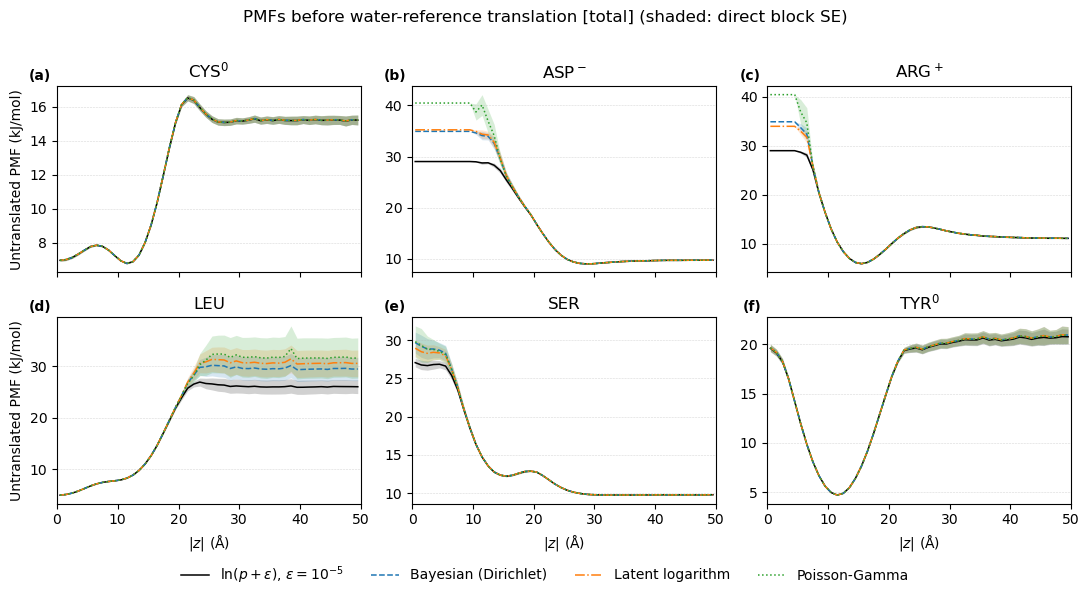

In [18]:
# Untranslated PMFs: four estimators for six reference analogs (independent cell).
# Bands are the direct inter-block SE, not the bootstrap SE after water referencing.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOGS = {"scc": r"CYS$^0$", "scd": r"ASP$^-$", "scr": r"ARG$^+$",
           "scl": "LEU", "scs": "SER", "scy": r"TYR$^0$"}
METHODS = {
    "": (r"$\ln(p+\varepsilon)$, $\varepsilon=10^{-5}$", "black", "-"),
    "_bayesian": ("Bayesian (Dirichlet)", "tab:blue", "--"),
    "_latent": ("Latent logarithm", "tab:orange", "-."),
    "_poisson": ("Poisson-Gamma", "tab:green", ":"),
}
MODE = "total"
XLIM = (0, 50)
SAVE_NAME = f"FigureS_PMF_estimator_comparison_untranslated_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "supp_files" / "method_script" / "4-pmf_calculation").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


ROOT = find_repo_root()
METHOD_ROOT = ROOT / "supp_files" / "method_script"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(11.0, 6.0), sharex=True)
for ax, panel, (analog, label) in zip(axes.flat, "abcdef", ANALOGS.items()):
    grid = None
    for suffix, (name, color, linestyle) in METHODS.items():
        path = METHOD_ROOT / f"4-pmf_calculation{suffix}" / MODE / analog / f"pmf_{analog}_untranslated.dat"
        df = pd.read_csv(path, sep=r"\s+")
        values = df[["z", "mean", "se"]].to_numpy()
        if df.empty or not np.isfinite(values).all() or (df["se"] < 0).any():
            raise ValueError(f"Invalid untranslated PMF or SE: {path}")
        df = df.loc[df["z"].between(*XLIM)].reset_index(drop=True)
        z = df["z"].to_numpy()
        if len(z) < 2 or np.any(np.diff(z) <= 0):
            raise ValueError(f"Insufficient or non-increasing z grid: {path}")
        if grid is None:
            grid = z
        elif grid.shape != z.shape or not np.allclose(grid, z):
            raise ValueError(f"z grid mismatch for {analog}: {path}")
        ax.fill_between(z, df["mean"] - df["se"], df["mean"] + df["se"],
                        color=color, alpha=0.18, lw=0)
        ax.plot(z, df["mean"], color=color, ls=linestyle, lw=1.1, label=name)
    ax.set_xlim(*XLIM)
    ax.set_title(label)
    ax.text(-0.02, 1.02, f"({panel})", transform=ax.transAxes,
            ha="right", va="bottom", fontweight="bold")
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)

for ax in axes[1, :]:
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
for ax in axes[:, 0]:
    ax.set_ylabel("Untranslated PMF (kJ/mol)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, 0.0))
fig.suptitle(f"PMFs before water-reference translation [{MODE}] (shaded: direct block SE)")
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()


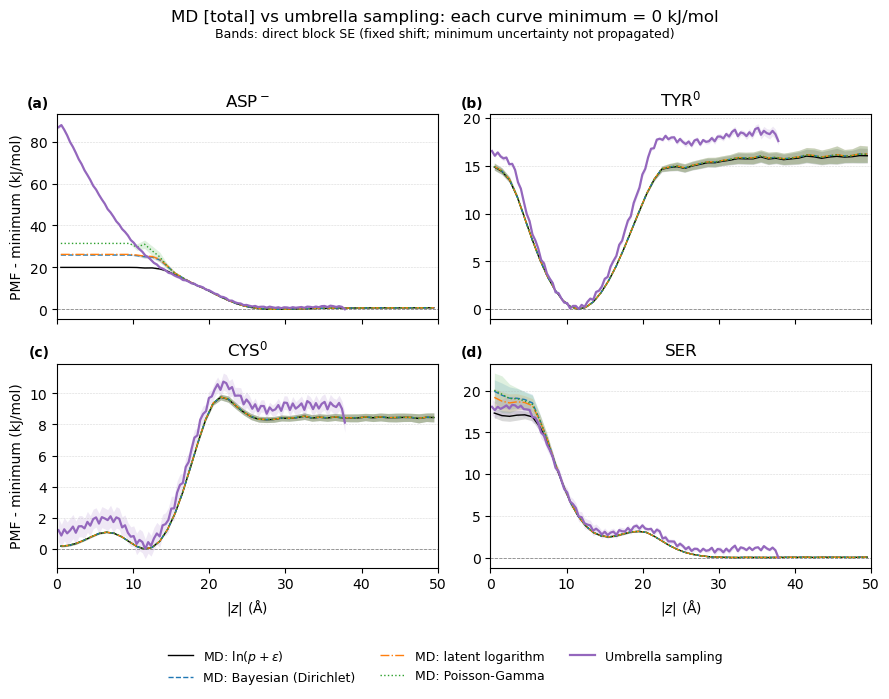

In [19]:
# Untranslated MD and umbrella PMFs, each shifted to its own minimum (independent cell).
# Direct SE bands are retained under a fixed shift; uncertainty of the minimum is not propagated.
# LEU is included with its two-block US mean and direct SE.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOGS = {"scd": r"ASP$^-$", "scy": r"TYR$^0$", "scc": r"CYS$^0$", "scs": "SER", "scl": "LEU"}
METHODS = {
    "": (r"MD: $\ln(p+\varepsilon)$", "black", "-"),
    "_bayesian": ("MD: Bayesian (Dirichlet)", "tab:blue", "--"),
    "_latent": ("MD: latent logarithm", "tab:orange", "-."),
    "_poisson": ("MD: Poisson-Gamma", "tab:green", ":"),
}
MODE = "total"
XLIM = (0, 50)
KCAL_TO_KJ = 4.184
SAVE_NAME = f"FigureS_PMF_minimum_aligned_US_comparison_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "supp_files" / "method_script" / "4-pmf_calculation").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def plot_minimum_aligned(ax, df, label, color, linestyle):
    df = df.loc[df["z"].between(*XLIM)].copy()
    if len(df) < 2 or not np.isfinite(df[["z", "mean", "se"]].to_numpy()).all():
        raise ValueError(f"Insufficient or non-finite PMF data for {label}")
    if (df["se"] < 0).any() or np.any(np.diff(df["z"]) <= 0):
        raise ValueError(f"Invalid SE or z grid for {label}")
    df["mean"] -= df["mean"].min()
    ax.fill_between(df["z"], df["mean"] - df["se"], df["mean"] + df["se"],
                    color=color, alpha=0.15, lw=0)
    ax.plot(df["z"], df["mean"], color=color, ls=linestyle,
            lw=1.6 if label == "Umbrella sampling" else 1.0, label=label)


ROOT = find_repo_root()
METHOD_ROOT = ROOT / "supp_files" / "method_script"
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(12.0, 7.0), sharex=True)
for ax, panel, (analog, label) in zip(axes.flat, "abcde", ANALOGS.items()):
    for suffix, (name, color, linestyle) in METHODS.items():
        path = METHOD_ROOT / f"4-pmf_calculation{suffix}" / MODE / analog / f"pmf_{analog}_untranslated.dat"
        md = pd.read_csv(path, sep=r"\s+")
        plot_minimum_aligned(ax, md, name, color, linestyle)
    us_path = US_DIR / analog / f"pmf-us-{analog}-untranslated.dat"
    us = pd.read_csv(us_path, sep=r"\s+", comment="#", header=None,
                     names=["z", "mean", "se", "n_blocks"])
    us[["mean", "se"]] *= KCAL_TO_KJ
    plot_minimum_aligned(ax, us, "Umbrella sampling", "tab:purple", "-")
    ax.set_xlim(*XLIM)
    ax.set_title(f"{label} (US: {int(us['n_blocks'].iloc[0])} blocks)")
    ax.axhline(0, color="gray", lw=0.6, ls="--", zorder=0)
    ax.text(-0.02, 1.02, f"({panel})", transform=ax.transAxes,
            ha="right", va="bottom", fontweight="bold")
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
for ax in list(axes.flat)[len(ANALOGS):]:
    ax.set_visible(False)
for ax in axes[1, :]:
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
for ax in axes[:, 0]:
    ax.set_ylabel("PMF - minimum (kJ/mol)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 0.0), fontsize=9)
fig.suptitle(f"MD [{MODE}] vs umbrella sampling: each curve minimum = 0 kJ/mol")
fig.text(0.5, 0.94, "Bands: direct block SE (fixed shift; minimum uncertainty not propagated)",
         ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.09, 1, 0.93))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()


Zero filtering is applied after folding +z/-z, to all 50 bins in 0-50 A.
Curves are shifted by their own minimum; bands retain direct SE without propagating minimum uncertainty.


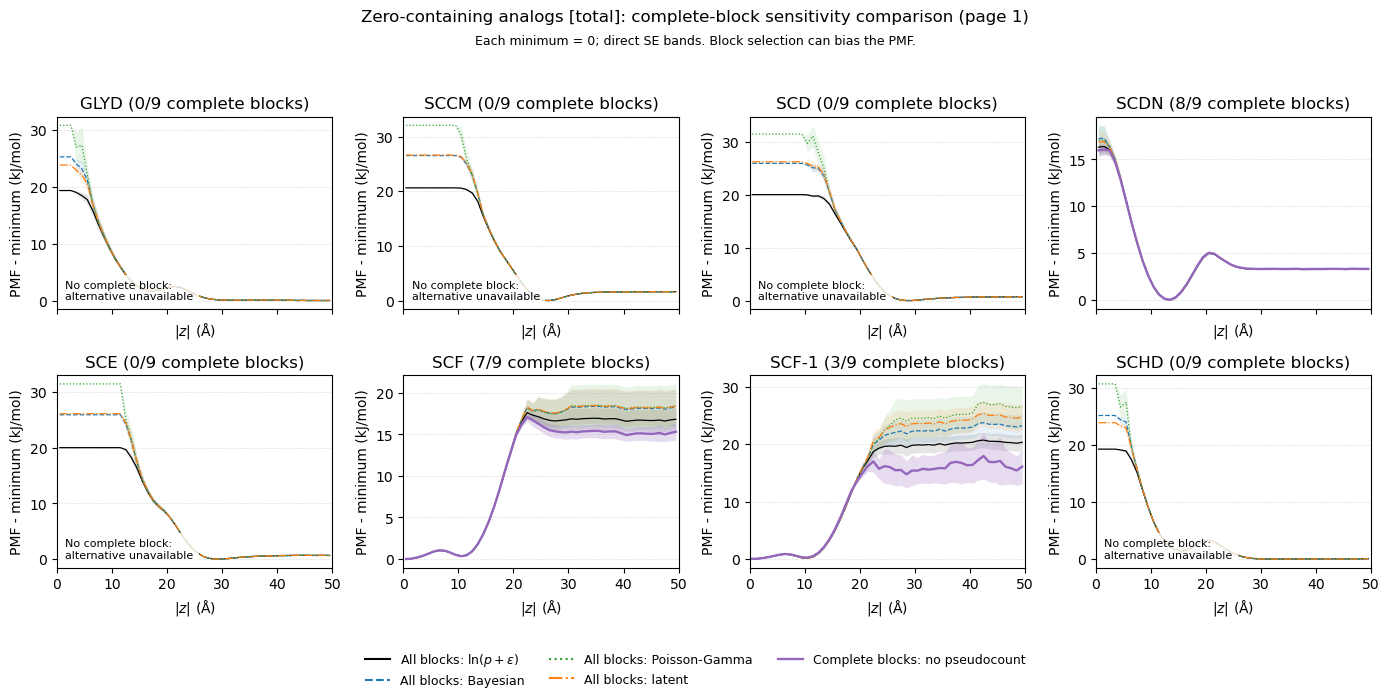

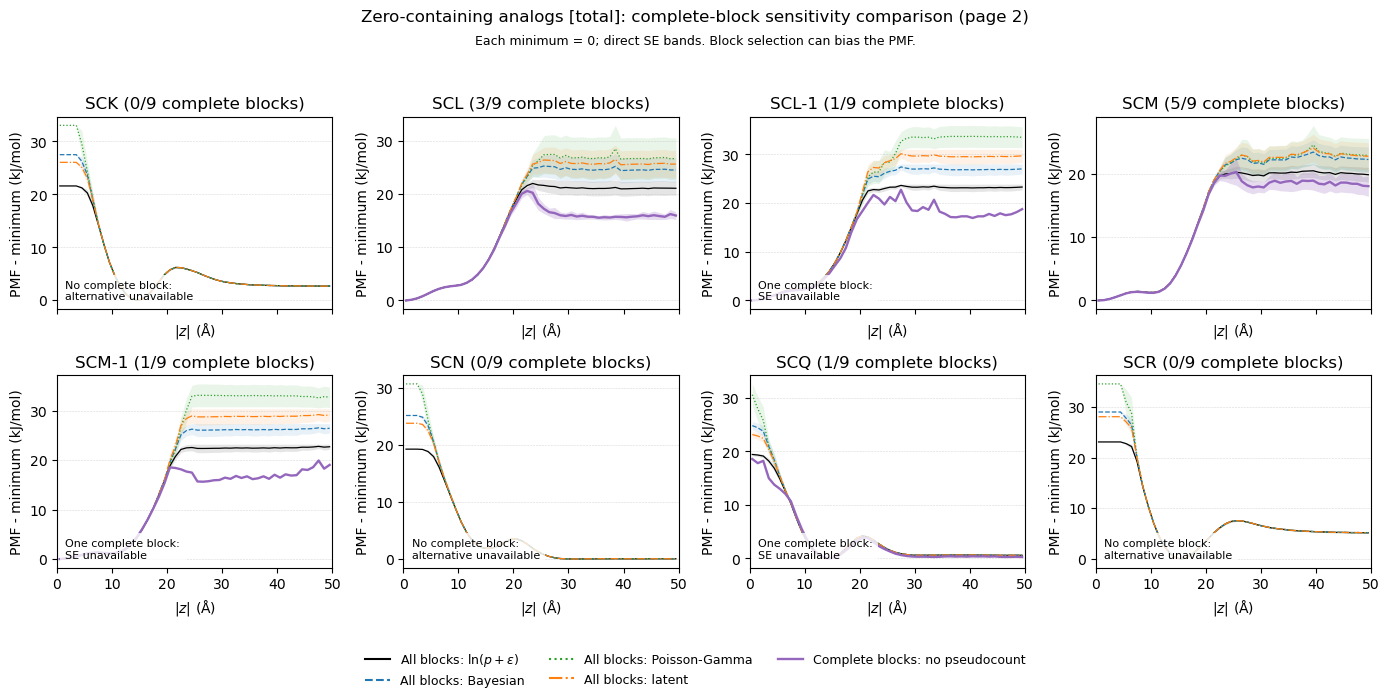

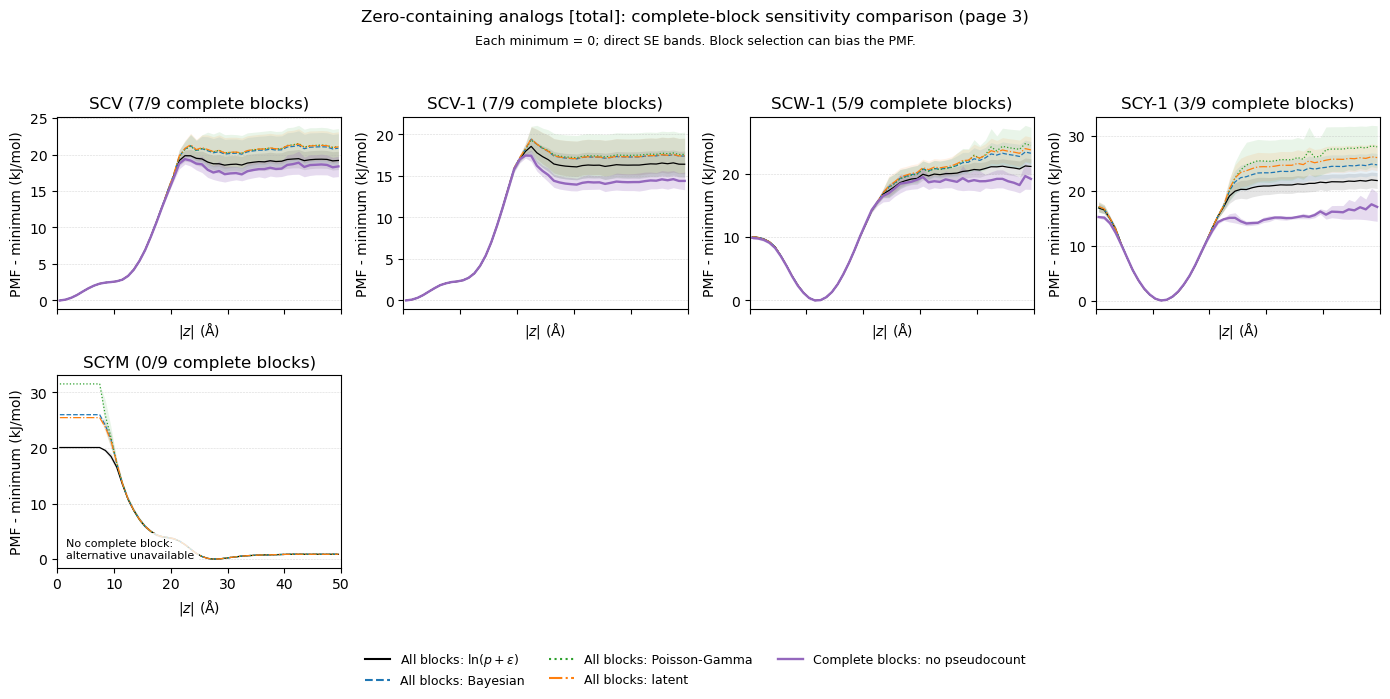

analog  n_valid  n_total                     status
  glyd        0        9          no complete block
  sccm        0        9          no complete block
   scd        0        9          no complete block
  scdn        8        9            direct block SE
   sce        0        9          no complete block
   scf        7        9            direct block SE
 scf-1        3        9            direct block SE
  schd        0        9          no complete block
  sche        0        9          no complete block
  schp        0        9          no complete block
   sci        3        9            direct block SE
 sci-1        0        9          no complete block
   sck        0        9          no complete block
   scl        3        9            direct block SE
 scl-1        1        9 SE unavailable (one block)
   scm        5        9            direct block SE
 scm-1        1        9 SE unavailable (one block)
   scn        0        9          no complete block
   scq      

In [21]:
# Sensitivity to excluding entire blocks with zero folded counts in 0-50 A (independent cell).
# Complete-block selection is sampling-dependent and can bias the PMF; this is not a corrected equilibrium estimate.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

MODE = "total"
XLIM = (0.0, 50.0)
Z_BIN = 1.0
K_B, TEMPERATURE = 0.008314, 303.15
METHODS = {
    "": (r"All blocks: $\ln(p+\varepsilon)$", "black", "-"),
    "_bayesian": ("All blocks: Bayesian", "tab:blue", "--"),
    "_poisson": ("All blocks: Poisson-Gamma", "tab:green", ":"),
    "_latent": ("All blocks: latent", "tab:orange", "-."),
}
SAVE_PREFIX = f"FigureS_PMF_complete_blocks_{MODE}"
PANELS_PER_FIGURE = 12


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_folded_blocks(folder):
    arrays = [np.loadtxt(folder / f"trajectory{t}.dat", skiprows=1) for t in (1, 2, 3)]
    if any(a.ndim != 2 or a.shape[1] != 4 or not np.isfinite(a).all()
           or (a[:, 1:] < 0).any() for a in arrays):
        raise ValueError(f"Invalid three-block distribution file in {folder}")
    z = np.unique(np.concatenate([np.abs(a[:, 0]) for a in arrays]))
    if z[-1] < XLIM[1]:
        z = np.concatenate([z, np.arange(z[-1] + Z_BIN, XLIM[1] + Z_BIN, Z_BIN)])
    blocks, ids = [], []
    for t, arr in enumerate(arrays, start=1):
        idx = np.searchsorted(z, np.abs(arr[:, 0]))
        for b in range(3):
            folded = np.zeros(len(z))
            np.add.at(folded, idx, arr[:, b + 1])
            if folded.sum() <= 0:
                raise ValueError(f"Empty distribution: {folder.name}, trajectory {t}, block {b + 1}")
            blocks.append(folded / folded.sum())
            ids.append(f"traj{t}:{400 + 200 * b}-{600 + 200 * b}ns")
    keep = (z >= XLIM[0]) & (z <= XLIM[1])
    expected_z = np.arange(0.5, 50.0, Z_BIN)
    if z[keep].shape != expected_z.shape or not np.allclose(z[keep], expected_z):
        raise ValueError(f"Unexpected folded grid in {folder}; expected 0.5-49.5 A bin centres")
    return z[keep], np.array(blocks)[:, keep], ids


ROOT = find_repo_root()
DIST_DIR = ROOT / "figures" / "data" / "distribution_data" / MODE
METHOD_ROOT = ROOT / "supp_files" / "method_script"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
records, summaries, block_rows, pmf_rows = [], [], [], []
for folder in sorted(p for p in DIST_DIR.iterdir() if p.is_dir()):
    z, probabilities, block_ids = read_folded_blocks(folder)
    zero_counts = (probabilities == 0).sum(axis=1)
    if not zero_counts.any():
        continue
    valid = zero_counts == 0
    n_valid = int(valid.sum())
    status = "no complete block" if n_valid == 0 else "SE unavailable (one block)" if n_valid == 1 else "direct block SE"
    summaries.append({"analog": folder.name, "n_valid": n_valid, "n_total": len(valid),
                      "status": status, "retained_blocks": ";".join(np.array(block_ids)[valid])})
    block_rows.extend({"analog": folder.name, "block": bid, "zero_bins_0_50A": int(nz), "retained": bool(ok)}
                      for bid, nz, ok in zip(block_ids, zero_counts, valid))
    mean, se = None, None
    if n_valid:
        block_pmfs = -K_B * TEMPERATURE * np.log(probabilities[valid])
        mean = block_pmfs.mean(axis=0)
        mean -= mean.min()
        se = block_pmfs.std(axis=0, ddof=1) / np.sqrt(n_valid) if n_valid > 1 else np.full(len(z), np.nan)
        pmf_rows.extend({"analog": folder.name, "z_A": float(zi), "pmf_kJ_mol": float(mi),
                         "direct_se_kJ_mol": float(si), "n_valid": n_valid}
                        for zi, mi, si in zip(z, mean, se))
    records.append((folder.name, z, n_valid, mean, se))

print("WARNING: selection excludes sparsely sampled blocks and can bias equilibrium PMFs.\n"
      "Zero filtering is applied after folding +z/-z, to all 50 bins in 0-50 A.\n"
      "Curves are shifted by their own minimum; bands retain direct SE without propagating minimum uncertainty.")
if not records:
    raise ValueError(f"No analog contains zero folded bins in 0-50 A under {DIST_DIR}")
for page_start in range(0, len(records), PANELS_PER_FIGURE):
    fig, axes = plt.subplots(2, 4, figsize=(14.0, 7.0), sharex=True)
    for ax, (analog, z, n_valid, mean, se) in zip(axes.flat, records[page_start:page_start + PANELS_PER_FIGURE]):
        for suffix, (label, color, linestyle) in METHODS.items():
            path = METHOD_ROOT / f"4-pmf_calculation{suffix}" / MODE / analog / f"pmf_{analog}_untranslated.dat"
            df = pd.read_csv(path, sep=r"\s+")
            df = df.loc[df["z"].between(*XLIM)]
            if (len(df) != len(z) or not np.allclose(df["z"], z)
                    or not np.isfinite(df[["mean", "se"]].to_numpy()).all() or (df["se"] < 0).any()):
                raise ValueError(f"Invalid PMF, SE or mismatched z grid: {path}")
            y = df["mean"] - df["mean"].min()
            ax.fill_between(z, y - df["se"], y + df["se"], color=color, alpha=0.10, lw=0)
            ax.plot(z, y, color=color, ls=linestyle, lw=0.9, label=label)
        if n_valid:
            ax.plot(z, mean, color="tab:purple", lw=1.7, label="Complete blocks: no pseudocount")
            if n_valid > 1:
                ax.fill_between(z, mean - se, mean + se, color="tab:purple", alpha=0.23, lw=0)
        note = "No complete block: alternative unavailable" if not n_valid else "One complete block: SE unavailable" if n_valid == 1 else ""
        if note:
            ax.text(0.03, 0.04, note.replace(": ", ":\n"), transform=ax.transAxes, fontsize=8,
                    va="bottom", bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
        ax.set_title(f"{analog.upper()} ({n_valid}/9 complete blocks)")
        ax.set_xlim(*XLIM)
        ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
        ax.set_ylabel("PMF - minimum (kJ/mol)")
        ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
    for ax in list(axes.flat)[len(records[page_start:page_start + PANELS_PER_FIGURE]):]:
        ax.set_visible(False)
    handles = [Line2D([], [], color=color, ls=ls, label=label) for label, color, ls in METHODS.values()]
    handles.append(Line2D([], [], color="tab:purple", lw=1.7, label="Complete blocks: no pseudocount"))
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=9)
    page = page_start // PANELS_PER_FIGURE + 1
    fig.suptitle(f"Zero-containing analogs [{MODE}]: complete-block sensitivity comparison (page {page})")
    fig.text(0.5, 0.93, "Each minimum = 0; direct SE bands. Block selection can bias the PMF.", ha="center", fontsize=9)
    fig.tight_layout(rect=(0, 0.09, 1, 0.92))
    fig.savefig(SAVE_DIR / f"{SAVE_PREFIX}_page{page}.png", dpi=600, bbox_inches="tight")
    fig.savefig(SAVE_DIR / f"{SAVE_PREFIX}_page{page}.pdf", bbox_inches="tight")
    plt.show()

selection_summary = pd.DataFrame(summaries)
selection_summary.to_csv(SAVE_DIR / f"{SAVE_PREFIX}_selection.csv", index=False)
pd.DataFrame(block_rows).to_csv(SAVE_DIR / f"{SAVE_PREFIX}_blocks.csv", index=False)
pd.DataFrame(pmf_rows, columns=["analog", "z_A", "pmf_kJ_mol", "direct_se_kJ_mol", "n_valid"]).to_csv(
    SAVE_DIR / f"{SAVE_PREFIX}_pmfs.csv", index=False)
print(selection_summary[["analog", "n_valid", "n_total", "status"]].to_string(index=False))


Each curve minimum is set to zero; bands retain direct SE without propagating minimum uncertainty.
US uses its existing untranslated mean and direct SE, without MD block filtering.


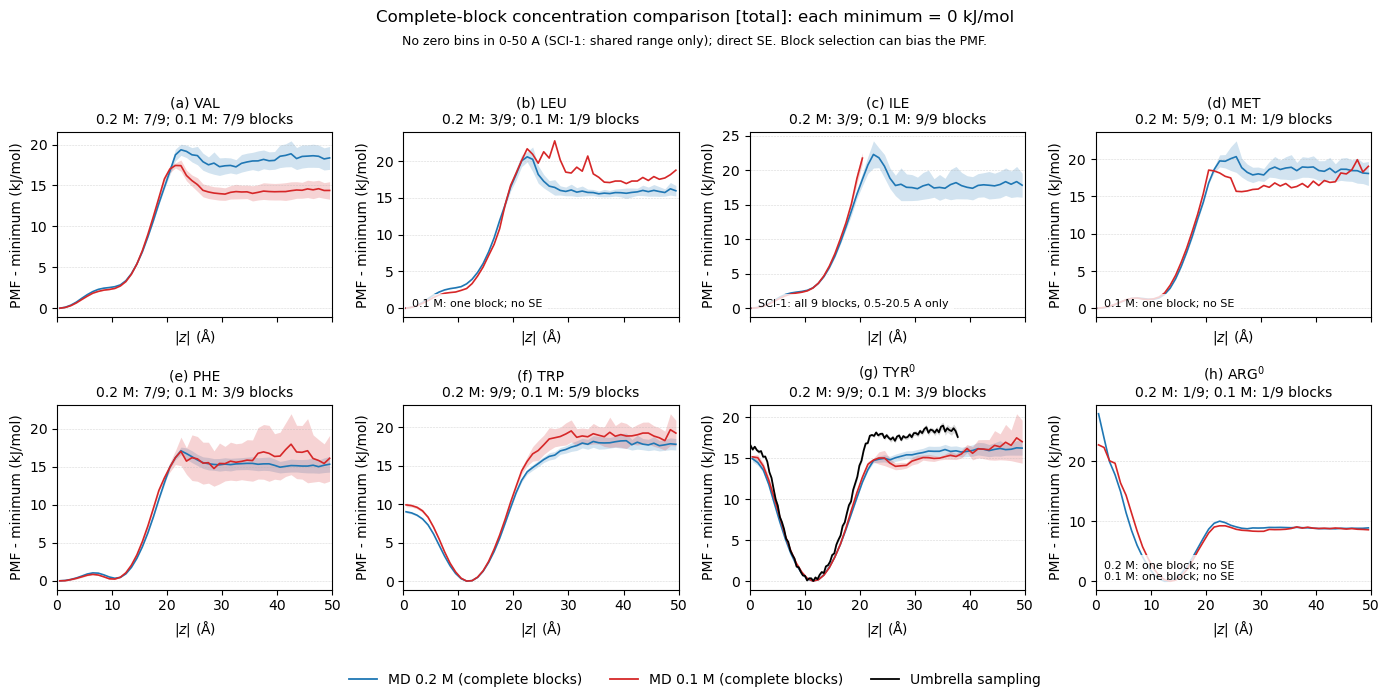

analog concentration  n_valid  n_total           status                          selection  z_min_A  z_max_A
   scv         0.2 M        7        9  direct block SE             complete 0-50 A blocks      0.5     49.5
 scv-1         0.1 M        7        9  direct block SE             complete 0-50 A blocks      0.5     49.5
   scl         0.2 M        3        9  direct block SE             complete 0-50 A blocks      0.5     49.5
 scl-1         0.1 M        1        9 one block; no SE             complete 0-50 A blocks      0.5     49.5
   sci         0.2 M        3        9  direct block SE             complete 0-50 A blocks      0.5     49.5
 sci-1         0.1 M        9        9  direct block SE all blocks; shared positive prefix      0.5     20.5
   scm         0.2 M        5        9  direct block SE             complete 0-50 A blocks      0.5     49.5
 scm-1         0.1 M        1        9 one block; no SE             complete 0-50 A blocks      0.5     49.5
   scf         0.2 

In [23]:
# Complete-block PMFs at 0.2 M vs 0.1 M, plus US where available (independent cell).
# MD: retain entire blocks with no zero folded bin in 0-50 A; invert without pseudocounts.
# SCI-1 exception: use all nine blocks over their shared positive prefix starting at 0.5 A.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ANALOGS = {"scv": "VAL", "scl": "LEU", "sci": "ILE", "scm": "MET",
           "scf": "PHE", "scw": "TRP", "scy": r"TYR$^0$", "scrn": r"ARG$^0$"}
MODE = "total"
XLIM = (0.0, 50.0)
Z_BIN = 1.0
K_B, TEMPERATURE = 0.008314, 303.15
KCAL_TO_KJ = 4.184
SAVE_NAME = f"FigureS_PMF_complete_blocks_concentration_US_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_folded_blocks(folder):
    arrays = [np.loadtxt(folder / f"trajectory{t}.dat", skiprows=1) for t in (1, 2, 3)]
    if any(a.ndim != 2 or a.shape[1] != 4 or not np.isfinite(a).all()
           or (a[:, 1:] < 0).any() for a in arrays):
        raise ValueError(f"Invalid three-block distribution file in {folder}")
    z = np.unique(np.concatenate([np.abs(a[:, 0]) for a in arrays]))
    if z[-1] < XLIM[1]:
        z = np.concatenate([z, np.arange(z[-1] + Z_BIN, XLIM[1] + Z_BIN, Z_BIN)])
    blocks, ids = [], []
    for t, arr in enumerate(arrays, start=1):
        idx = np.searchsorted(z, np.abs(arr[:, 0]))
        for b in range(3):
            folded = np.zeros(len(z))
            np.add.at(folded, idx, arr[:, b + 1])
            if folded.sum() <= 0:
                raise ValueError(f"Empty distribution: {folder.name}, trajectory {t}, block {b + 1}")
            blocks.append(folded / folded.sum())
            ids.append(f"traj{t}:{400 + 200 * b}-{600 + 200 * b}ns")
    keep = (z >= XLIM[0]) & (z <= XLIM[1])
    expected_z = np.arange(0.5, 50.0, Z_BIN)
    if z[keep].shape != expected_z.shape or not np.allclose(z[keep], expected_z):
        raise ValueError(f"Unexpected folded grid in {folder}; expected 0.5-49.5 A bin centres")
    return z[keep], np.array(blocks)[:, keep], ids


ROOT = find_repo_root()
DIST_DIR = ROOT / "figures" / "data" / "distribution_data" / MODE
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
if not US_DIR.is_dir():
    raise FileNotFoundError(f"Umbrella sampling directory not found: {US_DIR}")

print("WARNING: complete-block selection can bias the PMF. SE is unavailable for a single retained block.\n"
      "Each curve minimum is set to zero; bands retain direct SE without propagating minimum uncertainty.\n"
      "US uses its existing untranslated mean and direct SE, without MD block filtering.")
summary_rows, block_rows, pmf_rows = [], [], []
fig, axes = plt.subplots(2, 4, figsize=(14.0, 7.0), sharex=True)
for ax, panel, (analog, label) in zip(axes.flat, "abcdefgh", ANALOGS.items()):
    counts, notes = [], []
    for name, concentration, color in ((analog, "0.2 M", "tab:blue"), (f"{analog}-1", "0.1 M", "tab:red")):
        z, probabilities, block_ids = read_folded_blocks(DIST_DIR / name)
        zero_bins = (probabilities == 0).sum(axis=1)
        selection = "complete 0-50 A blocks"
        if name == "sci-1":
            shared_positive = (probabilities > 0).all(axis=0)
            missing = np.flatnonzero(~shared_positive)
            stop = int(missing[0]) if len(missing) else len(z)
            if stop < 2:
                raise ValueError("SCI-1 needs at least two shared positive bins starting at 0.5 A")
            z, probabilities = z[:stop], probabilities[:, :stop]
            selection = "all blocks; shared positive prefix"
            notes.append(f"SCI-1: all 9 blocks, {z[0]:g}-{z[-1]:g} A only")
        valid = (probabilities > 0).all(axis=1)
        n_valid = int(valid.sum())
        counts.append(n_valid)
        status = "no complete block" if n_valid == 0 else "one block; no SE" if n_valid == 1 else "direct block SE"
        summary_rows.append({"analog": name, "concentration": concentration, "n_valid": n_valid,
                             "n_total": len(valid), "status": status, "selection": selection,
                             "z_min_A": float(z[0]), "z_max_A": float(z[-1])})
        block_rows.extend({"analog": name, "block": bid, "zero_bins_0_50A": int(nz), "retained": bool(ok),
                           "selection": selection, "z_min_A": float(z[0]), "z_max_A": float(z[-1])}
                          for bid, nz, ok in zip(block_ids, zero_bins, valid))
        if n_valid == 0:
            notes.append(f"{concentration}: no complete block")
            continue
        block_pmfs = -K_B * TEMPERATURE * np.log(probabilities[valid])
        mean = block_pmfs.mean(axis=0)
        mean -= mean.min()
        se = block_pmfs.std(axis=0, ddof=1) / np.sqrt(n_valid) if n_valid > 1 else np.full(len(z), np.nan)
        ax.plot(z, mean, color=color, lw=1.2, label=f"MD {concentration} ({selection})")
        if n_valid > 1:
            ax.fill_between(z, mean - se, mean + se, color=color, alpha=0.2, lw=0)
        else:
            notes.append(f"{concentration}: one block; no SE")
        pmf_rows.extend({"analog": name, "series": f"MD {concentration}", "z_A": float(zi),
                         "pmf_kJ_mol": float(mi), "direct_se_kJ_mol": float(si), "n_blocks": n_valid}
                        for zi, mi, si in zip(z, mean, se))

    us_path = US_DIR / analog / f"pmf-us-{analog}-untranslated.dat"
    if us_path.is_file():
        us = pd.read_csv(us_path, sep=r"\s+", comment="#", header=None, names=["z", "mean", "se", "n_blocks"])
        us = us.loc[us["z"].between(*XLIM)].copy()
        if (len(us) < 2 or not np.isfinite(us.to_numpy()).all() or (us["se"] < 0).any()
                or np.any(np.diff(us["z"]) <= 0)):
            raise ValueError(f"Invalid untranslated umbrella PMF: {us_path}")
        us[["mean", "se"]] *= KCAL_TO_KJ
        us["mean"] -= us["mean"].min()
        if int(us["n_blocks"].iloc[0]) != 3:
            notes.append(f"US: {int(us['n_blocks'].iloc[0])} x 50 ns blocks")
        ax.plot(us["z"], us["mean"], color="black", lw=1.3, label="Umbrella sampling")
        ax.fill_between(us["z"], us["mean"] - us["se"], us["mean"] + us["se"], color="black", alpha=0.15, lw=0)
        pmf_rows.extend({"analog": analog, "series": "US", "z_A": float(row.z), "pmf_kJ_mol": float(row.mean),
                         "direct_se_kJ_mol": float(row.se), "n_blocks": int(row.n_blocks)}
                        for row in us.itertuples(index=False))
    elif us_path.parent.is_dir():
        print(f"WARNING: {analog.upper()} umbrella data exist but its PMF is unavailable: {us_path}")
        notes.append("US PMF unavailable")
    if notes:
        ax.text(0.03, 0.04, "\n".join(notes), transform=ax.transAxes, fontsize=8, va="bottom",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
    ax.set_title(f"({panel}) {label}\n0.2 M: {counts[0]}/9; 0.1 M: {counts[1]}/9 blocks", fontsize=10)
    ax.set_xlim(*XLIM)
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    ax.set_ylabel("PMF - minimum (kJ/mol)")
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)

handles = [Line2D([], [], color=color, lw=1.3, label=label) for label, color in
           (("MD 0.2 M (complete blocks)", "tab:blue"), ("MD 0.1 M (complete blocks)", "tab:red"), ("Umbrella sampling", "black"))]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
fig.suptitle(f"Complete-block concentration comparison [{MODE}]: each minimum = 0 kJ/mol")
fig.text(0.5, 0.93, "No zero bins in 0-50 A (SCI-1: shared range only); direct SE. Block selection can bias the PMF.", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.06, 1, 0.92))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()
selection_summary = pd.DataFrame(summary_rows)
selection_summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_selection.csv", index=False)
pd.DataFrame(block_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_blocks.csv", index=False)
pd.DataFrame(pmf_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
print(selection_summary.to_string(index=False))


In [ ]:
# Concentration comparison using one pooled 600 ns block per trajectory (independent cell).
# Pool three equal-size distributions before log inversion; retain zero-free trajectories.
# SCI-1 uses all three trajectories over their shared positive prefix from 0.5 A.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ANALOGS = {"scv": "VAL", "scl": "LEU", "sci": "ILE", "scm": "MET",
           "scf": "PHE", "scw": "TRP", "scy": r"TYR$^0$", "scrn": r"ARG$^0$"}
MODE = "total"
XLIM = (0.0, 50.0)
Z_BIN = 1.0
K_B, TEMPERATURE = 0.008314, 303.15
KCAL_TO_KJ = 4.184
SAVE_NAME = f"FigureS_PMF_pooled_trajectories_concentration_US_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_pooled_trajectories(folder):
    arrays = [np.loadtxt(folder / f"trajectory{t}.dat", skiprows=1) for t in (1, 2, 3)]
    if any(a.ndim != 2 or a.shape[1] != 4 or not np.isfinite(a).all()
           or (a[:, 1:] < 0).any() for a in arrays):
        raise ValueError(f"Invalid three-block distribution file in {folder}")
    z = np.unique(np.concatenate([np.abs(a[:, 0]) for a in arrays]))
    if z[-1] < XLIM[1]:
        z = np.concatenate([z, np.arange(z[-1] + Z_BIN, XLIM[1] + Z_BIN, Z_BIN)])
    trajectories, ids = [], []
    for t, arr in enumerate(arrays, start=1):
        pooled = arr[:, 1:].mean(axis=1)
        folded = np.zeros(len(z))
        np.add.at(folded, np.searchsorted(z, np.abs(arr[:, 0])), pooled)
        if folded.sum() <= 0:
            raise ValueError(f"Empty pooled distribution: {folder.name}, trajectory {t}")
        trajectories.append(folded / folded.sum())
        ids.append(f"traj{t}:400-1000ns")
    keep = (z >= XLIM[0]) & (z <= XLIM[1])
    expected_z = np.arange(0.5, 50.0, Z_BIN)
    if z[keep].shape != expected_z.shape or not np.allclose(z[keep], expected_z):
        raise ValueError(f"Unexpected folded grid in {folder}; expected 0.5-49.5 A bin centres")
    return z[keep], np.array(trajectories)[:, keep], ids


ROOT = find_repo_root()
DIST_DIR = ROOT / "figures" / "data" / "distribution_data" / MODE
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
if not US_DIR.is_dir():
    raise FileNotFoundError(f"Umbrella sampling directory not found: {US_DIR}")

print("WARNING: complete-trajectory selection can bias the PMF. SE is unavailable for one retained trajectory.\n"
      "Three 200 ns distributions are pooled before log inversion: at most three 600 ns replicates.\n"
      "Each curve minimum is zero; direct SE does not propagate minimum uncertainty.\n"
      "US uses its existing untranslated mean and direct SE, without MD filtering.")
summary_rows, trajectory_rows, pmf_rows = [], [], []
fig, axes = plt.subplots(2, 4, figsize=(14.0, 7.0), sharex=True)
for ax, panel, (analog, label) in zip(axes.flat, "abcdefgh", ANALOGS.items()):
    counts, notes = [], []
    for name, concentration, color in ((analog, "0.2 M", "tab:blue"), (f"{analog}-1", "0.1 M", "tab:red")):
        z, probabilities, trajectory_ids = read_pooled_trajectories(DIST_DIR / name)
        zero_bins = (probabilities == 0).sum(axis=1)
        selection = "complete 0-50 A trajectories"
        if name == "sci-1":
            shared_positive = (probabilities > 0).all(axis=0)
            missing = np.flatnonzero(~shared_positive)
            stop = int(missing[0]) if len(missing) else len(z)
            if stop < 2:
                raise ValueError("SCI-1 needs at least two shared positive bins starting at 0.5 A")
            z, probabilities = z[:stop], probabilities[:, :stop]
            selection = "all trajectories; shared positive prefix"
            notes.append(f"SCI-1: all 3 trajectories, {z[0]:g}-{z[-1]:g} A only")
        valid = (probabilities > 0).all(axis=1)
        n_valid = int(valid.sum())
        counts.append(n_valid)
        status = "no complete trajectory" if n_valid == 0 else "one trajectory; no SE" if n_valid == 1 else "direct trajectory SE"
        summary_rows.append({"analog": name, "concentration": concentration, "n_valid": n_valid,
                             "n_total": len(valid), "status": status, "selection": selection,
                             "z_min_A": float(z[0]), "z_max_A": float(z[-1])})
        trajectory_rows.extend({"analog": name, "trajectory": tid, "zero_bins_0_50A": int(nz),
                                "retained": bool(ok), "selection": selection,
                                "z_min_A": float(z[0]), "z_max_A": float(z[-1])}
                               for tid, nz, ok in zip(trajectory_ids, zero_bins, valid))
        if n_valid == 0:
            notes.append(f"{concentration}: no complete trajectory")
            continue
        trajectory_pmfs = -K_B * TEMPERATURE * np.log(probabilities[valid])
        mean = trajectory_pmfs.mean(axis=0)
        mean -= mean.min()
        se = trajectory_pmfs.std(axis=0, ddof=1) / np.sqrt(n_valid) if n_valid > 1 else np.full(len(z), np.nan)
        ax.plot(z, mean, color=color, lw=1.2, label=f"MD {concentration} ({selection})")
        if n_valid > 1:
            ax.fill_between(z, mean - se, mean + se, color=color, alpha=0.2, lw=0)
        else:
            notes.append(f"{concentration}: one trajectory; no SE")
        pmf_rows.extend({"analog": name, "series": f"MD {concentration}", "z_A": float(zi),
                         "pmf_kJ_mol": float(mi), "direct_se_kJ_mol": float(si), "n_trajectories": n_valid}
                        for zi, mi, si in zip(z, mean, se))

    us_path = US_DIR / analog / f"pmf-us-{analog}-untranslated.dat"
    if us_path.is_file():
        us = pd.read_csv(us_path, sep=r"\s+", comment="#", header=None, names=["z", "mean", "se", "n_blocks"])
        us = us.loc[us["z"].between(*XLIM)].copy()
        if (len(us) < 2 or not np.isfinite(us.to_numpy()).all() or (us["se"] < 0).any()
                or np.any(np.diff(us["z"]) <= 0)):
            raise ValueError(f"Invalid untranslated umbrella PMF: {us_path}")
        us[["mean", "se"]] *= KCAL_TO_KJ
        us["mean"] -= us["mean"].min()
        if int(us["n_blocks"].iloc[0]) != 3:
            notes.append(f"US: {int(us['n_blocks'].iloc[0])} x 50 ns blocks")
        ax.plot(us["z"], us["mean"], color="black", lw=1.3, label="Umbrella sampling")
        ax.fill_between(us["z"], us["mean"] - us["se"], us["mean"] + us["se"], color="black", alpha=0.15, lw=0)
        pmf_rows.extend({"analog": analog, "series": "US", "z_A": float(row.z), "pmf_kJ_mol": float(row.mean),
                         "direct_se_kJ_mol": float(row.se), "n_blocks": int(row.n_blocks)}
                        for row in us.itertuples(index=False))
    elif us_path.parent.is_dir():
        print(f"WARNING: {analog.upper()} umbrella data exist but its PMF is unavailable: {us_path}")
        notes.append("US PMF unavailable")
    if notes:
        ax.text(0.03, 0.04, "\n".join(notes), transform=ax.transAxes, fontsize=8, va="bottom",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
    ax.set_title(f"({panel}) {label}\n0.2 M: {counts[0]}/3; 0.1 M: {counts[1]}/3 trajectories", fontsize=10)
    ax.set_xlim(*XLIM)
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    ax.set_ylabel("PMF - minimum (kJ/mol)")
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)

handles = [Line2D([], [], color=color, lw=1.3, label=label) for label, color in
           (("MD 0.2 M (pooled trajectories)", "tab:blue"), ("MD 0.1 M (pooled trajectories)", "tab:red"), ("Umbrella sampling", "black"))]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
fig.suptitle(f"Pooled-trajectory concentration comparison [{MODE}]: each minimum = 0 kJ/mol")
fig.text(0.5, 0.93, "3 x 200 ns pooled per trajectory; no zero bins in 0-50 A (SCI-1: shared range). Selection can bias the PMF.", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.06, 1, 0.92))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()
selection_summary = pd.DataFrame(summary_rows)
selection_summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_selection.csv", index=False)
pd.DataFrame(trajectory_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_trajectories.csv", index=False)
pd.DataFrame(pmf_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
print(selection_summary.to_string(index=False))


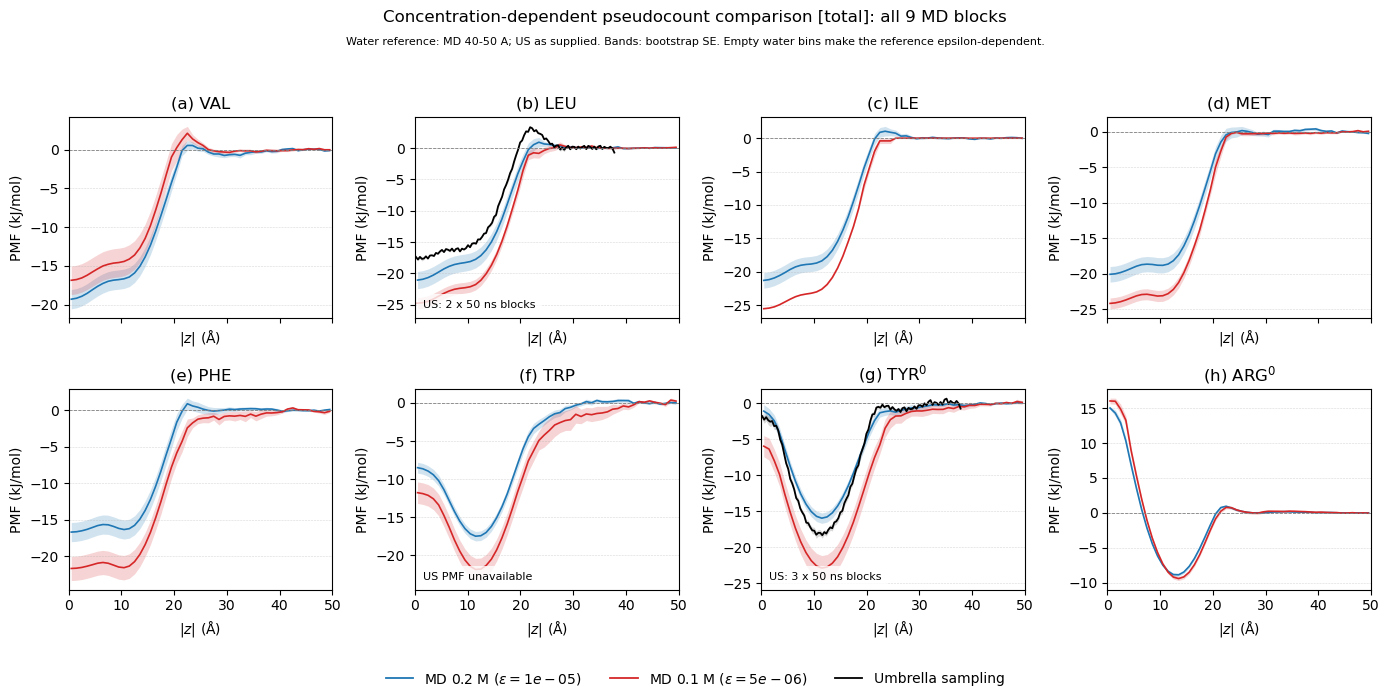

analog concentration  epsilon  n_blocks  a_kJ_mol  sigma_a_kJ_mol  empty_water_block_bins  water_block_bins  unweighted_reference
   scv         0.2 M 0.000010         9 24.429451    1.236007e+00                      20                90                 False
 scv-1         0.1 M 0.000005         9 22.143801    1.826191e+00                      20                90                 False
   scl         0.2 M 0.000010         9 26.055968    1.362713e+00                      50                90                 False
 scl-1         0.1 M 0.000005         9 29.886227    8.796361e-01                      80                90                 False
   sci         0.2 M 0.000010         9 26.439506    1.148006e+00                      50                90                 False
 sci-1         0.1 M 0.000005         9 30.764052    3.768410e-15                      90                90                  True
   scm         0.2 M 0.000010         9 25.842253    1.085759e+00                      30 

In [25]:
# Concentration comparison with epsilon = 1e-5 (0.2 M) or 5e-6 (0.1 M), independent cell.
# Recompute all nine block PMFs, their water reference, and bootstrap SE from distributions.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ANALOGS = {"scv": "VAL", "scl": "LEU", "sci": "ILE", "scm": "MET",
           "scf": "PHE", "scw": "TRP", "scy": r"TYR$^0$", "scrn": r"ARG$^0$"}
MODE = "total"
EPSILON_02M, EPSILON_01M = 1e-5, 5e-6
K_B, TEMPERATURE = 0.008314, 303.15
KCAL_TO_KJ = 4.184
XLIM, REF_WINDOW = (0.0, 50.0), (40.0, 50.0)
Z_BIN, SE_FLOOR = 1.0, 1e-9
N_BOOT, SEED = 10000, 2025
SAVE_NAME = f"FigureS_PMF_concentration_scaled_epsilon_US_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_folded_probabilities(folder):
    arrays = [np.loadtxt(folder / f"trajectory{t}.dat", skiprows=1) for t in (1, 2, 3)]
    if any(a.ndim != 2 or a.shape[1] != 4 or not np.isfinite(a).all()
           or (a[:, 1:] < 0).any() or np.any(np.diff(a[:, 0]) <= 0) for a in arrays):
        raise ValueError(f"Invalid three-block distribution data: {folder}")
    z = np.unique(np.concatenate([np.abs(a[:, 0]) for a in arrays]))
    if z[-1] < XLIM[1]:
        z = np.concatenate([z, np.arange(z[-1] + Z_BIN, XLIM[1] + Z_BIN, Z_BIN)])
    probabilities, block_ids = [], []
    for t, arr in enumerate(arrays, start=1):
        idx = np.searchsorted(z, np.abs(arr[:, 0]))
        contributions = np.bincount(idx, minlength=len(z))
        for b in range(3):
            folded = np.zeros(len(z))
            np.add.at(folded, idx, arr[:, b + 1])
            # Match production: average signed sides, then normalize on the full native grid.
            present = contributions > 0
            folded[present] /= contributions[present]
            if folded.sum() <= 0:
                raise ValueError(f"Empty distribution: {folder.name}, trajectory {t}, block {b + 1}")
            probabilities.append(folded / folded.sum())
            block_ids.append(f"traj{t}:{400 + 200 * b}-{600 + 200 * b}ns")
    return z, np.array(probabilities), block_ids


def block_mean_se(pmfs):
    n = pmfs.shape[-2]
    return pmfs.mean(axis=-2), pmfs.std(axis=-2, ddof=1) / np.sqrt(n)


def water_reference(mean, se, mask):
    m, s = mean[..., mask], se[..., mask]
    degenerate = np.any(s <= SE_FLOOR, axis=-1, keepdims=True)
    w = np.where(degenerate, 1.0, 1.0 / np.where(s > SE_FLOOR, s, 1.0) ** 2)
    return np.sum(w * m, axis=-1) / np.sum(w, axis=-1)


def calculate_pmf(z, probabilities, epsilon):
    if not np.isfinite(epsilon) or epsilon <= 0:
        raise ValueError(f"Epsilon must be finite and positive, got {epsilon}")
    win = (z >= REF_WINDOW[0]) & (z <= REF_WINDOW[1])
    if not win.any():
        raise ValueError(f"No bins in the water-reference window {REF_WINDOW}")
    block_pmfs = -K_B * TEMPERATURE * np.log(probabilities + epsilon)
    mean_raw, se_raw = block_mean_se(block_pmfs)
    a_ref = float(water_reference(mean_raw, se_raw, win))
    n = len(block_pmfs)
    idx = np.random.default_rng(SEED).integers(0, n, size=(N_BOOT, n))
    boot_mean, boot_se = block_mean_se(block_pmfs[idx])
    boot_a = water_reference(boot_mean, boot_se, win)
    correction = np.sqrt(n / (n - 1))
    return {"block_pmfs": block_pmfs, "mean_raw": mean_raw, "se_raw": se_raw,
            "mean": mean_raw - a_ref,
            "se": correction * (boot_mean - boot_a[:, None]).std(axis=0, ddof=1),
            "a": a_ref, "sigma_a": float(correction * boot_a.std(ddof=1)),
            "empty_water_block_bins": int((probabilities[:, win] == 0).sum()),
            "water_block_bins": int(probabilities[:, win].size),
            "unweighted_reference": bool((se_raw[win] <= SE_FLOOR).any())}


ROOT = find_repo_root()
DIST_DIR = ROOT / "figures" / "data" / "distribution_data" / MODE
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
if not US_DIR.is_dir():
    raise FileNotFoundError(f"Umbrella sampling directory not found: {US_DIR}")
reference_rows, pmf_rows, block_rows = [], [], []
fig, axes = plt.subplots(2, 4, figsize=(14.0, 7.0), sharex=True)
for ax, panel, (analog, label) in zip(axes.flat, "abcdefgh", ANALOGS.items()):
    notes = []
    for name, concentration, epsilon, color in (
            (analog, "0.2 M", EPSILON_02M, "tab:blue"),
            (f"{analog}-1", "0.1 M", EPSILON_01M, "tab:red")):
        z, probabilities, block_ids = read_folded_probabilities(DIST_DIR / name)
        result = calculate_pmf(z, probabilities, epsilon)
        if result["empty_water_block_bins"]:
            print(f"WARNING: {name}: {result['empty_water_block_bins']}/{result['water_block_bins']} "
                  f"empty water block/bins; the water reference depends on epsilon = {epsilon:g}.")
        if result["unweighted_reference"]:
            print(f"WARNING: {name}: zero water SE; using an unweighted water reference, as in production.")
        reference_rows.append({"analog": name, "concentration": concentration, "epsilon": epsilon,
                               "n_blocks": len(block_ids), "a_kJ_mol": result["a"],
                               "sigma_a_kJ_mol": result["sigma_a"],
                               **{key: result[key] for key in ("empty_water_block_bins", "water_block_bins", "unweighted_reference")}})
        show = (z >= XLIM[0]) & (z <= XLIM[1])
        ax.plot(z[show], result["mean"][show], color=color, lw=1.2, label=f"MD {concentration}")
        ax.fill_between(z[show], (result["mean"] - result["se"])[show],
                        (result["mean"] + result["se"])[show], color=color, alpha=0.2, lw=0)
        pmf_rows.extend({"analog": name, "series": f"MD {concentration}", "epsilon": epsilon,
                         "z_A": float(z[j]), "pmf_kJ_mol": float(result["mean"][j]),
                         "se_kJ_mol": float(result["se"][j]), "n_blocks": len(block_ids),
                         "mean_raw_kJ_mol": float(result["mean_raw"][j]),
                         "direct_se_kJ_mol": float(result["se_raw"][j]),
                         "n_empty_blocks": int((probabilities[:, j] == 0).sum())}
                        for j in np.flatnonzero(show))
        block_rows.extend({"analog": name, "block": bid, "epsilon": epsilon,
                           "z_A": float(z[j]), "probability": float(probabilities[b, j]),
                           "pmf_raw_kJ_mol": float(result["block_pmfs"][b, j])}
                          for b, bid in enumerate(block_ids) for j in np.flatnonzero(show))
    us_path = US_DIR / analog / f"pmf-us-{analog}.dat"
    if us_path.is_file():
        us = pd.read_csv(us_path, sep=r"\s+", comment="#", header=None, names=["z", "mean", "se", "n"])
        us = us.loc[us["z"].between(*XLIM)].copy()
        if (len(us) < 2 or not np.isfinite(us.to_numpy()).all() or (us["se"] < 0).any()
                or np.any(np.diff(us["z"]) <= 0) or us["n"].nunique() != 1 or us["n"].iloc[0] < 2):
            raise ValueError(f"Invalid umbrella PMF: {us_path}")
        us[["mean", "se"]] *= KCAL_TO_KJ
        ax.plot(us["z"], us["mean"], color="black", lw=1.3, label="Umbrella sampling")
        ax.fill_between(us["z"], us["mean"] - us["se"], us["mean"] + us["se"], color="black", alpha=0.15, lw=0)
        notes.append(f"US: {int(us['n'].iloc[0])} x 50 ns blocks")
        pmf_rows.extend({"analog": analog, "series": "US", "epsilon": np.nan, "z_A": float(row.z),
                         "pmf_kJ_mol": float(row.mean), "se_kJ_mol": float(row.se), "n_blocks": int(row.n)}
                        for row in us.itertuples(index=False))
    elif us_path.parent.is_dir():
        print(f"WARNING: {analog.upper()} umbrella data exist but its PMF is unavailable: {us_path}")
        notes.append("US PMF unavailable")
    if notes:
        ax.text(0.03, 0.04, "\n".join(notes), transform=ax.transAxes, fontsize=8, va="bottom",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
    ax.set_title(f"({panel}) {label}")
    ax.set_xlim(*XLIM)
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    ax.set_ylabel("PMF (kJ/mol)")
    ax.axhline(0, color="gray", lw=0.6, ls="--")
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
handles = [Line2D([], [], color="tab:blue", lw=1.3, label=rf"MD 0.2 M ($\varepsilon={EPSILON_02M:g}$)"),
           Line2D([], [], color="tab:red", lw=1.3, label=rf"MD 0.1 M ($\varepsilon={EPSILON_01M:g}$)"),
           Line2D([], [], color="black", lw=1.3, label="Umbrella sampling")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
fig.suptitle(f"Concentration-dependent pseudocount comparison [{MODE}]: all 9 MD blocks")
fig.text(0.5, 0.93, "Water reference: MD 40-50 A; US as supplied. Bands: bootstrap SE. Empty water bins make the reference epsilon-dependent.",
         ha="center", fontsize=8)
fig.tight_layout(rect=(0, 0.06, 1, 0.92))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()
reference_summary = pd.DataFrame(reference_rows)
reference_summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_water_reference.csv", index=False)
pd.DataFrame(pmf_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
pd.DataFrame(block_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_blocks.csv", index=False)
print(reference_summary.to_string(index=False))


VAL (scv), 9 blocks, 72 |z| bins, 115 empty block/bin cells
a = 26.1302 kJ/mol (file 26.3112); sigma_a = 1.9727 (file 2.2426); independent-bin sigma_a = 0.6212
max |PMF - file| = 3.1e-01 kJ/mol; max |SE - file| = 2.7e-01 kJ/mol


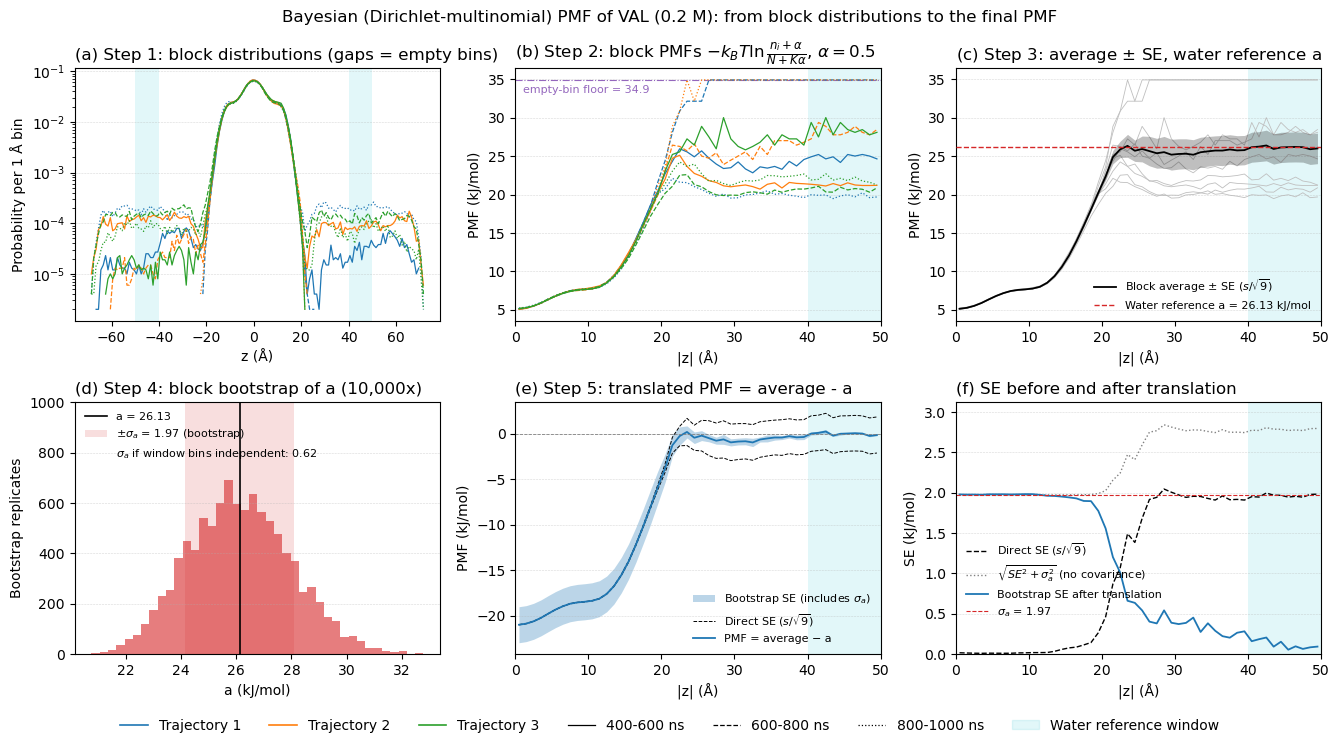

In [28]:
# Step-by-step construction of the Bayesian (Dirichlet-multinomial) PMF of LEU (scl, 0.2 M), replicating
# supp_files/method_script/4-pmf_calculation_bayesian/pmf-from-distribution.py (independent cell)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ANALOG, LABEL = "scv", "VAL"
MODE = "total"
METHOD = "latent"
K_B, T = 0.008314, 303.15  # kJ/(mol K), K
ALPHA = 0.5  # Jeffreys pseudocount of the Dirichlet prior
REF_WINDOW = (40.0, 50.0)  # bulk-water window (A)
N_TRAJ, N_BATCH = 3, 3  # 3 trajectories x 3 blocks of 200 ns (400-1000 ns)
N_BOOT, SEED = 10000, 2025  # block bootstrap, same settings as the script
SE_FLOOR = 1e-9
Z_BIN, XMAX = 1.0, 50
TRAJ_COLORS = ("tab:blue", "tab:orange", "tab:green")
BLOCK_STYLES = ("-", "--", ":")
SAVE_NAME = f"FigureS_PMF_{METHOD}_steps_{ANALOG}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures/data/distribution_data").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def water_reference(mean, se, mask):
    """Inverse-variance weighted mean over the water window (unweighted if any SE <= SE_FLOOR)."""
    m, s = mean[..., mask], se[..., mask]
    degenerate = np.any(s <= SE_FLOOR, axis=-1, keepdims=True)
    w = np.where(degenerate, 1.0, 1.0 / np.where(s > SE_FLOOR, s, 1.0) ** 2)
    return np.sum(w * m, axis=-1) / np.sum(w, axis=-1)


def block_mean_se(pmfs):
    n = pmfs.shape[-2]
    return pmfs.mean(axis=-2), pmfs.std(axis=-2, ddof=1) / np.sqrt(n)


ROOT = find_repo_root()
DIST_DIR = ROOT / "figures/data/distribution_data"
OUT_DIR = ROOT / f"supp_files/method_script/4-pmf_calculation_{METHOD}" / MODE
SAVE_DIR = ROOT / "figures/plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# --- Step 1: block distributions -> exact counts, folded onto |z| ---
raw_summary = pd.read_csv(DIST_DIR / "raw_data_summary.dat", sep=r"\s+")
dists = {t: np.loadtxt(DIST_DIR / MODE / ANALOG / f"trajectory{t}.dat", skiprows=1) for t in range(1, N_TRAJ + 1)}
z_pos = np.array(sorted({abs(v) for arr in dists.values() for v in arr[:, 0]}))
if z_pos[-1] < 50:  # grid extended to 50 A with genuine zero-count bins
    z_pos = np.concatenate([z_pos, np.arange(z_pos[-1] + Z_BIN, 50 + Z_BIN, Z_BIN)])
counts, block_ids = [], []
for t, arr in dists.items():
    sizes = raw_summary.loc[(raw_summary["residu"] == ANALOG) & (raw_summary["traj"] == t), "n_lines"]
    if sizes.empty:
        raw_path = DIST_DIR / "raw_data" / ANALOG / f"{ANALOG}_contacts_{t}.dat"
        with raw_path.open("rb") as fh:
            n_lines = sum(1 for _ in fh) - 1
        print(f"{ANALOG} trajectory {t}: sample size read from raw data ({n_lines} molecule-frames)")
    else:
        n_lines = int(sizes.item())
    if n_lines % N_BATCH:
        raise ValueError(f"{ANALOG} trajectory {t}: {n_lines} rows cannot be divided into {N_BATCH} equal blocks")
    depth = n_lines // N_BATCH  # molecule-frames per block
    fold_idx = np.array([np.argmin(np.abs(z_pos - abs(z))) for z in arr[:, 0]])
    for b in range(N_BATCH):
        folded = np.zeros(len(z_pos))
        np.add.at(folded, fold_idx, np.rint(arr[:, 1 + b] * depth))
        counts.append(folded)
        block_ids.append((t, b))
counts = np.array(counts)
n_blocks, n_bins = counts.shape

# --- Step 2: untranslated block PMFs from the Dirichlet posterior mean p = (n + alpha) / (N + K alpha) ---
p_post = (counts + ALPHA) / (counts.sum(axis=1, keepdims=True) + n_bins * ALPHA)
block_pmfs = -K_B * T * np.log(p_post)

# --- Step 3: block average, SE = s/sqrt(n), water reference a ---
win = (z_pos >= REF_WINDOW[0]) & (z_pos <= REF_WINDOW[1])
mean_raw, se_raw = block_mean_se(block_pmfs)
a_ref = float(water_reference(mean_raw, se_raw, win))

# --- Step 4: block bootstrap of steps 3-5 -> sigma_a and the SE of the translated PMF ---
rng = np.random.default_rng(SEED)
boot = block_pmfs[rng.integers(0, n_blocks, size=(N_BOOT, n_blocks))]
boot_mean, boot_se = block_mean_se(boot)
boot_a = water_reference(boot_mean, boot_se, win)
corr = np.sqrt(n_blocks / (n_blocks - 1))  # small-sample correction
sigma_a = float(corr * boot_a.std(ddof=1))
sigma_a_indep = float(1.0 / np.sqrt(np.sum(1.0 / se_raw[win] ** 2)))

# --- Step 5: translated PMF and its bootstrap SE ---
mean_pmf = mean_raw - a_ref
se_pmf = corr * (boot_mean - boot_a[:, None]).std(axis=0, ddof=1)

# Consistency with the files written by the script
final = pd.read_csv(OUT_DIR / ANALOG / f"pmf_{ANALOG}.dat", sep=r"\s+")
ref_table = pd.read_csv(OUT_DIR / "water_reference.dat", sep=r"\s+").set_index("analog")
assert np.allclose(final["z"], z_pos), "z grid differs from the script output"
print(f"{LABEL} ({ANALOG}), {n_blocks} blocks, {n_bins} |z| bins, {int((counts == 0).sum())} empty block/bin cells")
print(f"a = {a_ref:.4f} kJ/mol (file {ref_table.loc[ANALOG, 'a']:.4f}); sigma_a = {sigma_a:.4f} "
      f"(file {ref_table.loc[ANALOG, 'sigma_a']:.4f}); independent-bin sigma_a = {sigma_a_indep:.4f}")
print(f"max |PMF - file| = {np.abs(mean_pmf - final['mean']).max():.1e} kJ/mol; "
      f"max |SE - file| = {np.abs(se_pmf - final['se']).max():.1e} kJ/mol")

# --- Figure ---
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.5))
ax_dist, ax_blocks, ax_avg, ax_boot, ax_final, ax_se = axes.flat
show = z_pos <= XMAX


def style(t, b):
    return dict(color=TRAJ_COLORS[t - 1], ls=BLOCK_STYLES[b], lw=0.9)


def shade_window(ax, signed=False):
    for sign in ((-1, 1) if signed else (1,)):
        lo, hi = sorted((sign * REF_WINDOW[0], sign * REF_WINDOW[1]))
        ax.axvspan(lo, hi, color="tab:cyan", alpha=0.12, lw=0, zorder=0)


# (a) raw distributions of the 9 blocks
for t, arr in dists.items():
    for b in range(N_BATCH):
        dens = np.where(arr[:, 1 + b] > 0, arr[:, 1 + b], np.nan)  # empty bins cannot be shown on a log scale
        ax_dist.plot(arr[:, 0], dens, **style(t, b))
shade_window(ax_dist, signed=True)
ax_dist.set_yscale("log")
ax_dist.set_xlabel("z (Å)")
ax_dist.set_ylabel("Probability per 1 Å bin")
ax_dist.set_title("(a) Step 1: block distributions (gaps = empty bins)", loc="left")

# (b) untranslated block PMFs
for pmf, (t, b) in zip(block_pmfs, block_ids):
    ax_blocks.plot(z_pos[show], pmf[show], **style(t, b))
shade_window(ax_blocks)
floor = float(-K_B * T * np.log(ALPHA / (counts.sum(axis=1).max() + n_bins * ALPHA)))
ax_blocks.axhline(floor, color="tab:purple", lw=0.8, ls="-.", zorder=0)
ax_blocks.text(1, floor - 0.6, f"empty-bin floor = {floor:.1f}", color="tab:purple", va="top", fontsize=8)
ax_blocks.set_title(r"(b) Step 2: block PMFs $-k_BT\ln\frac{n_i+\alpha}{N+K\alpha}$, $\alpha=0.5$", loc="left")

# (c) direct block average, SE and water reference
for pmf, (t, b) in zip(block_pmfs, block_ids):
    ax_avg.plot(z_pos[show], pmf[show], color="0.75", lw=0.6, zorder=1)
ax_avg.fill_between(z_pos[show], (mean_raw - se_raw)[show], (mean_raw + se_raw)[show], color="black", alpha=0.25, lw=0, zorder=2)
ax_avg.plot(z_pos[show], mean_raw[show], color="black", lw=1.3, zorder=3, label=r"Block average $\pm$ SE ($s/\sqrt{9}$)")
ax_avg.axhline(a_ref, color="tab:red", lw=1.0, ls="--", zorder=3, label=f"Water reference a = {a_ref:.2f} kJ/mol")
shade_window(ax_avg)
ax_avg.legend(loc="lower right", fontsize=8, frameon=False)
ax_avg.set_title(r"(c) Step 3: average $\pm$ SE, water reference a", loc="left")

# (d) bootstrap distribution of the water reference
n_hist, _, _ = ax_boot.hist(boot_a, bins=40, color="tab:red", alpha=0.6)
ax_boot.axvline(a_ref, color="black", lw=1.2, label=f"a = {a_ref:.2f}")
ax_boot.axvspan(a_ref - sigma_a, a_ref + sigma_a, color="tab:red", alpha=0.15, lw=0,
                label=rf"$\pm\sigma_a$ = {sigma_a:.2f} (bootstrap)")
ax_boot.plot([], [], " ", label=rf"$\sigma_a$ if window bins independent: {sigma_a_indep:.2f}")
ax_boot.set_ylim(0, n_hist.max() * 1.45)
ax_boot.legend(loc="upper left", fontsize=8, frameon=False)
ax_boot.set_xlabel("a (kJ/mol)")
ax_boot.set_ylabel("Bootstrap replicates")
ax_boot.set_title(f"(d) Step 4: block bootstrap of a ({N_BOOT:,}x)", loc="left")

# (e) translated PMF with the naive and the bootstrap SE
ax_final.fill_between(z_pos[show], (mean_pmf - se_pmf)[show], (mean_pmf + se_pmf)[show], color="tab:blue", alpha=0.3, lw=0,
                      label="Bootstrap SE (includes $\\sigma_a$)")
for sign in (-1, 1):
    ax_final.plot(z_pos[show], (mean_pmf + sign * se_raw)[show], color="black", lw=0.7, ls="--",
                  label="Direct SE ($s/\\sqrt{9}$)" if sign == 1 else None)
ax_final.plot(z_pos[show], mean_pmf[show], color="tab:blue", lw=1.3, label="PMF = average − a")
ax_final.axhline(0, color="gray", lw=0.6, ls="--")
shade_window(ax_final)
ax_final.legend(loc="lower right", fontsize=8, frameon=False)
ax_final.set_title("(e) Step 5: translated PMF = average - a", loc="left")

# (f) SE profiles before and after translation
ax_se.plot(z_pos[show], se_raw[show], color="black", lw=1.0, ls="--", label=r"Direct SE ($s/\sqrt{9}$)")
ax_se.plot(z_pos[show], np.sqrt(se_raw**2 + sigma_a**2)[show], color="0.5", lw=1.0, ls=":",
           label=r"$\sqrt{SE^2+\sigma_a^2}$ (no covariance)")
ax_se.plot(z_pos[show], se_pmf[show], color="tab:blue", lw=1.3, label="Bootstrap SE after translation")
ax_se.axhline(sigma_a, color="tab:red", lw=0.8, ls="--", label=rf"$\sigma_a$ = {sigma_a:.2f}")
shade_window(ax_se)
ax_se.set_ylim(0, max(se_pmf[show].max(), np.sqrt(se_raw**2 + sigma_a**2)[show].max()) * 1.1)
ax_se.legend(loc="lower left", bbox_to_anchor=(0.0, 0.1), fontsize=8, frameon=False)
ax_se.set_ylabel("SE (kJ/mol)")
ax_se.set_title("(f) SE before and after translation", loc="left")

for ax in (ax_blocks, ax_avg, ax_final, ax_se):
    ax.set_xlim(0, XMAX)
    ax.set_xlabel("|z| (Å)")
for ax in (ax_blocks, ax_avg, ax_final):
    ax.set_ylabel("PMF (kJ/mol)")
for ax in axes.flat:
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)

block_handles = [Line2D([], [], color=c, lw=1.2) for c in TRAJ_COLORS] + [Line2D([], [], color="black", ls=s, lw=0.9) for s in BLOCK_STYLES]
block_labels = [f"Trajectory {t}" for t in range(1, N_TRAJ + 1)] + ["400-600 ns", "600-800 ns", "800-1000 ns"]
block_handles.append(plt.Rectangle((0, 0), 1, 1, color="tab:cyan", alpha=0.12))
block_labels.append("Water reference window")
fig.legend(block_handles, block_labels, loc="lower center", ncol=len(block_labels), frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.suptitle(f"Bayesian (Dirichlet-multinomial) PMF of {LABEL} (0.2 M): from block distributions to the final PMF")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()


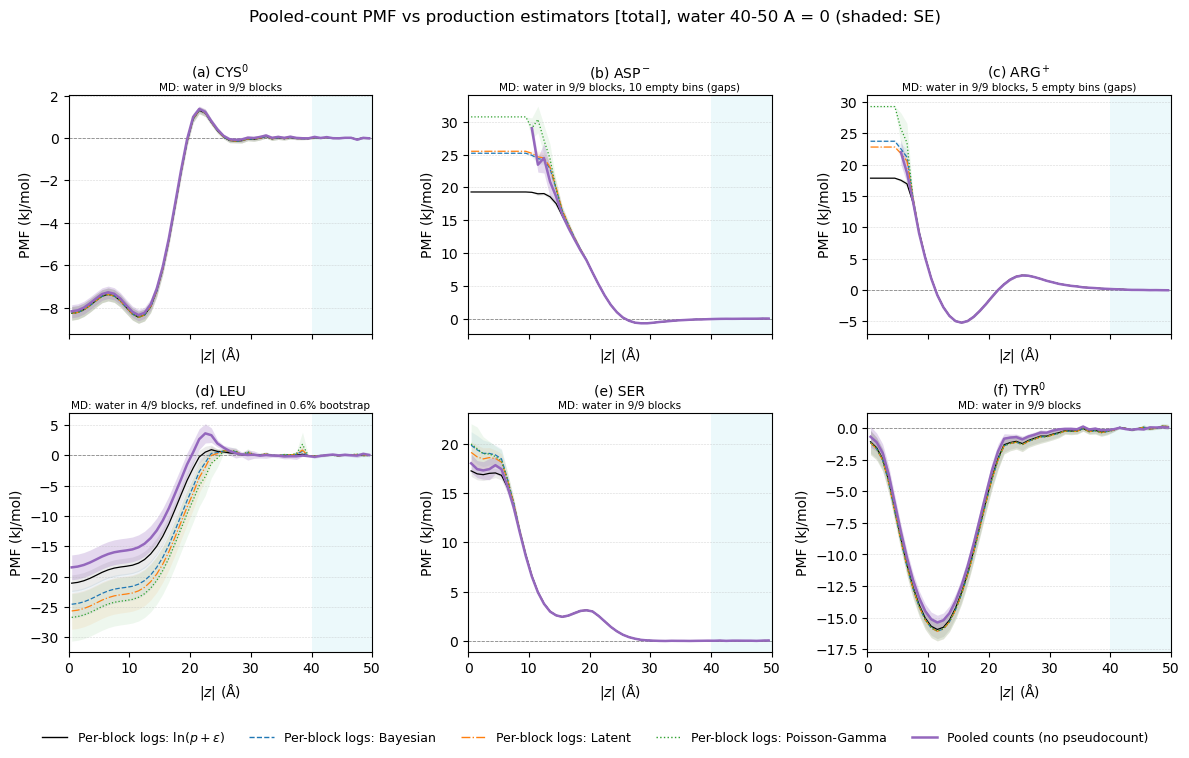

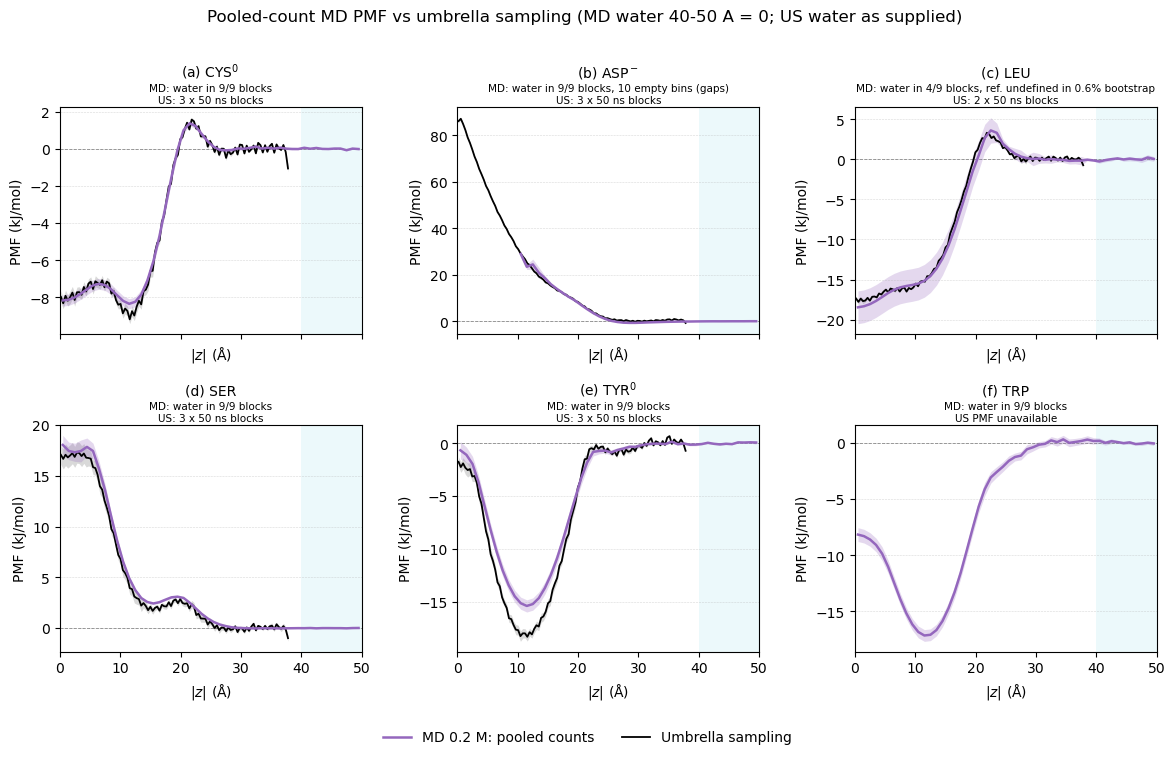

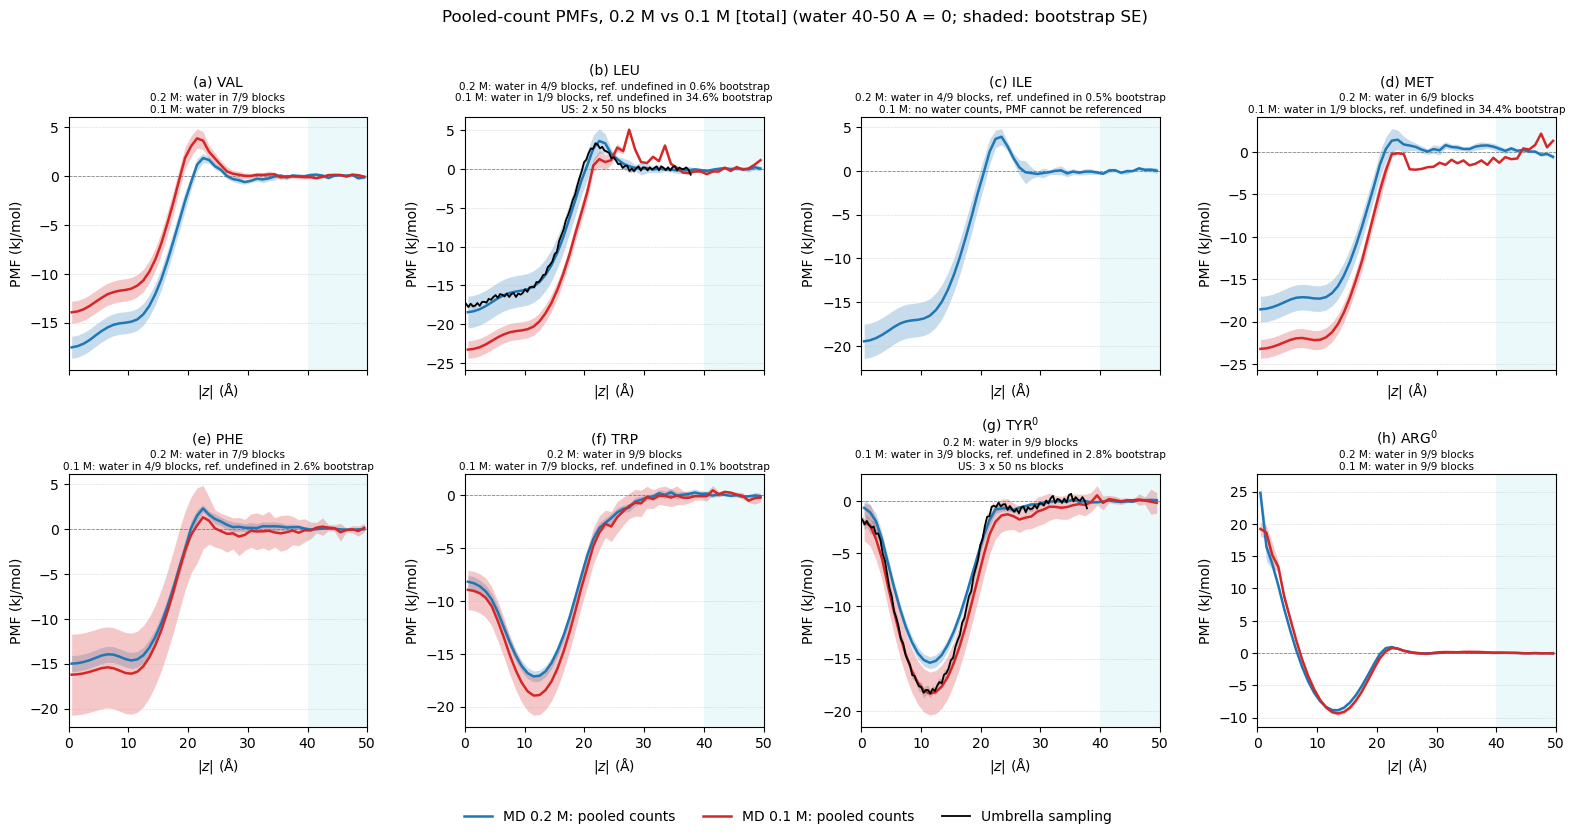

analog  blocks_with_water_counts                                         water_counts_per_block  unsampled_bins_0_50A  min_bootstrap_defined_fraction_water  pmf_min_kJ_mol  z_min_A
   scc                         9             14097 9790 7842 12528 17907 7796 14212 14639 17359                     0                                1.0000       -8.345196     11.5
   scd                         9 109837 108843 109479 110433 111476 112198 111706 110347 109655                    10                                1.0000       -0.692862     28.5
   scf                         7                            1383 474 0 256 2234 2110 892 0 3055                     0                                1.0000      -14.989919      0.5
 scf-1                         4                                        0 379 0 2659 0 0 1 34 0                     0                                0.9744      -16.223729      0.5
   sci                         4                                    222 0 0 130 0 0 1261 1107 0

In [29]:
# Pooled-count PMF: sum the counts of all 9 blocks before the log, then reference to water (independent cell).
# G(z) = -kT ln[ sum_b n_b(z) / (sum_b n_b(water) / K_water) ]; no pseudocount, zero-count blocks kept.
# SE: block bootstrap (resample the 9 blocks, recompute pooled counts and water reference each time).
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
KCAL_TO_KJ = 4.184
REF_WINDOW = (40.0, 50.0)
XLIM = (0.0, 50.0)
N_BOOT, SEED = 10000, 2025
METHOD_ANALOGS = {"scc": r"CYS$^0$", "scd": r"ASP$^-$", "scr": r"ARG$^+$",
                  "scl": "LEU", "scs": "SER", "scy": r"TYR$^0$"}
US_ANALOGS = {"scc": r"CYS$^0$", "scd": r"ASP$^-$", "scl": "LEU",
              "scs": "SER", "scy": r"TYR$^0$", "scw": "TRP"}
PAIR_ANALOGS = {"scv": "VAL", "scl": "LEU", "sci": "ILE", "scm": "MET",
                "scf": "PHE", "scw": "TRP", "scy": r"TYR$^0$", "scrn": r"ARG$^0$"}
METHODS = {  # production estimators (mean of per-block logs, water-referenced)
    "": (r"$\ln(p+\varepsilon)$", "black", "-"),
    "_bayesian": ("Bayesian", "tab:blue", "--"),
    "_latent": ("Latent", "tab:orange", "-."),
    "_poisson": ("Poisson-Gamma", "tab:green", ":"),
}
POOLED_STYLE = dict(color="tab:purple", lw=1.8)
SAVE_PREFIX = f"FigureS_PMF_pooled_counts_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


ROOT = find_repo_root()
DIST_DIR = ROOT / "figures" / "data" / "distribution_data"
METHOD_ROOT = ROOT / "supp_files" / "method_script"
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
RAW_SUMMARY = pd.read_csv(DIST_DIR / "raw_data_summary.dat", sep=r"\s+")
Z = np.arange(0.5, XLIM[1], 1.0)
WATER = (Z >= REF_WINDOW[0]) & (Z <= REF_WINDOW[1])


def block_depth(analog, traj):
    """Molecule-frames per 200 ns block (summary file, else raw contact file line count)."""
    sizes = RAW_SUMMARY.loc[(RAW_SUMMARY["residu"] == analog) & (RAW_SUMMARY["traj"] == traj), "n_lines"]
    if sizes.empty:
        with (DIST_DIR / "raw_data" / analog / f"{analog}_contacts_{traj}.dat").open("rb") as fh:
            n_lines = sum(1 for _ in fh) - 1
    else:
        n_lines = int(sizes.item())
    if n_lines % 3:
        raise ValueError(f"{analog} trajectory {traj}: {n_lines} rows not divisible into 3 blocks")
    return n_lines // 3


def folded_counts(analog):
    """Integer counts (9 blocks x 50 |z| bins, 0-50 A), +z and -z added together."""
    counts = []
    for t in (1, 2, 3):
        arr = np.loadtxt(DIST_DIR / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all() or (arr[:, 1:] < 0).any():
            raise ValueError(f"Invalid distribution file: {analog} trajectory {t}")
        keep = np.abs(arr[:, 0]) < XLIM[1]
        idx = np.searchsorted(Z, np.abs(arr[keep, 0]))
        if not np.allclose(Z[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        depth = block_depth(analog, t)
        for b in range(3):
            folded = np.zeros(len(Z))
            np.add.at(folded, idx, np.rint(arr[keep, b + 1] * depth))
            counts.append(folded)
    return np.array(counts)


def pooled_pmf(counts):
    """Water-referenced PMF from summed counts; NaN where undefined. counts: (..., n_blocks, n_z)."""
    pooled = counts.sum(axis=-2)
    water = pooled[..., WATER].mean(axis=-1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / water)
    return np.where((pooled > 0) & (water > 0), pmf, np.nan)


def pooled_result(analog):
    counts = folded_counts(analog)
    n = len(counts)
    mean = pooled_pmf(counts)
    idx = np.random.default_rng(SEED).integers(0, n, size=(N_BOOT, n))
    boot = pooled_pmf(counts[idx])
    defined = np.isfinite(boot)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # all-NaN bins are masked below
        se = np.sqrt(n / (n - 1)) * np.nanstd(boot, axis=0, ddof=1)
    water_counts = counts[:, WATER].sum(axis=1)
    return {"mean": mean, "se": np.where(defined.sum(axis=0) > 1, se, np.nan),
            "boot_defined_fraction": defined.mean(axis=0), "water_counts": water_counts,
            "n_water_blocks": int((water_counts > 0).sum()), "empty_bins": int((counts.sum(axis=0) == 0).sum())}


def read_md(suffix, analog):
    df = pd.read_csv(METHOD_ROOT / f"4-pmf_calculation{suffix}" / MODE / analog / f"pmf_{analog}.dat", sep=r"\s+")
    df = df.loc[df["z"].between(*XLIM)].reset_index(drop=True)
    if not np.allclose(df["z"], Z) or not np.isfinite(df[["mean", "se"]].to_numpy()).all():
        raise ValueError(f"Invalid production PMF: {suffix or 'epsilon'} {analog}")
    return df


def read_us(analog):
    path = US_DIR / analog / f"pmf-us-{analog}.dat"
    if not path.is_file():
        if path.parent.is_dir():
            print(f"WARNING: {analog.upper()} umbrella data exist but its PMF is unavailable: {path}")
        return None
    df = pd.read_csv(path, sep=r"\s+", comment="#", header=None, names=["z", "mean", "se", "n"])
    if (len(df) < 2 or not np.isfinite(df.to_numpy()).all() or (df["se"] < 0).any()
            or np.any(np.diff(df["z"]) <= 0) or df["n"].nunique() != 1 or df["n"].iloc[0] < 2):
        raise ValueError(f"Invalid umbrella PMF: {path}")
    df[["mean", "se"]] *= KCAL_TO_KJ
    return df


def plot_band(ax, z, mean, se, color, alpha, **line):
    ax.fill_between(z, mean - se, mean + se, color=color, alpha=alpha, lw=0)
    ax.plot(z, mean, color=color, **line)


def plot_pooled(ax, res, color=POOLED_STYLE["color"], label=None):
    se = np.nan_to_num(res["se"])
    ax.fill_between(Z, res["mean"] - se, res["mean"] + se, color=color, alpha=0.25, lw=0)
    ax.plot(Z, res["mean"], color=color, lw=POOLED_STYLE["lw"], label=label)


def finish(ax, panel, title, notes):
    ax.axhline(0, color="gray", lw=0.6, ls="--", zorder=0)
    ax.axvspan(*REF_WINDOW, color="tab:cyan", alpha=0.08, lw=0, zorder=0)
    ax.set_xlim(*XLIM)
    ax.set_title(f"({panel}) {title}", fontsize=10, pad=4 + 9 * len(notes))
    ax.text(0.5, 1.01, "\n".join(notes), transform=ax.transAxes, ha="center", va="bottom", fontsize=7.5)
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    ax.set_ylabel("PMF (kJ/mol)")
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)


def pooled_notes(name, res):
    note = f"{name}: water in {res['n_water_blocks']}/9 blocks"
    undefined = 1 - res["boot_defined_fraction"][WATER].min()
    if undefined > 0:
        note += f", ref. undefined in {100 * undefined:.1f}% bootstrap"
    if res["empty_bins"]:
        note += f", {res['empty_bins']} empty bins (gaps)"
    return [note]


def save(fig, tag):
    fig.savefig(SAVE_DIR / f"{SAVE_PREFIX}_{tag}.png", dpi=600, bbox_inches="tight")
    fig.savefig(SAVE_DIR / f"{SAVE_PREFIX}_{tag}.pdf", bbox_inches="tight")
    plt.show()


results = {}
summary_rows, pmf_rows = [], []
for analog in sorted({*METHOD_ANALOGS, *US_ANALOGS, *PAIR_ANALOGS, *(f"{a}-1" for a in PAIR_ANALOGS)}):
    res = results[analog] = pooled_result(analog)
    finite = np.isfinite(res["mean"])
    summary_rows.append({"analog": analog, "blocks_with_water_counts": res["n_water_blocks"],
                         "water_counts_per_block": " ".join(str(int(c)) for c in res["water_counts"]),
                         "unsampled_bins_0_50A": res["empty_bins"],
                         "min_bootstrap_defined_fraction_water": float(res["boot_defined_fraction"][WATER].min()),
                         "pmf_min_kJ_mol": float(np.nanmin(res["mean"])) if finite.any() else np.nan,
                         "z_min_A": float(Z[np.nanargmin(res["mean"])]) if finite.any() else np.nan})
    pmf_rows.extend({"analog": analog, "z_A": float(zi), "pmf_kJ_mol": float(m), "se_kJ_mol": float(s),
                     "bootstrap_defined_fraction": float(f)}
                    for zi, m, s, f in zip(Z, res["mean"], res["se"], res["boot_defined_fraction"]))
print("WARNING: pooled-count bootstrap SE uses only replicates in which the PMF is defined; "
      "a high undefined fraction means the water reference rests on very few escape events.")

# --- Figure 1: pooled counts vs the four production estimators ---
fig, axes = plt.subplots(2, 3, figsize=(12.0, 7.6), sharex=True)
for ax, panel, (analog, label) in zip(axes.flat, "abcdef", METHOD_ANALOGS.items()):
    for suffix, (name, color, ls) in METHODS.items():
        df = read_md(suffix, analog)
        plot_band(ax, df["z"], df["mean"], df["se"], color, 0.08, lw=0.9, ls=ls)
    plot_pooled(ax, results[analog])
    finish(ax, panel, label, pooled_notes("MD", results[analog]))
handles = [Line2D([], [], color=c, ls=ls, lw=1.0, label=f"Per-block logs: {n}") for n, c, ls in METHODS.values()]
handles.append(Line2D([], [], label="Pooled counts (no pseudocount)", **POOLED_STYLE))
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=9)
fig.suptitle(f"Pooled-count PMF vs production estimators [{MODE}], water 40-50 A = 0 (shaded: SE)")
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
save(fig, "methods")

# --- Figure 2: pooled counts vs umbrella sampling ---
fig, axes = plt.subplots(2, 3, figsize=(12.0, 7.6), sharex=True)
for ax, panel, (analog, label) in zip(axes.flat, "abcdef", US_ANALOGS.items()):
    notes = pooled_notes("MD", results[analog])
    us = read_us(analog)
    if us is None:
        notes.append("US PMF unavailable")
    else:
        plot_band(ax, us["z"], us["mean"], us["se"], "black", 0.15, lw=1.3)
        notes.append(f"US: {int(us['n'].iloc[0])} x 50 ns blocks")
    plot_pooled(ax, results[analog])
    finish(ax, panel, label, notes)
handles = [Line2D([], [], label="MD 0.2 M: pooled counts", **POOLED_STYLE),
           Line2D([], [], color="black", lw=1.3, label="Umbrella sampling")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Pooled-count MD PMF vs umbrella sampling (MD water 40-50 A = 0; US water as supplied)")
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
save(fig, "US")

# --- Figure 3: 0.2 M vs 0.1 M, pooled counts, plus US ---
fig, axes = plt.subplots(2, 4, figsize=(16.0, 8.4), sharex=True)
for ax, panel, (analog, label) in zip(axes.flat, "abcdefgh", PAIR_ANALOGS.items()):
    notes = []
    for name, conc, color in ((analog, "0.2 M", "tab:blue"), (f"{analog}-1", "0.1 M", "tab:red")):
        res = results[name]
        if res["n_water_blocks"] == 0:
            notes.append(f"{conc}: no water counts, PMF cannot be referenced")
            continue
        plot_pooled(ax, res, color=color)
        notes.extend(pooled_notes(conc, res))
    us = read_us(analog)
    if us is not None:
        plot_band(ax, us["z"], us["mean"], us["se"], "black", 0.15, lw=1.3)
        notes.append(f"US: {int(us['n'].iloc[0])} x 50 ns blocks")
    finish(ax, panel, label, notes)
handles = [Line2D([], [], color="tab:blue", lw=1.8, label="MD 0.2 M: pooled counts"),
           Line2D([], [], color="tab:red", lw=1.8, label="MD 0.1 M: pooled counts"),
           Line2D([], [], color="black", lw=1.3, label="Umbrella sampling")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
fig.suptitle(f"Pooled-count PMFs, 0.2 M vs 0.1 M [{MODE}] (water 40-50 A = 0; shaded: bootstrap SE)")
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
save(fig, "concentration_US")

summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_PREFIX}_summary.csv", index=False)
pd.DataFrame(pmf_rows).to_csv(SAVE_DIR / f"{SAVE_PREFIX}_pmfs.csv", index=False)
print(summary.to_string(index=False))

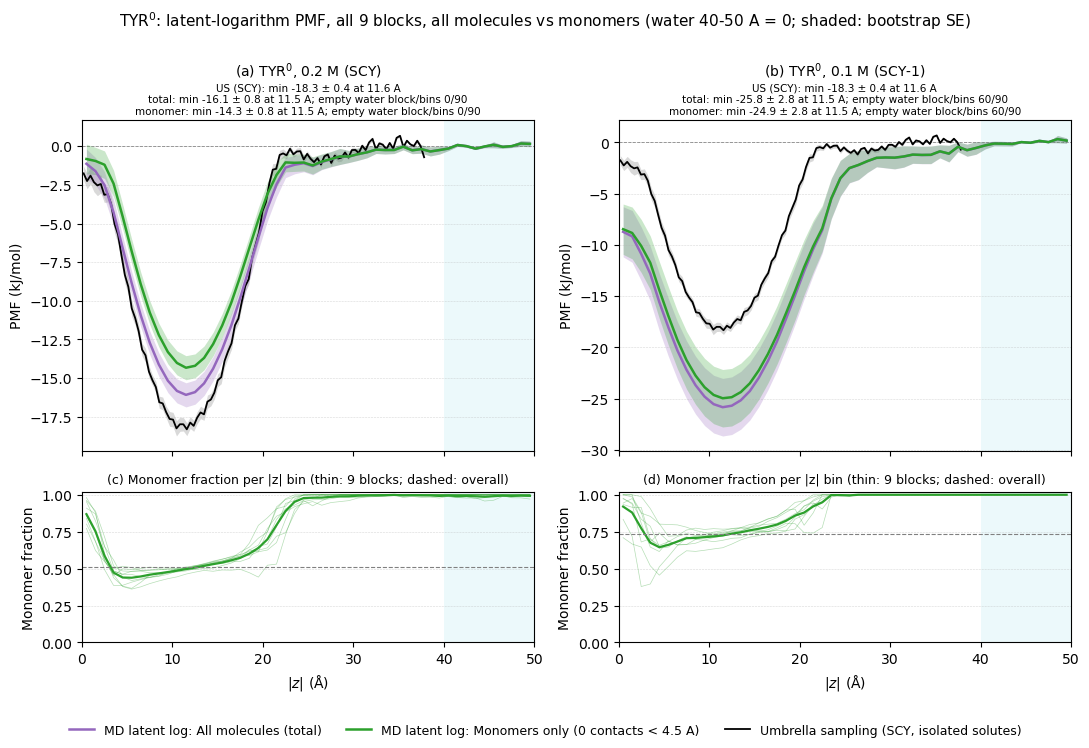

analog concentration  series  a_kJ_mol  sigma_a_kJ_mol  pmf_min_kJ_mol  se_at_min_kJ_mol  z_min_A  empty_water_block_bins
   scy         0.2 M   total 20.793414        0.769236      -16.087539          0.781168     11.5                       0
   scy         0.2 M monomer 19.097064        0.758105      -14.332415          0.778954     11.5                       0
 scy-1         0.1 M   total 30.463550        2.806545      -25.821656          2.808481     11.5                      60
 scy-1         0.1 M monomer 29.622964        2.800984      -24.948577          2.802405     11.5                      60


In [32]:
# TYR0: latent-logarithm PMF (all 9 blocks) from all molecules (total) vs monomers only (no contact < 4.5 A),
# plus US (independent cell). Replicates supp_files/method_script/4-pmf_calculation_latent/pmf-from-distribution.py:
# exact folded counts per 200 ns block, one shared latent prior over all blocks and bins (Biswas 2016),
# block-averaged PMF, water reference 40-50 A (inverse-variance weighted), block bootstrap refitting the latent log.
# Counts are rebuilt from the raw contact files so that the monomer sample size of each block is exact.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ANALOGS = {"scy": "0.2 M", "scy-1": "0.1 M"}
US_ANALOG, LABEL = "scy", r"TYR$^0$"
SERIES = {  # key: (distribution mode defining the |z| grid, legend label, color)
    "total": ("total", "All molecules (total)", "tab:purple"),
    "monomer": ("monomer_4.5A", "Monomers only (0 contacts < 4.5 A)", "tab:green"),
}
K_B, TEMPERATURE = 0.008314, 303.15
KCAL_TO_KJ = 4.184
REF_WINDOW = (40.0, 50.0)
XMAX, Z_BIN = 50.0, 1.0
LAG_TOL, LAG_MAX_ITER = 1e-8, 5000
N_BOOT, SEED, BOOT_CHUNK = 10000, 2025, 1000
SE_FLOOR = 1e-9
SAVE_NAME = "FigureS_PMF_latent_tyr_monomer_vs_total"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / "raw_data").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def native_grid(mode, analog):
    """|z| grid used by the production script: all |z| of the distribution files, extended to 50 A."""
    grid = np.unique(np.concatenate([np.abs(np.loadtxt(DIST_DIR / mode / analog / f"trajectory{t}.dat",
                                                       skiprows=1)[:, 0]) for t in (1, 2, 3)]))
    if grid[-1] < XMAX:
        grid = np.concatenate([grid, np.arange(grid[-1] + Z_BIN, XMAX + Z_BIN, Z_BIN)])
    return grid


def raw_block_counts(analog):
    """Folded counts (9 blocks x native grid) for all molecules and for monomers, from raw data."""
    grids = {key: native_grid(mode, analog) for key, (mode, _, _) in SERIES.items()}
    counts = {key: [] for key in SERIES}
    for t in (1, 2, 3):
        raw = pd.read_csv(RAW_DIR / analog / f"{analog}_contacts_{t}.dat", sep=r"\s+")
        frames = raw["#frame"].to_numpy()
        n_frames = len(np.unique(frames))
        if n_frames % 3:
            raise ValueError(f"{analog} trajectory {t}: {n_frames} frames cannot form 3 equal blocks")
        block = (frames - frames.min()) // (n_frames // 3)
        # Signed 1 A bins [n, n+1) folded onto |z| centres, as in the distribution files.
        abs_centre = np.abs(np.floor(raw["z"].to_numpy()) + 0.5)
        monomer = raw["4.5A_cutoff"].to_numpy() == 0
        for key in SERIES:
            grid = grids[key]
            idx = np.searchsorted(grid, abs_centre)
            if np.any(idx >= len(grid)) or not np.allclose(grid[np.minimum(idx, len(grid) - 1)], abs_centre):
                raise ValueError(f"{analog} trajectory {t}: raw |z| outside the {key} grid")
            selected = monomer if key == "monomer" else np.ones(len(raw), bool)
            for b in range(3):
                counts[key].append(np.bincount(idx[selected & (block == b)], minlength=len(grid)))
    return grids, {key: np.array(value, dtype=float) for key, value in counts.items()}


def _map_log_rate(t, o, mu, s2, z, tol=1e-10, max_newton=200, max_step=5.0):
    for _ in range(max_newton):
        e = o * np.exp(z)
        grad = t - e - (z - mu) / s2
        hess = -e - 1.0 / s2
        step = np.clip(grad / hess, -max_step, max_step)
        z = z - step
        if np.max(np.abs(step)) < tol:
            break
    return z


def latent_log(t, o):
    """Latent logarithm with a shared Normal prior on the last axis (iterated conditional modes)."""
    y = np.log(t / o + 1.0)
    mu = y.mean(axis=-1, keepdims=True)
    s2 = np.maximum(y.var(axis=-1, keepdims=True), 1e-6)
    z = np.broadcast_to(mu, t.shape).copy()
    for _ in range(LAG_MAX_ITER):
        z = _map_log_rate(t, o, mu, s2, z)
        mu_new, s2_new = z.mean(axis=-1, keepdims=True), z.var(axis=-1, keepdims=True)
        change = max(np.max(np.abs(mu_new - mu)), np.max(np.abs(s2_new - s2) / s2))
        mu, s2 = mu_new, s2_new
        if change < LAG_TOL:
            return z, mu, s2
    print(f"WARNING: latent logarithm not converged after {LAG_MAX_ITER} ICM iterations "
          f"(last relative change {change:.2e}).")
    return z, mu, s2


def counts_to_pmfs(counts):
    """counts: (..., n_blocks, K) -> absolute block PMFs -kT ln p from the latent log."""
    k = counts.shape[-1]
    lead = counts.shape[:-2]
    o = np.broadcast_to((counts.sum(axis=-1) / k)[..., None], counts.shape)
    z, _, _ = latent_log(counts.reshape(lead + (-1,)), o.reshape(lead + (-1,)))
    z = z.reshape(counts.shape)
    return -K_B * TEMPERATURE * (z - np.log(np.sum(np.exp(z), axis=-1, keepdims=True)))


def block_mean_se(pmfs):
    n = pmfs.shape[-2]
    return pmfs.mean(axis=-2), pmfs.std(axis=-2, ddof=1) / np.sqrt(n)


def water_reference(mean, se, mask):
    m, s = mean[..., mask], se[..., mask]
    degenerate = np.any(s <= SE_FLOOR, axis=-1, keepdims=True)
    w = np.where(degenerate, 1.0, 1.0 / np.where(s > SE_FLOOR, s, 1.0) ** 2)
    return np.sum(w * m, axis=-1) / np.sum(w, axis=-1)


def latent_pmf(grid, counts):
    win = (grid >= REF_WINDOW[0]) & (grid <= REF_WINDOW[1])
    mean_raw, se_raw = block_mean_se(counts_to_pmfs(counts))
    a_ref = float(water_reference(mean_raw, se_raw, win))
    n = len(counts)
    idx = np.random.default_rng(SEED).integers(0, n, size=(N_BOOT, n))
    boot_shifted, boot_a = np.empty((N_BOOT, len(grid))), np.empty(N_BOOT)
    for start in range(0, N_BOOT, BOOT_CHUNK):
        sl = slice(start, start + BOOT_CHUNK)
        bm, bs = block_mean_se(counts_to_pmfs(counts[idx[sl]]))
        boot_a[sl] = water_reference(bm, bs, win)
        boot_shifted[sl] = bm - boot_a[sl, None]
    corr = np.sqrt(n / (n - 1))
    return {"mean": mean_raw - a_ref, "se": corr * boot_shifted.std(axis=0, ddof=1), "a": a_ref,
            "sigma_a": float(corr * boot_a.std(ddof=1)),
            "empty_water_cells": int((counts[:, win] == 0).sum()), "water_cells": int(counts[:, win].size)}


def read_us(analog):
    path = US_DIR / analog / f"pmf-us-{analog}.dat"
    df = pd.read_csv(path, sep=r"\s+", comment="#", header=None, names=["z", "mean", "se", "n"])
    if (len(df) < 2 or not np.isfinite(df.to_numpy()).all() or (df["se"] < 0).any()
            or np.any(np.diff(df["z"]) <= 0) or df["n"].nunique() != 1 or df["n"].iloc[0] < 2):
        raise ValueError(f"Invalid umbrella PMF: {path}")
    df[["mean", "se"]] *= KCAL_TO_KJ
    return df


ROOT = find_repo_root()
DIST_DIR = ROOT / "figures" / "data" / "distribution_data"
RAW_DIR = DIST_DIR / "raw_data"
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
us = read_us(US_ANALOG)
i_us = int(us["mean"].idxmin())

summary_rows, pmf_rows = [], []
fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.5), sharex=True, gridspec_kw={"height_ratios": (2.2, 1)})
for col, (analog, conc) in enumerate(ANALOGS.items()):
    grids, counts = raw_block_counts(analog)
    ax, ax_frac = axes[0, col], axes[1, col]
    ax.fill_between(us["z"], us["mean"] - us["se"], us["mean"] + us["se"], color="black", alpha=0.15, lw=0)
    ax.plot(us["z"], us["mean"], color="black", lw=1.3)
    notes = [f"US ({US_ANALOG.upper()}): min {us['mean'].min():.1f} ± {us['se'][i_us]:.1f} at {us['z'][i_us]:.1f} A"]
    for key, (mode, name, color) in SERIES.items():
        grid, res = grids[key], latent_pmf(grids[key], counts[key])
        show = grid <= XMAX
        mean, se = res["mean"], res["se"]
        i_min = int(np.argmin(np.where(show, mean, np.inf)))
        ax.fill_between(grid[show], (mean - se)[show], (mean + se)[show], color=color, alpha=0.25, lw=0)
        ax.plot(grid[show], mean[show], color=color, lw=1.8)
        notes.append(f"{key}: min {mean[i_min]:.1f} ± {se[i_min]:.1f} at {grid[i_min]:.1f} A; "
                     f"empty water block/bins {res['empty_water_cells']}/{res['water_cells']}")
        summary_rows.append({"analog": analog, "concentration": conc, "series": key, "a_kJ_mol": res["a"],
                             "sigma_a_kJ_mol": res["sigma_a"], "pmf_min_kJ_mol": float(mean[i_min]),
                             "se_at_min_kJ_mol": float(se[i_min]), "z_min_A": float(grid[i_min]),
                             "empty_water_block_bins": res["empty_water_cells"],
                             "molecule_frames_per_block": " ".join(str(int(n)) for n in counts[key].sum(axis=1))})
        pmf_rows.extend({"analog": analog, "series": key, "z_A": float(zi), "pmf_kJ_mol": float(m),
                         "se_kJ_mol": float(s), "n_empty_blocks": int((counts[key][:, j] == 0).sum())}
                        for j, (zi, m, s) in enumerate(zip(grid, mean, se)) if zi <= XMAX)
    # Monomer fraction on the 0-50 A bins (both grids share these bin centres)
    z_frac = grids["total"][grids["total"] <= XMAX]
    tot = counts["total"][:, grids["total"] <= XMAX]
    mono = counts["monomer"][:, np.isin(grids["monomer"], z_frac)]
    with np.errstate(divide="ignore", invalid="ignore"):
        for row in np.where(tot > 0, mono / tot, np.nan):
            ax_frac.plot(z_frac, row, color="tab:green", lw=0.5, alpha=0.35)
        ax_frac.plot(z_frac, mono.sum(axis=0) / tot.sum(axis=0), color="tab:green", lw=1.6)
    ax_frac.axhline(counts["monomer"].sum() / counts["total"].sum(), color="gray", lw=0.8, ls="--")
    ax_frac.set_ylim(0, 1.02)
    ax_frac.set_ylabel("Monomer fraction")
    ax_frac.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    ax.set_title(f"({'ab'[col]}) {LABEL}, {conc} ({analog.upper()})", fontsize=10, pad=4 + 9 * len(notes))
    ax.text(0.5, 1.01, "\n".join(notes), transform=ax.transAxes, ha="center", va="bottom", fontsize=7.5)
    ax_frac.set_title(f"({'cd'[col]}) Monomer fraction per |z| bin (thin: 9 blocks; dashed: overall)", fontsize=9)
    for a in (ax, ax_frac):
        a.axvspan(*REF_WINDOW, color="tab:cyan", alpha=0.08, lw=0, zorder=0)
        a.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
        a.set_xlim(0, XMAX)
    ax.axhline(0, color="gray", lw=0.6, ls="--", zorder=0)
    ax.set_ylabel("PMF (kJ/mol)")

handles = [Line2D([], [], color=color, lw=1.8, label=f"MD latent log: {name}") for _, name, color in SERIES.values()]
handles.append(Line2D([], [], color="black", lw=1.3, label="Umbrella sampling (SCY, isolated solutes)"))
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle(r"TYR$^0$: latent-logarithm PMF, all 9 blocks, all molecules vs monomers "
             "(water 40-50 A = 0; shaded: bootstrap SE)", fontsize=11)
fig.tight_layout(rect=(0, 0.05, 1, 0.98))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()
summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(pmf_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
print(summary.drop(columns="molecule_frames_per_block").to_string(index=False))

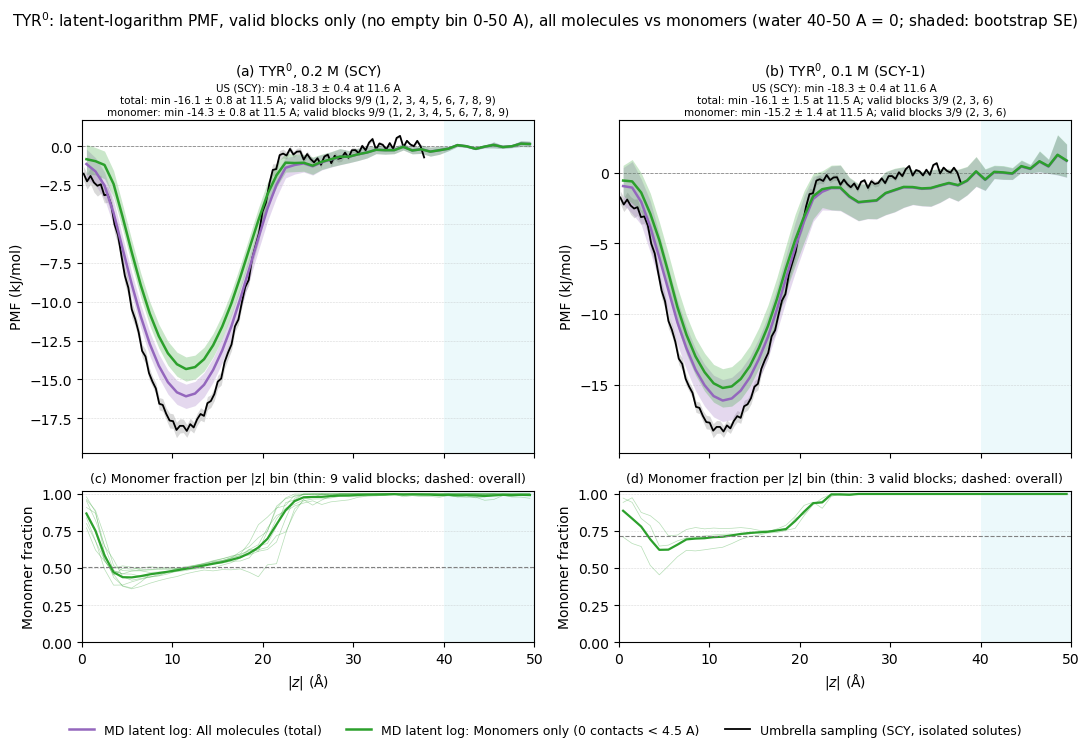

analog concentration  series  a_kJ_mol  sigma_a_kJ_mol  pmf_min_kJ_mol  se_at_min_kJ_mol  z_min_A  empty_water_block_bins  n_valid_blocks      valid_blocks
   scy         0.2 M   total 20.793414        0.769236      -16.087539          0.781168     11.5                       0               9 1 2 3 4 5 6 7 8 9
   scy         0.2 M monomer 19.097064        0.758105      -14.332415          0.778954     11.5                       0               9 1 2 3 4 5 6 7 8 9
 scy-1         0.1 M   total 20.769390        1.479946      -16.121674          1.486673     11.5                       0               3             2 3 6
 scy-1         0.1 M monomer 19.913516        1.371245      -15.230454          1.357467     11.5                       0               3             2 3 6


In [33]:
# TYR0: latent-logarithm PMF from VALID blocks only (no empty |z| bin in 0-50 A), all molecules (total) vs
# monomers only (no contact < 4.5 A), plus US (independent cell). Validity is tested on each series' own counts;
# block selection can bias the PMF (it keeps blocks in which the solute visited water).
# Same method as the all-block cell otherwise:
# plus US (independent cell). Replicates supp_files/method_script/4-pmf_calculation_latent/pmf-from-distribution.py:
# exact folded counts per 200 ns block, one shared latent prior over all blocks and bins (Biswas 2016),
# block-averaged PMF, water reference 40-50 A (inverse-variance weighted), block bootstrap refitting the latent log.
# Counts are rebuilt from the raw contact files so that the monomer sample size of each block is exact.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ANALOGS = {"scy": "0.2 M", "scy-1": "0.1 M"}
US_ANALOG, LABEL = "scy", r"TYR$^0$"
SERIES = {  # key: (distribution mode defining the |z| grid, legend label, color)
    "total": ("total", "All molecules (total)", "tab:purple"),
    "monomer": ("monomer_4.5A", "Monomers only (0 contacts < 4.5 A)", "tab:green"),
}
K_B, TEMPERATURE = 0.008314, 303.15
KCAL_TO_KJ = 4.184
REF_WINDOW = (40.0, 50.0)
XMAX, Z_BIN = 50.0, 1.0
LAG_TOL, LAG_MAX_ITER = 1e-8, 5000
N_BOOT, SEED, BOOT_CHUNK = 10000, 2025, 1000
SE_FLOOR = 1e-9
SAVE_NAME = "FigureS_PMF_latent_tyr_monomer_vs_total_valid_blocks"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / "raw_data").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def native_grid(mode, analog):
    """|z| grid used by the production script: all |z| of the distribution files, extended to 50 A."""
    grid = np.unique(np.concatenate([np.abs(np.loadtxt(DIST_DIR / mode / analog / f"trajectory{t}.dat",
                                                       skiprows=1)[:, 0]) for t in (1, 2, 3)]))
    if grid[-1] < XMAX:
        grid = np.concatenate([grid, np.arange(grid[-1] + Z_BIN, XMAX + Z_BIN, Z_BIN)])
    return grid


def raw_block_counts(analog):
    """Folded counts (9 blocks x native grid) for all molecules and for monomers, from raw data."""
    grids = {key: native_grid(mode, analog) for key, (mode, _, _) in SERIES.items()}
    counts = {key: [] for key in SERIES}
    for t in (1, 2, 3):
        raw = pd.read_csv(RAW_DIR / analog / f"{analog}_contacts_{t}.dat", sep=r"\s+")
        frames = raw["#frame"].to_numpy()
        n_frames = len(np.unique(frames))
        if n_frames % 3:
            raise ValueError(f"{analog} trajectory {t}: {n_frames} frames cannot form 3 equal blocks")
        block = (frames - frames.min()) // (n_frames // 3)
        # Signed 1 A bins [n, n+1) folded onto |z| centres, as in the distribution files.
        abs_centre = np.abs(np.floor(raw["z"].to_numpy()) + 0.5)
        monomer = raw["4.5A_cutoff"].to_numpy() == 0
        for key in SERIES:
            grid = grids[key]
            idx = np.searchsorted(grid, abs_centre)
            if np.any(idx >= len(grid)) or not np.allclose(grid[np.minimum(idx, len(grid) - 1)], abs_centre):
                raise ValueError(f"{analog} trajectory {t}: raw |z| outside the {key} grid")
            selected = monomer if key == "monomer" else np.ones(len(raw), bool)
            for b in range(3):
                counts[key].append(np.bincount(idx[selected & (block == b)], minlength=len(grid)))
    return grids, {key: np.array(value, dtype=float) for key, value in counts.items()}


def _map_log_rate(t, o, mu, s2, z, tol=1e-10, max_newton=200, max_step=5.0):
    for _ in range(max_newton):
        e = o * np.exp(z)
        grad = t - e - (z - mu) / s2
        hess = -e - 1.0 / s2
        step = np.clip(grad / hess, -max_step, max_step)
        z = z - step
        if np.max(np.abs(step)) < tol:
            break
    return z


def latent_log(t, o):
    """Latent logarithm with a shared Normal prior on the last axis (iterated conditional modes)."""
    y = np.log(t / o + 1.0)
    mu = y.mean(axis=-1, keepdims=True)
    s2 = np.maximum(y.var(axis=-1, keepdims=True), 1e-6)
    z = np.broadcast_to(mu, t.shape).copy()
    for _ in range(LAG_MAX_ITER):
        z = _map_log_rate(t, o, mu, s2, z)
        mu_new, s2_new = z.mean(axis=-1, keepdims=True), z.var(axis=-1, keepdims=True)
        change = max(np.max(np.abs(mu_new - mu)), np.max(np.abs(s2_new - s2) / s2))
        mu, s2 = mu_new, s2_new
        if change < LAG_TOL:
            return z, mu, s2
    print(f"WARNING: latent logarithm not converged after {LAG_MAX_ITER} ICM iterations "
          f"(last relative change {change:.2e}).")
    return z, mu, s2


def counts_to_pmfs(counts):
    """counts: (..., n_blocks, K) -> absolute block PMFs -kT ln p from the latent log."""
    k = counts.shape[-1]
    lead = counts.shape[:-2]
    o = np.broadcast_to((counts.sum(axis=-1) / k)[..., None], counts.shape)
    z, _, _ = latent_log(counts.reshape(lead + (-1,)), o.reshape(lead + (-1,)))
    z = z.reshape(counts.shape)
    return -K_B * TEMPERATURE * (z - np.log(np.sum(np.exp(z), axis=-1, keepdims=True)))


def block_mean_se(pmfs):
    n = pmfs.shape[-2]
    return pmfs.mean(axis=-2), pmfs.std(axis=-2, ddof=1) / np.sqrt(n)


def water_reference(mean, se, mask):
    m, s = mean[..., mask], se[..., mask]
    degenerate = np.any(s <= SE_FLOOR, axis=-1, keepdims=True)
    w = np.where(degenerate, 1.0, 1.0 / np.where(s > SE_FLOOR, s, 1.0) ** 2)
    return np.sum(w * m, axis=-1) / np.sum(w, axis=-1)


def latent_pmf(grid, counts):
    win = (grid >= REF_WINDOW[0]) & (grid <= REF_WINDOW[1])
    mean_raw, se_raw = block_mean_se(counts_to_pmfs(counts))
    a_ref = float(water_reference(mean_raw, se_raw, win))
    n = len(counts)
    idx = np.random.default_rng(SEED).integers(0, n, size=(N_BOOT, n))
    boot_shifted, boot_a = np.empty((N_BOOT, len(grid))), np.empty(N_BOOT)
    for start in range(0, N_BOOT, BOOT_CHUNK):
        sl = slice(start, start + BOOT_CHUNK)
        bm, bs = block_mean_se(counts_to_pmfs(counts[idx[sl]]))
        boot_a[sl] = water_reference(bm, bs, win)
        boot_shifted[sl] = bm - boot_a[sl, None]
    corr = np.sqrt(n / (n - 1))
    return {"mean": mean_raw - a_ref, "se": corr * boot_shifted.std(axis=0, ddof=1), "a": a_ref,
            "sigma_a": float(corr * boot_a.std(ddof=1)),
            "empty_water_cells": int((counts[:, win] == 0).sum()), "water_cells": int(counts[:, win].size)}


def read_us(analog):
    path = US_DIR / analog / f"pmf-us-{analog}.dat"
    df = pd.read_csv(path, sep=r"\s+", comment="#", header=None, names=["z", "mean", "se", "n"])
    if (len(df) < 2 or not np.isfinite(df.to_numpy()).all() or (df["se"] < 0).any()
            or np.any(np.diff(df["z"]) <= 0) or df["n"].nunique() != 1 or df["n"].iloc[0] < 2):
        raise ValueError(f"Invalid umbrella PMF: {path}")
    df[["mean", "se"]] *= KCAL_TO_KJ
    return df


ROOT = find_repo_root()
DIST_DIR = ROOT / "figures" / "data" / "distribution_data"
RAW_DIR = DIST_DIR / "raw_data"
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
us = read_us(US_ANALOG)
i_us = int(us["mean"].idxmin())

summary_rows, pmf_rows = [], []
fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.5), sharex=True, gridspec_kw={"height_ratios": (2.2, 1)})
for col, (analog, conc) in enumerate(ANALOGS.items()):
    grids, counts = raw_block_counts(analog)
    valid = {key: (counts[key][:, grids[key] <= XMAX] > 0).all(axis=1) for key in SERIES}
    for key in SERIES:
        if valid[key].sum() < 2:
            raise ValueError(f"{analog} {key}: {int(valid[key].sum())} valid block(s); at least 2 are needed for an SE")
    all_counts = counts
    counts = {key: counts[key][valid[key]] for key in SERIES}
    ax, ax_frac = axes[0, col], axes[1, col]
    ax.fill_between(us["z"], us["mean"] - us["se"], us["mean"] + us["se"], color="black", alpha=0.15, lw=0)
    ax.plot(us["z"], us["mean"], color="black", lw=1.3)
    notes = [f"US ({US_ANALOG.upper()}): min {us['mean'].min():.1f} ± {us['se'][i_us]:.1f} at {us['z'][i_us]:.1f} A"]
    for key, (mode, name, color) in SERIES.items():
        grid, res = grids[key], latent_pmf(grids[key], counts[key])
        show = grid <= XMAX
        mean, se = res["mean"], res["se"]
        i_min = int(np.argmin(np.where(show, mean, np.inf)))
        ax.fill_between(grid[show], (mean - se)[show], (mean + se)[show], color=color, alpha=0.25, lw=0)
        ax.plot(grid[show], mean[show], color=color, lw=1.8)
        notes.append(f"{key}: min {mean[i_min]:.1f} ± {se[i_min]:.1f} at {grid[i_min]:.1f} A; "
                     f"valid blocks {int(valid[key].sum())}/9 ({', '.join(str(i + 1) for i in np.flatnonzero(valid[key]))})")
        summary_rows.append({"analog": analog, "concentration": conc, "series": key, "a_kJ_mol": res["a"],
                             "sigma_a_kJ_mol": res["sigma_a"], "pmf_min_kJ_mol": float(mean[i_min]),
                             "se_at_min_kJ_mol": float(se[i_min]), "z_min_A": float(grid[i_min]),
                             "empty_water_block_bins": res["empty_water_cells"], "n_valid_blocks": int(valid[key].sum()),
                             "valid_blocks": " ".join(str(i + 1) for i in np.flatnonzero(valid[key])),
                             "molecule_frames_per_block": " ".join(str(int(n)) for n in counts[key].sum(axis=1))})
        pmf_rows.extend({"analog": analog, "series": key, "z_A": float(zi), "pmf_kJ_mol": float(m),
                         "se_kJ_mol": float(s), "n_empty_blocks": int((counts[key][:, j] == 0).sum())}
                        for j, (zi, m, s) in enumerate(zip(grid, mean, se)) if zi <= XMAX)
    # Monomer fraction on the 0-50 A bins, blocks valid for both series
    both = valid["total"] & valid["monomer"]
    z_frac = grids["total"][grids["total"] <= XMAX]
    tot = all_counts["total"][both][:, grids["total"] <= XMAX]
    mono = all_counts["monomer"][both][:, np.isin(grids["monomer"], z_frac)]
    with np.errstate(divide="ignore", invalid="ignore"):
        for row in np.where(tot > 0, mono / tot, np.nan):
            ax_frac.plot(z_frac, row, color="tab:green", lw=0.5, alpha=0.35)
        ax_frac.plot(z_frac, mono.sum(axis=0) / tot.sum(axis=0), color="tab:green", lw=1.6)
    ax_frac.axhline(mono.sum() / tot.sum(), color="gray", lw=0.8, ls="--")
    ax_frac.set_ylim(0, 1.02)
    ax_frac.set_ylabel("Monomer fraction")
    ax_frac.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    ax.set_title(f"({'ab'[col]}) {LABEL}, {conc} ({analog.upper()})", fontsize=10, pad=4 + 9 * len(notes))
    ax.text(0.5, 1.01, "\n".join(notes), transform=ax.transAxes, ha="center", va="bottom", fontsize=7.5)
    ax_frac.set_title(f"({'cd'[col]}) Monomer fraction per |z| bin (thin: {int(both.sum())} valid blocks; dashed: overall)", fontsize=9)
    for a in (ax, ax_frac):
        a.axvspan(*REF_WINDOW, color="tab:cyan", alpha=0.08, lw=0, zorder=0)
        a.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
        a.set_xlim(0, XMAX)
    ax.axhline(0, color="gray", lw=0.6, ls="--", zorder=0)
    ax.set_ylabel("PMF (kJ/mol)")

handles = [Line2D([], [], color=color, lw=1.8, label=f"MD latent log: {name}") for _, name, color in SERIES.values()]
handles.append(Line2D([], [], color="black", lw=1.3, label="Umbrella sampling (SCY, isolated solutes)"))
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle(r"TYR$^0$: latent-logarithm PMF, valid blocks only (no empty bin 0-50 A), all molecules vs monomers "
             "(water 40-50 A = 0; shaded: bootstrap SE)", fontsize=11)
fig.tight_layout(rect=(0, 0.05, 1, 0.98))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()
summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(pmf_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
print(summary.drop(columns="molecule_frames_per_block").to_string(index=False))

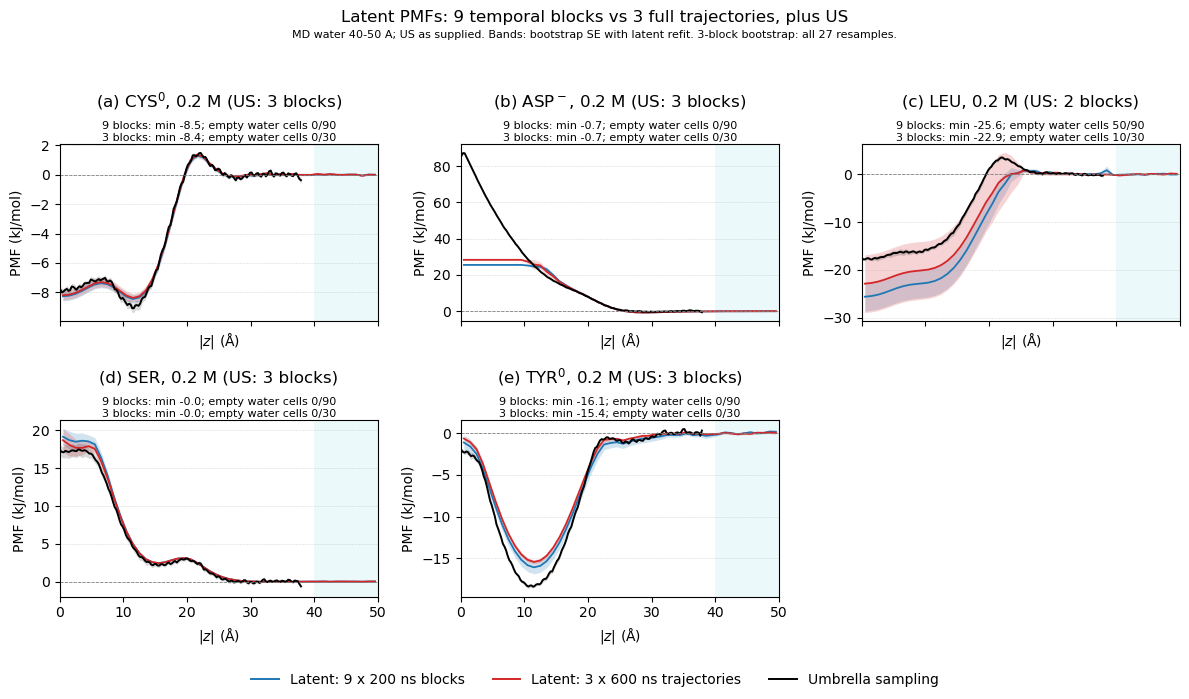

analog  n_blocks  block_ns  n_bootstrap  a_kJ_mol  sigma_a_kJ_mol  minimum_kJ_mol  se_at_min_kJ_mol  empty_water_cells
   scc         9       200        10000 15.227506        0.266293       -8.452785          0.285674                  0
   scc         3       600           27 15.150216        0.269951       -8.376216          0.300297                  0
   scd         9       200        10000  9.708676        0.009665       -0.692662          0.019877                  0
   scd         3       600           27  9.707260        0.008569       -0.691624          0.021624                  0
   scl         9       200        10000 30.629670        3.001238      -25.640661          3.006750                 50
   scl         3       600           27 27.896839        6.056000      -22.908020          6.057720                 10
   scs         9       200        10000  9.782091        0.009504       -0.030101          0.012004                  0
   scs         3       600           27  9.78178

In [47]:
# Latent logarithm: 9 x 200 ns versus 3 x 600 ns blocks, plus available US (independent cell).
# Sum each trajectory's three count histograms BEFORE the latent fit; no blocks discarded.
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

MODE = "total"
LABELS = {"scc": r"CYS$^0$", "scd": r"ASP$^-$", "scl": "LEU",
          "scs": "SER", "scy": r"TYR$^0$", "scw": "TRP"}
K_B, TEMPERATURE = 0.008314, 303.15
REF_WINDOW = (40.0, 50.0)
LAG_TOL, LAG_MAX_ITER = 1e-8, 5000
N_BOOT, SEED, BOOT_CHUNK = 10000, 2025, 1000
SE_FLOOR = 1e-9
SAVE_NAME = f"FigureS_PMF_latent_9_vs_3_blocks_US_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_counts(analog):
    arrays = [np.loadtxt(DIST_DIR / analog / f"trajectory{t}.dat", skiprows=1) for t in (1, 2, 3)]
    if any(a.ndim != 2 or a.shape[1] != 4 or not np.isfinite(a).all()
           or (a[:, 1:] < 0).any() for a in arrays):
        raise ValueError(f"Invalid distribution data for {analog}")
    z = np.unique(np.concatenate([np.abs(a[:, 0]) for a in arrays]))
    if z[-1] < 50:
        z = np.concatenate([z, np.arange(z[-1] + 1, 51, 1)])
    blocks = []
    for t, arr in enumerate(arrays, start=1):
        n_lines = int(RAW_SUMMARY.loc[(RAW_SUMMARY.residu == analog) &
                                     (RAW_SUMMARY.traj == t), "n_lines"].item())
        if n_lines <= 0 or n_lines % 3:
            raise ValueError(f"Invalid sample size: {analog} trajectory {t}")
        idx = np.searchsorted(z, np.abs(arr[:, 0]))
        for b in range(3):
            folded = np.zeros(len(z))
            np.add.at(folded, idx, np.rint(arr[:, b + 1] * (n_lines // 3)))
            blocks.append(folded)
    return z, np.array(blocks)


def _map_log_rate(t, o, mu, s2, z, tol=1e-10, max_newton=200, max_step=5.0):
    for _ in range(max_newton):
        e = o * np.exp(z)
        grad = t - e - (z - mu) / s2
        hess = -e - 1.0 / s2
        step = np.clip(grad / hess, -max_step, max_step)
        z = z - step
        if np.max(np.abs(step)) < tol:
            break
    return z


def latent_log(t, o):
    """Latent logarithm with a shared Normal prior on the last axis (iterated conditional modes)."""
    y = np.log(t / o + 1.0)
    mu = y.mean(axis=-1, keepdims=True)
    s2 = np.maximum(y.var(axis=-1, keepdims=True), 1e-6)
    z = np.broadcast_to(mu, t.shape).copy()
    for _ in range(LAG_MAX_ITER):
        z = _map_log_rate(t, o, mu, s2, z)
        mu_new, s2_new = z.mean(axis=-1, keepdims=True), z.var(axis=-1, keepdims=True)
        change = max(np.max(np.abs(mu_new - mu)), np.max(np.abs(s2_new - s2) / s2))
        mu, s2 = mu_new, s2_new
        if change < LAG_TOL:
            return z, mu, s2
    print(f"WARNING: latent logarithm not converged after {LAG_MAX_ITER} ICM iterations "
          f"(last relative change {change:.2e}).")
    return z, mu, s2


def counts_to_pmfs(counts):
    """counts: (..., n_blocks, K) -> absolute block PMFs -kT ln p from the latent log."""
    k = counts.shape[-1]
    lead = counts.shape[:-2]
    o = np.broadcast_to((counts.sum(axis=-1) / k)[..., None], counts.shape)
    z, _, _ = latent_log(counts.reshape(lead + (-1,)), o.reshape(lead + (-1,)))
    z = z.reshape(counts.shape)
    return -K_B * TEMPERATURE * (z - np.log(np.sum(np.exp(z), axis=-1, keepdims=True)))


def block_mean_se(pmfs):
    n = pmfs.shape[-2]
    return pmfs.mean(axis=-2), pmfs.std(axis=-2, ddof=1) / np.sqrt(n)


def water_reference(mean, se, mask):
    m, s = mean[..., mask], se[..., mask]
    degenerate = np.any(s <= SE_FLOOR, axis=-1, keepdims=True)
    w = np.where(degenerate, 1.0, 1.0 / np.where(s > SE_FLOOR, s, 1.0) ** 2)
    return np.sum(w * m, axis=-1) / np.sum(w, axis=-1)


def latent_pmf(grid, counts):
    win = (grid >= REF_WINDOW[0]) & (grid <= REF_WINDOW[1])
    mean_raw, se_raw = block_mean_se(counts_to_pmfs(counts))
    a_ref = float(water_reference(mean_raw, se_raw, win))
    n = len(counts)
    if n == 3:
        idx = np.array(list(product(range(n), repeat=n)))
    else:
        idx = np.random.default_rng(SEED).integers(0, n, size=(N_BOOT, n))
    n_boot = len(idx)
    boot_shifted, boot_a = np.empty((n_boot, len(grid))), np.empty(n_boot)
    for start in range(0, n_boot, BOOT_CHUNK):
        sl = slice(start, start + BOOT_CHUNK)
        bm, bs = block_mean_se(counts_to_pmfs(counts[idx[sl]]))
        boot_a[sl] = water_reference(bm, bs, win)
        boot_shifted[sl] = bm - boot_a[sl, None]
    corr = np.sqrt(n / (n - 1))
    return {"mean": mean_raw - a_ref, "se": corr * boot_shifted.std(axis=0, ddof=0 if n == 3 else 1), "a": a_ref,
            "sigma_a": float(corr * boot_a.std(ddof=0 if n == 3 else 1)),
            "empty_water_cells": int((counts[:, win] == 0).sum()), "water_cells": int(counts[:, win].size)}



ROOT = find_repo_root()
DIST_DIR = ROOT / "figures" / "data" / "distribution_data" / MODE
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
RAW_SUMMARY = pd.read_csv(DIST_DIR.parent / "raw_data_summary.dat", sep=r"\s+")
US_PATHS = sorted(p for p in US_DIR.glob("*/pmf-us-*.dat") if not p.stem.endswith("-untranslated"))
if not US_PATHS:
    raise FileNotFoundError(f"No completed umbrella PMFs in {US_DIR}")
n_cols = 3
n_rows = (len(US_PATHS) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3.5 * n_rows), sharex=True, squeeze=False)
summary_rows, pmf_rows, computed = [], [], {}
for panel, (ax, us_path) in enumerate(zip(axes.flat, US_PATHS)):
    analog = us_path.parent.name
    z, counts9 = read_counts(analog)
    counts3 = counts9.reshape(3, 3, len(z)).sum(axis=1)
    np.testing.assert_array_equal(counts9.sum(axis=0), counts3.sum(axis=0))
    show = (z >= 0) & (z <= 50)
    notes = []
    for n, counts, color in ((9, counts9, "tab:blue"), (3, counts3, "tab:red")):
        result = latent_pmf(z, counts)
        computed[(analog, n)] = (z, counts, result)
        mean, se = result["mean"], result["se"]
        if not np.isfinite(mean).all() or not np.isfinite(se).all():
            raise ValueError(f"Non-finite latent PMF or SE: {analog}, {n} blocks")
        ax.plot(z[show], mean[show], color=color, lw=1.3)
        ax.fill_between(z[show], (mean-se)[show], (mean+se)[show], color=color, alpha=0.2, lw=0)
        i = np.flatnonzero(show)[np.argmin(mean[show])]
        notes.append(f"{n} blocks: min {mean[i]:.1f}; empty water cells "
                     f"{result['empty_water_cells']}/{result['water_cells']}")
        if result["empty_water_cells"]:
            print(f"WARNING: {analog}, {n} blocks: empty water cells are latent-model estimates.")
        summary_rows.append({"analog": analog, "n_blocks": n, "block_ns": 1800 // n,
                             "n_bootstrap": N_BOOT if n == 9 else 27,
                             "a_kJ_mol": result["a"], "sigma_a_kJ_mol": result["sigma_a"],
                             "minimum_kJ_mol": float(mean[i]), "se_at_min_kJ_mol": float(se[i]),
                             "empty_water_cells": result["empty_water_cells"]})
        pmf_rows.extend({"analog": analog, "series": f"latent_{n}_blocks", "z_A": float(zi),
                         "mean": float(mi), "se": float(si)}
                        for zi, mi, si in zip(z[show], mean[show], se[show]))
    us = pd.read_csv(us_path, sep=r"\s+", comment="#", header=None, names=["z", "mean", "se", "n"])
    if (len(us) < 2 or not np.isfinite(us.to_numpy()).all() or (us.se < 0).any()
            or np.any(np.diff(us.z) <= 0)):
        raise ValueError(f"Invalid umbrella PMF: {us_path}")
    us[["mean", "se"]] *= 4.184
    ax.plot(us.z, us["mean"], color="black", lw=1.4)
    ax.fill_between(us.z, us["mean"]-us.se, us["mean"]+us.se, color="black", alpha=0.15, lw=0)
    pmf_rows.extend({"analog": analog, "series": "US", "z_A": float(row.z),
                     "mean": float(row.mean), "se": float(row.se)}
                    for row in us.itertuples(index=False))
    ax.set_title(f"({chr(97+panel)}) {LABELS.get(analog, analog.upper())}, 0.2 M "
                 f"(US: {int(us.n.iloc[0])} blocks)", pad=27)
    ax.text(0.5, 1.01, "\n".join(notes), transform=ax.transAxes, ha="center", va="bottom", fontsize=8)
    ax.axhline(0, color="gray", lw=0.6, ls="--")
    ax.axvspan(*REF_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    ax.set_xlim(0, 50)
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    ax.set_ylabel("PMF (kJ/mol)")
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
for ax in list(axes.flat)[len(US_PATHS):]:
    ax.set_visible(False)
handles = [Line2D([], [], color=c, lw=1.4, label=l) for c, l in
           (("tab:blue", "Latent: 9 x 200 ns blocks"), ("tab:red", "Latent: 3 x 600 ns trajectories"),
            ("black", "Umbrella sampling"))]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Latent PMFs: 9 temporal blocks vs 3 full trajectories, plus US")
fig.text(0.5, 0.94, "MD water 40-50 A; US as supplied. Bands: bootstrap SE with latent refit. "
         "3-block bootstrap: all 27 resamples.", ha="center", fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 0.93))
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.png", dpi=600, bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{SAVE_NAME}.pdf", bbox_inches="tight")
plt.show()
summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(pmf_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
print(summary.to_string(index=False))
print("WARNING: three trajectories provide only three independent replicates; "
      "bootstrap bands are not a convergence guarantee.")


In [ ]:
# SCL (LEU), 0.2 M: five MD estimators versus US, membrane and water references (independent cell).
# Membrane bands retain untranslated SE under a fixed shift; minimum uncertainty is not propagated.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOG, MODE = "scl", "total"
MEMBRANE_WINDOW = (0.0, 20.0)
XLIM = (0.0, 50.0)
KCAL_TO_KJ = 4.184
METHODS = {
    "": (r"Pseudocount ($\varepsilon=10^{-5}$)", "tab:gray", "-"),
    "_poisson": ("Poisson-Gamma", "tab:green", ":"),
    "_bayesian": ("Bayesian (Dirichlet)", "tab:blue", "--"),
    "_latent": ("Latent logarithm", "tab:orange", "-."),
    "_counting": ("Pooled counts", "tab:red", (0, (5, 2))),
}
SAVE_NAME = f"FigureS_PMF_scl_methods_US_{MODE}"
FONT_SCALE = 1.8  # enlarge all text for print (see enlarge_fonts_and_layout)


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "supp_files" / "method_script" / "4-pmf_calculation").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_profile(path, umbrella=False):
    if umbrella:
        df = pd.read_csv(path, sep=r"\s+", comment="#", header=None,
                         names=["z", "mean", "se", "n_blocks"])
        df[["mean", "se"]] *= KCAL_TO_KJ
    else:
        df = pd.read_csv(path, sep=r"\s+")
    if not {"z", "mean", "se"}.issubset(df.columns):
        raise ValueError(f"Missing PMF columns: {path}")
    z = df["z"].to_numpy()
    if len(z) < 2 or not np.isfinite(z).all() or np.any(np.diff(z) <= 0):
        raise ValueError(f"Invalid z grid: {path}")
    values = df[["mean", "se"]].to_numpy()
    if np.isinf(values).any() or np.any(df["se"].dropna() < 0):
        raise ValueError(f"Invalid PMF or SE: {path}")
    finite_mean, finite_se = np.isfinite(df["mean"]), np.isfinite(df["se"])
    if not np.array_equal(finite_mean, finite_se):
        raise ValueError(f"Inconsistent undefined mean/SE bins: {path}")
    df = df.loc[df["z"].between(*XLIM)].copy()
    if np.isfinite(df["mean"]).sum() < 2:
        raise ValueError(f"Insufficient defined PMF bins in plot range: {path}")
    if df["mean"].isna().any():
        print(f"WARNING: {path.name}: {df['mean'].isna().sum()} undefined bins shown as gaps.")
    return df



def _split_outside_math(text):
    """Split on spaces that are not inside $...$ (mathtext must not be broken)."""
    words, current, in_math = [], "", False
    for char in text:
        if char == "$":
            in_math = not in_math
        if char == " " and not in_math:
            words.append(current)
            current = ""
        else:
            current += char
    words.append(current)
    return [w for w in words if w]


def _wrap_text(artist, max_px, renderer):
    """Greedy re-wrap of a Text artist so that no line is longer than max_px."""
    def length(candidate):
        artist.set_text(candidate)
        box = artist.get_window_extent(renderer)
        return box.height if abs(artist.get_rotation() % 180 - 90) < 1 else box.width
    original = artist.get_text()
    if not original.strip() or length(original) <= max_px:
        artist.set_text(original)
        return
    out = []
    for paragraph in original.split("\n"):
        indent = paragraph[:len(paragraph) - len(paragraph.lstrip(" "))]
        words = _split_outside_math(paragraph)
        if not words:
            out.append(paragraph)
            continue
        line = indent + words[0]
        for word in words[1:]:
            if length(f"{line} {word}") > max_px:
                out.append(line)
                line = indent + word
            else:
                line = f"{line} {word}"
        out.append(line)
    artist.set_text("\n".join(out))


def enlarge_fonts_and_layout(fig, factor, margin=0.01):
    """Scale every text of fig by factor, wrap titles/labels/notes that no longer fit, and lay out
    the axes between the footnotes and the suptitle."""
    from matplotlib.text import Text
    tick_sizes = {}
    for ax in fig.axes:
        for name, axis in (("x", ax.xaxis), ("y", ax.yaxis)):
            ticks = axis.get_major_ticks()
            if ticks:
                tick_sizes[ax, name] = ticks[0].label1.get_fontsize()
    seen = set()
    for artist in fig.findobj(Text):
        if id(artist) not in seen:
            seen.add(id(artist))
            artist.set_fontsize(artist.get_fontsize() * factor)
    for (ax, name), size in tick_sizes.items():
        ax.tick_params(axis=name, labelsize=size * factor)

    def rect():
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        to_fig = fig.transFigure.inverted()
        suptitle = getattr(fig, "_suptitle", None)
        bottom, top = 0.0, 1.0
        for text in fig.texts:
            if text.get_text().strip():
                box = text.get_window_extent(renderer).transformed(to_fig)
                if text is suptitle:
                    top = min(top, box.y0 - margin)
                else:
                    bottom = max(bottom, box.y1 + margin)
        # Figure legends sit directly above the footnotes, the axes above both.
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, bottom), transform=fig.transFigure)
        if fig.legends:
            fig.canvas.draw()
            bottom = max(legend.get_window_extent(renderer).transformed(to_fig).y1
                         for legend in fig.legends) + margin
        return (0, bottom, 1, top)

    fig.tight_layout(rect=rect())
    renderer = fig.canvas.get_renderer()
    fig_width = fig.bbox.width
    for text in fig.texts:
        _wrap_text(text, 0.98 * fig_width, renderer)
    for ax in fig.axes:
        box = ax.get_window_extent(renderer)
        _wrap_text(ax.title, 1.0 * box.width, renderer)
        _wrap_text(ax.xaxis.label, 1.0 * box.width, renderer)
        _wrap_text(ax.yaxis.label, 1.0 * box.height, renderer)
        for text in ax.texts:
            if text.get_transform() == ax.transAxes:
                x = text.get_position()[0]
                space = {"left": 1 - x, "right": x, "center": 2 * min(x, 1 - x)}[text.get_ha()]
                _wrap_text(text, 0.97 * space * box.width, renderer)
    fig.tight_layout(rect=rect())


ROOT = find_repo_root()
METHOD_ROOT = ROOT / "supp_files" / "method_script"
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf" / ANALOG
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
curves, summary_rows, figures = [], [], {}
for reference in ("membrane", "water"):
    suffix = "_untranslated" if reference == "membrane" else ""
    sources = [
        (name, color, style, METHOD_ROOT / f"4-pmf_calculation{method}" / MODE /
         ANALOG / f"pmf_{ANALOG}{suffix}.dat", False)
        for method, (name, color, style) in METHODS.items()
    ]
    sources.append(("Umbrella sampling", "black", "-", US_DIR /
                    f"pmf-us-{ANALOG}{'-untranslated' if suffix else ''}.dat", True))
    fig, ax = plt.subplots(figsize=(8.5, 8.5))
    figures[reference] = fig
    for name, color, style, path, umbrella in sources:
        df = read_profile(path, umbrella)
        shift, anchor_z = 0.0, np.nan
        if reference == "membrane":
            membrane = df.loc[df["z"].between(*MEMBRANE_WINDOW) & np.isfinite(df["mean"])]
            if membrane.empty:
                raise ValueError(f"No defined bins for membrane reference: {path}")
            anchor = membrane.loc[membrane["mean"].idxmin()]
            shift, anchor_z = float(anchor["mean"]), float(anchor["z"])
            df["mean"] -= shift
        label = name + (f" ({int(df['n_blocks'].iloc[0])} blocks)" if umbrella else "")
        ax.plot(df["z"], df["mean"], color=color, ls=style,
                lw=1.7 if umbrella else 1.2, label=label, zorder=4 if umbrella else 3)
        ax.fill_between(df["z"], df["mean"] - df["se"], df["mean"] + df["se"],
                        color=color, alpha=0.12, lw=0, zorder=1)
        finite = df.loc[np.isfinite(df["mean"])]
        well = finite.loc[finite["mean"].idxmin()]
        defined = float(df["boot_defined"].min()) if "boot_defined" in df else np.nan
        if np.isfinite(defined) and defined < 1:
            print(f"WARNING: {name}: minimum defined-bootstrap fraction = {defined:.4f}; "
                  "pooled-count water SE is conditional on defined resamples.")
        summary_rows.append({
            "reference": reference, "method": name, "source": str(path),
            "subtracted_shift_kJ_mol": shift, "membrane_anchor_z_A": anchor_z,
            "minimum_z_A": float(well["z"]), "minimum_kJ_mol": float(well["mean"]),
            "se_at_minimum_kJ_mol": float(well["se"]),
            "min_boot_defined": defined,
            "uncertainty": ("untranslated SE; fixed minimum shift, anchor uncertainty not propagated"
                            if reference == "membrane" else "supplied water-referenced SE"),
        })
        for row in df.itertuples(index=False):
            curves.append({"reference": reference, "method": name, "z_A": float(row.z),
                           "mean_kJ_mol": float(row.mean), "se_kJ_mol": float(row.se)})
    ax.axhline(0, color="gray", lw=0.7, ls="--")
    if reference == "membrane":
        ax.axvspan(*MEMBRANE_WINDOW, color="0.8", alpha=0.15, lw=0)
        title = "membrane reference"
        note = ("Bands: untranslated SE under a fixed shift.\n"
                "Uncertainty of the estimated minimum is not propagated.")
    else:
        ax.axvspan(40, 50, color="tab:cyan", alpha=0.08, lw=0)
        title = "water reference"
        note = ("MD: 40-50 A reference; US: each folded block zeroed at |z| >= 30 A.\n"
                "Bands: supplied SE; pooled-count SE excludes undefined bootstrap resamples.")
    ax.set(title=f"SCL (LEU), 0.2 M [{MODE}]: {title}",
           xlabel=r"$|z|$ ($\mathrm{\AA}$)", ylabel="PMF (kJ/mol)", xlim=XLIM)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
    fig.legend(*ax.get_legend_handles_labels(), loc="lower center", fontsize=9, frameon=False, ncol=2)
    print(f"Caption note ({reference} reference): " + " ".join(note.split()))
    enlarge_fonts_and_layout(fig, FONT_SCALE)
    for extension in ("png", "pdf"):
        fig.savefig(SAVE_DIR / f"{SAVE_NAME}_{reference}.{extension}", dpi=600, bbox_inches="tight")
    plt.show()

summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(curves).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
print(summary[["reference", "method", "minimum_kJ_mol", "se_at_minimum_kJ_mol"]].to_string(index=False))


In [ ]:
# SCL (LEU), 0.1 M: five MD estimators versus US, membrane and water references (independent cell).
# Membrane bands retain untranslated SE under a fixed shift; minimum uncertainty is not propagated.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOG, US_ANALOG, MODE = "scl-1", "scl", "total"
MEMBRANE_WINDOW = (0.0, 20.0)
XLIM = (0.0, 50.0)
KCAL_TO_KJ = 4.184
METHODS = {
    "": (r"Pseudocount ($\varepsilon=10^{-5}$)", "tab:gray", "-"),
    "_poisson": ("Poisson-Gamma", "tab:green", ":"),
    "_bayesian": ("Bayesian (Dirichlet)", "tab:blue", "--"),
    "_latent": ("Latent logarithm", "tab:orange", "-."),
    "_counting": ("Pooled counts", "tab:red", (0, (5, 2))),
}
SAVE_NAME = f"FigureS_PMF_scl_01M_methods_US_{MODE}"
FONT_SCALE = 1.8  # enlarge all text for print (see enlarge_fonts_and_layout)


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "supp_files" / "method_script" / "4-pmf_calculation").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_profile(path, umbrella=False):
    if umbrella:
        df = pd.read_csv(path, sep=r"\s+", comment="#", header=None,
                         names=["z", "mean", "se", "n_blocks"])
        df[["mean", "se"]] *= KCAL_TO_KJ
    else:
        df = pd.read_csv(path, sep=r"\s+")
    if not {"z", "mean", "se"}.issubset(df.columns):
        raise ValueError(f"Missing PMF columns: {path}")
    z = df["z"].to_numpy()
    if len(z) < 2 or not np.isfinite(z).all() or np.any(np.diff(z) <= 0):
        raise ValueError(f"Invalid z grid: {path}")
    values = df[["mean", "se"]].to_numpy()
    if np.isinf(values).any() or np.any(df["se"].dropna() < 0):
        raise ValueError(f"Invalid PMF or SE: {path}")
    finite_mean, finite_se = np.isfinite(df["mean"]), np.isfinite(df["se"])
    if not np.array_equal(finite_mean, finite_se):
        raise ValueError(f"Inconsistent undefined mean/SE bins: {path}")
    df = df.loc[df["z"].between(*XLIM)].copy()
    if np.isfinite(df["mean"]).sum() < 2:
        raise ValueError(f"Insufficient defined PMF bins in plot range: {path}")
    if df["mean"].isna().any():
        print(f"WARNING: {path.name}: {df['mean'].isna().sum()} undefined bins shown as gaps.")
    return df



def _split_outside_math(text):
    """Split on spaces that are not inside $...$ (mathtext must not be broken)."""
    words, current, in_math = [], "", False
    for char in text:
        if char == "$":
            in_math = not in_math
        if char == " " and not in_math:
            words.append(current)
            current = ""
        else:
            current += char
    words.append(current)
    return [w for w in words if w]


def _wrap_text(artist, max_px, renderer):
    """Greedy re-wrap of a Text artist so that no line is longer than max_px."""
    def length(candidate):
        artist.set_text(candidate)
        box = artist.get_window_extent(renderer)
        return box.height if abs(artist.get_rotation() % 180 - 90) < 1 else box.width
    original = artist.get_text()
    if not original.strip() or length(original) <= max_px:
        artist.set_text(original)
        return
    out = []
    for paragraph in original.split("\n"):
        indent = paragraph[:len(paragraph) - len(paragraph.lstrip(" "))]
        words = _split_outside_math(paragraph)
        if not words:
            out.append(paragraph)
            continue
        line = indent + words[0]
        for word in words[1:]:
            if length(f"{line} {word}") > max_px:
                out.append(line)
                line = indent + word
            else:
                line = f"{line} {word}"
        out.append(line)
    artist.set_text("\n".join(out))


def enlarge_fonts_and_layout(fig, factor, margin=0.01):
    """Scale every text of fig by factor, wrap titles/labels/notes that no longer fit, and lay out
    the axes between the footnotes and the suptitle."""
    from matplotlib.text import Text
    tick_sizes = {}
    for ax in fig.axes:
        for name, axis in (("x", ax.xaxis), ("y", ax.yaxis)):
            ticks = axis.get_major_ticks()
            if ticks:
                tick_sizes[ax, name] = ticks[0].label1.get_fontsize()
    seen = set()
    for artist in fig.findobj(Text):
        if id(artist) not in seen:
            seen.add(id(artist))
            artist.set_fontsize(artist.get_fontsize() * factor)
    for (ax, name), size in tick_sizes.items():
        ax.tick_params(axis=name, labelsize=size * factor)

    def rect():
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        to_fig = fig.transFigure.inverted()
        suptitle = getattr(fig, "_suptitle", None)
        bottom, top = 0.0, 1.0
        for text in fig.texts:
            if text.get_text().strip():
                box = text.get_window_extent(renderer).transformed(to_fig)
                if text is suptitle:
                    top = min(top, box.y0 - margin)
                else:
                    bottom = max(bottom, box.y1 + margin)
        # Figure legends sit directly above the footnotes, the axes above both.
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, bottom), transform=fig.transFigure)
        if fig.legends:
            fig.canvas.draw()
            bottom = max(legend.get_window_extent(renderer).transformed(to_fig).y1
                         for legend in fig.legends) + margin
        return (0, bottom, 1, top)

    fig.tight_layout(rect=rect())
    renderer = fig.canvas.get_renderer()
    fig_width = fig.bbox.width
    for text in fig.texts:
        _wrap_text(text, 0.98 * fig_width, renderer)
    for ax in fig.axes:
        box = ax.get_window_extent(renderer)
        _wrap_text(ax.title, 1.0 * box.width, renderer)
        _wrap_text(ax.xaxis.label, 1.0 * box.width, renderer)
        _wrap_text(ax.yaxis.label, 1.0 * box.height, renderer)
        for text in ax.texts:
            if text.get_transform() == ax.transAxes:
                x = text.get_position()[0]
                space = {"left": 1 - x, "right": x, "center": 2 * min(x, 1 - x)}[text.get_ha()]
                _wrap_text(text, 0.97 * space * box.width, renderer)
    fig.tight_layout(rect=rect())


ROOT = find_repo_root()
METHOD_ROOT = ROOT / "supp_files" / "method_script"
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf" / US_ANALOG
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
curves, summary_rows, figures = [], [], {}
for reference in ("membrane", "water"):
    suffix = "_untranslated" if reference == "membrane" else ""
    sources = [
        (name, color, style, METHOD_ROOT / f"4-pmf_calculation{method}" / MODE /
         ANALOG / f"pmf_{ANALOG}{suffix}.dat", False)
        for method, (name, color, style) in METHODS.items()
    ]
    sources.append(("Umbrella sampling", "black", "-", US_DIR /
                    f"pmf-us-{US_ANALOG}{'-untranslated' if suffix else ''}.dat", True))
    fig, ax = plt.subplots(figsize=(8.5, 8.5))
    figures[reference] = fig
    pooled_defined = None
    for name, color, style, path, umbrella in sources:
        df = read_profile(path, umbrella)
        shift, anchor_z = 0.0, np.nan
        if reference == "membrane":
            membrane = df.loc[df["z"].between(*MEMBRANE_WINDOW) & np.isfinite(df["mean"])]
            if membrane.empty:
                raise ValueError(f"No defined bins for membrane reference: {path}")
            anchor = membrane.loc[membrane["mean"].idxmin()]
            shift, anchor_z = float(anchor["mean"]), float(anchor["z"])
            df["mean"] -= shift
        label = name + (f" ({int(df['n_blocks'].iloc[0])} blocks)" if umbrella else "")
        ax.plot(df["z"], df["mean"], color=color, ls=style,
                lw=1.7 if umbrella else 1.2, label=label, zorder=4 if umbrella else 3)
        ax.fill_between(df["z"], df["mean"] - df["se"], df["mean"] + df["se"],
                        color=color, alpha=0.12, lw=0, zorder=1)
        finite = df.loc[np.isfinite(df["mean"])]
        well = finite.loc[finite["mean"].idxmin()]
        defined = float(df["boot_defined"].min()) if "boot_defined" in df else np.nan
        if "boot_defined" in df:
            pooled_defined = defined
        if np.isfinite(defined) and defined < 1:
            print(f"WARNING: {name}: minimum defined-bootstrap fraction = {defined:.4f}; "
                  "pooled-count water SE is conditional on defined resamples.")
        summary_rows.append({
            "reference": reference, "method": name, "source": str(path),
            "md_analog": ANALOG, "md_concentration_M": 0.1, "us_analog": US_ANALOG,
            "subtracted_shift_kJ_mol": shift, "membrane_anchor_z_A": anchor_z,
            "minimum_z_A": float(well["z"]), "minimum_kJ_mol": float(well["mean"]),
            "se_at_minimum_kJ_mol": float(well["se"]),
            "min_boot_defined": defined,
            "uncertainty": ("untranslated SE; fixed minimum shift, anchor uncertainty not propagated"
                            if reference == "membrane" else "supplied water-referenced SE"),
        })
        for row in df.itertuples(index=False):
            curves.append({"reference": reference, "method": name, "z_A": float(row.z),
                           "mean_kJ_mol": float(row.mean), "se_kJ_mol": float(row.se)})
    ax.axhline(0, color="gray", lw=0.7, ls="--")
    if reference == "membrane":
        ax.axvspan(*MEMBRANE_WINDOW, color="0.8", alpha=0.15, lw=0)
        title = "membrane reference"
        note = ("Bands: untranslated SE under a fixed shift.\n"
                "Uncertainty of the estimated minimum is not propagated.")
    else:
        ax.axvspan(40, 50, color="tab:cyan", alpha=0.08, lw=0)
        title = "water reference"
        note = ("MD: 40-50 A reference; US: each folded block zeroed at |z| >= 30 A.\n"
                "Bands: supplied SE; pooled-count SE excludes undefined bootstrap resamples.")
        if pooled_defined is not None:
            note += f" Minimum defined-bootstrap fraction: {100*pooled_defined:.1f}%."
    ax.set(title=f"SCL (LEU), 0.1 M [{MODE}]: {title}",
           xlabel=r"$|z|$ ($\mathrm{\AA}$)", ylabel="PMF (kJ/mol)", xlim=XLIM)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
    fig.legend(*ax.get_legend_handles_labels(), loc="lower center", fontsize=9, frameon=False, ncol=2)
    print(f"Caption note ({reference} reference): " + " ".join(note.split()))
    enlarge_fonts_and_layout(fig, FONT_SCALE)
    for extension in ("png", "pdf"):
        fig.savefig(SAVE_DIR / f"{SAVE_NAME}_{reference}.{extension}", dpi=600, bbox_inches="tight")
    plt.show()

summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(curves).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
print(summary[["reference", "method", "minimum_kJ_mol", "se_at_minimum_kJ_mol"]].to_string(index=False))


In [ ]:
# SCL (LEU): 0.2 M versus 0.1 M and US, one panel per method (independent cell).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

MODE = "total"
XLIM, REF_WINDOW = (0.0, 50.0), (40.0, 50.0)
KCAL_TO_KJ = 4.184
METHODS = {
    "": r"Pseudocount ($\varepsilon=10^{-5}$ at both concentrations)",
    "_poisson": "Poisson-Gamma",
    "_bayesian": "Bayesian (Dirichlet)",
    "_latent": "Latent logarithm",
    "_counting": "Pooled counts",
}
CONCENTRATIONS = {"scl": ("0.2 M", "tab:blue", "-"), "scl-1": ("0.1 M", "tab:orange", "--")}
SAVE_NAME = f"FigureS_PMF_scl_concentration_methods_US_{MODE}"
FONT_SCALE = 1.15  # enlarge all text for print (see enlarge_fonts_and_layout)


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "supp_files" / "method_script" / "4-pmf_calculation").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_profile(path, umbrella=False):
    if umbrella:
        df = pd.read_csv(path, sep=r"\s+", comment="#", header=None,
                         names=["z", "mean", "se", "n_blocks"])
        df[["mean", "se"]] *= KCAL_TO_KJ
        if df["n_blocks"].nunique() != 1 or df["n_blocks"].iloc[0] < 2:
            raise ValueError(f"Invalid US block count: {path}")
    else:
        df = pd.read_csv(path, sep=r"\s+")
    if not {"z", "mean", "se"}.issubset(df.columns):
        raise ValueError(f"Missing PMF columns: {path}")
    z = df["z"].to_numpy()
    if len(z) < 2 or not np.isfinite(z).all() or np.any(np.diff(z) <= 0):
        raise ValueError(f"Invalid z grid: {path}")
    values = df[["mean", "se"]].to_numpy()
    if np.isinf(values).any() or np.any(df["se"].dropna() < 0):
        raise ValueError(f"Invalid PMF or SE: {path}")
    if not np.array_equal(np.isfinite(df["mean"]), np.isfinite(df["se"])):
        raise ValueError(f"Inconsistent undefined mean/SE bins: {path}")
    df = df.loc[df["z"].between(*XLIM)].copy()
    if np.isfinite(df["mean"]).sum() < 2:
        raise ValueError(f"Insufficient defined PMF bins: {path}")
    if df["mean"].isna().any():
        print(f"WARNING: {path}: undefined PMF bins shown as gaps.")
    return df



def _split_outside_math(text):
    """Split on spaces that are not inside $...$ (mathtext must not be broken)."""
    words, current, in_math = [], "", False
    for char in text:
        if char == "$":
            in_math = not in_math
        if char == " " and not in_math:
            words.append(current)
            current = ""
        else:
            current += char
    words.append(current)
    return [w for w in words if w]


def _wrap_text(artist, max_px, renderer):
    """Greedy re-wrap of a Text artist so that no line is longer than max_px."""
    def length(candidate):
        artist.set_text(candidate)
        box = artist.get_window_extent(renderer)
        return box.height if abs(artist.get_rotation() % 180 - 90) < 1 else box.width
    original = artist.get_text()
    if not original.strip() or length(original) <= max_px:
        artist.set_text(original)
        return
    out = []
    for paragraph in original.split("\n"):
        indent = paragraph[:len(paragraph) - len(paragraph.lstrip(" "))]
        words = _split_outside_math(paragraph)
        if not words:
            out.append(paragraph)
            continue
        line = indent + words[0]
        for word in words[1:]:
            if length(f"{line} {word}") > max_px:
                out.append(line)
                line = indent + word
            else:
                line = f"{line} {word}"
        out.append(line)
    artist.set_text("\n".join(out))


def enlarge_fonts_and_layout(fig, factor, margin=0.01):
    """Scale every text of fig by factor, wrap titles/labels/notes that no longer fit, and lay out
    the axes between the footnotes and the suptitle."""
    from matplotlib.text import Text
    tick_sizes = {}
    for ax in fig.axes:
        for name, axis in (("x", ax.xaxis), ("y", ax.yaxis)):
            ticks = axis.get_major_ticks()
            if ticks:
                tick_sizes[ax, name] = ticks[0].label1.get_fontsize()
    seen = set()
    for artist in fig.findobj(Text):
        if id(artist) not in seen:
            seen.add(id(artist))
            artist.set_fontsize(artist.get_fontsize() * factor)
    for (ax, name), size in tick_sizes.items():
        ax.tick_params(axis=name, labelsize=size * factor)

    def rect():
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        to_fig = fig.transFigure.inverted()
        suptitle = getattr(fig, "_suptitle", None)
        bottom, top = 0.0, 1.0
        for text in fig.texts:
            if text.get_text().strip():
                box = text.get_window_extent(renderer).transformed(to_fig)
                if text is suptitle:
                    top = min(top, box.y0 - margin)
                else:
                    bottom = max(bottom, box.y1 + margin)
        # Figure legends sit directly above the footnotes, the axes above both.
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, bottom), transform=fig.transFigure)
        if fig.legends:
            fig.canvas.draw()
            bottom = max(legend.get_window_extent(renderer).transformed(to_fig).y1
                         for legend in fig.legends) + margin
        return (0, bottom, 1, top)

    fig.tight_layout(rect=rect())
    renderer = fig.canvas.get_renderer()
    fig_width = fig.bbox.width
    for text in fig.texts:
        _wrap_text(text, 0.98 * fig_width, renderer)
    for ax in fig.axes:
        box = ax.get_window_extent(renderer)
        _wrap_text(ax.title, 1.0 * box.width, renderer)
        _wrap_text(ax.xaxis.label, 1.0 * box.width, renderer)
        _wrap_text(ax.yaxis.label, 1.0 * box.height, renderer)
        for text in ax.texts:
            if text.get_transform() == ax.transAxes:
                x = text.get_position()[0]
                space = {"left": 1 - x, "right": x, "center": 2 * min(x, 1 - x)}[text.get_ha()]
                _wrap_text(text, 0.97 * space * box.width, renderer)
    fig.tight_layout(rect=rect())


ROOT = find_repo_root()
METHOD_ROOT = ROOT / "supp_files" / "method_script"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
US_PATH = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf" / "scl" / "pmf-us-scl.dat"
us = read_profile(US_PATH, umbrella=True)
fig, axes = plt.subplots(3, 2, figsize=(10, 11), sharex=True, sharey=True)
curves, summary_rows, profiles = [], [], {}
for panel, (ax, (suffix, method)) in enumerate(zip(axes.flat, METHODS.items())):
    notes = []
    for analog, (label, color, style) in CONCENTRATIONS.items():
        path = METHOD_ROOT / f"4-pmf_calculation{suffix}" / MODE / analog / f"pmf_{analog}.dat"
        df = read_profile(path)
        profiles[(suffix, analog)] = df
        ax.plot(df["z"], df["mean"], color=color, ls=style, lw=1.4)
        ax.fill_between(df["z"], df["mean"]-df["se"], df["mean"]+df["se"],
                        color=color, alpha=0.18, lw=0)
        defined = np.nan
        if "boot_defined" in df:
            defined = float(df["boot_defined"].min())
            notes.append(f"{label}: min. defined bootstrap = {100*defined:.1f}%")
            if defined < 1:
                print(f"WARNING: {analog}, pooled counts: min. defined fraction {defined:.4f}; SE is conditional.")
        finite = df.loc[np.isfinite(df["mean"])]
        well = finite.loc[finite["mean"].idxmin()]
        summary_rows.append({"method": method, "series": label, "analog": analog, "source": str(path),
                             "minimum_z_A": float(well["z"]), "minimum_kJ_mol": float(well["mean"]),
                             "se_at_minimum_kJ_mol": float(well["se"]), "min_boot_defined": defined})
        curves.extend({"method": method, "series": label, "z_A": float(row.z),
                       "mean_kJ_mol": float(row.mean), "se_kJ_mol": float(row.se)}
                      for row in df.itertuples(index=False))
    ax.plot(us["z"], us["mean"], color="black", lw=1.4)
    ax.fill_between(us["z"], us["mean"]-us["se"], us["mean"]+us["se"],
                    color="black", alpha=0.12, lw=0)
    curves.extend({"method": method, "series": "US", "z_A": float(row.z),
                   "mean_kJ_mol": float(row.mean), "se_kJ_mol": float(row.se)}
                  for row in us.itertuples(index=False))
    ax.set_title(f"({chr(97+panel)}) {method}", fontsize=10)
    if notes:
        ax.text(0.03, 0.04, "\n".join(notes), transform=ax.transAxes, fontsize=8,
                va="bottom", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"})
    ax.axhline(0, color="gray", ls="--", lw=0.6)
    ax.axvspan(*REF_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    ax.set_xlim(*XLIM)
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    ax.set_ylabel("PMF (kJ/mol)")
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
for ax in list(axes.flat)[len(METHODS):]:
    ax.axis("off")
for ax in axes[:-1].flat:
    ax.set_xlabel("")
for ax in axes[:, 1:].flat:
    ax.set_ylabel("")
above_legend = axes.flat[len(METHODS) - axes.shape[1]]  # no panel below it: show its x axis
above_legend.tick_params(labelbottom=True)
above_legend.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
handles = [Line2D([], [], color=color, ls=style, lw=1.4, label=label)
           for label, color, style in CONCENTRATIONS.values()]
handles.append(Line2D([], [], color="black", lw=1.4, label=f"LEU US ({int(us.n_blocks.iloc[0])} blocks)"))
axes.flat[-1].legend(handles=handles, loc="center", frameon=False)
fig.suptitle(f"SCL (LEU): 0.2 M versus 0.1 M by estimator, with umbrella sampling [{MODE}]")
enlarge_fonts_and_layout(fig, FONT_SCALE)
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()
summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(curves).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
print(summary[["method", "series", "minimum_kJ_mol", "se_at_minimum_kJ_mol"]].to_string(index=False))


In [ ]:
# LEU (SCL), 0.2 M: pooled-count PMF construction, step by step (independent cell).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ANALOG, MODE = "scl", "total"
K_B, TEMPERATURE = 0.008314, 303.15
REF_WINDOW, XLIM = (40.0, 50.0), (0.0, 50.0)
N_BOOT, SEED = 10000, 2025
SAVE_NAME = f"FigureS_PMF_pooled_counts_steps_{ANALOG}_{MODE}"
FONT_SCALE = 1.2  # enlarge all text for print (see enlarge_fonts_and_layout)


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_counts(folder, summary):
    arrays = [np.loadtxt(folder / f"trajectory{t}.dat", skiprows=1) for t in (1, 2, 3)]
    if any(a.ndim != 2 or a.shape[1] != 4 or not np.isfinite(a).all()
           or (a[:, 1:] < 0).any() or np.any(np.diff(a[:, 0]) <= 0) for a in arrays):
        raise ValueError(f"Invalid block distributions: {folder}")
    z = np.unique(np.concatenate([np.abs(a[:, 0]) for a in arrays]))
    if z[-1] < 50:
        z = np.concatenate([z, np.arange(z[-1] + 1, 51, 1)])
    counts, metadata = [], []
    for t, arr in enumerate(arrays, 1):
        size = summary.loc[(summary.residu == ANALOG) & (summary.traj == t), "n_lines"]
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] <= 0:
            raise ValueError(f"Missing or invalid sampling depth: {ANALOG}, trajectory {t}")
        n_lines = int(size.iloc[0])
        if n_lines != size.iloc[0] or n_lines % 3:
            raise ValueError(f"Invalid three-block sampling depth: trajectory {t}")
        depth = n_lines // 3
        idx = np.searchsorted(z, np.abs(arr[:, 0]))
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            residual = float(np.max(np.abs(unrounded - signed)))
            if residual > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot reliably recover counts: trajectory {t}, block {b+1}, "
                                 f"residual={residual:g}, total={signed.sum():g}, expected={depth}")
            folded = np.zeros(len(z))
            np.add.at(folded, idx, signed)
            counts.append(folded)
            metadata.append({"trajectory": t, "block": b + 1,
                             "time_ns": f"{400+200*b}-{600+200*b}",
                             "molecule_frames": depth, "rounding_residual": residual})
    return z, np.array(counts), pd.DataFrame(metadata)


def estimate(counts, water):
    pooled = counts.sum(axis=-2)
    total = pooled.sum(axis=-1, keepdims=True)
    water_counts = pooled[..., water].mean(axis=-1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        raw = np.where(pooled > 0, -K_B * TEMPERATURE * np.log(pooled / total), np.nan)
        reference = np.where(water_counts > 0, -K_B * TEMPERATURE * np.log(water_counts / total), np.nan)
    return raw, reference[..., 0], raw - reference


def conditional_bootstrap_se(values, n_blocks):
    finite = np.isfinite(values)
    n = finite.sum(axis=0)
    mean = np.where(finite, values, 0).sum(axis=0) / np.maximum(n, 1)
    squared = np.where(finite, values - mean, 0) ** 2
    variance = squared.sum(axis=0) / np.maximum(n - 1, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(variance)
    return np.where(n > 1, se, np.nan), n / len(values)



def _split_outside_math(text):
    """Split on spaces that are not inside $...$ (mathtext must not be broken)."""
    words, current, in_math = [], "", False
    for char in text:
        if char == "$":
            in_math = not in_math
        if char == " " and not in_math:
            words.append(current)
            current = ""
        else:
            current += char
    words.append(current)
    return [w for w in words if w]


def _wrap_text(artist, max_px, renderer):
    """Greedy re-wrap of a Text artist so that no line is longer than max_px."""
    def length(candidate):
        artist.set_text(candidate)
        box = artist.get_window_extent(renderer)
        return box.height if abs(artist.get_rotation() % 180 - 90) < 1 else box.width
    original = artist.get_text()
    if not original.strip() or length(original) <= max_px:
        artist.set_text(original)
        return
    out = []
    for paragraph in original.split("\n"):
        indent = paragraph[:len(paragraph) - len(paragraph.lstrip(" "))]
        words = _split_outside_math(paragraph)
        if not words:
            out.append(paragraph)
            continue
        line = indent + words[0]
        for word in words[1:]:
            if length(f"{line} {word}") > max_px:
                out.append(line)
                line = indent + word
            else:
                line = f"{line} {word}"
        out.append(line)
    artist.set_text("\n".join(out))


def enlarge_fonts_and_layout(fig, factor, margin=0.01):
    """Scale every text of fig by factor, wrap titles/labels/notes that no longer fit, and lay out
    the axes between the footnotes and the suptitle."""
    from matplotlib.text import Text
    tick_sizes = {}
    for ax in fig.axes:
        for name, axis in (("x", ax.xaxis), ("y", ax.yaxis)):
            ticks = axis.get_major_ticks()
            if ticks:
                tick_sizes[ax, name] = ticks[0].label1.get_fontsize()
    seen = set()
    for artist in fig.findobj(Text):
        if id(artist) not in seen:
            seen.add(id(artist))
            artist.set_fontsize(artist.get_fontsize() * factor)
    for (ax, name), size in tick_sizes.items():
        ax.tick_params(axis=name, labelsize=size * factor)

    def rect():
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        to_fig = fig.transFigure.inverted()
        suptitle = getattr(fig, "_suptitle", None)
        bottom, top = 0.0, 1.0
        for text in fig.texts:
            if text.get_text().strip():
                box = text.get_window_extent(renderer).transformed(to_fig)
                if text is suptitle:
                    top = min(top, box.y0 - margin)
                else:
                    bottom = max(bottom, box.y1 + margin)
        # Figure legends sit directly above the footnotes, the axes above both.
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, bottom), transform=fig.transFigure)
        if fig.legends:
            fig.canvas.draw()
            bottom = max(legend.get_window_extent(renderer).transformed(to_fig).y1
                         for legend in fig.legends) + margin
        return (0, bottom, 1, top)

    fig.tight_layout(rect=rect())
    renderer = fig.canvas.get_renderer()
    fig_width = fig.bbox.width
    for text in fig.texts:
        _wrap_text(text, 0.98 * fig_width, renderer)
    for ax in fig.axes:
        box = ax.get_window_extent(renderer)
        _wrap_text(ax.title, 1.0 * box.width, renderer)
        _wrap_text(ax.xaxis.label, 1.0 * box.width, renderer)
        _wrap_text(ax.yaxis.label, 1.0 * box.height, renderer)
        for text in ax.texts:
            if text.get_transform() == ax.transAxes:
                x = text.get_position()[0]
                space = {"left": 1 - x, "right": x, "center": 2 * min(x, 1 - x)}[text.get_ha()]
                _wrap_text(text, 0.97 * space * box.width, renderer)
    fig.tight_layout(rect=rect())


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
summary = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
z, counts, blocks = read_counts(DATA_DIR / MODE / ANALOG, summary)
water = (z >= REF_WINDOW[0]) & (z <= REF_WINDOW[1])
show = (z >= XLIM[0]) & (z <= XLIM[1])
if not water.any():
    raise ValueError("No water-reference bins on the native grid")
pooled = counts.sum(axis=0)
if pooled[water].sum() <= 0:
    raise ValueError("No pooled water observations: water-referenced PMF is undefined")
probability = pooled / pooled.sum()
raw, a, pmf = estimate(counts, water)
blocks["water_counts"] = counts[:, water].sum(axis=1).astype(int)
n = len(counts)
indices = np.random.default_rng(SEED).integers(0, n, size=(N_BOOT, n))
boot_raw, boot_a, boot_pmf = estimate(counts[indices], water)
se, defined = conditional_bootstrap_se(boot_pmf, n)
sigma_a, reference_defined = conditional_bootstrap_se(boot_a, n)
water_probability = probability[water].mean()
water_counts_per_bin = pooled[water].mean()
if (defined[show] < 1).any():
    print("WARNING: bootstrap SE is conditional on defined replicates; "
          f"water reference undefined in {100*(1-float(reference_defined)):.2f}% of resamples.")
if (pooled[show] == 0).any():
    print("WARNING: globally unvisited bins have undefined PMFs and are shown as gaps.")

fig, grid = plt.subplots(3, 2, figsize=(11, 12.5))
axes = grid.reshape(2, 3)  # panels (a)-(f) in reading order on a 3 x 2 grid
ax = axes[0, 0]
heatmap = ax.pcolormesh(z[show], np.arange(1, n+1),
                       np.ma.masked_equal(counts[:, show], 0), shading="nearest",
                       norm=LogNorm(vmin=1, vmax=counts.max()), cmap="viridis")
ax.set_facecolor("0.9")
ax.set_yticks(np.arange(1, n+1), [f"T{t}/B{b}" for t, b in zip(blocks.trajectory, blocks.block)])
ax.set_ylabel("Trajectory / temporal block")
ax.set_title("(a) Recover and fold all nine count histograms")
fig.colorbar(heatmap, ax=ax, label="Molecule-frame counts (gray = zero)")

ax = axes[0, 1]
ax.plot(z[show], np.where(pooled[show] > 0, pooled[show], np.nan), color="tab:purple")
ax.axhline(water_counts_per_bin, color="tab:cyan", ls="--", label="Mean pooled water count/bin")
ax.set(yscale="log", ylabel="Pooled counts", title=r"(b) Sum BEFORE log: $C(z)=\sum_b n_b(z)$")
ax.legend(fontsize=8, loc="lower left")

ax = axes[0, 2]
ax.plot(z[show], np.where(probability[show] > 0, probability[show], np.nan), color="tab:blue")
ax.axhline(water_probability, color="tab:cyan", ls="--", label="Mean probability/bin in water")
ax.set(yscale="log", ylabel="Probability per bin",
       title=r"(c) Normalize: $P(z)=C(z)/\sum_{\rm native\ bins}C$")
ax.legend(fontsize=8, loc="lower left")

ax = axes[1, 0]
ax.plot(z[show], raw[show], color="tab:orange", label=r"$F(z)=-k_BT\ln P(z)$")
ax.axhline(float(a), color="tab:cyan", ls="--", label=f"$a$ = {a:.2f} kJ/mol")
ax.set(ylabel="Untranslated PMF (kJ/mol)", title=r"(d) Reference: $a=-k_BT\ln\langle P\rangle_{\rm water}$")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1, 1]
ax.plot(z[show], pmf[show], color="tab:purple", label="Pooled counts, 0.2 M")
ax.fill_between(z[show], (pmf-se)[show], (pmf+se)[show], color="tab:purple", alpha=0.2, lw=0)
us_path = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf" / ANALOG / f"pmf-us-{ANALOG}.dat"
if us_path.is_file():
    us = np.loadtxt(us_path)
    if us.ndim != 2 or us.shape[1] != 4 or not np.isfinite(us).all() or (us[:, 2] < 0).any():
        raise ValueError(f"Invalid US PMF: {us_path}")
    ax.plot(us[:, 0], us[:, 1]*4.184, color="black", label="Umbrella sampling")
    ax.fill_between(us[:, 0], (us[:, 1]-us[:, 2])*4.184, (us[:, 1]+us[:, 2])*4.184,
                    color="black", alpha=0.12, lw=0)
else:
    print(f"WARNING: US comparison unavailable: {us_path}")
ax.axhline(0, color="gray", ls="--", lw=0.6)
ax.set(ylabel="Water-referenced PMF (kJ/mol)",
       title=r"(e) $G(z)=-k_BT\ln[C(z)/\langle C\rangle_{\rm water}]$")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1, 2]
ax.plot(z[show], 100*defined[show], color="tab:red", label="Defined PMF replicates")
ax.axhline(100*float(reference_defined), color="black", ls="--", label="Defined water references")
ax.set(ylim=(0, 102), ylabel="Defined bootstrap replicates (%)",
       title=f"(f) Resample {n} whole blocks, {N_BOOT:,} times")
ax.text(0.04, 0.04, f"Water visited in {(blocks.water_counts > 0).sum()}/{n} blocks.\n"
        "Repeat pooling, log, and water shift.\nUndefined replicates excluded from SE.\n"
        "Counts are not independent transitions.", transform=ax.transAxes, fontsize=7.5)
ax.legend(fontsize=8, loc="upper right", bbox_to_anchor=(1, 0.95))

for i, ax in enumerate(axes.flat):
    ax.set_xlim(*XLIM)
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    ax.axvspan(*REF_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    if i:
        ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
fig.suptitle("LEU (SCL), 0.2 M: pooled-count PMF construction without pseudocounts")
enlarge_fonts_and_layout(fig, FONT_SCALE)
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()

table = pd.DataFrame({"z_A": z, "pooled_counts": pooled, "probability": probability,
                      "untranslated_kJ_mol": raw, "pmf_kJ_mol": pmf, "se_kJ_mol": se,
                      "bootstrap_defined_fraction": defined, "in_water_reference": water})
for b in range(n):
    table[f"counts_T{blocks.trajectory.iloc[b]}_B{blocks.block.iloc[b]}"] = counts[b].astype(int)
table.to_csv(SAVE_DIR / f"{SAVE_NAME}_bins.csv", index=False)
blocks.to_csv(SAVE_DIR / f"{SAVE_NAME}_blocks.csv", index=False)
pd.DataFrame([{"analog": ANALOG, "n_blocks": n, "n_bootstrap": N_BOOT,
               "water_counts_per_bin": water_counts_per_bin, "water_probability_per_bin": water_probability,
               "reference_kJ_mol": float(a), "reference_se_kJ_mol": float(sigma_a),
               "reference_bootstrap_defined_fraction": float(reference_defined)}]).to_csv(
                   SAVE_DIR / f"{SAVE_NAME}_reference.csv", index=False)
print("1. Recover integer counts: normalized signed histograms x molecule-frames per block; "
      "rounding and count conservation checked.")
print("2. Fold +z and -z by ADDING counts; retain the full native grid for normalization.")
print(f"3. Sum all {n} blocks BEFORE the logarithm; total recovered counts = {int(pooled.sum()):,}.")
print(f"4. Normalize to P(z), then use mean P per water bin: a = {a:.4f} kJ/mol.")
print("5. Subtract a. Mean water probability defines zero; the arithmetic mean water PMF need not be zero.")
print(f"6. Bootstrap whole blocks ({N_BOOT:,} resamples, seed {SEED}); "
      f"water reference defined in {100*float(reference_defined):.2f}% of replicates.")
print(blocks.to_string(index=False))


In [ ]:
# LEU (SCL-1), 0.1 M: pooled-count PMF construction, step by step (independent cell).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ANALOG, US_ANALOG, MODE = "scl-1", "scl", "total"
K_B, TEMPERATURE = 0.008314, 303.15
REF_WINDOW, XLIM = (40.0, 50.0), (0.0, 50.0)
N_BOOT, SEED = 10000, 2025
SAVE_NAME = f"FigureS_PMF_pooled_counts_steps_{ANALOG}_{MODE}"
FONT_SCALE = 1.2  # enlarge all text for print (see enlarge_fonts_and_layout)


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_counts(folder, summary):
    arrays = [np.loadtxt(folder / f"trajectory{t}.dat", skiprows=1) for t in (1, 2, 3)]
    if any(a.ndim != 2 or a.shape[1] != 4 or not np.isfinite(a).all()
           or (a[:, 1:] < 0).any() or np.any(np.diff(a[:, 0]) <= 0) for a in arrays):
        raise ValueError(f"Invalid block distributions: {folder}")
    z = np.unique(np.concatenate([np.abs(a[:, 0]) for a in arrays]))
    if z[-1] < 50:
        z = np.concatenate([z, np.arange(z[-1] + 1, 51, 1)])
    counts, metadata = [], []
    for t, arr in enumerate(arrays, 1):
        size = summary.loc[(summary.residu == ANALOG) & (summary.traj == t), "n_lines"]
        if size.empty:
            raw_path = folder.parent.parent / "raw_data" / ANALOG / f"{ANALOG}_contacts_{t}.dat"
            with raw_path.open("rb") as fh:
                if not fh.readline().startswith(b"#"):
                    raise ValueError(f"Expected a header in raw data: {raw_path}")
                n_lines = sum(1 for line in fh if line.strip())
            depth_source = str(raw_path)
            print(f"{ANALOG} trajectory {t}: summary entry absent; "
                  f"sampling depth counted from raw file ({n_lines:,} molecule-frames).")
        else:
            if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] <= 0:
                raise ValueError(f"Invalid sampling depth: {ANALOG}, trajectory {t}")
            n_lines = int(size.iloc[0])
            if n_lines != size.iloc[0]:
                raise ValueError(f"Non-integer sampling depth: trajectory {t}")
            depth_source = "raw_data_summary.dat"
        if n_lines <= 0 or n_lines % 3:
            raise ValueError(f"Invalid three-block sampling depth: trajectory {t}")
        depth = n_lines // 3
        idx = np.searchsorted(z, np.abs(arr[:, 0]))
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            residual = float(np.max(np.abs(unrounded - signed)))
            if residual > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot reliably recover counts: trajectory {t}, block {b+1}, "
                                 f"residual={residual:g}, total={signed.sum():g}, expected={depth}")
            folded = np.zeros(len(z))
            np.add.at(folded, idx, signed)
            counts.append(folded)
            metadata.append({"trajectory": t, "block": b + 1,
                             "time_ns": f"{400+200*b}-{600+200*b}",
                             "molecule_frames": depth, "rounding_residual": residual,
                             "depth_source": depth_source})
    return z, np.array(counts), pd.DataFrame(metadata)


def estimate(counts, water):
    pooled = counts.sum(axis=-2)
    total = pooled.sum(axis=-1, keepdims=True)
    water_counts = pooled[..., water].mean(axis=-1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        raw = np.where(pooled > 0, -K_B * TEMPERATURE * np.log(pooled / total), np.nan)
        reference = np.where(water_counts > 0, -K_B * TEMPERATURE * np.log(water_counts / total), np.nan)
    return raw, reference[..., 0], raw - reference


def conditional_bootstrap_se(values, n_blocks):
    finite = np.isfinite(values)
    n = finite.sum(axis=0)
    mean = np.where(finite, values, 0).sum(axis=0) / np.maximum(n, 1)
    squared = np.where(finite, values - mean, 0) ** 2
    variance = squared.sum(axis=0) / np.maximum(n - 1, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(variance)
    return np.where(n > 1, se, np.nan), n / len(values)



def _split_outside_math(text):
    """Split on spaces that are not inside $...$ (mathtext must not be broken)."""
    words, current, in_math = [], "", False
    for char in text:
        if char == "$":
            in_math = not in_math
        if char == " " and not in_math:
            words.append(current)
            current = ""
        else:
            current += char
    words.append(current)
    return [w for w in words if w]


def _wrap_text(artist, max_px, renderer):
    """Greedy re-wrap of a Text artist so that no line is longer than max_px."""
    def length(candidate):
        artist.set_text(candidate)
        box = artist.get_window_extent(renderer)
        return box.height if abs(artist.get_rotation() % 180 - 90) < 1 else box.width
    original = artist.get_text()
    if not original.strip() or length(original) <= max_px:
        artist.set_text(original)
        return
    out = []
    for paragraph in original.split("\n"):
        indent = paragraph[:len(paragraph) - len(paragraph.lstrip(" "))]
        words = _split_outside_math(paragraph)
        if not words:
            out.append(paragraph)
            continue
        line = indent + words[0]
        for word in words[1:]:
            if length(f"{line} {word}") > max_px:
                out.append(line)
                line = indent + word
            else:
                line = f"{line} {word}"
        out.append(line)
    artist.set_text("\n".join(out))


def enlarge_fonts_and_layout(fig, factor, margin=0.01):
    """Scale every text of fig by factor, wrap titles/labels/notes that no longer fit, and lay out
    the axes between the footnotes and the suptitle."""
    from matplotlib.text import Text
    tick_sizes = {}
    for ax in fig.axes:
        for name, axis in (("x", ax.xaxis), ("y", ax.yaxis)):
            ticks = axis.get_major_ticks()
            if ticks:
                tick_sizes[ax, name] = ticks[0].label1.get_fontsize()
    seen = set()
    for artist in fig.findobj(Text):
        if id(artist) not in seen:
            seen.add(id(artist))
            artist.set_fontsize(artist.get_fontsize() * factor)
    for (ax, name), size in tick_sizes.items():
        ax.tick_params(axis=name, labelsize=size * factor)

    def rect():
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        to_fig = fig.transFigure.inverted()
        suptitle = getattr(fig, "_suptitle", None)
        bottom, top = 0.0, 1.0
        for text in fig.texts:
            if text.get_text().strip():
                box = text.get_window_extent(renderer).transformed(to_fig)
                if text is suptitle:
                    top = min(top, box.y0 - margin)
                else:
                    bottom = max(bottom, box.y1 + margin)
        # Figure legends sit directly above the footnotes, the axes above both.
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, bottom), transform=fig.transFigure)
        if fig.legends:
            fig.canvas.draw()
            bottom = max(legend.get_window_extent(renderer).transformed(to_fig).y1
                         for legend in fig.legends) + margin
        return (0, bottom, 1, top)

    fig.tight_layout(rect=rect())
    renderer = fig.canvas.get_renderer()
    fig_width = fig.bbox.width
    for text in fig.texts:
        _wrap_text(text, 0.98 * fig_width, renderer)
    for ax in fig.axes:
        box = ax.get_window_extent(renderer)
        _wrap_text(ax.title, 1.0 * box.width, renderer)
        _wrap_text(ax.xaxis.label, 1.0 * box.width, renderer)
        _wrap_text(ax.yaxis.label, 1.0 * box.height, renderer)
        for text in ax.texts:
            if text.get_transform() == ax.transAxes:
                x = text.get_position()[0]
                space = {"left": 1 - x, "right": x, "center": 2 * min(x, 1 - x)}[text.get_ha()]
                _wrap_text(text, 0.97 * space * box.width, renderer)
    fig.tight_layout(rect=rect())


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
summary = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
z, counts, blocks = read_counts(DATA_DIR / MODE / ANALOG, summary)
water = (z >= REF_WINDOW[0]) & (z <= REF_WINDOW[1])
show = (z >= XLIM[0]) & (z <= XLIM[1])
if not water.any():
    raise ValueError("No water-reference bins on the native grid")
pooled = counts.sum(axis=0)
if pooled[water].sum() <= 0:
    raise ValueError("No pooled water observations: water-referenced PMF is undefined")
probability = pooled / pooled.sum()
raw, a, pmf = estimate(counts, water)
blocks["water_counts"] = counts[:, water].sum(axis=1).astype(int)
n = len(counts)
indices = np.random.default_rng(SEED).integers(0, n, size=(N_BOOT, n))
boot_raw, boot_a, boot_pmf = estimate(counts[indices], water)
se, defined = conditional_bootstrap_se(boot_pmf, n)
sigma_a, reference_defined = conditional_bootstrap_se(boot_a, n)
water_probability = probability[water].mean()
water_counts_per_bin = pooled[water].mean()
if (defined[show] < 1).any():
    print("WARNING: bootstrap SE is conditional on defined replicates; "
          f"water reference undefined in {100*(1-float(reference_defined)):.2f}% of resamples.")
if (pooled[show] == 0).any():
    print("WARNING: globally unvisited bins have undefined PMFs and are shown as gaps.")

fig, grid = plt.subplots(3, 2, figsize=(11, 12.5))
axes = grid.reshape(2, 3)  # panels (a)-(f) in reading order on a 3 x 2 grid
ax = axes[0, 0]
heatmap = ax.pcolormesh(z[show], np.arange(1, n+1),
                       np.ma.masked_equal(counts[:, show], 0), shading="nearest",
                       norm=LogNorm(vmin=1, vmax=counts.max()), cmap="viridis")
ax.set_facecolor("0.9")
ax.set_yticks(np.arange(1, n+1), [f"T{t}/B{b}" for t, b in zip(blocks.trajectory, blocks.block)])
ax.set_ylabel("Trajectory / temporal block")
ax.set_title("(a) Recover and fold all nine count histograms")
fig.colorbar(heatmap, ax=ax, label="Molecule-frame counts (gray = zero)")

ax = axes[0, 1]
ax.plot(z[show], np.where(pooled[show] > 0, pooled[show], np.nan), color="tab:purple")
ax.axhline(water_counts_per_bin, color="tab:cyan", ls="--", label="Mean pooled water count/bin")
ax.set(yscale="log", ylabel="Pooled counts", title=r"(b) Sum BEFORE log: $C(z)=\sum_b n_b(z)$")
ax.legend(fontsize=8, loc="lower left")

ax = axes[0, 2]
ax.plot(z[show], np.where(probability[show] > 0, probability[show], np.nan), color="tab:blue")
ax.axhline(water_probability, color="tab:cyan", ls="--", label="Mean probability/bin in water")
ax.set(yscale="log", ylabel="Probability per bin",
       title=r"(c) Normalize: $P(z)=C(z)/\sum_{\rm native\ bins}C$")
ax.legend(fontsize=8, loc="lower left")

ax = axes[1, 0]
ax.plot(z[show], raw[show], color="tab:orange", label=r"$F(z)=-k_BT\ln P(z)$")
ax.axhline(float(a), color="tab:cyan", ls="--", label=f"$a$ = {a:.2f} kJ/mol")
ax.set(ylabel="Untranslated PMF (kJ/mol)", title=r"(d) Reference: $a=-k_BT\ln\langle P\rangle_{\rm water}$")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1, 1]
ax.plot(z[show], pmf[show], color="tab:purple", label="Pooled counts, 0.1 M")
ax.fill_between(z[show], (pmf-se)[show], (pmf+se)[show], color="tab:purple", alpha=0.2, lw=0)
us_path = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf" / US_ANALOG / f"pmf-us-{US_ANALOG}.dat"
if us_path.is_file():
    us = np.loadtxt(us_path)
    if us.ndim != 2 or us.shape[1] != 4 or not np.isfinite(us).all() or (us[:, 2] < 0).any():
        raise ValueError(f"Invalid US PMF: {us_path}")
    ax.plot(us[:, 0], us[:, 1]*4.184, color="black", label="Umbrella sampling")
    ax.fill_between(us[:, 0], (us[:, 1]-us[:, 2])*4.184, (us[:, 1]+us[:, 2])*4.184,
                    color="black", alpha=0.12, lw=0)
else:
    print(f"WARNING: US comparison unavailable: {us_path}")
ax.axhline(0, color="gray", ls="--", lw=0.6)
ax.set(ylabel="Water-referenced PMF (kJ/mol)",
       title=r"(e) $G(z)=-k_BT\ln[C(z)/\langle C\rangle_{\rm water}]$")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1, 2]
ax.plot(z[show], 100*defined[show], color="tab:red", label="Defined PMF replicates")
ax.axhline(100*float(reference_defined), color="black", ls="--", label="Defined water references")
ax.set(ylim=(0, 102), ylabel="Defined bootstrap replicates (%)",
       title=f"(f) Resample {n} whole blocks, {N_BOOT:,} times")
ax.text(0.04, 0.04, f"Water visited in {(blocks.water_counts > 0).sum()}/{n} blocks.\n"
        "Repeat pooling, log, and water shift.\nUndefined replicates excluded from SE.\n"
        "Counts are not independent transitions.", transform=ax.transAxes, fontsize=7.5)
ax.legend(fontsize=8, loc="upper right", bbox_to_anchor=(1, 0.95))

for i, ax in enumerate(axes.flat):
    ax.set_xlim(*XLIM)
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    ax.axvspan(*REF_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    if i:
        ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
fig.suptitle("LEU (SCL-1), 0.1 M: pooled-count PMF construction without pseudocounts")
enlarge_fonts_and_layout(fig, FONT_SCALE)
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()

table = pd.DataFrame({"z_A": z, "pooled_counts": pooled, "probability": probability,
                      "untranslated_kJ_mol": raw, "pmf_kJ_mol": pmf, "se_kJ_mol": se,
                      "bootstrap_defined_fraction": defined, "in_water_reference": water})
for b in range(n):
    table[f"counts_T{blocks.trajectory.iloc[b]}_B{blocks.block.iloc[b]}"] = counts[b].astype(int)
table.to_csv(SAVE_DIR / f"{SAVE_NAME}_bins.csv", index=False)
blocks.to_csv(SAVE_DIR / f"{SAVE_NAME}_blocks.csv", index=False)
pd.DataFrame([{"analog": ANALOG, "n_blocks": n, "n_bootstrap": N_BOOT,
               "water_counts_per_bin": water_counts_per_bin, "water_probability_per_bin": water_probability,
               "reference_kJ_mol": float(a), "reference_se_kJ_mol": float(sigma_a),
               "reference_bootstrap_defined_fraction": float(reference_defined)}]).to_csv(
                   SAVE_DIR / f"{SAVE_NAME}_reference.csv", index=False)
print("1. Recover integer counts: normalized signed histograms x molecule-frames per block; "
      "rounding and count conservation checked.")
print("2. Fold +z and -z by ADDING counts; retain the full native grid for normalization.")
print(f"3. Sum all {n} blocks BEFORE the logarithm; total recovered counts = {int(pooled.sum()):,}.")
print(f"4. Normalize to P(z), then use mean P per water bin: a = {a:.4f} kJ/mol.")
print("5. Subtract a. Mean water probability defines zero; the arithmetic mean water PMF need not be zero.")
print(f"6. Bootstrap whole blocks ({N_BOOT:,} resamples, seed {SEED}); "
      f"water reference defined in {100*float(reference_defined):.2f}% of replicates.")
print(blocks.to_string(index=False))


In [ ]:
# SCL (LEU), pooled counts: bootstrap p-values for 0.2 M vs 0.1 M, membrane vs water reference (independent cell).
# Membrane reference: each curve's minimum within 0-20 A set to 0 (= largest pooled count in that window).
# Water reference: mean pooled count per 40-50 A bin set to 0. Both are re-estimated in every bootstrap replicate.
# H0: identical PMFs over the tested region. Blocks are resampled independently for each concentration;
# the bootstrap distribution of the difference is centred on the observed difference (resampling under H1).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOGS = {"scl": ("0.2 M", "tab:blue", "-"), "scl-1": ("0.1 M", "tab:orange", "--")}
MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
MEMBRANE_WINDOW, WATER_WINDOW = (0.0, 20.0), (40.0, 50.0)
REGIONS = {"0-20 A": (0.0, 20.0), "0-50 A": (0.0, 50.0)}
REFERENCES = {"membrane": "Membrane reference (minimum in 0-20 A = 0)",
              "water": "Water reference (mean 40-50 A probability = 0)"}
N_BOOT, SEED = 10000, 2025
SE_FLOOR = 1e-9
GRID = np.arange(0.5, 50.0, 1.0)
SAVE_NAME = f"FigureS_PMF_scl_concentration_pvalues_{MODE}"
FONT_SCALE = 1.45  # enlarge all text for print (see enlarge_fonts_and_layout)


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def sampling_depth(analog, trajectory, summary, data_dir):
    size = summary.loc[(summary.residu == analog) & (summary.traj == trajectory), "n_lines"]
    if size.empty:
        raw_path = data_dir / "raw_data" / analog / f"{analog}_contacts_{trajectory}.dat"
        with raw_path.open("rb") as fh:
            if not fh.readline().startswith(b"#"):
                raise ValueError(f"Expected a header in raw data: {raw_path}")
            n_lines = sum(1 for line in fh if line.strip())
    else:
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] != int(size.iloc[0]):
            raise ValueError(f"Invalid sampling depth: {analog}, trajectory {trajectory}")
        n_lines = int(size.iloc[0])
    if n_lines <= 0 or n_lines % 3:
        raise ValueError(f"Invalid three-block sampling depth: {analog}, trajectory {trajectory}")
    return n_lines // 3


def read_counts(analog, summary, data_dir):
    """Exact folded counts (9 blocks x 50 bins, 0-50 A). Referenced PMFs are count ratios,
    so bins beyond 50 A are not needed."""
    counts = []
    for t in (1, 2, 3):
        arr = np.loadtxt(data_dir / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if (arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all()
                or (arr[:, 1:] < 0).any() or np.any(np.diff(arr[:, 0]) <= 0)):
            raise ValueError(f"Invalid distribution file: {analog}, trajectory {t}")
        depth = sampling_depth(analog, t, summary, data_dir)
        keep = np.abs(arr[:, 0]) < 50.0
        idx = np.searchsorted(GRID, np.abs(arr[keep, 0]))
        if np.any(idx >= len(GRID)) or not np.allclose(GRID[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            residual = float(np.max(np.abs(unrounded - signed)))
            if residual > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot recover counts: {analog}, trajectory {t}, block {b + 1}")
            folded = np.zeros(len(GRID))
            np.add.at(folded, idx, signed[keep])
            counts.append(folded)
    return np.array(counts)


def referenced_pmf(counts, reference):
    """Pooled-count PMF; counts (..., n_blocks, K). NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    if reference == "membrane":
        anchor = pooled[..., (GRID >= MEMBRANE_WINDOW[0]) & (GRID <= MEMBRANE_WINDOW[1])].max(axis=-1)
    elif reference == "water":
        anchor = pooled[..., (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])].mean(axis=-1)
    else:
        raise ValueError(f"Unknown reference: {reference}")
    anchor = anchor[..., None]
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / anchor)
    return np.where((pooled > 0) & (anchor > 0), pmf, np.nan)


def conditional_se(values, n_blocks):
    """Per-bin bootstrap SE over defined replicates, x sqrt(n/(n-1)); NaN if < 2 defined."""
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    mean = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    centred = np.where(finite, values - mean, 0.0)
    var = (centred ** 2).sum(axis=0) / np.maximum(n_def - 1, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(var)
    return np.where(n_def > 1, se, np.nan), n_def / len(values)


def bootstrap_test(diff, boot_diff, n_blocks):
    """Studentized max-|t| (any local difference) and mean-offset tests on one region.
    Replicates with any undefined bin in the region are excluded (conditional test)."""
    valid = np.isfinite(boot_diff).all(axis=1)
    if valid.sum() < 100:
        raise ValueError(f"Only {valid.sum()} defined bootstrap replicates; test not reliable")
    correction = np.sqrt(n_blocks / (n_blocks - 1))
    deviation = correction * (boot_diff[valid] - diff)
    se = deviation.std(axis=0, ddof=1)
    use = se > SE_FLOOR
    if not use.any():
        raise ValueError("All bins have zero bootstrap variance")
    t_obs = np.max(np.abs(diff[use]) / se[use])
    t_boot = np.max(np.abs(deviation[:, use]) / se[use], axis=1)
    offset = float(diff.mean())
    boot_offset = deviation.mean(axis=1)
    offset_se = float(boot_offset.std(ddof=1))
    n_valid = len(t_boot)
    return {"n_bins": int(diff.size), "n_bins_studentized": int(use.sum()),
            "mean_difference_kJ_mol": offset, "mean_difference_se_kJ_mol": offset_se,
            "max_abs_difference_kJ_mol": float(np.max(np.abs(diff))),
            "rms_difference_kJ_mol": float(np.sqrt(np.mean(diff ** 2))),
            "max_abs_t": float(t_obs),
            "p_max_t": (1 + int(np.sum(t_boot >= t_obs))) / (1 + n_valid),
            "p_mean_offset": (1 + int(np.sum(np.abs(boot_offset) >= abs(offset)))) / (1 + n_valid),
            "bootstrap_defined_fraction": float(valid.mean()), "n_bootstrap_defined": int(n_valid)}



def _split_outside_math(text):
    """Split on spaces that are not inside $...$ (mathtext must not be broken)."""
    words, current, in_math = [], "", False
    for char in text:
        if char == "$":
            in_math = not in_math
        if char == " " and not in_math:
            words.append(current)
            current = ""
        else:
            current += char
    words.append(current)
    return [w for w in words if w]


def _wrap_text(artist, max_px, renderer):
    """Greedy re-wrap of a Text artist so that no line is longer than max_px."""
    def length(candidate):
        artist.set_text(candidate)
        box = artist.get_window_extent(renderer)
        return box.height if abs(artist.get_rotation() % 180 - 90) < 1 else box.width
    original = artist.get_text()
    if not original.strip() or length(original) <= max_px:
        artist.set_text(original)
        return
    out = []
    for paragraph in original.split("\n"):
        indent = paragraph[:len(paragraph) - len(paragraph.lstrip(" "))]
        words = _split_outside_math(paragraph)
        if not words:
            out.append(paragraph)
            continue
        line = indent + words[0]
        for word in words[1:]:
            if length(f"{line} {word}") > max_px:
                out.append(line)
                line = indent + word
            else:
                line = f"{line} {word}"
        out.append(line)
    artist.set_text("\n".join(out))


def enlarge_fonts_and_layout(fig, factor, margin=0.01):
    """Scale every text of fig by factor, wrap titles/labels/notes that no longer fit, and lay out
    the axes between the footnotes and the suptitle."""
    from matplotlib.text import Text
    tick_sizes = {}
    for ax in fig.axes:
        for name, axis in (("x", ax.xaxis), ("y", ax.yaxis)):
            ticks = axis.get_major_ticks()
            if ticks:
                tick_sizes[ax, name] = ticks[0].label1.get_fontsize()
    seen = set()
    for artist in fig.findobj(Text):
        if id(artist) not in seen:
            seen.add(id(artist))
            artist.set_fontsize(artist.get_fontsize() * factor)
    for (ax, name), size in tick_sizes.items():
        ax.tick_params(axis=name, labelsize=size * factor)

    def rect():
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        to_fig = fig.transFigure.inverted()
        suptitle = getattr(fig, "_suptitle", None)
        bottom, top = 0.0, 1.0
        for text in fig.texts:
            if text.get_text().strip():
                box = text.get_window_extent(renderer).transformed(to_fig)
                if text is suptitle:
                    top = min(top, box.y0 - margin)
                else:
                    bottom = max(bottom, box.y1 + margin)
        # Figure legends sit directly above the footnotes, the axes above both.
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, bottom), transform=fig.transFigure)
        if fig.legends:
            fig.canvas.draw()
            bottom = max(legend.get_window_extent(renderer).transformed(to_fig).y1
                         for legend in fig.legends) + margin
        return (0, bottom, 1, top)

    fig.tight_layout(rect=rect())
    renderer = fig.canvas.get_renderer()
    fig_width = fig.bbox.width
    for text in fig.texts:
        _wrap_text(text, 0.98 * fig_width, renderer)
    for ax in fig.axes:
        box = ax.get_window_extent(renderer)
        _wrap_text(ax.title, 1.0 * box.width, renderer)
        _wrap_text(ax.xaxis.label, 1.0 * box.width, renderer)
        _wrap_text(ax.yaxis.label, 1.0 * box.height, renderer)
        for text in ax.texts:
            if text.get_transform() == ax.transAxes:
                x = text.get_position()[0]
                space = {"left": 1 - x, "right": x, "center": 2 * min(x, 1 - x)}[text.get_ha()]
                _wrap_text(text, 0.97 * space * box.width, renderer)
    fig.tight_layout(rect=rect())


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
summary_table = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
counts = {a: read_counts(a, summary_table, DATA_DIR) for a in ANALOGS}
n_blocks = {a: len(c) for a, c in counts.items()}
if set(n_blocks.values()) != {9}:
    raise ValueError(f"Expected 9 blocks per concentration, got {n_blocks}")
# Independent resampling per concentration (0.2 M uses the production seed; 0.1 M the next stream).
indices = {a: np.random.default_rng(SEED + i).integers(0, 9, size=(N_BOOT, 9))
           for i, a in enumerate(ANALOGS)}
pmf, boot = {}, {}
for analog, c in counts.items():
    for reference in REFERENCES:
        pmf[analog, reference] = referenced_pmf(c, reference)
        boot[analog, reference] = referenced_pmf(c[indices[analog]], reference)

rows = []
for reference in REFERENCES:
    for region, (lo, hi) in REGIONS.items():
        mask = (GRID >= lo) & (GRID <= hi)
        diff = pmf["scl", reference][mask] - pmf["scl-1", reference][mask]
        if not np.isfinite(diff).all():
            raise ValueError(f"Observed PMF undefined in {region} ({reference} reference)")
        boot_diff = boot["scl", reference][:, mask] - boot["scl-1", reference][:, mask]
        result = bootstrap_test(diff, boot_diff, 9)
        rows.append({"reference": reference, "region": region, **result})
        if result["bootstrap_defined_fraction"] < 1:
            print(f"WARNING: {reference}, {region}: test conditional on "
                  f"{100 * result['bootstrap_defined_fraction']:.1f}% defined bootstrap replicates.")
results = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
curve_rows = []
for col, (reference, title) in enumerate(REFERENCES.items()):
    ax = axes[col]
    for analog, (label, color, style) in ANALOGS.items():
        se, defined = conditional_se(boot[analog, reference], 9)
        mean = pmf[analog, reference]
        ax.plot(GRID, mean, color=color, ls=style, lw=1.4, label=f"SCL {label}")
        ax.fill_between(GRID, mean - se, mean + se, color=color, alpha=0.2, lw=0)
        curve_rows.extend({"reference": reference, "series": label, "z_A": z, "mean_kJ_mol": m,
                           "se_kJ_mol": s, "bootstrap_defined_fraction": d}
                          for z, m, s, d in zip(GRID, mean, se, defined))
    ax.set(title=title, ylabel="Pooled-count PMF (kJ/mol)", xlabel=r"$|z|$ ($\mathrm{\AA}$)")
    ax.legend(fontsize=8, frameon=False, loc="upper left" if reference == "membrane" else "lower right")
    # The 0.2 M - 0.1 M difference is not plotted; it is saved with the curves (tests are in `results`).
    diff = pmf["scl", reference] - pmf["scl-1", reference]
    diff_se, _ = conditional_se(boot["scl", reference] - boot["scl-1", reference], 9)
    for z, d, s in zip(GRID, diff, diff_se):
        curve_rows.append({"reference": reference, "series": "difference 0.2 M - 0.1 M", "z_A": z,
                           "mean_kJ_mol": d, "se_kJ_mol": s, "bootstrap_defined_fraction": np.nan})
for ax in axes.flat:
    ax.axhline(0, color="gray", lw=0.6, ls="--")
    ax.axvspan(*MEMBRANE_WINDOW, color="0.85", alpha=0.25, lw=0)
    ax.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    ax.set_xlim(0, 50)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
fig.suptitle("SCL (LEU) pooled counts: 0.2 M vs 0.1 M, membrane vs water reference")
enlarge_fonts_and_layout(fig, FONT_SCALE)
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()

results.to_csv(SAVE_DIR / f"{SAVE_NAME}.csv", index=False)
pd.DataFrame(curve_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_curves.csv", index=False)
print(results[["reference", "region", "mean_difference_kJ_mol", "mean_difference_se_kJ_mol",
               "max_abs_t", "p_max_t", "p_mean_offset", "bootstrap_defined_fraction"]].to_string(index=False))
print("Caveats: 9 blocks from 3 trajectories (blocks within a trajectory may be correlated); "
      "0.1 M water information comes from one block, so water-dependent tests are conditional on drawing it. "
      "Small p-values in densely sampled regions can reflect tiny, physically negligible differences.")


scl: water-window counts per trajectory = [1584, 0, 2676]
scl-1: water-window counts per trajectory = [298, 0, 0]


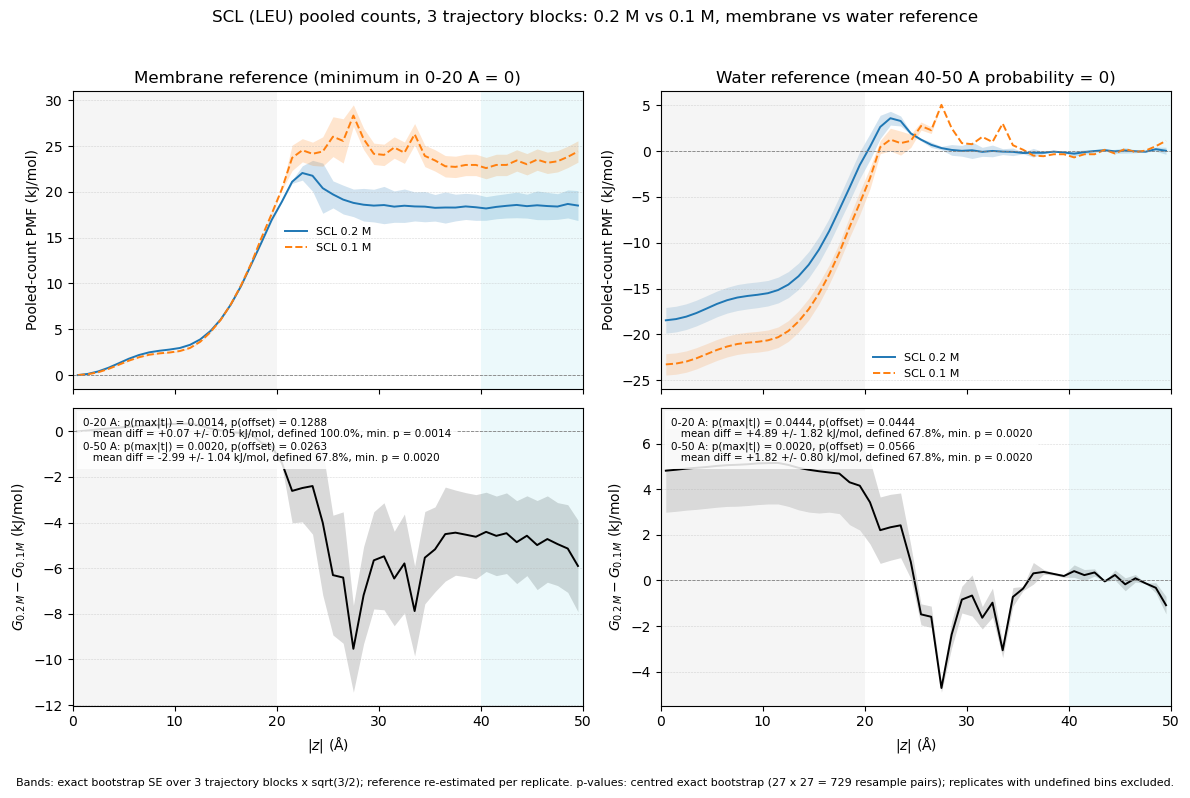

reference region  mean_difference_kJ_mol  mean_difference_se_kJ_mol  max_abs_t  p_max_t  p_mean_offset  min_attainable_p  bootstrap_defined_fraction
 membrane 0-20 A                0.071155                   0.047893   6.420588 0.001370       0.128767           0.00137                    1.000000
 membrane 0-50 A               -2.990448                   1.037561  11.439398 0.002020       0.026263           0.00202                    0.677641
    water 0-20 A                4.886045                   1.819733   2.870583 0.044444       0.044444           0.00202                    0.677641
    water 0-50 A                1.824442                   0.801846  25.634467 0.002020       0.056566           0.00202                    0.677641
Caveats: only 3 independent trajectories per concentration, so the bootstrap null distribution is coarse and SEs from 3 units are themselves very uncertain. 0.1 M water information comes from trajectory 1 only, so water-dependent tests are conditional on 

In [56]:
# SCL (LEU), pooled counts: p-values for 0.2 M vs 0.1 M with 3 TRAJECTORY blocks (independent cell).
# Each trajectory's three 200 ns count histograms are summed into one 600 ns block BEFORE any log.
# The pooled PMFs are identical to the 9-block version; only the uncertainty and p-values change.
# Exact bootstrap: all 3^3 = 27 resamples per concentration, combined independently (27 x 27 = 729).
# Membrane reference: each curve's minimum within 0-20 A set to 0; water reference: mean 40-50 A
# pooled count per bin set to 0. Both are re-estimated in every replicate; the null distribution
# of the difference is centred on the observed difference.
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOGS = {"scl": ("0.2 M", "tab:blue", "-"), "scl-1": ("0.1 M", "tab:orange", "--")}
MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
MEMBRANE_WINDOW, WATER_WINDOW = (0.0, 20.0), (40.0, 50.0)
REGIONS = {"0-20 A": (0.0, 20.0), "0-50 A": (0.0, 50.0)}
REFERENCES = {"membrane": "Membrane reference (minimum in 0-20 A = 0)",
              "water": "Water reference (mean 40-50 A probability = 0)"}
N_TRAJ = 3
SE_FLOOR = 1e-9
GRID = np.arange(0.5, 50.0, 1.0)
SAVE_NAME = f"FigureS_PMF_scl_concentration_pvalues_3blocks_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def sampling_depth(analog, trajectory, summary, data_dir):
    size = summary.loc[(summary.residu == analog) & (summary.traj == trajectory), "n_lines"]
    if size.empty:
        raw_path = data_dir / "raw_data" / analog / f"{analog}_contacts_{trajectory}.dat"
        with raw_path.open("rb") as fh:
            if not fh.readline().startswith(b"#"):
                raise ValueError(f"Expected a header in raw data: {raw_path}")
            n_lines = sum(1 for line in fh if line.strip())
    else:
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] != int(size.iloc[0]):
            raise ValueError(f"Invalid sampling depth: {analog}, trajectory {trajectory}")
        n_lines = int(size.iloc[0])
    if n_lines <= 0 or n_lines % 3:
        raise ValueError(f"Invalid three-block sampling depth: {analog}, trajectory {trajectory}")
    return n_lines // 3


def read_counts(analog, summary, data_dir):
    """Exact folded counts (9 blocks x 50 bins, 0-50 A). Referenced PMFs are count ratios,
    so bins beyond 50 A are not needed."""
    counts = []
    for t in (1, 2, 3):
        arr = np.loadtxt(data_dir / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if (arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all()
                or (arr[:, 1:] < 0).any() or np.any(np.diff(arr[:, 0]) <= 0)):
            raise ValueError(f"Invalid distribution file: {analog}, trajectory {t}")
        depth = sampling_depth(analog, t, summary, data_dir)
        keep = np.abs(arr[:, 0]) < 50.0
        idx = np.searchsorted(GRID, np.abs(arr[keep, 0]))
        if np.any(idx >= len(GRID)) or not np.allclose(GRID[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            residual = float(np.max(np.abs(unrounded - signed)))
            if residual > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot recover counts: {analog}, trajectory {t}, block {b + 1}")
            folded = np.zeros(len(GRID))
            np.add.at(folded, idx, signed[keep])
            counts.append(folded)
    return np.array(counts)


def referenced_pmf(counts, reference):
    """Pooled-count PMF; counts (..., n_blocks, K). NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    if reference == "membrane":
        anchor = pooled[..., (GRID >= MEMBRANE_WINDOW[0]) & (GRID <= MEMBRANE_WINDOW[1])].max(axis=-1)
    elif reference == "water":
        anchor = pooled[..., (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])].mean(axis=-1)
    else:
        raise ValueError(f"Unknown reference: {reference}")
    anchor = anchor[..., None]
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / anchor)
    return np.where((pooled > 0) & (anchor > 0), pmf, np.nan)


def conditional_se(values, n_blocks):
    """Exact-bootstrap SE over defined replicates (population variance over the enumerated
    resamples), x sqrt(n/(n-1)); NaN if < 2 defined."""
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    mean = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    centred = np.where(finite, values - mean, 0.0)
    var = (centred ** 2).sum(axis=0) / np.maximum(n_def, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(var)
    return np.where(n_def > 1, se, np.nan), n_def / len(values)


def bootstrap_test(diff, boot_diff, n_blocks):
    """Studentized max-|t| (any local difference) and mean-offset tests on one region, over the
    exactly enumerated resamples. Replicates with any undefined bin are excluded (conditional test).
    With 3 blocks the null distribution is coarse: the smallest attainable p is 1/(1 + n_defined)."""
    valid = np.isfinite(boot_diff).all(axis=1)
    if valid.sum() < 100:
        raise ValueError(f"Only {valid.sum()} defined bootstrap replicates; test not reliable")
    correction = np.sqrt(n_blocks / (n_blocks - 1))
    deviation = correction * (boot_diff[valid] - diff)
    se = deviation.std(axis=0, ddof=0)
    use = se > SE_FLOOR
    if not use.any():
        raise ValueError("All bins have zero bootstrap variance")
    t_obs = np.max(np.abs(diff[use]) / se[use])
    t_boot = np.max(np.abs(deviation[:, use]) / se[use], axis=1)
    offset = float(diff.mean())
    boot_offset = deviation.mean(axis=1)
    offset_se = float(boot_offset.std(ddof=0))
    n_valid = len(t_boot)
    return {"n_bins": int(diff.size), "n_bins_studentized": int(use.sum()),
            "mean_difference_kJ_mol": offset, "mean_difference_se_kJ_mol": offset_se,
            "max_abs_difference_kJ_mol": float(np.max(np.abs(diff))),
            "rms_difference_kJ_mol": float(np.sqrt(np.mean(diff ** 2))),
            "max_abs_t": float(t_obs),
            "p_max_t": (1 + int(np.sum(t_boot >= t_obs))) / (1 + n_valid),
            "p_mean_offset": (1 + int(np.sum(np.abs(boot_offset) >= abs(offset)))) / (1 + n_valid),
            "min_attainable_p": 1 / (1 + n_valid),
            "bootstrap_defined_fraction": float(valid.mean()), "n_bootstrap_defined": int(n_valid)}


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
summary_table = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
counts9 = {a: read_counts(a, summary_table, DATA_DIR) for a in ANALOGS}
if {len(c) for c in counts9.values()} != {9}:
    raise ValueError("Expected 9 blocks per concentration")
# One 600 ns block per trajectory: sum its three 200 ns count histograms (rows are ordered T1B1..T3B3).
counts = {a: c.reshape(N_TRAJ, 3, len(GRID)).sum(axis=1) for a, c in counts9.items()}
water_mask = (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])
for analog, c in counts.items():
    print(f"{analog}: water-window counts per trajectory = {c[:, water_mask].sum(axis=1).astype(int).tolist()}")
# Exact bootstrap: all 27 resamples per concentration, every 0.2 M resample paired with every 0.1 M one.
single = np.array(list(product(range(N_TRAJ), repeat=N_TRAJ)))
indices = {"scl": np.repeat(single, len(single), axis=0), "scl-1": np.tile(single, (len(single), 1))}
pmf, boot = {}, {}
for analog, c in counts.items():
    for reference in REFERENCES:
        pmf[analog, reference] = referenced_pmf(c, reference)
        boot[analog, reference] = referenced_pmf(c[indices[analog]], reference)

rows = []
for reference in REFERENCES:
    for region, (lo, hi) in REGIONS.items():
        mask = (GRID >= lo) & (GRID <= hi)
        diff = pmf["scl", reference][mask] - pmf["scl-1", reference][mask]
        if not np.isfinite(diff).all():
            raise ValueError(f"Observed PMF undefined in {region} ({reference} reference)")
        boot_diff = boot["scl", reference][:, mask] - boot["scl-1", reference][:, mask]
        result = bootstrap_test(diff, boot_diff, N_TRAJ)
        rows.append({"reference": reference, "region": region, **result})
        if result["bootstrap_defined_fraction"] < 1:
            print(f"WARNING: {reference}, {region}: test conditional on "
                  f"{100 * result['bootstrap_defined_fraction']:.1f}% defined bootstrap replicates.")
results = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
curve_rows = []
for col, (reference, title) in enumerate(REFERENCES.items()):
    ax = axes[0, col]
    for analog, (label, color, style) in ANALOGS.items():
        se, defined = conditional_se(boot[analog, reference], N_TRAJ)
        mean = pmf[analog, reference]
        ax.plot(GRID, mean, color=color, ls=style, lw=1.4, label=f"SCL {label}")
        ax.fill_between(GRID, mean - se, mean + se, color=color, alpha=0.2, lw=0)
        curve_rows.extend({"reference": reference, "series": label, "z_A": z, "mean_kJ_mol": m,
                           "se_kJ_mol": s, "bootstrap_defined_fraction": d}
                          for z, m, s, d in zip(GRID, mean, se, defined))
    ax.set(title=title, ylabel="Pooled-count PMF (kJ/mol)")
    ax.legend(fontsize=8, frameon=False)
    ax = axes[1, col]
    diff = pmf["scl", reference] - pmf["scl-1", reference]
    diff_se, _ = conditional_se(boot["scl", reference] - boot["scl-1", reference], N_TRAJ)
    ax.plot(GRID, diff, color="black", lw=1.4)
    ax.fill_between(GRID, diff - diff_se, diff + diff_se, color="black", alpha=0.15, lw=0)
    text = []
    for row in results.loc[results.reference == reference].itertuples(index=False):
        text.append(f"{row.region}: p(max|t|) = {row.p_max_t:.4f}, p(offset) = {row.p_mean_offset:.4f}\n"
                    f"   mean diff = {row.mean_difference_kJ_mol:+.2f} +/- {row.mean_difference_se_kJ_mol:.2f} kJ/mol, "
                    f"defined {100 * row.bootstrap_defined_fraction:.1f}%, min. p = {row.min_attainable_p:.4f}")
    ax.text(0.02, 0.97, "\n".join(text), transform=ax.transAxes, va="top", fontsize=7.5,
            bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"})
    ax.set(ylabel=r"$G_{0.2\,M}-G_{0.1\,M}$ (kJ/mol)")
    for z, d, s in zip(GRID, diff, diff_se):
        curve_rows.append({"reference": reference, "series": "difference 0.2 M - 0.1 M", "z_A": z,
                           "mean_kJ_mol": d, "se_kJ_mol": s, "bootstrap_defined_fraction": np.nan})
for ax in axes.flat:
    ax.axhline(0, color="gray", lw=0.6, ls="--")
    ax.axvspan(*MEMBRANE_WINDOW, color="0.85", alpha=0.25, lw=0)
    ax.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    ax.set_xlim(0, 50)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
for ax in axes[1]:
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
fig.suptitle("SCL (LEU) pooled counts, 3 trajectory blocks: 0.2 M vs 0.1 M, membrane vs water reference")
fig.text(0.5, 0.01, "Bands: exact bootstrap SE over 3 trajectory blocks x sqrt(3/2); reference re-estimated per replicate. "
         "p-values: centred exact bootstrap (27 x 27 = 729 resample pairs); "
         "replicates with undefined bins excluded.", ha="center", fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()

results.to_csv(SAVE_DIR / f"{SAVE_NAME}.csv", index=False)
pd.DataFrame(curve_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_curves.csv", index=False)
print(results[["reference", "region", "mean_difference_kJ_mol", "mean_difference_se_kJ_mol",
               "max_abs_t", "p_max_t", "p_mean_offset", "min_attainable_p",
               "bootstrap_defined_fraction"]].to_string(index=False))
print("Caveats: only 3 independent trajectories per concentration, so the bootstrap null distribution is "
      "coarse and SEs from 3 units are themselves very uncertain. 0.1 M water information comes from "
      "trajectory 1 only, so water-dependent tests are conditional on drawing it. Small p-values in densely "
      "sampled regions can reflect tiny, physically negligible differences.")


NOT TESTABLE: ILE, membrane, 0-50 A: unvisited bins: 0.1 M (25 bins).
NOT TESTABLE: ILE, water, 0-20 A: 0.1 M never reaches water.
NOT TESTABLE: ILE, water, 0-50 A: 0.1 M never reaches water.


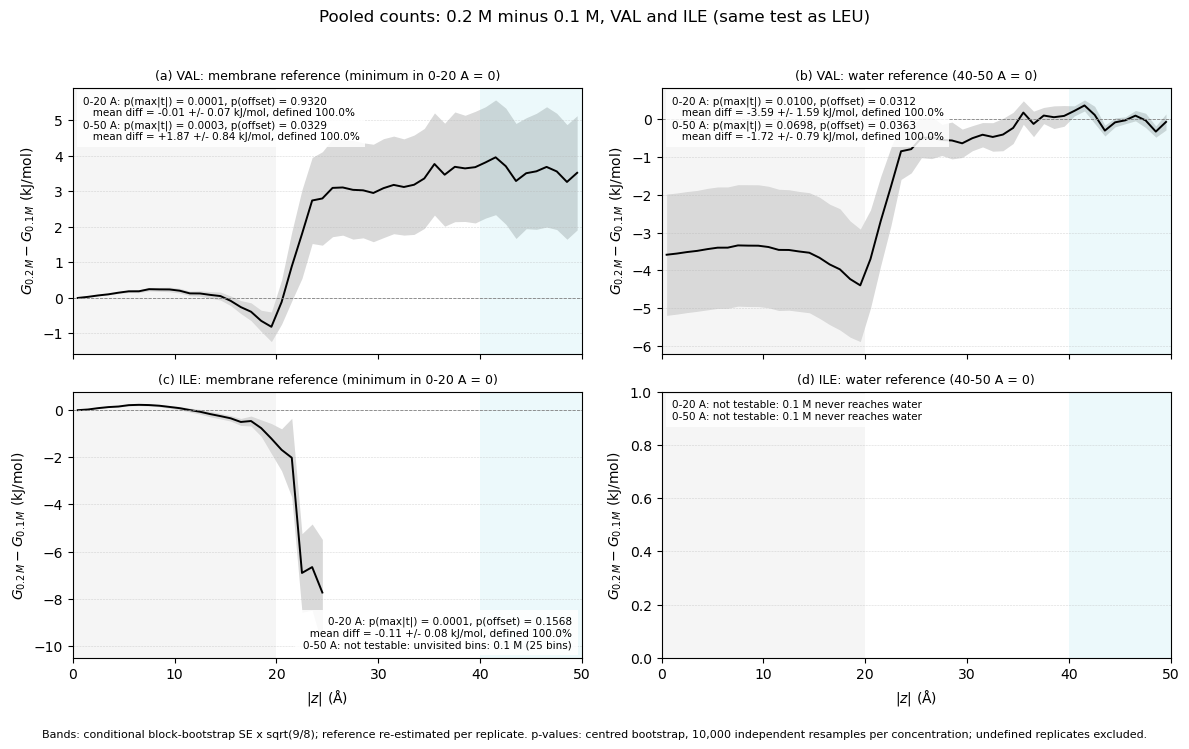

residue reference region                                        status  mean_difference_kJ_mol  mean_difference_se_kJ_mol  p_max_t  p_mean_offset  bootstrap_defined_fraction
    VAL  membrane 0-20 A                                        tested                 -0.0063                     0.0745   0.0001         0.9320                         1.0
    VAL  membrane 0-50 A                                        tested                  1.8665                     0.8407   0.0003         0.0329                         1.0
    VAL     water 0-20 A                                        tested                 -3.5946                     1.5923   0.0100         0.0312                         1.0
    VAL     water 0-50 A                                        tested                 -1.7218                     0.7895   0.0698         0.0363                         1.0
    ILE  membrane 0-20 A                                        tested                 -0.1144                     0.0807   0.0001

In [60]:
# VAL (SCV) and ILE (SCI), pooled counts: bootstrap p-values for 0.2 M vs 0.1 M, membrane vs water reference
# (independent cell; same test as the SCL/LEU 9-block cell).
# Membrane reference: each curve's minimum within 0-20 A = 0. Water reference: mean 40-50 A pooled count per bin = 0.
# Both re-estimated in every replicate; 9 blocks resampled independently per concentration (10,000 each);
# centred bootstrap null. A test is reported as not testable when an observed curve is undefined in the region.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESIDUES = {"scv": "VAL", "sci": "ILE"}
MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
MEMBRANE_WINDOW, WATER_WINDOW = (0.0, 20.0), (40.0, 50.0)
REGIONS = {"0-20 A": (0.0, 20.0), "0-50 A": (0.0, 50.0)}
REFERENCES = {"membrane": "membrane reference (minimum in 0-20 A = 0)",
              "water": "water reference (40-50 A = 0)"}
N_BOOT, SEED = 10000, 2025
SE_FLOOR = 1e-9
GRID = np.arange(0.5, 50.0, 1.0)
SAVE_NAME = f"FigureS_PMF_val_ile_concentration_pvalues_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def sampling_depth(analog, trajectory, summary, data_dir):
    size = summary.loc[(summary.residu == analog) & (summary.traj == trajectory), "n_lines"]
    if size.empty:
        raw_path = data_dir / "raw_data" / analog / f"{analog}_contacts_{trajectory}.dat"
        with raw_path.open("rb") as fh:
            if not fh.readline().startswith(b"#"):
                raise ValueError(f"Expected a header in raw data: {raw_path}")
            n_lines = sum(1 for line in fh if line.strip())
    else:
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] != int(size.iloc[0]):
            raise ValueError(f"Invalid sampling depth: {analog}, trajectory {trajectory}")
        n_lines = int(size.iloc[0])
    if n_lines <= 0 or n_lines % 3:
        raise ValueError(f"Invalid three-block sampling depth: {analog}, trajectory {trajectory}")
    return n_lines // 3


def read_counts(analog, summary, data_dir):
    """Exact folded counts (9 blocks x 50 bins, 0-50 A); referenced PMFs are count ratios."""
    counts = []
    for t in (1, 2, 3):
        arr = np.loadtxt(data_dir / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if (arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all()
                or (arr[:, 1:] < 0).any() or np.any(np.diff(arr[:, 0]) <= 0)):
            raise ValueError(f"Invalid distribution file: {analog}, trajectory {t}")
        depth = sampling_depth(analog, t, summary, data_dir)
        keep = np.abs(arr[:, 0]) < 50.0
        idx = np.searchsorted(GRID, np.abs(arr[keep, 0]))
        if np.any(idx >= len(GRID)) or not np.allclose(GRID[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            if np.max(np.abs(unrounded - signed)) > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot recover counts: {analog}, trajectory {t}, block {b + 1}")
            folded = np.zeros(len(GRID))
            np.add.at(folded, idx, signed[keep])
            counts.append(folded)
    return np.array(counts)


def referenced_pmf(counts, reference):
    """Pooled-count PMF; counts (..., n_blocks, K). NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    window = MEMBRANE_WINDOW if reference == "membrane" else WATER_WINDOW
    in_window = (GRID >= window[0]) & (GRID <= window[1])
    anchor = (pooled[..., in_window].max(axis=-1) if reference == "membrane"
              else pooled[..., in_window].mean(axis=-1))[..., None]
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / anchor)
    return np.where((pooled > 0) & (anchor > 0), pmf, np.nan)


def conditional_se(values, n_blocks):
    """Per-bin bootstrap SE over defined replicates, x sqrt(n/(n-1)); NaN if < 2 defined."""
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    mean = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    var = (np.where(finite, values - mean, 0.0) ** 2).sum(axis=0) / np.maximum(n_def - 1, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(var)
    return np.where(n_def > 1, se, np.nan), n_def / len(values)


def bootstrap_test(diff, boot_diff, n_blocks):
    """Studentized max-|t| and mean-offset tests (centred bootstrap); undefined replicates excluded."""
    valid = np.isfinite(boot_diff).all(axis=1)
    if valid.sum() < 100:
        raise ValueError(f"Only {valid.sum()} defined bootstrap replicates; test not reliable")
    deviation = np.sqrt(n_blocks / (n_blocks - 1)) * (boot_diff[valid] - diff)
    se = deviation.std(axis=0, ddof=1)
    use = se > SE_FLOOR
    if not use.any():
        raise ValueError("All bins have zero bootstrap variance")
    t_obs = np.max(np.abs(diff[use]) / se[use])
    t_boot = np.max(np.abs(deviation[:, use]) / se[use], axis=1)
    offset, boot_offset = float(diff.mean()), deviation.mean(axis=1)
    n_valid = len(t_boot)
    return {"mean_difference_kJ_mol": offset, "mean_difference_se_kJ_mol": float(boot_offset.std(ddof=1)),
            "max_abs_difference_kJ_mol": float(np.max(np.abs(diff))), "max_abs_t": float(t_obs),
            "p_max_t": (1 + int(np.sum(t_boot >= t_obs))) / (1 + n_valid),
            "p_mean_offset": (1 + int(np.sum(np.abs(boot_offset) >= abs(offset)))) / (1 + n_valid),
            "min_attainable_p": 1 / (1 + n_valid),
            "bootstrap_defined_fraction": float(valid.mean()), "n_bootstrap_defined": int(n_valid)}


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
summary_table = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
water_bins = (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])

pmf, boot, water_blocks = {}, {}, {}
for base in RESIDUES:
    for i, analog in enumerate((base, f"{base}-1")):
        counts = read_counts(analog, summary_table, DATA_DIR)
        water_blocks[analog] = int((counts[:, water_bins].sum(axis=1) > 0).sum())
        # Independent resampling per concentration (0.2 M: production seed; 0.1 M: next stream).
        idx = np.random.default_rng(SEED + i).integers(0, len(counts), size=(N_BOOT, len(counts)))
        for reference in REFERENCES:
            pmf[analog, reference] = referenced_pmf(counts, reference)
            boot[analog, reference] = referenced_pmf(counts[idx], reference)

rows = []
for base, name in RESIDUES.items():
    for reference in REFERENCES:
        for region, (lo, hi) in REGIONS.items():
            mask = (GRID >= lo) & (GRID <= hi)
            diff = pmf[base, reference][mask] - pmf[f"{base}-1", reference][mask]
            row = {"residue": name, "reference": reference, "region": region,
                   "water_blocks_0.2M": water_blocks[base], "water_blocks_0.1M": water_blocks[f"{base}-1"]}
            if not np.isfinite(diff).all():
                undefined = [f"{c} ({n} bins)" for c, a in (("0.2 M", base), ("0.1 M", f"{base}-1"))
                             if (n := int(np.isnan(pmf[a, reference][mask]).sum()))]
                reason = ("0.1 M never reaches water" if reference == "water" and water_blocks[f"{base}-1"] == 0
                          else "unvisited bins: " + ", ".join(undefined))
                print(f"NOT TESTABLE: {name}, {reference}, {region}: {reason}.")
                rows.append({**row, "status": f"not testable: {reason}"})
                continue
            boot_diff = boot[base, reference][:, mask] - boot[f"{base}-1", reference][:, mask]
            result = bootstrap_test(diff, boot_diff, 9)
            if result["bootstrap_defined_fraction"] < 1:
                print(f"WARNING: {name}, {reference}, {region}: test conditional on "
                      f"{100 * result['bootstrap_defined_fraction']:.1f}% defined replicates.")
            rows.append({**row, "status": "tested", **result})
results = pd.DataFrame(rows)

fig, axes = plt.subplots(len(RESIDUES), len(REFERENCES), figsize=(12, 3.75 * len(RESIDUES)), sharex=True,
                         squeeze=False)
curve_rows = []
for r, (base, name) in enumerate(RESIDUES.items()):
    for c, (reference, title) in enumerate(REFERENCES.items()):
        ax = axes[r, c]
        diff = pmf[base, reference] - pmf[f"{base}-1", reference]
        diff_se, _ = conditional_se(boot[base, reference] - boot[f"{base}-1", reference], 9)
        if np.isfinite(diff).any():
            ax.plot(GRID, diff, color="black", lw=1.4)
            ax.fill_between(GRID, diff - diff_se, diff + diff_se, color="black", alpha=0.15, lw=0)
        lines = []
        for row in results.loc[(results.residue == name) & (results.reference == reference)].itertuples(index=False):
            if row.status == "tested":
                lines.append(f"{row.region}: p(max|t|) = {row.p_max_t:.4f}, p(offset) = {row.p_mean_offset:.4f}\n"
                             f"   mean diff = {row.mean_difference_kJ_mol:+.2f} +/- "
                             f"{row.mean_difference_se_kJ_mol:.2f} kJ/mol, defined "
                             f"{100 * row.bootstrap_defined_fraction:.1f}%")
            else:
                lines.append(f"{row.region}: {row.status}")
        lo, hi = ax.get_ylim()
        left = diff[GRID <= MEMBRANE_WINDOW[1]]
        high_left = np.isfinite(left).any() and (np.nanmax(left) - lo) / (hi - lo) > 0.6
        ax.text(0.98 if high_left else 0.02, 0.03 if high_left else 0.97, "\n".join(lines),
                transform=ax.transAxes, ha="right" if high_left else "left",
                va="bottom" if high_left else "top", fontsize=7.5,
                bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"})
        ax.set_title(f"({chr(97 + r * len(REFERENCES) + c)}) {name}: {title}", fontsize=9)
        ax.axhline(0, color="gray", lw=0.6, ls="--")
        ax.axvspan(*MEMBRANE_WINDOW, color="0.85", alpha=0.25, lw=0)
        ax.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
        ax.set(xlim=(0, 50), ylabel=r"$G_{0.2\,M}-G_{0.1\,M}$ (kJ/mol)")
        ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
        curve_rows.extend({"residue": name, "reference": reference, "z_A": z, "difference_kJ_mol": d,
                           "se_kJ_mol": s} for z, d, s in zip(GRID, diff, diff_se))
for ax in axes[-1]:
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
fig.suptitle("Pooled counts: 0.2 M minus 0.1 M, VAL and ILE (same test as LEU)")
fig.text(0.5, 0.01, "Bands: conditional block-bootstrap SE x sqrt(9/8); reference re-estimated per replicate. "
         "p-values: centred bootstrap, 10,000 independent resamples per concentration; "
         "undefined replicates excluded.", ha="center", fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()

results.to_csv(SAVE_DIR / f"{SAVE_NAME}.csv", index=False)
pd.DataFrame(curve_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_curves.csv", index=False)
columns = ["residue", "reference", "region", "status", "mean_difference_kJ_mol", "mean_difference_se_kJ_mol",
           "p_max_t", "p_mean_offset", "bootstrap_defined_fraction"]
print(results.reindex(columns=columns).round(4).to_string(index=False))
print("Caveats: 9 blocks from 3 trajectories (blocks within a trajectory may be correlated); "
      "conditional tests exclude replicates without the required counts; the smallest attainable p is "
      "1/(1 + n_defined). Small p-values in densely sampled regions can reflect negligible differences.")


NOTE: ALA 0.1 M (sca-1) was not simulated; only the other concentration is shown.
NOTE: ILE 0.1 M, membrane: 25 unvisited bins shown as gaps.


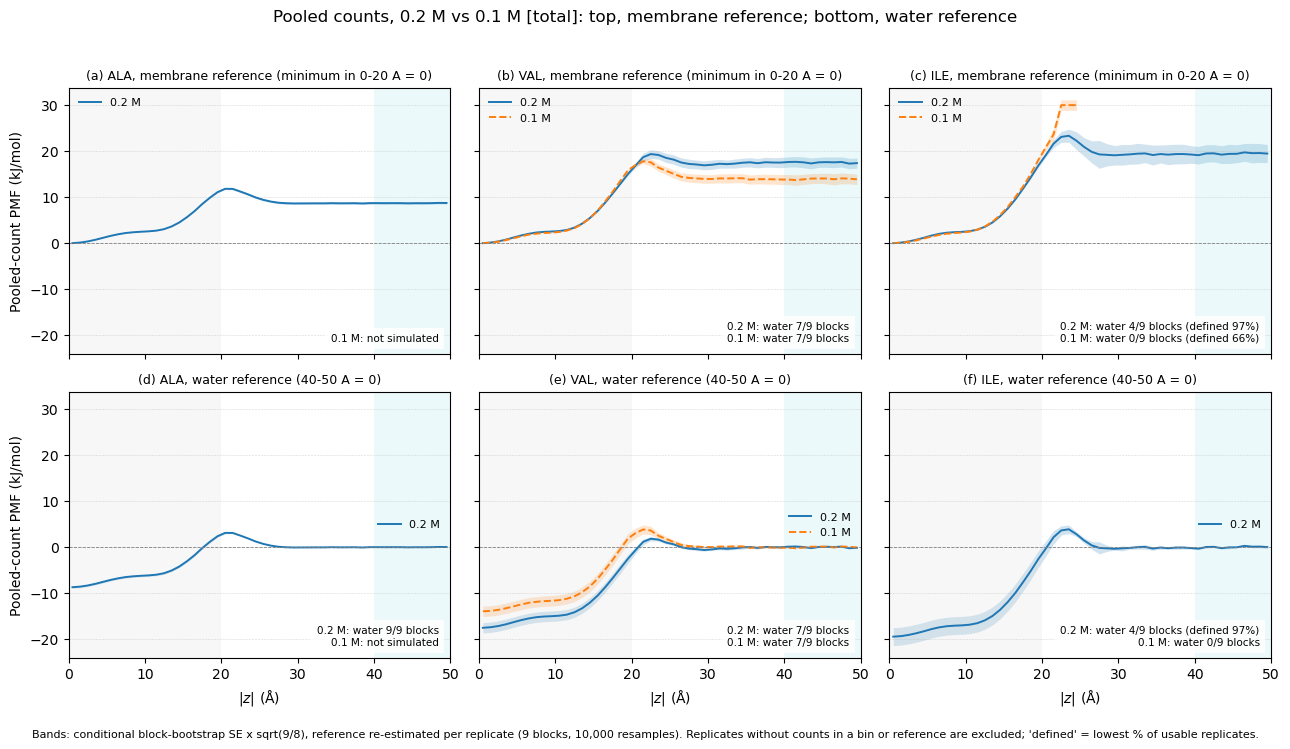

residue concentration reference  water_blocks  minimum_0_20A_kJ_mol  se_at_minimum_kJ_mol  mean_40_50A_kJ_mol  min_bootstrap_defined_fraction
    ALA         0.2 M  membrane             9                -0.000                 0.000               8.703                           1.000
    ALA         0.2 M     water             9                -8.703                 0.225               0.000                           1.000
    VAL         0.2 M  membrane             7                -0.000                 0.000              17.539                           1.000
    VAL         0.2 M     water             7               -17.535                 1.129               0.004                           1.000
    VAL         0.1 M  membrane             7                -0.000                 0.000              13.950                           1.000
    VAL         0.1 M     water             7               -13.947                 1.133               0.003                           1.000
    IL

In [59]:
# Pooled counts: 0.2 M vs 0.1 M for ALA (SCA), VAL (SCV), ILE (SCI), membrane and water references (independent cell).
# Membrane reference: each curve's minimum within 0-20 A = 0. Water reference: mean 40-50 A pooled count per bin = 0.
# Both are re-estimated in every bootstrap replicate (9 blocks, 10,000 resamples, seed 2025 as in production).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOGS = {"sca": "ALA", "scv": "VAL", "sci": "ILE"}
CONCENTRATIONS = {"": ("0.2 M", "tab:blue", "-"), "-1": ("0.1 M", "tab:orange", "--")}
MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
MEMBRANE_WINDOW, WATER_WINDOW = (0.0, 20.0), (40.0, 50.0)
REFERENCES = {"membrane": "membrane reference (minimum in 0-20 A = 0)",
              "water": "water reference (40-50 A = 0)"}
N_BOOT, SEED = 10000, 2025
GRID = np.arange(0.5, 50.0, 1.0)
SAVE_NAME = f"FigureS_PMF_pooled_counts_concentration_ala_val_ile_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def sampling_depth(analog, trajectory, summary, data_dir):
    size = summary.loc[(summary.residu == analog) & (summary.traj == trajectory), "n_lines"]
    if size.empty:
        raw_path = data_dir / "raw_data" / analog / f"{analog}_contacts_{trajectory}.dat"
        with raw_path.open("rb") as fh:
            if not fh.readline().startswith(b"#"):
                raise ValueError(f"Expected a header in raw data: {raw_path}")
            n_lines = sum(1 for line in fh if line.strip())
    else:
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] != int(size.iloc[0]):
            raise ValueError(f"Invalid sampling depth: {analog}, trajectory {trajectory}")
        n_lines = int(size.iloc[0])
    if n_lines <= 0 or n_lines % 3:
        raise ValueError(f"Invalid three-block sampling depth: {analog}, trajectory {trajectory}")
    return n_lines // 3


def read_counts(analog, summary, data_dir):
    """Exact folded counts (9 blocks x 50 bins, 0-50 A); referenced PMFs are count ratios."""
    counts = []
    for t in (1, 2, 3):
        arr = np.loadtxt(data_dir / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if (arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all()
                or (arr[:, 1:] < 0).any() or np.any(np.diff(arr[:, 0]) <= 0)):
            raise ValueError(f"Invalid distribution file: {analog}, trajectory {t}")
        depth = sampling_depth(analog, t, summary, data_dir)
        keep = np.abs(arr[:, 0]) < 50.0
        idx = np.searchsorted(GRID, np.abs(arr[keep, 0]))
        if np.any(idx >= len(GRID)) or not np.allclose(GRID[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            if np.max(np.abs(unrounded - signed)) > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot recover counts: {analog}, trajectory {t}, block {b + 1}")
            folded = np.zeros(len(GRID))
            np.add.at(folded, idx, signed[keep])
            counts.append(folded)
    return np.array(counts)


def referenced_pmf(counts, reference):
    """Pooled-count PMF; counts (..., n_blocks, K). NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    window = MEMBRANE_WINDOW if reference == "membrane" else WATER_WINDOW
    in_window = (GRID >= window[0]) & (GRID <= window[1])
    anchor = (pooled[..., in_window].max(axis=-1) if reference == "membrane"
              else pooled[..., in_window].mean(axis=-1))[..., None]
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / anchor)
    return np.where((pooled > 0) & (anchor > 0), pmf, np.nan)


def conditional_se(values, n_blocks):
    """Per-bin bootstrap SE over defined replicates, x sqrt(n/(n-1)); NaN if < 2 defined."""
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    mean = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    var = (np.where(finite, values - mean, 0.0) ** 2).sum(axis=0) / np.maximum(n_def - 1, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(var)
    return np.where(n_def > 1, se, np.nan), n_def / len(values)


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
summary_table = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
water_bins = (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])
show = GRID <= 50

fig, axes = plt.subplots(2, len(ANALOGS), figsize=(13, 7.5), sharex=True, sharey=True)
curve_rows, summary_rows = [], []
for col, (base, name) in enumerate(ANALOGS.items()):
    notes = {reference: [] for reference in REFERENCES}
    for suffix, (label, color, style) in CONCENTRATIONS.items():
        analog = base + suffix
        if not (DATA_DIR / MODE / analog).is_dir():
            print(f"NOTE: {name} {label} ({analog}) was not simulated; only the other concentration is shown.")
            for reference in REFERENCES:
                notes[reference].append(f"{label}: not simulated")
            continue
        counts = read_counts(analog, summary_table, DATA_DIR)
        water_blocks = int((counts[:, water_bins].sum(axis=1) > 0).sum())
        idx = np.random.default_rng(SEED).integers(0, len(counts), size=(N_BOOT, len(counts)))
        for row, reference in enumerate(REFERENCES):
            mean = referenced_pmf(counts, reference)
            if reference == "water" and water_blocks == 0:
                print(f"WARNING: {name} {label}: water never visited in any block; "
                      "the water-referenced PMF is undefined and is not plotted.")
                notes[reference].append(f"{label}: water 0/9 blocks")
                continue
            se, defined = conditional_se(referenced_pmf(counts[idx], reference), len(counts))
            ax = axes[row, col]
            ax.plot(GRID[show], mean[show], color=color, ls=style, lw=1.4, label=label)
            ax.fill_between(GRID[show], (mean - se)[show], (mean + se)[show], color=color, alpha=0.2, lw=0)
            min_defined = float(np.nanmin(np.where(np.isfinite(mean), defined, np.nan)))
            if reference == "water" or water_blocks < len(counts):
                notes[reference].append(f"{label}: water {water_blocks}/9 blocks"
                                        + (f" (defined {100 * min_defined:.0f}%)"
                                           if min_defined < 1 else ""))
            if np.isnan(mean[show]).any():
                print(f"NOTE: {name} {label}, {reference}: {int(np.isnan(mean[show]).sum())} unvisited bins shown as gaps.")
            membrane = GRID <= MEMBRANE_WINDOW[1]
            i_min = int(np.nanargmin(np.where(membrane, mean, np.nan)))
            plateau = float(np.nanmean(mean[water_bins])) if np.isfinite(mean[water_bins]).any() else np.nan
            summary_rows.append({"analog": analog, "residue": name, "concentration": label,
                                 "reference": reference, "water_blocks": water_blocks,
                                 "minimum_0_20A_kJ_mol": float(mean[i_min]),
                                 "se_at_minimum_kJ_mol": float(se[i_min]), "z_minimum_A": float(GRID[i_min]),
                                 "mean_40_50A_kJ_mol": plateau,
                                 "min_bootstrap_defined_fraction": min_defined})
            curve_rows.extend({"analog": analog, "residue": name, "concentration": label,
                               "reference": reference, "z_A": z, "mean_kJ_mol": m, "se_kJ_mol": s,
                               "bootstrap_defined_fraction": d}
                              for z, m, s, d in zip(GRID, mean, se, defined))
    for row, (reference, title) in enumerate(REFERENCES.items()):
        ax = axes[row, col]
        ax.set_title(f"({chr(97 + row * len(ANALOGS) + col)}) {name}, {title}", fontsize=9)
        if notes[reference]:
            ax.text(0.97, 0.04, "\n".join(notes[reference]), transform=ax.transAxes, ha="right",
                    va="bottom", fontsize=7.5, bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"})
        ax.legend(loc="upper left" if reference == "membrane" else "center right", fontsize=8, frameon=False)
for ax in axes.flat:
    ax.axhline(0, color="gray", lw=0.6, ls="--")
    ax.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    ax.axvspan(*MEMBRANE_WINDOW, color="0.85", alpha=0.2, lw=0)
    ax.set_xlim(0, 50)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
for ax in axes[1]:
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
for ax in axes[:, 0]:
    ax.set_ylabel("Pooled-count PMF (kJ/mol)")
fig.suptitle(f"Pooled counts, 0.2 M vs 0.1 M [{MODE}]: top, membrane reference; bottom, water reference")
fig.text(0.5, 0.01, "Bands: conditional block-bootstrap SE x sqrt(9/8), reference re-estimated per replicate "
         "(9 blocks, 10,000 resamples). Replicates without counts in a bin or reference are excluded; "
         "'defined' = lowest % of usable replicates.",
         ha="center", fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()

summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(curve_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_curves.csv", index=False)
print(summary[["residue", "concentration", "reference", "water_blocks", "minimum_0_20A_kJ_mol",
               "se_at_minimum_kJ_mol", "mean_40_50A_kJ_mol", "min_bootstrap_defined_fraction"]]
      .round(3).to_string(index=False))


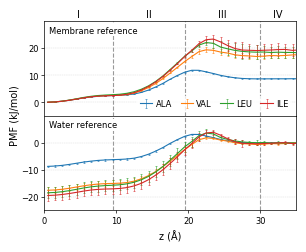

Water-referenced minima (0-20 A), pooled counts, 0.2 M:
residue  z_A  mean_kJ_mol  se_kJ_mol  water_blocks
    ILE  0.5      -19.461      1.954             4
    LEU  0.5      -18.462      2.044             4
    VAL  0.5      -17.535      1.129             7
    ALA  0.5       -8.703      0.225             9
Y limits (kJ/mol): {'membrane': (-5.0, 30.0), 'water': (-25.0, 10.0)}


In [68]:
# Figure 3, hydrophobic panel (ALA, VAL, LEU, ILE at 0.2 M) rebuilt with pooled counts (independent cell).
# Top: membrane reference (each curve's minimum within 0-20 A = 0). Bottom: water reference (40-50 A = 0).
# Style follows Figure3-4_plot.ipynb (8.26 cm width, 0-35 A, grid at 9.5/19.5/30 A, regions I-IV,
# same 0.028 in per kJ/mol vertical scale). Error bars: block-bootstrap SE with the reference re-estimated.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.gridspec import GridSpec

RESIDUES = {"sca": "ALA", "scv": "VAL", "scl": "LEU", "sci": "ILE"}
MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
MEMBRANE_WINDOW, WATER_WINDOW = (0.0, 20.0), (40.0, 50.0)
REFERENCES = {"membrane": "Membrane reference", "water": "Water reference"}
N_BOOT, SEED = 10000, 2025
GRID = np.arange(0.5, 50.0, 1.0)
XLIM, HEIGHT_PER_UNIT, FIG_WIDTH = (0, 35), 0.028, 8.26 / 2.54
CUSTOM_VGRID = [9.5, 19.5, 30]
ROMAN = [("I", 4.75), ("II", 14.5), ("III", 24.75), ("IV", 32.5)]
STYLE = {"font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7, "xtick.labelsize": 6,
         "ytick.labelsize": 6, "legend.fontsize": 5, "lines.linewidth": 0.8, "axes.linewidth": 0.5,
         "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2,
         "ytick.major.size": 2, "errorbar.capsize": 1}
SAVE_NAME = f"FigureS_PMF_Figure3_hydrophobic_pooled_counts_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def sampling_depth(analog, trajectory, summary, data_dir):
    size = summary.loc[(summary.residu == analog) & (summary.traj == trajectory), "n_lines"]
    if size.empty:
        raw_path = data_dir / "raw_data" / analog / f"{analog}_contacts_{trajectory}.dat"
        with raw_path.open("rb") as fh:
            if not fh.readline().startswith(b"#"):
                raise ValueError(f"Expected a header in raw data: {raw_path}")
            n_lines = sum(1 for line in fh if line.strip())
    else:
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] != int(size.iloc[0]):
            raise ValueError(f"Invalid sampling depth: {analog}, trajectory {trajectory}")
        n_lines = int(size.iloc[0])
    if n_lines <= 0 or n_lines % 3:
        raise ValueError(f"Invalid three-block sampling depth: {analog}, trajectory {trajectory}")
    return n_lines // 3


def read_counts(analog, summary, data_dir):
    """Exact folded counts (9 blocks x 50 bins, 0-50 A); referenced PMFs are count ratios."""
    counts = []
    for t in (1, 2, 3):
        arr = np.loadtxt(data_dir / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if (arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all()
                or (arr[:, 1:] < 0).any() or np.any(np.diff(arr[:, 0]) <= 0)):
            raise ValueError(f"Invalid distribution file: {analog}, trajectory {t}")
        depth = sampling_depth(analog, t, summary, data_dir)
        keep = np.abs(arr[:, 0]) < 50.0
        idx = np.searchsorted(GRID, np.abs(arr[keep, 0]))
        if np.any(idx >= len(GRID)) or not np.allclose(GRID[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            if np.max(np.abs(unrounded - signed)) > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot recover counts: {analog}, trajectory {t}, block {b + 1}")
            folded = np.zeros(len(GRID))
            np.add.at(folded, idx, signed[keep])
            counts.append(folded)
    return np.array(counts)


def referenced_pmf(counts, reference):
    """Pooled-count PMF; counts (..., n_blocks, K). NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    window = MEMBRANE_WINDOW if reference == "membrane" else WATER_WINDOW
    in_window = (GRID >= window[0]) & (GRID <= window[1])
    anchor = (pooled[..., in_window].max(axis=-1) if reference == "membrane"
              else pooled[..., in_window].mean(axis=-1))[..., None]
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / anchor)
    return np.where((pooled > 0) & (anchor > 0), pmf, np.nan)


def conditional_se(values, n_blocks):
    """Per-bin bootstrap SE over defined replicates, x sqrt(n/(n-1)); NaN if < 2 defined."""
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    mean = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    var = (np.where(finite, values - mean, 0.0) ** 2).sum(axis=0) / np.maximum(n_def - 1, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(var)
    return np.where(n_def > 1, se, np.nan), n_def / len(values)


def nice_limits(low, high, step=5.0, pad=1.0):
    return float(np.floor((low - pad) / step) * step), float(np.ceil((high + pad) / step) * step)


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
summary_table = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
water_bins = (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])
in_view = (GRID >= XLIM[0]) & (GRID <= XLIM[1])

curves, rows = {}, []
for analog, name in RESIDUES.items():
    counts = read_counts(analog, summary_table, DATA_DIR)
    water_blocks = int((counts[:, water_bins].sum(axis=1) > 0).sum())
    if water_blocks == 0:
        raise ValueError(f"{name}: no water-window counts; water-referenced PMF undefined")
    idx = np.random.default_rng(SEED).integers(0, len(counts), size=(N_BOOT, len(counts)))
    for reference in REFERENCES:
        mean = referenced_pmf(counts, reference)
        se, defined = conditional_se(referenced_pmf(counts[idx], reference), len(counts))
        curves[analog, reference] = (mean, se)
        if np.isnan(mean[in_view]).any():
            print(f"NOTE: {name}, {reference}: unvisited bins in 0-35 A shown as gaps.")
        min_defined = float(np.nanmin(np.where(np.isfinite(mean), defined, np.nan)))
        if min_defined < 1:
            print(f"WARNING: {name}, {reference}: SE conditional on {100 * min_defined:.1f}% defined replicates.")
        rows.extend({"analog": analog, "residue": name, "reference": reference, "z_A": z,
                     "mean_kJ_mol": m, "se_kJ_mol": s, "bootstrap_defined_fraction": d,
                     "water_blocks": water_blocks} for z, m, s, d in zip(GRID, mean, se, defined))

limits = {}
for reference in REFERENCES:
    lows = [np.nanmin((m - s)[in_view]) for (a, r), (m, s) in curves.items() if r == reference]
    highs = [np.nanmax((m + s)[in_view]) for (a, r), (m, s) in curves.items() if r == reference]
    limits[reference] = nice_limits(min(lows), max(highs))
heights = [(hi - lo) * HEIGHT_PER_UNIT for lo, hi in limits.values()]

with plt.rc_context(STYLE):
    fig = plt.figure(figsize=(FIG_WIDTH, sum(heights) + 0.5))
    gs = GridSpec(len(REFERENCES), 1, figure=fig, height_ratios=heights, hspace=0)
    axes = [fig.add_subplot(gs[i, 0]) for i in range(len(REFERENCES))]
    for i, (ax, (reference, title)) in enumerate(zip(axes, REFERENCES.items())):
        for analog, name in RESIDUES.items():
            mean, se = curves[analog, reference]
            ax.errorbar(GRID, mean, se, label=name, lw=0.8, capsize=1, capthick=0.4, elinewidth=0.4)
        for spine in ax.spines.values():
            spine.set_linewidth(0.5)
        ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
        ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
        for xv in CUSTOM_VGRID:
            ax.axvline(x=xv, linestyle="--", alpha=0.8, linewidth=0.8, color="gray", zorder=0)
        ax.yaxis.grid(True, which="major", linestyle="--", alpha=0.5, linewidth=0.3)
        ax.set_xlim(*XLIM)
        ax.set_ylim(limits[reference])
        lo, hi = limits[reference]
        # Stacked panels share edges: keep tick labels strictly inside each panel.
        ax.set_yticks([t for t in np.arange(np.ceil(lo / 10) * 10, hi + 1e-9, 10) if lo < t < hi])
        ax.tick_params(axis="both", which="major", pad=2)
        ax.text(0.02, 0.95, title, transform=ax.transAxes, ha="left", va="top", fontsize=6,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
        if i == 0:
            ax.legend(loc="lower right", ncols=len(RESIDUES), fontsize=6, frameon=True,
                      facecolor="white", edgecolor="none", handlelength=1.5, handletextpad=0.4,
                      columnspacing=1.0)
            for numeral, x_pos in ROMAN:
                ax.text(x_pos, 1.02, numeral, transform=ax.get_xaxis_transform(),
                        ha="center", va="bottom", fontsize=7)
        if i < len(REFERENCES) - 1:
            ax.tick_params(labelbottom=False)
    axes[-1].set_xlabel("z (Å)")
    fig.text(0.02, 0.5, "PMF (kJ/mol)", va="center", rotation="vertical")
    for extension in ("png", "pdf"):
        fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", bbox_inches="tight", dpi=600)
    plt.show()

table = pd.DataFrame(rows)
table.to_csv(SAVE_DIR / f"{SAVE_NAME}.csv", index=False)
wells = (table.loc[(table.reference == "water") & (table.z_A <= MEMBRANE_WINDOW[1])]
         .sort_values("mean_kJ_mol").groupby("residue", sort=False).head(1))
print("Water-referenced minima (0-20 A), pooled counts, 0.2 M:")
print(wells[["residue", "z_A", "mean_kJ_mol", "se_kJ_mol", "water_blocks"]].round(3).to_string(index=False))
print("Y limits (kJ/mol):", limits)


In [ ]:
# SCY (TYR), 0.2 M: five MD estimators versus US, membrane and water references (independent cell).
# Membrane bands retain untranslated SE under a fixed shift; minimum uncertainty is not propagated.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOG, MODE = "scy", "total"
MEMBRANE_WINDOW = (0.0, 20.0)
XLIM = (0.0, 50.0)
KCAL_TO_KJ = 4.184
METHODS = {
    "": (r"Pseudocount ($\varepsilon=10^{-5}$)", "tab:gray", "-"),
    "_poisson": ("Poisson-Gamma", "tab:green", ":"),
    "_bayesian": ("Bayesian (Dirichlet)", "tab:blue", "--"),
    "_latent": ("Latent logarithm", "tab:orange", "-."),
    "_counting": ("Pooled counts", "tab:red", (0, (5, 2))),
}
SAVE_NAME = f"FigureS_PMF_scy_methods_US_{MODE}"
FONT_SCALE = 1.8  # enlarge all text for print (see enlarge_fonts_and_layout)


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "supp_files" / "method_script" / "4-pmf_calculation").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_profile(path, umbrella=False):
    if umbrella:
        df = pd.read_csv(path, sep=r"\s+", comment="#", header=None,
                         names=["z", "mean", "se", "n_blocks"])
        df[["mean", "se"]] *= KCAL_TO_KJ
    else:
        df = pd.read_csv(path, sep=r"\s+")
    if not {"z", "mean", "se"}.issubset(df.columns):
        raise ValueError(f"Missing PMF columns: {path}")
    z = df["z"].to_numpy()
    if len(z) < 2 or not np.isfinite(z).all() or np.any(np.diff(z) <= 0):
        raise ValueError(f"Invalid z grid: {path}")
    values = df[["mean", "se"]].to_numpy()
    if np.isinf(values).any() or np.any(df["se"].dropna() < 0):
        raise ValueError(f"Invalid PMF or SE: {path}")
    finite_mean, finite_se = np.isfinite(df["mean"]), np.isfinite(df["se"])
    if not np.array_equal(finite_mean, finite_se):
        raise ValueError(f"Inconsistent undefined mean/SE bins: {path}")
    df = df.loc[df["z"].between(*XLIM)].copy()
    if np.isfinite(df["mean"]).sum() < 2:
        raise ValueError(f"Insufficient defined PMF bins in plot range: {path}")
    if df["mean"].isna().any():
        print(f"WARNING: {path.name}: {df['mean'].isna().sum()} undefined bins shown as gaps.")
    return df



def _split_outside_math(text):
    """Split on spaces that are not inside $...$ (mathtext must not be broken)."""
    words, current, in_math = [], "", False
    for char in text:
        if char == "$":
            in_math = not in_math
        if char == " " and not in_math:
            words.append(current)
            current = ""
        else:
            current += char
    words.append(current)
    return [w for w in words if w]


def _wrap_text(artist, max_px, renderer):
    """Greedy re-wrap of a Text artist so that no line is longer than max_px."""
    def length(candidate):
        artist.set_text(candidate)
        box = artist.get_window_extent(renderer)
        return box.height if abs(artist.get_rotation() % 180 - 90) < 1 else box.width
    original = artist.get_text()
    if not original.strip() or length(original) <= max_px:
        artist.set_text(original)
        return
    out = []
    for paragraph in original.split("\n"):
        indent = paragraph[:len(paragraph) - len(paragraph.lstrip(" "))]
        words = _split_outside_math(paragraph)
        if not words:
            out.append(paragraph)
            continue
        line = indent + words[0]
        for word in words[1:]:
            if length(f"{line} {word}") > max_px:
                out.append(line)
                line = indent + word
            else:
                line = f"{line} {word}"
        out.append(line)
    artist.set_text("\n".join(out))


def enlarge_fonts_and_layout(fig, factor, margin=0.01):
    """Scale every text of fig by factor, wrap titles/labels/notes that no longer fit, and lay out
    the axes between the footnotes and the suptitle."""
    from matplotlib.text import Text
    tick_sizes = {}
    for ax in fig.axes:
        for name, axis in (("x", ax.xaxis), ("y", ax.yaxis)):
            ticks = axis.get_major_ticks()
            if ticks:
                tick_sizes[ax, name] = ticks[0].label1.get_fontsize()
    seen = set()
    for artist in fig.findobj(Text):
        if id(artist) not in seen:
            seen.add(id(artist))
            artist.set_fontsize(artist.get_fontsize() * factor)
    for (ax, name), size in tick_sizes.items():
        ax.tick_params(axis=name, labelsize=size * factor)

    def rect():
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        to_fig = fig.transFigure.inverted()
        suptitle = getattr(fig, "_suptitle", None)
        bottom, top = 0.0, 1.0
        for text in fig.texts:
            if text.get_text().strip():
                box = text.get_window_extent(renderer).transformed(to_fig)
                if text is suptitle:
                    top = min(top, box.y0 - margin)
                else:
                    bottom = max(bottom, box.y1 + margin)
        # Figure legends sit directly above the footnotes, the axes above both.
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, bottom), transform=fig.transFigure)
        if fig.legends:
            fig.canvas.draw()
            bottom = max(legend.get_window_extent(renderer).transformed(to_fig).y1
                         for legend in fig.legends) + margin
        return (0, bottom, 1, top)

    fig.tight_layout(rect=rect())
    renderer = fig.canvas.get_renderer()
    fig_width = fig.bbox.width
    for text in fig.texts:
        _wrap_text(text, 0.98 * fig_width, renderer)
    for ax in fig.axes:
        box = ax.get_window_extent(renderer)
        _wrap_text(ax.title, 1.0 * box.width, renderer)
        _wrap_text(ax.xaxis.label, 1.0 * box.width, renderer)
        _wrap_text(ax.yaxis.label, 1.0 * box.height, renderer)
        for text in ax.texts:
            if text.get_transform() == ax.transAxes:
                x = text.get_position()[0]
                space = {"left": 1 - x, "right": x, "center": 2 * min(x, 1 - x)}[text.get_ha()]
                _wrap_text(text, 0.97 * space * box.width, renderer)
    fig.tight_layout(rect=rect())


ROOT = find_repo_root()
METHOD_ROOT = ROOT / "supp_files" / "method_script"
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf" / ANALOG
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
curves, summary_rows, figures = [], [], {}
for reference in ("membrane", "water"):
    suffix = "_untranslated" if reference == "membrane" else ""
    sources = [
        (name, color, style, METHOD_ROOT / f"4-pmf_calculation{method}" / MODE /
         ANALOG / f"pmf_{ANALOG}{suffix}.dat", False)
        for method, (name, color, style) in METHODS.items()
    ]
    sources.append(("Umbrella sampling", "black", "-", US_DIR /
                    f"pmf-us-{ANALOG}{'-untranslated' if suffix else ''}.dat", True))
    fig, ax = plt.subplots(figsize=(8.5, 8.5))
    figures[reference] = fig
    for name, color, style, path, umbrella in sources:
        df = read_profile(path, umbrella)
        shift, anchor_z = 0.0, np.nan
        if reference == "membrane":
            membrane = df.loc[df["z"].between(*MEMBRANE_WINDOW) & np.isfinite(df["mean"])]
            if membrane.empty:
                raise ValueError(f"No defined bins for membrane reference: {path}")
            anchor = membrane.loc[membrane["mean"].idxmin()]
            shift, anchor_z = float(anchor["mean"]), float(anchor["z"])
            df["mean"] -= shift
        label = name + (f" ({int(df['n_blocks'].iloc[0])} blocks)" if umbrella else "")
        ax.plot(df["z"], df["mean"], color=color, ls=style,
                lw=1.7 if umbrella else 1.2, label=label, zorder=4 if umbrella else 3)
        ax.fill_between(df["z"], df["mean"] - df["se"], df["mean"] + df["se"],
                        color=color, alpha=0.12, lw=0, zorder=1)
        finite = df.loc[np.isfinite(df["mean"])]
        well = finite.loc[finite["mean"].idxmin()]
        defined = float(df["boot_defined"].min()) if "boot_defined" in df else np.nan
        if np.isfinite(defined) and defined < 1:
            print(f"WARNING: {name}: minimum defined-bootstrap fraction = {defined:.4f}; "
                  "pooled-count water SE is conditional on defined resamples.")
        summary_rows.append({
            "reference": reference, "method": name, "source": str(path),
            "subtracted_shift_kJ_mol": shift, "membrane_anchor_z_A": anchor_z,
            "minimum_z_A": float(well["z"]), "minimum_kJ_mol": float(well["mean"]),
            "se_at_minimum_kJ_mol": float(well["se"]),
            "min_boot_defined": defined,
            "uncertainty": ("untranslated SE; fixed minimum shift, anchor uncertainty not propagated"
                            if reference == "membrane" else "supplied water-referenced SE"),
        })
        for row in df.itertuples(index=False):
            curves.append({"reference": reference, "method": name, "z_A": float(row.z),
                           "mean_kJ_mol": float(row.mean), "se_kJ_mol": float(row.se)})
    ax.axhline(0, color="gray", lw=0.7, ls="--")
    if reference == "membrane":
        ax.axvspan(*MEMBRANE_WINDOW, color="0.8", alpha=0.15, lw=0)
        title = "membrane reference"
        note = ("Bands: untranslated SE under a fixed shift.\n"
                "Uncertainty of the estimated minimum is not propagated.")
    else:
        ax.axvspan(40, 50, color="tab:cyan", alpha=0.08, lw=0)
        title = "water reference"
        note = ("MD: 40-50 A reference; US: each folded block zeroed at |z| >= 30 A.\n"
                "Bands: supplied SE; pooled-count SE excludes undefined bootstrap resamples.")
    ax.set(title=f"SCY (TYR), 0.2 M [{MODE}]: {title}",
           xlabel=r"$|z|$ ($\mathrm{\AA}$)", ylabel="PMF (kJ/mol)", xlim=XLIM)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
    fig.legend(*ax.get_legend_handles_labels(), loc="lower center", fontsize=9, frameon=False, ncol=2)
    print(f"Caption note ({reference} reference): " + " ".join(note.split()))
    enlarge_fonts_and_layout(fig, FONT_SCALE)
    for extension in ("png", "pdf"):
        fig.savefig(SAVE_DIR / f"{SAVE_NAME}_{reference}.{extension}", dpi=600, bbox_inches="tight")
    plt.show()

summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(curves).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
print(summary[["reference", "method", "minimum_kJ_mol", "se_at_minimum_kJ_mol"]].to_string(index=False))


In [ ]:
# SCY (TYR), 0.1 M: five MD estimators versus US, membrane and water references (independent cell).
# Membrane bands retain untranslated SE under a fixed shift; minimum uncertainty is not propagated.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOG, US_ANALOG, MODE = "scy-1", "scy", "total"
MEMBRANE_WINDOW = (0.0, 20.0)
XLIM = (0.0, 50.0)
KCAL_TO_KJ = 4.184
METHODS = {
    "": (r"Pseudocount ($\varepsilon=10^{-5}$)", "tab:gray", "-"),
    "_poisson": ("Poisson-Gamma", "tab:green", ":"),
    "_bayesian": ("Bayesian (Dirichlet)", "tab:blue", "--"),
    "_latent": ("Latent logarithm", "tab:orange", "-."),
    "_counting": ("Pooled counts", "tab:red", (0, (5, 2))),
}
SAVE_NAME = f"FigureS_PMF_scy_01M_methods_US_{MODE}"
FONT_SCALE = 1.8  # enlarge all text for print (see enlarge_fonts_and_layout)


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "supp_files" / "method_script" / "4-pmf_calculation").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_profile(path, umbrella=False):
    if umbrella:
        df = pd.read_csv(path, sep=r"\s+", comment="#", header=None,
                         names=["z", "mean", "se", "n_blocks"])
        df[["mean", "se"]] *= KCAL_TO_KJ
    else:
        df = pd.read_csv(path, sep=r"\s+")
    if not {"z", "mean", "se"}.issubset(df.columns):
        raise ValueError(f"Missing PMF columns: {path}")
    z = df["z"].to_numpy()
    if len(z) < 2 or not np.isfinite(z).all() or np.any(np.diff(z) <= 0):
        raise ValueError(f"Invalid z grid: {path}")
    values = df[["mean", "se"]].to_numpy()
    if np.isinf(values).any() or np.any(df["se"].dropna() < 0):
        raise ValueError(f"Invalid PMF or SE: {path}")
    finite_mean, finite_se = np.isfinite(df["mean"]), np.isfinite(df["se"])
    if not np.array_equal(finite_mean, finite_se):
        raise ValueError(f"Inconsistent undefined mean/SE bins: {path}")
    df = df.loc[df["z"].between(*XLIM)].copy()
    if np.isfinite(df["mean"]).sum() < 2:
        raise ValueError(f"Insufficient defined PMF bins in plot range: {path}")
    if df["mean"].isna().any():
        print(f"WARNING: {path.name}: {df['mean'].isna().sum()} undefined bins shown as gaps.")
    return df



def _split_outside_math(text):
    """Split on spaces that are not inside $...$ (mathtext must not be broken)."""
    words, current, in_math = [], "", False
    for char in text:
        if char == "$":
            in_math = not in_math
        if char == " " and not in_math:
            words.append(current)
            current = ""
        else:
            current += char
    words.append(current)
    return [w for w in words if w]


def _wrap_text(artist, max_px, renderer):
    """Greedy re-wrap of a Text artist so that no line is longer than max_px."""
    def length(candidate):
        artist.set_text(candidate)
        box = artist.get_window_extent(renderer)
        return box.height if abs(artist.get_rotation() % 180 - 90) < 1 else box.width
    original = artist.get_text()
    if not original.strip() or length(original) <= max_px:
        artist.set_text(original)
        return
    out = []
    for paragraph in original.split("\n"):
        indent = paragraph[:len(paragraph) - len(paragraph.lstrip(" "))]
        words = _split_outside_math(paragraph)
        if not words:
            out.append(paragraph)
            continue
        line = indent + words[0]
        for word in words[1:]:
            if length(f"{line} {word}") > max_px:
                out.append(line)
                line = indent + word
            else:
                line = f"{line} {word}"
        out.append(line)
    artist.set_text("\n".join(out))


def enlarge_fonts_and_layout(fig, factor, margin=0.01):
    """Scale every text of fig by factor, wrap titles/labels/notes that no longer fit, and lay out
    the axes between the footnotes and the suptitle."""
    from matplotlib.text import Text
    tick_sizes = {}
    for ax in fig.axes:
        for name, axis in (("x", ax.xaxis), ("y", ax.yaxis)):
            ticks = axis.get_major_ticks()
            if ticks:
                tick_sizes[ax, name] = ticks[0].label1.get_fontsize()
    seen = set()
    for artist in fig.findobj(Text):
        if id(artist) not in seen:
            seen.add(id(artist))
            artist.set_fontsize(artist.get_fontsize() * factor)
    for (ax, name), size in tick_sizes.items():
        ax.tick_params(axis=name, labelsize=size * factor)

    def rect():
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        to_fig = fig.transFigure.inverted()
        suptitle = getattr(fig, "_suptitle", None)
        bottom, top = 0.0, 1.0
        for text in fig.texts:
            if text.get_text().strip():
                box = text.get_window_extent(renderer).transformed(to_fig)
                if text is suptitle:
                    top = min(top, box.y0 - margin)
                else:
                    bottom = max(bottom, box.y1 + margin)
        # Figure legends sit directly above the footnotes, the axes above both.
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, bottom), transform=fig.transFigure)
        if fig.legends:
            fig.canvas.draw()
            bottom = max(legend.get_window_extent(renderer).transformed(to_fig).y1
                         for legend in fig.legends) + margin
        return (0, bottom, 1, top)

    fig.tight_layout(rect=rect())
    renderer = fig.canvas.get_renderer()
    fig_width = fig.bbox.width
    for text in fig.texts:
        _wrap_text(text, 0.98 * fig_width, renderer)
    for ax in fig.axes:
        box = ax.get_window_extent(renderer)
        _wrap_text(ax.title, 1.0 * box.width, renderer)
        _wrap_text(ax.xaxis.label, 1.0 * box.width, renderer)
        _wrap_text(ax.yaxis.label, 1.0 * box.height, renderer)
        for text in ax.texts:
            if text.get_transform() == ax.transAxes:
                x = text.get_position()[0]
                space = {"left": 1 - x, "right": x, "center": 2 * min(x, 1 - x)}[text.get_ha()]
                _wrap_text(text, 0.97 * space * box.width, renderer)
    fig.tight_layout(rect=rect())


ROOT = find_repo_root()
METHOD_ROOT = ROOT / "supp_files" / "method_script"
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf" / US_ANALOG
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
curves, summary_rows, figures = [], [], {}
for reference in ("membrane", "water"):
    suffix = "_untranslated" if reference == "membrane" else ""
    sources = [
        (name, color, style, METHOD_ROOT / f"4-pmf_calculation{method}" / MODE /
         ANALOG / f"pmf_{ANALOG}{suffix}.dat", False)
        for method, (name, color, style) in METHODS.items()
    ]
    sources.append(("Umbrella sampling", "black", "-", US_DIR /
                    f"pmf-us-{US_ANALOG}{'-untranslated' if suffix else ''}.dat", True))
    fig, ax = plt.subplots(figsize=(8.5, 8.5))
    figures[reference] = fig
    pooled_defined = None
    for name, color, style, path, umbrella in sources:
        df = read_profile(path, umbrella)
        shift, anchor_z = 0.0, np.nan
        if reference == "membrane":
            membrane = df.loc[df["z"].between(*MEMBRANE_WINDOW) & np.isfinite(df["mean"])]
            if membrane.empty:
                raise ValueError(f"No defined bins for membrane reference: {path}")
            anchor = membrane.loc[membrane["mean"].idxmin()]
            shift, anchor_z = float(anchor["mean"]), float(anchor["z"])
            df["mean"] -= shift
        label = name + (f" ({int(df['n_blocks'].iloc[0])} blocks)" if umbrella else "")
        ax.plot(df["z"], df["mean"], color=color, ls=style,
                lw=1.7 if umbrella else 1.2, label=label, zorder=4 if umbrella else 3)
        ax.fill_between(df["z"], df["mean"] - df["se"], df["mean"] + df["se"],
                        color=color, alpha=0.12, lw=0, zorder=1)
        finite = df.loc[np.isfinite(df["mean"])]
        well = finite.loc[finite["mean"].idxmin()]
        defined = float(df["boot_defined"].min()) if "boot_defined" in df else np.nan
        if "boot_defined" in df:
            pooled_defined = defined
        if np.isfinite(defined) and defined < 1:
            print(f"WARNING: {name}: minimum defined-bootstrap fraction = {defined:.4f}; "
                  "pooled-count water SE is conditional on defined resamples.")
        summary_rows.append({
            "reference": reference, "method": name, "source": str(path),
            "md_analog": ANALOG, "md_concentration_M": 0.1, "us_analog": US_ANALOG,
            "subtracted_shift_kJ_mol": shift, "membrane_anchor_z_A": anchor_z,
            "minimum_z_A": float(well["z"]), "minimum_kJ_mol": float(well["mean"]),
            "se_at_minimum_kJ_mol": float(well["se"]),
            "min_boot_defined": defined,
            "uncertainty": ("untranslated SE; fixed minimum shift, anchor uncertainty not propagated"
                            if reference == "membrane" else "supplied water-referenced SE"),
        })
        for row in df.itertuples(index=False):
            curves.append({"reference": reference, "method": name, "z_A": float(row.z),
                           "mean_kJ_mol": float(row.mean), "se_kJ_mol": float(row.se)})
    ax.axhline(0, color="gray", lw=0.7, ls="--")
    if reference == "membrane":
        ax.axvspan(*MEMBRANE_WINDOW, color="0.8", alpha=0.15, lw=0)
        title = "membrane reference"
        note = ("Bands: untranslated SE under a fixed shift.\n"
                "Uncertainty of the estimated minimum is not propagated.")
    else:
        ax.axvspan(40, 50, color="tab:cyan", alpha=0.08, lw=0)
        title = "water reference"
        note = ("MD: 40-50 A reference; US: each folded block zeroed at |z| >= 30 A.\n"
                "Bands: supplied SE; pooled-count SE excludes undefined bootstrap resamples.")
        if pooled_defined is not None:
            note += f" Minimum defined-bootstrap fraction: {100*pooled_defined:.1f}%."
    ax.set(title=f"SCY (TYR), 0.1 M [{MODE}]: {title}",
           xlabel=r"$|z|$ ($\mathrm{\AA}$)", ylabel="PMF (kJ/mol)", xlim=XLIM)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
    fig.legend(*ax.get_legend_handles_labels(), loc="lower center", fontsize=9, frameon=False, ncol=2)
    print(f"Caption note ({reference} reference): " + " ".join(note.split()))
    enlarge_fonts_and_layout(fig, FONT_SCALE)
    for extension in ("png", "pdf"):
        fig.savefig(SAVE_DIR / f"{SAVE_NAME}_{reference}.{extension}", dpi=600, bbox_inches="tight")
    plt.show()

summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(curves).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
print(summary[["reference", "method", "minimum_kJ_mol", "se_at_minimum_kJ_mol"]].to_string(index=False))


In [ ]:
# SCY (TYR): 0.2 M versus 0.1 M and US, one panel per method (independent cell).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

MODE = "total"
XLIM, REF_WINDOW = (0.0, 50.0), (40.0, 50.0)
KCAL_TO_KJ = 4.184
METHODS = {
    "": r"Pseudocount ($\varepsilon=10^{-5}$ at both concentrations)",
    "_poisson": "Poisson-Gamma",
    "_bayesian": "Bayesian (Dirichlet)",
    "_latent": "Latent logarithm",
    "_counting": "Pooled counts",
}
CONCENTRATIONS = {"scy": ("0.2 M", "tab:blue", "-"), "scy-1": ("0.1 M", "tab:orange", "--")}
SAVE_NAME = f"FigureS_PMF_scy_concentration_methods_US_{MODE}"
FONT_SCALE = 1.15  # enlarge all text for print (see enlarge_fonts_and_layout)


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "supp_files" / "method_script" / "4-pmf_calculation").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def read_profile(path, umbrella=False):
    if umbrella:
        df = pd.read_csv(path, sep=r"\s+", comment="#", header=None,
                         names=["z", "mean", "se", "n_blocks"])
        df[["mean", "se"]] *= KCAL_TO_KJ
        if df["n_blocks"].nunique() != 1 or df["n_blocks"].iloc[0] < 2:
            raise ValueError(f"Invalid US block count: {path}")
    else:
        df = pd.read_csv(path, sep=r"\s+")
    if not {"z", "mean", "se"}.issubset(df.columns):
        raise ValueError(f"Missing PMF columns: {path}")
    z = df["z"].to_numpy()
    if len(z) < 2 or not np.isfinite(z).all() or np.any(np.diff(z) <= 0):
        raise ValueError(f"Invalid z grid: {path}")
    values = df[["mean", "se"]].to_numpy()
    if np.isinf(values).any() or np.any(df["se"].dropna() < 0):
        raise ValueError(f"Invalid PMF or SE: {path}")
    if not np.array_equal(np.isfinite(df["mean"]), np.isfinite(df["se"])):
        raise ValueError(f"Inconsistent undefined mean/SE bins: {path}")
    df = df.loc[df["z"].between(*XLIM)].copy()
    if np.isfinite(df["mean"]).sum() < 2:
        raise ValueError(f"Insufficient defined PMF bins: {path}")
    if df["mean"].isna().any():
        print(f"WARNING: {path}: undefined PMF bins shown as gaps.")
    return df



def _split_outside_math(text):
    """Split on spaces that are not inside $...$ (mathtext must not be broken)."""
    words, current, in_math = [], "", False
    for char in text:
        if char == "$":
            in_math = not in_math
        if char == " " and not in_math:
            words.append(current)
            current = ""
        else:
            current += char
    words.append(current)
    return [w for w in words if w]


def _wrap_text(artist, max_px, renderer):
    """Greedy re-wrap of a Text artist so that no line is longer than max_px."""
    def length(candidate):
        artist.set_text(candidate)
        box = artist.get_window_extent(renderer)
        return box.height if abs(artist.get_rotation() % 180 - 90) < 1 else box.width
    original = artist.get_text()
    if not original.strip() or length(original) <= max_px:
        artist.set_text(original)
        return
    out = []
    for paragraph in original.split("\n"):
        indent = paragraph[:len(paragraph) - len(paragraph.lstrip(" "))]
        words = _split_outside_math(paragraph)
        if not words:
            out.append(paragraph)
            continue
        line = indent + words[0]
        for word in words[1:]:
            if length(f"{line} {word}") > max_px:
                out.append(line)
                line = indent + word
            else:
                line = f"{line} {word}"
        out.append(line)
    artist.set_text("\n".join(out))


def enlarge_fonts_and_layout(fig, factor, margin=0.01):
    """Scale every text of fig by factor, wrap titles/labels/notes that no longer fit, and lay out
    the axes between the footnotes and the suptitle."""
    from matplotlib.text import Text
    tick_sizes = {}
    for ax in fig.axes:
        for name, axis in (("x", ax.xaxis), ("y", ax.yaxis)):
            ticks = axis.get_major_ticks()
            if ticks:
                tick_sizes[ax, name] = ticks[0].label1.get_fontsize()
    seen = set()
    for artist in fig.findobj(Text):
        if id(artist) not in seen:
            seen.add(id(artist))
            artist.set_fontsize(artist.get_fontsize() * factor)
    for (ax, name), size in tick_sizes.items():
        ax.tick_params(axis=name, labelsize=size * factor)

    def rect():
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        to_fig = fig.transFigure.inverted()
        suptitle = getattr(fig, "_suptitle", None)
        bottom, top = 0.0, 1.0
        for text in fig.texts:
            if text.get_text().strip():
                box = text.get_window_extent(renderer).transformed(to_fig)
                if text is suptitle:
                    top = min(top, box.y0 - margin)
                else:
                    bottom = max(bottom, box.y1 + margin)
        # Figure legends sit directly above the footnotes, the axes above both.
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, bottom), transform=fig.transFigure)
        if fig.legends:
            fig.canvas.draw()
            bottom = max(legend.get_window_extent(renderer).transformed(to_fig).y1
                         for legend in fig.legends) + margin
        return (0, bottom, 1, top)

    fig.tight_layout(rect=rect())
    renderer = fig.canvas.get_renderer()
    fig_width = fig.bbox.width
    for text in fig.texts:
        _wrap_text(text, 0.98 * fig_width, renderer)
    for ax in fig.axes:
        box = ax.get_window_extent(renderer)
        _wrap_text(ax.title, 1.0 * box.width, renderer)
        _wrap_text(ax.xaxis.label, 1.0 * box.width, renderer)
        _wrap_text(ax.yaxis.label, 1.0 * box.height, renderer)
        for text in ax.texts:
            if text.get_transform() == ax.transAxes:
                x = text.get_position()[0]
                space = {"left": 1 - x, "right": x, "center": 2 * min(x, 1 - x)}[text.get_ha()]
                _wrap_text(text, 0.97 * space * box.width, renderer)
    fig.tight_layout(rect=rect())


ROOT = find_repo_root()
METHOD_ROOT = ROOT / "supp_files" / "method_script"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
US_PATH = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf" / "scy" / "pmf-us-scy.dat"
us = read_profile(US_PATH, umbrella=True)
fig, axes = plt.subplots(3, 2, figsize=(10, 11), sharex=True, sharey=True)
curves, summary_rows, profiles = [], [], {}
for panel, (ax, (suffix, method)) in enumerate(zip(axes.flat, METHODS.items())):
    notes = []
    for analog, (label, color, style) in CONCENTRATIONS.items():
        path = METHOD_ROOT / f"4-pmf_calculation{suffix}" / MODE / analog / f"pmf_{analog}.dat"
        df = read_profile(path)
        profiles[(suffix, analog)] = df
        ax.plot(df["z"], df["mean"], color=color, ls=style, lw=1.4)
        ax.fill_between(df["z"], df["mean"]-df["se"], df["mean"]+df["se"],
                        color=color, alpha=0.18, lw=0)
        defined = np.nan
        if "boot_defined" in df:
            defined = float(df["boot_defined"].min())
            notes.append(f"{label}: min. defined bootstrap = {100*defined:.1f}%")
            if defined < 1:
                print(f"WARNING: {analog}, pooled counts: min. defined fraction {defined:.4f}; SE is conditional.")
        finite = df.loc[np.isfinite(df["mean"])]
        well = finite.loc[finite["mean"].idxmin()]
        summary_rows.append({"method": method, "series": label, "analog": analog, "source": str(path),
                             "minimum_z_A": float(well["z"]), "minimum_kJ_mol": float(well["mean"]),
                             "se_at_minimum_kJ_mol": float(well["se"]), "min_boot_defined": defined})
        curves.extend({"method": method, "series": label, "z_A": float(row.z),
                       "mean_kJ_mol": float(row.mean), "se_kJ_mol": float(row.se)}
                      for row in df.itertuples(index=False))
    ax.plot(us["z"], us["mean"], color="black", lw=1.4)
    ax.fill_between(us["z"], us["mean"]-us["se"], us["mean"]+us["se"],
                    color="black", alpha=0.12, lw=0)
    curves.extend({"method": method, "series": "US", "z_A": float(row.z),
                   "mean_kJ_mol": float(row.mean), "se_kJ_mol": float(row.se)}
                  for row in us.itertuples(index=False))
    ax.set_title(f"({chr(97+panel)}) {method}", fontsize=10)
    if notes:
        ax.text(0.03, 0.04, "\n".join(notes), transform=ax.transAxes, fontsize=8,
                va="bottom", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"})
    ax.axhline(0, color="gray", ls="--", lw=0.6)
    ax.axvspan(*REF_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    ax.set_xlim(*XLIM)
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    ax.set_ylabel("PMF (kJ/mol)")
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
for ax in list(axes.flat)[len(METHODS):]:
    ax.axis("off")
for ax in axes[:-1].flat:
    ax.set_xlabel("")
for ax in axes[:, 1:].flat:
    ax.set_ylabel("")
above_legend = axes.flat[len(METHODS) - axes.shape[1]]  # no panel below it: show its x axis
above_legend.tick_params(labelbottom=True)
above_legend.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
handles = [Line2D([], [], color=color, ls=style, lw=1.4, label=label)
           for label, color, style in CONCENTRATIONS.values()]
handles.append(Line2D([], [], color="black", lw=1.4, label=f"TYR US ({int(us.n_blocks.iloc[0])} blocks)"))
axes.flat[-1].legend(handles=handles, loc="center", frameon=False)
fig.suptitle(f"SCY (TYR): 0.2 M versus 0.1 M by estimator, with umbrella sampling [{MODE}]")
enlarge_fonts_and_layout(fig, FONT_SCALE)
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()
summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(curves).to_csv(SAVE_DIR / f"{SAVE_NAME}_pmfs.csv", index=False)
print(summary[["method", "series", "minimum_kJ_mol", "se_at_minimum_kJ_mol"]].to_string(index=False))


In [ ]:
# SCY (TYR), pooled counts: bootstrap p-values for 0.2 M vs 0.1 M, membrane vs water reference (independent cell).
# Membrane reference: each curve's minimum within 0-20 A set to 0 (= largest pooled count in that window).
# Water reference: mean pooled count per 40-50 A bin set to 0. Both are re-estimated in every bootstrap replicate.
# H0: identical PMFs over the tested region. Blocks are resampled independently for each concentration;
# the bootstrap distribution of the difference is centred on the observed difference (resampling under H1).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOGS = {"scy": ("0.2 M", "tab:blue", "-"), "scy-1": ("0.1 M", "tab:orange", "--")}
MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
MEMBRANE_WINDOW, WATER_WINDOW = (0.0, 20.0), (40.0, 50.0)
REGIONS = {"0-20 A": (0.0, 20.0), "0-50 A": (0.0, 50.0)}
REFERENCES = {"membrane": "Membrane reference (minimum in 0-20 A = 0)",
              "water": "Water reference (mean 40-50 A probability = 0)"}
N_BOOT, SEED = 10000, 2025
SE_FLOOR = 1e-9
GRID = np.arange(0.5, 50.0, 1.0)
SAVE_NAME = f"FigureS_PMF_scy_concentration_pvalues_{MODE}"
FONT_SCALE = 1.45  # enlarge all text for print (see enlarge_fonts_and_layout)


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def sampling_depth(analog, trajectory, summary, data_dir):
    size = summary.loc[(summary.residu == analog) & (summary.traj == trajectory), "n_lines"]
    if size.empty:
        raw_path = data_dir / "raw_data" / analog / f"{analog}_contacts_{trajectory}.dat"
        with raw_path.open("rb") as fh:
            if not fh.readline().startswith(b"#"):
                raise ValueError(f"Expected a header in raw data: {raw_path}")
            n_lines = sum(1 for line in fh if line.strip())
    else:
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] != int(size.iloc[0]):
            raise ValueError(f"Invalid sampling depth: {analog}, trajectory {trajectory}")
        n_lines = int(size.iloc[0])
    if n_lines <= 0 or n_lines % 3:
        raise ValueError(f"Invalid three-block sampling depth: {analog}, trajectory {trajectory}")
    return n_lines // 3


def read_counts(analog, summary, data_dir):
    """Exact folded counts (9 blocks x 50 bins, 0-50 A). Referenced PMFs are count ratios,
    so bins beyond 50 A are not needed."""
    counts = []
    for t in (1, 2, 3):
        arr = np.loadtxt(data_dir / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if (arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all()
                or (arr[:, 1:] < 0).any() or np.any(np.diff(arr[:, 0]) <= 0)):
            raise ValueError(f"Invalid distribution file: {analog}, trajectory {t}")
        depth = sampling_depth(analog, t, summary, data_dir)
        keep = np.abs(arr[:, 0]) < 50.0
        idx = np.searchsorted(GRID, np.abs(arr[keep, 0]))
        if np.any(idx >= len(GRID)) or not np.allclose(GRID[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            residual = float(np.max(np.abs(unrounded - signed)))
            if residual > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot recover counts: {analog}, trajectory {t}, block {b + 1}")
            folded = np.zeros(len(GRID))
            np.add.at(folded, idx, signed[keep])
            counts.append(folded)
    return np.array(counts)


def referenced_pmf(counts, reference):
    """Pooled-count PMF; counts (..., n_blocks, K). NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    if reference == "membrane":
        anchor = pooled[..., (GRID >= MEMBRANE_WINDOW[0]) & (GRID <= MEMBRANE_WINDOW[1])].max(axis=-1)
    elif reference == "water":
        anchor = pooled[..., (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])].mean(axis=-1)
    else:
        raise ValueError(f"Unknown reference: {reference}")
    anchor = anchor[..., None]
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / anchor)
    return np.where((pooled > 0) & (anchor > 0), pmf, np.nan)


def conditional_se(values, n_blocks):
    """Per-bin bootstrap SE over defined replicates, x sqrt(n/(n-1)); NaN if < 2 defined."""
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    mean = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    centred = np.where(finite, values - mean, 0.0)
    var = (centred ** 2).sum(axis=0) / np.maximum(n_def - 1, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(var)
    return np.where(n_def > 1, se, np.nan), n_def / len(values)


def bootstrap_test(diff, boot_diff, n_blocks):
    """Studentized max-|t| (any local difference) and mean-offset tests on one region.
    Replicates with any undefined bin in the region are excluded (conditional test)."""
    valid = np.isfinite(boot_diff).all(axis=1)
    if valid.sum() < 100:
        raise ValueError(f"Only {valid.sum()} defined bootstrap replicates; test not reliable")
    correction = np.sqrt(n_blocks / (n_blocks - 1))
    deviation = correction * (boot_diff[valid] - diff)
    se = deviation.std(axis=0, ddof=1)
    use = se > SE_FLOOR
    if not use.any():
        raise ValueError("All bins have zero bootstrap variance")
    t_obs = np.max(np.abs(diff[use]) / se[use])
    t_boot = np.max(np.abs(deviation[:, use]) / se[use], axis=1)
    offset = float(diff.mean())
    boot_offset = deviation.mean(axis=1)
    offset_se = float(boot_offset.std(ddof=1))
    n_valid = len(t_boot)
    return {"n_bins": int(diff.size), "n_bins_studentized": int(use.sum()),
            "mean_difference_kJ_mol": offset, "mean_difference_se_kJ_mol": offset_se,
            "max_abs_difference_kJ_mol": float(np.max(np.abs(diff))),
            "rms_difference_kJ_mol": float(np.sqrt(np.mean(diff ** 2))),
            "max_abs_t": float(t_obs),
            "p_max_t": (1 + int(np.sum(t_boot >= t_obs))) / (1 + n_valid),
            "p_mean_offset": (1 + int(np.sum(np.abs(boot_offset) >= abs(offset)))) / (1 + n_valid),
            "bootstrap_defined_fraction": float(valid.mean()), "n_bootstrap_defined": int(n_valid)}



def _split_outside_math(text):
    """Split on spaces that are not inside $...$ (mathtext must not be broken)."""
    words, current, in_math = [], "", False
    for char in text:
        if char == "$":
            in_math = not in_math
        if char == " " and not in_math:
            words.append(current)
            current = ""
        else:
            current += char
    words.append(current)
    return [w for w in words if w]


def _wrap_text(artist, max_px, renderer):
    """Greedy re-wrap of a Text artist so that no line is longer than max_px."""
    def length(candidate):
        artist.set_text(candidate)
        box = artist.get_window_extent(renderer)
        return box.height if abs(artist.get_rotation() % 180 - 90) < 1 else box.width
    original = artist.get_text()
    if not original.strip() or length(original) <= max_px:
        artist.set_text(original)
        return
    out = []
    for paragraph in original.split("\n"):
        indent = paragraph[:len(paragraph) - len(paragraph.lstrip(" "))]
        words = _split_outside_math(paragraph)
        if not words:
            out.append(paragraph)
            continue
        line = indent + words[0]
        for word in words[1:]:
            if length(f"{line} {word}") > max_px:
                out.append(line)
                line = indent + word
            else:
                line = f"{line} {word}"
        out.append(line)
    artist.set_text("\n".join(out))


def enlarge_fonts_and_layout(fig, factor, margin=0.01):
    """Scale every text of fig by factor, wrap titles/labels/notes that no longer fit, and lay out
    the axes between the footnotes and the suptitle."""
    from matplotlib.text import Text
    tick_sizes = {}
    for ax in fig.axes:
        for name, axis in (("x", ax.xaxis), ("y", ax.yaxis)):
            ticks = axis.get_major_ticks()
            if ticks:
                tick_sizes[ax, name] = ticks[0].label1.get_fontsize()
    seen = set()
    for artist in fig.findobj(Text):
        if id(artist) not in seen:
            seen.add(id(artist))
            artist.set_fontsize(artist.get_fontsize() * factor)
    for (ax, name), size in tick_sizes.items():
        ax.tick_params(axis=name, labelsize=size * factor)

    def rect():
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        to_fig = fig.transFigure.inverted()
        suptitle = getattr(fig, "_suptitle", None)
        bottom, top = 0.0, 1.0
        for text in fig.texts:
            if text.get_text().strip():
                box = text.get_window_extent(renderer).transformed(to_fig)
                if text is suptitle:
                    top = min(top, box.y0 - margin)
                else:
                    bottom = max(bottom, box.y1 + margin)
        # Figure legends sit directly above the footnotes, the axes above both.
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, bottom), transform=fig.transFigure)
        if fig.legends:
            fig.canvas.draw()
            bottom = max(legend.get_window_extent(renderer).transformed(to_fig).y1
                         for legend in fig.legends) + margin
        return (0, bottom, 1, top)

    fig.tight_layout(rect=rect())
    renderer = fig.canvas.get_renderer()
    fig_width = fig.bbox.width
    for text in fig.texts:
        _wrap_text(text, 0.98 * fig_width, renderer)
    for ax in fig.axes:
        box = ax.get_window_extent(renderer)
        _wrap_text(ax.title, 1.0 * box.width, renderer)
        _wrap_text(ax.xaxis.label, 1.0 * box.width, renderer)
        _wrap_text(ax.yaxis.label, 1.0 * box.height, renderer)
        for text in ax.texts:
            if text.get_transform() == ax.transAxes:
                x = text.get_position()[0]
                space = {"left": 1 - x, "right": x, "center": 2 * min(x, 1 - x)}[text.get_ha()]
                _wrap_text(text, 0.97 * space * box.width, renderer)
    fig.tight_layout(rect=rect())


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
summary_table = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
counts = {a: read_counts(a, summary_table, DATA_DIR) for a in ANALOGS}
n_blocks = {a: len(c) for a, c in counts.items()}
if set(n_blocks.values()) != {9}:
    raise ValueError(f"Expected 9 blocks per concentration, got {n_blocks}")
# Independent resampling per concentration (0.2 M uses the production seed; 0.1 M the next stream).
indices = {a: np.random.default_rng(SEED + i).integers(0, 9, size=(N_BOOT, 9))
           for i, a in enumerate(ANALOGS)}
pmf, boot = {}, {}
for analog, c in counts.items():
    for reference in REFERENCES:
        pmf[analog, reference] = referenced_pmf(c, reference)
        boot[analog, reference] = referenced_pmf(c[indices[analog]], reference)

rows = []
for reference in REFERENCES:
    for region, (lo, hi) in REGIONS.items():
        mask = (GRID >= lo) & (GRID <= hi)
        diff = pmf["scy", reference][mask] - pmf["scy-1", reference][mask]
        if not np.isfinite(diff).all():
            raise ValueError(f"Observed PMF undefined in {region} ({reference} reference)")
        boot_diff = boot["scy", reference][:, mask] - boot["scy-1", reference][:, mask]
        result = bootstrap_test(diff, boot_diff, 9)
        rows.append({"reference": reference, "region": region, **result})
        if result["bootstrap_defined_fraction"] < 1:
            print(f"WARNING: {reference}, {region}: test conditional on "
                  f"{100 * result['bootstrap_defined_fraction']:.1f}% defined bootstrap replicates.")
results = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
curve_rows = []
for col, (reference, title) in enumerate(REFERENCES.items()):
    ax = axes[col]
    for analog, (label, color, style) in ANALOGS.items():
        se, defined = conditional_se(boot[analog, reference], 9)
        mean = pmf[analog, reference]
        ax.plot(GRID, mean, color=color, ls=style, lw=1.4, label=f"SCY {label}")
        ax.fill_between(GRID, mean - se, mean + se, color=color, alpha=0.2, lw=0)
        curve_rows.extend({"reference": reference, "series": label, "z_A": z, "mean_kJ_mol": m,
                           "se_kJ_mol": s, "bootstrap_defined_fraction": d}
                          for z, m, s, d in zip(GRID, mean, se, defined))
    ax.set(title=title, ylabel="Pooled-count PMF (kJ/mol)", xlabel=r"$|z|$ ($\mathrm{\AA}$)")
    ax.legend(fontsize=8, frameon=False, loc="upper left" if reference == "membrane" else "lower right")
    # The 0.2 M - 0.1 M difference is not plotted; it is saved with the curves (tests are in `results`).
    diff = pmf["scy", reference] - pmf["scy-1", reference]
    diff_se, _ = conditional_se(boot["scy", reference] - boot["scy-1", reference], 9)
    for z, d, s in zip(GRID, diff, diff_se):
        curve_rows.append({"reference": reference, "series": "difference 0.2 M - 0.1 M", "z_A": z,
                           "mean_kJ_mol": d, "se_kJ_mol": s, "bootstrap_defined_fraction": np.nan})
for ax in axes.flat:
    ax.axhline(0, color="gray", lw=0.6, ls="--")
    ax.axvspan(*MEMBRANE_WINDOW, color="0.85", alpha=0.25, lw=0)
    ax.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    ax.set_xlim(0, 50)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
fig.suptitle("SCY (TYR) pooled counts: 0.2 M vs 0.1 M, membrane vs water reference")
enlarge_fonts_and_layout(fig, FONT_SCALE)
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()

results.to_csv(SAVE_DIR / f"{SAVE_NAME}.csv", index=False)
pd.DataFrame(curve_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_curves.csv", index=False)
print(results[["reference", "region", "mean_difference_kJ_mol", "mean_difference_se_kJ_mol",
               "max_abs_t", "p_max_t", "p_mean_offset", "bootstrap_defined_fraction"]].to_string(index=False))
print("Caveats: 9 blocks from 3 trajectories (blocks within a trajectory may be correlated); "
      f"0.1 M water information comes from "
      f"{int((counts['scy-1'][:, (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])].sum(axis=1) > 0).sum())}"
      "/9 blocks, so water-dependent tests are conditional on drawing at least one of them. "
      "Small p-values in densely sampled regions can reflect tiny, physically negligible differences.")


In [ ]:
# SCY (TYR), pooled counts: p-values for 0.2 M vs 0.1 M with 3 TRAJECTORY blocks (independent cell).
# Each trajectory's three 200 ns count histograms are summed into one 600 ns block BEFORE any log.
# The pooled PMFs are identical to the 9-block version; only the uncertainty and p-values change.
# Exact bootstrap: all 3^3 = 27 resamples per concentration, combined independently (27 x 27 = 729).
# Membrane reference: each curve's minimum within 0-20 A set to 0; water reference: mean 40-50 A
# pooled count per bin set to 0. Both are re-estimated in every replicate; the null distribution
# of the difference is centred on the observed difference.
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOGS = {"scy": ("0.2 M", "tab:blue", "-"), "scy-1": ("0.1 M", "tab:orange", "--")}
MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
MEMBRANE_WINDOW, WATER_WINDOW = (0.0, 20.0), (40.0, 50.0)
REGIONS = {"0-20 A": (0.0, 20.0), "0-50 A": (0.0, 50.0)}
REFERENCES = {"membrane": "Membrane reference (minimum in 0-20 A = 0)",
              "water": "Water reference (mean 40-50 A probability = 0)"}
N_TRAJ = 3
SE_FLOOR = 1e-9
GRID = np.arange(0.5, 50.0, 1.0)
SAVE_NAME = f"FigureS_PMF_scy_concentration_pvalues_3blocks_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def sampling_depth(analog, trajectory, summary, data_dir):
    size = summary.loc[(summary.residu == analog) & (summary.traj == trajectory), "n_lines"]
    if size.empty:
        raw_path = data_dir / "raw_data" / analog / f"{analog}_contacts_{trajectory}.dat"
        with raw_path.open("rb") as fh:
            if not fh.readline().startswith(b"#"):
                raise ValueError(f"Expected a header in raw data: {raw_path}")
            n_lines = sum(1 for line in fh if line.strip())
    else:
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] != int(size.iloc[0]):
            raise ValueError(f"Invalid sampling depth: {analog}, trajectory {trajectory}")
        n_lines = int(size.iloc[0])
    if n_lines <= 0 or n_lines % 3:
        raise ValueError(f"Invalid three-block sampling depth: {analog}, trajectory {trajectory}")
    return n_lines // 3


def read_counts(analog, summary, data_dir):
    """Exact folded counts (9 blocks x 50 bins, 0-50 A). Referenced PMFs are count ratios,
    so bins beyond 50 A are not needed."""
    counts = []
    for t in (1, 2, 3):
        arr = np.loadtxt(data_dir / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if (arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all()
                or (arr[:, 1:] < 0).any() or np.any(np.diff(arr[:, 0]) <= 0)):
            raise ValueError(f"Invalid distribution file: {analog}, trajectory {t}")
        depth = sampling_depth(analog, t, summary, data_dir)
        keep = np.abs(arr[:, 0]) < 50.0
        idx = np.searchsorted(GRID, np.abs(arr[keep, 0]))
        if np.any(idx >= len(GRID)) or not np.allclose(GRID[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            residual = float(np.max(np.abs(unrounded - signed)))
            if residual > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot recover counts: {analog}, trajectory {t}, block {b + 1}")
            folded = np.zeros(len(GRID))
            np.add.at(folded, idx, signed[keep])
            counts.append(folded)
    return np.array(counts)


def referenced_pmf(counts, reference):
    """Pooled-count PMF; counts (..., n_blocks, K). NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    if reference == "membrane":
        anchor = pooled[..., (GRID >= MEMBRANE_WINDOW[0]) & (GRID <= MEMBRANE_WINDOW[1])].max(axis=-1)
    elif reference == "water":
        anchor = pooled[..., (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])].mean(axis=-1)
    else:
        raise ValueError(f"Unknown reference: {reference}")
    anchor = anchor[..., None]
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / anchor)
    return np.where((pooled > 0) & (anchor > 0), pmf, np.nan)


def conditional_se(values, n_blocks):
    """Exact-bootstrap SE over defined replicates (population variance over the enumerated
    resamples), x sqrt(n/(n-1)); NaN if < 2 defined."""
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    mean = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    centred = np.where(finite, values - mean, 0.0)
    var = (centred ** 2).sum(axis=0) / np.maximum(n_def, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(var)
    return np.where(n_def > 1, se, np.nan), n_def / len(values)


def bootstrap_test(diff, boot_diff, n_blocks):
    """Studentized max-|t| (any local difference) and mean-offset tests on one region, over the
    exactly enumerated resamples. Replicates with any undefined bin are excluded (conditional test).
    With 3 blocks the null distribution is coarse: the smallest attainable p is 1/(1 + n_defined)."""
    valid = np.isfinite(boot_diff).all(axis=1)
    if valid.sum() < 100:
        raise ValueError(f"Only {valid.sum()} defined bootstrap replicates; test not reliable")
    correction = np.sqrt(n_blocks / (n_blocks - 1))
    deviation = correction * (boot_diff[valid] - diff)
    se = deviation.std(axis=0, ddof=0)
    use = se > SE_FLOOR
    if not use.any():
        raise ValueError("All bins have zero bootstrap variance")
    t_obs = np.max(np.abs(diff[use]) / se[use])
    t_boot = np.max(np.abs(deviation[:, use]) / se[use], axis=1)
    offset = float(diff.mean())
    boot_offset = deviation.mean(axis=1)
    offset_se = float(boot_offset.std(ddof=0))
    n_valid = len(t_boot)
    return {"n_bins": int(diff.size), "n_bins_studentized": int(use.sum()),
            "mean_difference_kJ_mol": offset, "mean_difference_se_kJ_mol": offset_se,
            "max_abs_difference_kJ_mol": float(np.max(np.abs(diff))),
            "rms_difference_kJ_mol": float(np.sqrt(np.mean(diff ** 2))),
            "max_abs_t": float(t_obs),
            "p_max_t": (1 + int(np.sum(t_boot >= t_obs))) / (1 + n_valid),
            "p_mean_offset": (1 + int(np.sum(np.abs(boot_offset) >= abs(offset)))) / (1 + n_valid),
            "min_attainable_p": 1 / (1 + n_valid),
            "bootstrap_defined_fraction": float(valid.mean()), "n_bootstrap_defined": int(n_valid)}


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
summary_table = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
counts9 = {a: read_counts(a, summary_table, DATA_DIR) for a in ANALOGS}
if {len(c) for c in counts9.values()} != {9}:
    raise ValueError("Expected 9 blocks per concentration")
# One 600 ns block per trajectory: sum its three 200 ns count histograms (rows are ordered T1B1..T3B3).
counts = {a: c.reshape(N_TRAJ, 3, len(GRID)).sum(axis=1) for a, c in counts9.items()}
water_mask = (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])
for analog, c in counts.items():
    print(f"{analog}: water-window counts per trajectory = {c[:, water_mask].sum(axis=1).astype(int).tolist()}")
# Exact bootstrap: all 27 resamples per concentration, every 0.2 M resample paired with every 0.1 M one.
single = np.array(list(product(range(N_TRAJ), repeat=N_TRAJ)))
indices = {"scy": np.repeat(single, len(single), axis=0), "scy-1": np.tile(single, (len(single), 1))}
pmf, boot = {}, {}
for analog, c in counts.items():
    for reference in REFERENCES:
        pmf[analog, reference] = referenced_pmf(c, reference)
        boot[analog, reference] = referenced_pmf(c[indices[analog]], reference)

rows = []
for reference in REFERENCES:
    for region, (lo, hi) in REGIONS.items():
        mask = (GRID >= lo) & (GRID <= hi)
        diff = pmf["scy", reference][mask] - pmf["scy-1", reference][mask]
        if not np.isfinite(diff).all():
            raise ValueError(f"Observed PMF undefined in {region} ({reference} reference)")
        boot_diff = boot["scy", reference][:, mask] - boot["scy-1", reference][:, mask]
        result = bootstrap_test(diff, boot_diff, N_TRAJ)
        rows.append({"reference": reference, "region": region, **result})
        if result["bootstrap_defined_fraction"] < 1:
            print(f"WARNING: {reference}, {region}: test conditional on "
                  f"{100 * result['bootstrap_defined_fraction']:.1f}% defined bootstrap replicates.")
results = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
curve_rows = []
for col, (reference, title) in enumerate(REFERENCES.items()):
    ax = axes[0, col]
    for analog, (label, color, style) in ANALOGS.items():
        se, defined = conditional_se(boot[analog, reference], N_TRAJ)
        mean = pmf[analog, reference]
        ax.plot(GRID, mean, color=color, ls=style, lw=1.4, label=f"SCY {label}")
        ax.fill_between(GRID, mean - se, mean + se, color=color, alpha=0.2, lw=0)
        curve_rows.extend({"reference": reference, "series": label, "z_A": z, "mean_kJ_mol": m,
                           "se_kJ_mol": s, "bootstrap_defined_fraction": d}
                          for z, m, s, d in zip(GRID, mean, se, defined))
    ax.set(title=title, ylabel="Pooled-count PMF (kJ/mol)")
    ax.legend(fontsize=8, frameon=False)
    ax = axes[1, col]
    diff = pmf["scy", reference] - pmf["scy-1", reference]
    diff_se, _ = conditional_se(boot["scy", reference] - boot["scy-1", reference], N_TRAJ)
    ax.plot(GRID, diff, color="black", lw=1.4)
    ax.fill_between(GRID, diff - diff_se, diff + diff_se, color="black", alpha=0.15, lw=0)
    text = []
    for row in results.loc[results.reference == reference].itertuples(index=False):
        text.append(f"{row.region}: p(max|t|) = {row.p_max_t:.4f}, p(offset) = {row.p_mean_offset:.4f}\n"
                    f"   mean diff = {row.mean_difference_kJ_mol:+.2f} +/- {row.mean_difference_se_kJ_mol:.2f} kJ/mol, "
                    f"defined {100 * row.bootstrap_defined_fraction:.1f}%, min. p = {row.min_attainable_p:.4f}")
    ax.text(0.02, 0.97, "\n".join(text), transform=ax.transAxes, va="top", fontsize=7.5,
            bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"})
    ax.set(ylabel=r"$G_{0.2\,M}-G_{0.1\,M}$ (kJ/mol)")
    for z, d, s in zip(GRID, diff, diff_se):
        curve_rows.append({"reference": reference, "series": "difference 0.2 M - 0.1 M", "z_A": z,
                           "mean_kJ_mol": d, "se_kJ_mol": s, "bootstrap_defined_fraction": np.nan})
for ax in axes.flat:
    ax.axhline(0, color="gray", lw=0.6, ls="--")
    ax.axvspan(*MEMBRANE_WINDOW, color="0.85", alpha=0.25, lw=0)
    ax.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    ax.set_xlim(0, 50)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
for ax in axes[1]:
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
fig.suptitle("SCY (TYR) pooled counts, 3 trajectory blocks: 0.2 M vs 0.1 M, membrane vs water reference")
fig.text(0.5, 0.01, "Bands: exact bootstrap SE over 3 trajectory blocks x sqrt(3/2); reference re-estimated per replicate. "
         "p-values: centred exact bootstrap (27 x 27 = 729 resample pairs); "
         "replicates with undefined bins excluded.", ha="center", fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()

results.to_csv(SAVE_DIR / f"{SAVE_NAME}.csv", index=False)
pd.DataFrame(curve_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_curves.csv", index=False)
print(results[["reference", "region", "mean_difference_kJ_mol", "mean_difference_se_kJ_mol",
               "max_abs_t", "p_max_t", "p_mean_offset", "min_attainable_p",
               "bootstrap_defined_fraction"]].to_string(index=False))
print("Caveats: only 3 independent trajectories per concentration, so the bootstrap null distribution is "
      "coarse and SEs from 3 units are themselves very uncertain. 0.1 M water information comes from "
      f"{int((counts['scy-1'][:, water_mask].sum(axis=1) > 0).sum())}/3 trajectories, so water-dependent "
      "tests are conditional on drawing at least one of them. Small p-values in densely "
      "sampled regions can reflect tiny, physically negligible differences.")


In [ ]:
# TYR (SCY), 0.2 M: pooled counts from all molecules (total) vs monomers only (no contact within 4.5 A), with US
# (independent cell). Exact counts are rebuilt from the raw contact files; the 9 blocks (3 trajectories x 3 x 200 ns)
# are summed before the log. Top: membrane reference (minimum within 0-20 A = 0) and water reference (40-50 A = 0).
# Middle: monomer - total with a paired block bootstrap (same resampled blocks for both series; the monomer
# counts are a subset of the total counts). Bottom: monomer fraction per |z| bin.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

ANALOG = "scy"
K_B, TEMPERATURE = 0.008314, 303.15
KCAL_TO_KJ = 4.184
MEMBRANE_WINDOW, WATER_WINDOW = (0.0, 20.0), (40.0, 50.0)
EDGES = np.arange(0.0, 51.0, 1.0)
GRID = 0.5 * (EDGES[:-1] + EDGES[1:])  # folded |z| bin centres 0.5-49.5 A
REFERENCES = {"membrane": "Membrane reference (minimum in 0-20 A = 0)",
              "water": "Water reference (40-50 A = 0)"}
SERIES = {"total": ("All molecules (total)", "tab:purple", "-"),
          "monomer": ("Monomers (no contact < 4.5 A)", "tab:green", "--")}
US_RMSD_EDGES = np.arange(0.0, 38.0)  # 1 A bins 0-38 A, inside the US range
N_BOOT, SEED, SE_FLOOR = 10000, 2025, 1e-9
STYLE = {"font.size": 13, "axes.titlesize": 13, "axes.labelsize": 13, "xtick.labelsize": 12,
         "ytick.labelsize": 12, "legend.fontsize": 12}
SAVE_NAME = "FigureS_PMF_scy_total_vs_monomer_US_total"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / "raw_data").is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def raw_block_counts(analog, raw_dir):
    """Counts per block (9 x 50 bins) of folded |z| for all molecules and for monomers."""
    counts = {"total": [], "monomer": []}
    for t in (1, 2, 3):
        raw = pd.read_csv(raw_dir / analog / f"{analog}_contacts_{t}.dat", sep=r"\s+")
        if not {"#frame", "z", "4.5A_cutoff"}.issubset(raw.columns) or raw[["z", "4.5A_cutoff"]].isna().any().any():
            raise ValueError(f"Invalid raw contact file: {analog}, trajectory {t}")
        frames = raw["#frame"].to_numpy()
        n_frames = len(np.unique(frames))
        if n_frames % 3:
            raise ValueError(f"{analog} trajectory {t}: {n_frames} frames cannot form 3 equal blocks")
        block = (frames - frames.min()) // (n_frames // 3)
        # Bin signed z into [n, n+1) first, then fold (as in the distribution files).
        folded = (np.abs(np.floor(raw["z"].to_numpy()) + 0.5) - 0.5).astype(int)
        keep = folded < len(GRID)
        monomer = raw["4.5A_cutoff"].to_numpy() == 0
        for b in range(3):
            in_block = keep & (block == b)
            counts["total"].append(np.bincount(folded[in_block], minlength=len(GRID)))
            counts["monomer"].append(np.bincount(folded[in_block & monomer], minlength=len(GRID)))
    return {key: np.array(value, dtype=float) for key, value in counts.items()}


def referenced_pmf(counts, reference):
    """Pooled-count PMF; counts (..., n_blocks, K). NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    window = MEMBRANE_WINDOW if reference == "membrane" else WATER_WINDOW
    in_window = (GRID >= window[0]) & (GRID <= window[1])
    anchor = (pooled[..., in_window].max(axis=-1) if reference == "membrane"
              else pooled[..., in_window].mean(axis=-1))[..., None]
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / anchor)
    return np.where((pooled > 0) & (anchor > 0), pmf, np.nan)


def conditional_se(values, n_blocks):
    """Per-bin bootstrap SE over defined replicates, x sqrt(n/(n-1)); NaN if < 2 defined."""
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    mean = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    var = (np.where(finite, values - mean, 0.0) ** 2).sum(axis=0) / np.maximum(n_def - 1, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(var)
    return np.where(n_def > 1, se, np.nan), n_def / len(values)


def paired_offset_test(diff, boot_diff, n_blocks):
    """Mean-offset test of a paired difference over a region (centred bootstrap)."""
    valid = np.isfinite(boot_diff).all(axis=1)
    if valid.sum() < 100:
        raise ValueError(f"Only {valid.sum()} defined bootstrap replicates")
    deviation = np.sqrt(n_blocks / (n_blocks - 1)) * (boot_diff[valid] - diff)
    offset, boot_offset = float(diff.mean()), deviation.mean(axis=1)
    return {"mean_difference_kJ_mol": offset, "mean_difference_se_kJ_mol": float(boot_offset.std(ddof=1)),
            "max_abs_difference_kJ_mol": float(np.max(np.abs(diff))),
            "p_mean_offset": (1 + int(np.sum(np.abs(boot_offset) >= abs(offset)))) / (1 + int(valid.sum())),
            "bootstrap_defined_fraction": float(valid.mean())}


def read_us(path):
    df = pd.read_csv(path, sep=r"\s+", comment="#", header=None, names=["z", "mean", "se", "n"])
    if (len(df) < 2 or not np.isfinite(df.to_numpy()).all() or (df["se"] < 0).any()
            or np.any(np.diff(df["z"]) <= 0) or df["n"].nunique() != 1 or df["n"].iloc[0] < 2):
        raise ValueError(f"Invalid umbrella PMF: {path}")
    df[["mean", "se"]] *= KCAL_TO_KJ
    return df


def binned(z, values):
    out = []
    for lo in US_RMSD_EDGES:
        inside = (z >= lo) & (z < lo + 1)
        if not inside.any():
            raise ValueError(f"No US points in [{lo}, {lo + 1}) A")
        out.append(values[inside].mean())
    return np.array(out)


ROOT = find_repo_root()
RAW_DIR = ROOT / "figures" / "data" / "distribution_data" / "raw_data"
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf" / ANALOG
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
counts = raw_block_counts(ANALOG, RAW_DIR)
if (counts["monomer"] > counts["total"]).any():
    raise ValueError("Monomer counts exceed total counts")
us_water = read_us(US_DIR / f"pmf-us-{ANALOG}.dat")
us_raw = read_us(US_DIR / f"pmf-us-{ANALOG}-untranslated.dat")
if not np.allclose(us_water["z"], us_raw["z"]):
    raise ValueError("US referenced and untranslated grids differ")
us_membrane = us_raw.copy()
us_membrane["mean"] -= us_raw.loc[us_raw["z"] <= MEMBRANE_WINDOW[1], "mean"].min()
us = {"membrane": us_membrane, "water": us_water}

n_blocks = len(counts["total"])
idx = np.random.default_rng(SEED).integers(0, n_blocks, size=(N_BOOT, n_blocks))  # shared: paired bootstrap
pmf, se, boot, defined = {}, {}, {}, {}
for key in SERIES:
    for reference in REFERENCES:
        pmf[key, reference] = referenced_pmf(counts[key], reference)
        boot[key, reference] = referenced_pmf(counts[key][idx], reference)
        se[key, reference], defined[key, reference] = conditional_se(boot[key, reference], n_blocks)
water_bins = (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])
centres = US_RMSD_EDGES + 0.5
summary_rows, test_rows, curve_rows = [], [], []
for key, (name, _, _) in SERIES.items():
    water_blocks = int((counts[key][:, water_bins].sum(axis=1) > 0).sum())
    for reference in REFERENCES:
        mean = pmf[key, reference]
        i_min = int(np.nanargmin(np.where(GRID <= MEMBRANE_WINDOW[1], mean, np.nan)))
        md = mean[np.searchsorted(GRID, centres)]
        rmsd = float(np.sqrt(np.nanmean((md - binned(us[reference]["z"].to_numpy(), us[reference]["mean"].to_numpy())) ** 2)))
        rmsd_membrane = float(np.sqrt(np.nanmean(((md - binned(us[reference]["z"].to_numpy(), us[reference]["mean"].to_numpy()))
                                                   [centres <= MEMBRANE_WINDOW[1]]) ** 2)))
        summary_rows.append({"series": key, "reference": reference, "water_blocks": water_blocks,
                             "minimum_kJ_mol": float(mean[i_min]), "se_at_minimum_kJ_mol": float(se[key, reference][i_min]),
                             "z_minimum_A": float(GRID[i_min]), "centre_0.5A_kJ_mol": float(mean[0]),
                             "mean_40_50A_kJ_mol": float(np.nanmean(mean[water_bins])),
                             "rmsd_vs_US_0_38A_kJ_mol": rmsd, "rmsd_vs_US_0_20A_kJ_mol": rmsd_membrane,
                             "min_bootstrap_defined_fraction": float(np.nanmin(defined[key, reference]))})
        curve_rows.extend({"series": key, "reference": reference, "z_A": z, "mean_kJ_mol": m, "se_kJ_mol": s}
                          for z, m, s in zip(GRID, mean, se[key, reference]))
for reference in REFERENCES:
    diff = pmf["monomer", reference] - pmf["total", reference]
    boot_diff = boot["monomer", reference] - boot["total", reference]
    for region, (lo, hi) in {"0-20 A": (0.0, 20.0), "0-50 A": (0.0, 50.0)}.items():
        mask = (GRID >= lo) & (GRID <= hi)
        if not np.isfinite(diff[mask]).all():
            raise ValueError(f"Undefined monomer-total difference in {region} ({reference})")
        test_rows.append({"reference": reference, "region": region,
                          **paired_offset_test(diff[mask], boot_diff[:, mask], n_blocks)})
pooled_total, pooled_monomer = counts["total"].sum(axis=0), counts["monomer"].sum(axis=0)
fraction = np.where(pooled_total > 0, pooled_monomer / np.where(pooled_total > 0, pooled_total, 1), np.nan)
overall_fraction = float(pooled_monomer.sum() / pooled_total.sum())

with plt.rc_context(STYLE):
    fig = plt.figure(figsize=(12, 13))
    gs = GridSpec(3, 2, figure=fig, height_ratios=(2.2, 1.2, 1.0), hspace=0.32, wspace=0.22)
    for col, (reference, title) in enumerate(REFERENCES.items()):
        ax = fig.add_subplot(gs[0, col])
        u = us[reference]
        ax.fill_between(u["z"], u["mean"] - u["se"], u["mean"] + u["se"], color="black", alpha=0.15, lw=0)
        ax.plot(u["z"], u["mean"], color="black", lw=1.6, label=f"Umbrella sampling ({int(u['n'].iloc[0])} blocks)")
        for key, (name, color, style) in SERIES.items():
            m, s = pmf[key, reference], se[key, reference]
            ax.fill_between(GRID, m - s, m + s, color=color, alpha=0.2, lw=0)
            ax.plot(GRID, m, color=color, ls=style, lw=1.8, label=name)
        ax.set(title=f"({'ab'[col]}) {title}", ylabel="PMF (kJ/mol)", xlim=(0, 50))
        if col == 0:
            fig.legend(*ax.get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False,
                       bbox_to_anchor=(0.5, 0.95))
        ax_d = fig.add_subplot(gs[1, col], sharex=ax)
        d = pmf["monomer", reference] - pmf["total", reference]
        d_se, _ = conditional_se(boot["monomer", reference] - boot["total", reference], n_blocks)
        ax_d.fill_between(GRID, d - d_se, d + d_se, color="tab:green", alpha=0.2, lw=0)
        ax_d.plot(GRID, d, color="tab:green", lw=1.6)
        ax_d.set(title=f"({'cd'[col]}) Monomer $-$ total ({reference} reference)",
                 ylabel=r"$\Delta G$ (kJ/mol)", xlabel=r"$|z|$ ($\mathrm{\AA}$)")
        curve_rows.extend({"series": "monomer - total", "reference": reference, "z_A": z, "mean_kJ_mol": m,
                           "se_kJ_mol": s} for z, m, s in zip(GRID, d, d_se))
        for a in (ax, ax_d):
            a.axhline(0, color="gray", lw=0.7, ls="--")
            a.axvspan(*MEMBRANE_WINDOW, color="0.85", alpha=0.25, lw=0)
            a.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
            a.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
        ax.tick_params(labelbottom=False)
    ax_f = fig.add_subplot(gs[2, :])
    with np.errstate(divide="ignore", invalid="ignore"):
        for total_b, mono_b in zip(counts["total"], counts["monomer"]):
            ax_f.plot(GRID, np.where(total_b > 0, mono_b / total_b, np.nan), color="tab:green", lw=0.6, alpha=0.35)
    ax_f.plot(GRID, fraction, color="tab:green", lw=1.8, label="Pooled over 9 blocks")
    ax_f.axhline(overall_fraction, color="gray", lw=1.0, ls="--", label=f"Overall ({100 * overall_fraction:.0f}%)")
    ax_f.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    ax_f.set(title="(e) Monomer fraction per $|z|$ bin (thin lines: individual blocks)", xlim=(0, 50), ylim=(0, 1.02),
             xlabel=r"$|z|$ ($\mathrm{\AA}$)", ylabel="Monomer fraction")
    ax_f.legend(loc="lower right", frameon=False)
    ax_f.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
    for extension in ("png", "pdf"):
        fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
    plt.show()

summary, tests = pd.DataFrame(summary_rows), pd.DataFrame(test_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
tests.to_csv(SAVE_DIR / f"{SAVE_NAME}_tests.csv", index=False)
pd.DataFrame(curve_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_curves.csv", index=False)
print(f"US: water-referenced minimum {us_water['mean'].min():.2f} kJ/mol; overall monomer fraction {overall_fraction:.3f}")
print(summary.round(3).to_string(index=False))
print(tests.round(4).to_string(index=False))
print("Caveats: monomer curves condition on having no contact; they are not an infinite-dilution PMF. "
      "Total and monomer share their blocks, so their difference uses a paired bootstrap.")


In [ ]:
# Pooled counts: 0.2 M vs 0.1 M for PHE (SCF) and TRP (SCW), membrane and water references (independent cell).
# Membrane reference: each curve's minimum within 0-20 A = 0. Water reference: mean 40-50 A pooled count per bin = 0.
# Both are re-estimated in every bootstrap replicate (9 blocks, 10,000 resamples, seed 2025 as in production).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOGS = {"scf": "PHE", "scw": "TRP"}
CONCENTRATIONS = {"": ("0.2 M", "tab:blue", "-"), "-1": ("0.1 M", "tab:orange", "--")}
MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
MEMBRANE_WINDOW, WATER_WINDOW = (0.0, 20.0), (40.0, 50.0)
REFERENCES = {"membrane": "membrane reference (minimum in 0-20 A = 0)",
              "water": "water reference (40-50 A = 0)"}
N_BOOT, SEED = 10000, 2025
GRID = np.arange(0.5, 50.0, 1.0)
SAVE_NAME = f"FigureS_PMF_pooled_counts_concentration_phe_trp_{MODE}"
FONT_SCALE = 1.35  # enlarge all text for print


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def sampling_depth(analog, trajectory, summary, data_dir):
    size = summary.loc[(summary.residu == analog) & (summary.traj == trajectory), "n_lines"]
    if size.empty:
        raw_path = data_dir / "raw_data" / analog / f"{analog}_contacts_{trajectory}.dat"
        with raw_path.open("rb") as fh:
            if not fh.readline().startswith(b"#"):
                raise ValueError(f"Expected a header in raw data: {raw_path}")
            n_lines = sum(1 for line in fh if line.strip())
    else:
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] != int(size.iloc[0]):
            raise ValueError(f"Invalid sampling depth: {analog}, trajectory {trajectory}")
        n_lines = int(size.iloc[0])
    if n_lines <= 0 or n_lines % 3:
        raise ValueError(f"Invalid three-block sampling depth: {analog}, trajectory {trajectory}")
    return n_lines // 3


def read_counts(analog, summary, data_dir):
    """Exact folded counts (9 blocks x 50 bins, 0-50 A); referenced PMFs are count ratios."""
    counts = []
    for t in (1, 2, 3):
        arr = np.loadtxt(data_dir / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if (arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all()
                or (arr[:, 1:] < 0).any() or np.any(np.diff(arr[:, 0]) <= 0)):
            raise ValueError(f"Invalid distribution file: {analog}, trajectory {t}")
        depth = sampling_depth(analog, t, summary, data_dir)
        keep = np.abs(arr[:, 0]) < 50.0
        idx = np.searchsorted(GRID, np.abs(arr[keep, 0]))
        if np.any(idx >= len(GRID)) or not np.allclose(GRID[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            if np.max(np.abs(unrounded - signed)) > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot recover counts: {analog}, trajectory {t}, block {b + 1}")
            folded = np.zeros(len(GRID))
            np.add.at(folded, idx, signed[keep])
            counts.append(folded)
    return np.array(counts)


def referenced_pmf(counts, reference):
    """Pooled-count PMF; counts (..., n_blocks, K). NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    window = MEMBRANE_WINDOW if reference == "membrane" else WATER_WINDOW
    in_window = (GRID >= window[0]) & (GRID <= window[1])
    anchor = (pooled[..., in_window].max(axis=-1) if reference == "membrane"
              else pooled[..., in_window].mean(axis=-1))[..., None]
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / anchor)
    return np.where((pooled > 0) & (anchor > 0), pmf, np.nan)


def conditional_se(values, n_blocks):
    """Per-bin bootstrap SE over defined replicates, x sqrt(n/(n-1)); NaN if < 2 defined."""
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    mean = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    var = (np.where(finite, values - mean, 0.0) ** 2).sum(axis=0) / np.maximum(n_def - 1, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(var)
    return np.where(n_def > 1, se, np.nan), n_def / len(values)



def _split_outside_math(text):
    """Split on spaces that are not inside $...$ (mathtext must not be broken)."""
    words, current, in_math = [], "", False
    for char in text:
        if char == "$":
            in_math = not in_math
        if char == " " and not in_math:
            words.append(current)
            current = ""
        else:
            current += char
    words.append(current)
    return [w for w in words if w]


def _wrap_text(artist, max_px, renderer):
    """Greedy re-wrap of a Text artist so that no line is longer than max_px."""
    def length(candidate):
        artist.set_text(candidate)
        box = artist.get_window_extent(renderer)
        return box.height if abs(artist.get_rotation() % 180 - 90) < 1 else box.width
    original = artist.get_text()
    if not original.strip() or length(original) <= max_px:
        artist.set_text(original)
        return
    out = []
    for paragraph in original.split("\n"):
        indent = paragraph[:len(paragraph) - len(paragraph.lstrip(" "))]
        words = _split_outside_math(paragraph)
        if not words:
            out.append(paragraph)
            continue
        line = indent + words[0]
        for word in words[1:]:
            if length(f"{line} {word}") > max_px:
                out.append(line)
                line = indent + word
            else:
                line = f"{line} {word}"
        out.append(line)
    artist.set_text("\n".join(out))


def enlarge_fonts_and_layout(fig, factor, margin=0.01):
    """Scale every text of fig by factor, wrap titles/labels/notes that no longer fit, and lay out
    the axes between the footnotes and the suptitle."""
    from matplotlib.text import Text
    tick_sizes = {}
    for ax in fig.axes:
        for name, axis in (("x", ax.xaxis), ("y", ax.yaxis)):
            ticks = axis.get_major_ticks()
            if ticks:
                tick_sizes[ax, name] = ticks[0].label1.get_fontsize()
    seen = set()
    for artist in fig.findobj(Text):
        if id(artist) not in seen:
            seen.add(id(artist))
            artist.set_fontsize(artist.get_fontsize() * factor)
    for (ax, name), size in tick_sizes.items():
        ax.tick_params(axis=name, labelsize=size * factor)

    def rect():
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        to_fig = fig.transFigure.inverted()
        suptitle = getattr(fig, "_suptitle", None)
        bottom, top = 0.0, 1.0
        for text in fig.texts:
            if text.get_text().strip():
                box = text.get_window_extent(renderer).transformed(to_fig)
                if text is suptitle:
                    top = min(top, box.y0 - margin)
                else:
                    bottom = max(bottom, box.y1 + margin)
        # Figure legends sit directly above the footnotes, the axes above both.
        for legend in fig.legends:
            legend.set_bbox_to_anchor((0.5, bottom), transform=fig.transFigure)
        if fig.legends:
            fig.canvas.draw()
            bottom = max(legend.get_window_extent(renderer).transformed(to_fig).y1
                         for legend in fig.legends) + margin
        return (0, bottom, 1, top)

    fig.tight_layout(rect=rect())
    renderer = fig.canvas.get_renderer()
    fig_width = fig.bbox.width
    for text in fig.texts:
        _wrap_text(text, 0.98 * fig_width, renderer)
    for ax in fig.axes:
        box = ax.get_window_extent(renderer)
        _wrap_text(ax.title, 1.0 * box.width, renderer)
        _wrap_text(ax.xaxis.label, 1.0 * box.width, renderer)
        _wrap_text(ax.yaxis.label, 1.0 * box.height, renderer)
        for text in ax.texts:
            if text.get_transform() == ax.transAxes:
                x = text.get_position()[0]
                space = {"left": 1 - x, "right": x, "center": 2 * min(x, 1 - x)}[text.get_ha()]
                _wrap_text(text, 0.97 * space * box.width, renderer)
    fig.tight_layout(rect=rect())


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
summary_table = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
water_bins = (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])
show = GRID <= 50

fig, axes = plt.subplots(2, len(ANALOGS), figsize=(10, 8.5), sharex=True, sharey="row")
curve_rows, summary_rows = [], []
for col, (base, name) in enumerate(ANALOGS.items()):
    notes = {reference: [] for reference in REFERENCES}
    for suffix, (label, color, style) in CONCENTRATIONS.items():
        analog = base + suffix
        if not (DATA_DIR / MODE / analog).is_dir():
            print(f"NOTE: {name} {label} ({analog}) was not simulated; only the other concentration is shown.")
            for reference in REFERENCES:
                notes[reference].append(f"{label}: not simulated")
            continue
        counts = read_counts(analog, summary_table, DATA_DIR)
        water_blocks = int((counts[:, water_bins].sum(axis=1) > 0).sum())
        idx = np.random.default_rng(SEED).integers(0, len(counts), size=(N_BOOT, len(counts)))
        for row, reference in enumerate(REFERENCES):
            mean = referenced_pmf(counts, reference)
            if reference == "water" and water_blocks == 0:
                print(f"WARNING: {name} {label}: water never visited in any block; "
                      "the water-referenced PMF is undefined and is not plotted.")
                notes[reference].append(f"{label}: water 0/9 blocks")
                continue
            se, defined = conditional_se(referenced_pmf(counts[idx], reference), len(counts))
            ax = axes[row, col]
            ax.plot(GRID[show], mean[show], color=color, ls=style, lw=1.4, label=label)
            ax.fill_between(GRID[show], (mean - se)[show], (mean + se)[show], color=color, alpha=0.2, lw=0)
            min_defined = float(np.nanmin(np.where(np.isfinite(mean), defined, np.nan)))
            if reference == "water" or water_blocks < len(counts):
                notes[reference].append(f"{label}: water {water_blocks}/9 blocks"
                                        + (f" (defined {100 * min_defined:.0f}%)"
                                           if min_defined < 1 else ""))
            if np.isnan(mean[show]).any():
                print(f"NOTE: {name} {label}, {reference}: {int(np.isnan(mean[show]).sum())} unvisited bins shown as gaps.")
            membrane = GRID <= MEMBRANE_WINDOW[1]
            i_min = int(np.nanargmin(np.where(membrane, mean, np.nan)))
            plateau = float(np.nanmean(mean[water_bins])) if np.isfinite(mean[water_bins]).any() else np.nan
            summary_rows.append({"analog": analog, "residue": name, "concentration": label,
                                 "reference": reference, "water_blocks": water_blocks,
                                 "minimum_0_20A_kJ_mol": float(mean[i_min]),
                                 "se_at_minimum_kJ_mol": float(se[i_min]), "z_minimum_A": float(GRID[i_min]),
                                 "mean_40_50A_kJ_mol": plateau,
                                 "min_bootstrap_defined_fraction": min_defined})
            curve_rows.extend({"analog": analog, "residue": name, "concentration": label,
                               "reference": reference, "z_A": z, "mean_kJ_mol": m, "se_kJ_mol": s,
                               "bootstrap_defined_fraction": d}
                              for z, m, s, d in zip(GRID, mean, se, defined))
    for row, (reference, title) in enumerate(REFERENCES.items()):
        ax = axes[row, col]
        ax.set_title(f"({chr(97 + row * len(ANALOGS) + col)}) {name}, {title}", fontsize=9)
        if notes[reference]:
            ax.text(0.97, 0.04, "\n".join(notes[reference]), transform=ax.transAxes, ha="right",
                    va="bottom", fontsize=7.5, bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"})
        ax.legend(loc="upper left" if reference == "membrane" else "center right", fontsize=8, frameon=False)
for ax in axes.flat:
    ax.axhline(0, color="gray", lw=0.6, ls="--")
    ax.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
    ax.axvspan(*MEMBRANE_WINDOW, color="0.85", alpha=0.2, lw=0)
    ax.set_xlim(0, 50)
    ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
for ax in axes[1]:
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
for ax in axes[:, 0]:
    ax.set_ylabel("Pooled-count PMF (kJ/mol)")
enlarge_fonts_and_layout(fig, FONT_SCALE)
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()

summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(curve_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_curves.csv", index=False)
print(summary[["residue", "concentration", "reference", "water_blocks", "minimum_0_20A_kJ_mol",
               "se_at_minimum_kJ_mol", "mean_40_50A_kJ_mol", "min_bootstrap_defined_fraction"]]
      .round(3).to_string(index=False))


In [ ]:
# PHE (SCF) and TRP (SCW), pooled counts: bootstrap p-values for 0.2 M vs 0.1 M, membrane vs water reference
# (independent cell; same test as the SCL/LEU 9-block cell).
# Membrane reference: each curve's minimum within 0-20 A = 0. Water reference: mean 40-50 A pooled count per bin = 0.
# Both re-estimated in every replicate; 9 blocks resampled independently per concentration (10,000 each);
# centred bootstrap null. A test is reported as not testable when an observed curve is undefined in the region.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESIDUES = {"scf": "PHE", "scw": "TRP"}
MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
MEMBRANE_WINDOW, WATER_WINDOW = (0.0, 20.0), (40.0, 50.0)
REGIONS = {"0-20 A": (0.0, 20.0), "0-50 A": (0.0, 50.0)}
REFERENCES = {"membrane": "membrane reference (minimum in 0-20 A = 0)",
              "water": "water reference (40-50 A = 0)"}
N_BOOT, SEED = 10000, 2025
SE_FLOOR = 1e-9
GRID = np.arange(0.5, 50.0, 1.0)
SAVE_NAME = f"FigureS_PMF_phe_trp_concentration_pvalues_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def sampling_depth(analog, trajectory, summary, data_dir):
    size = summary.loc[(summary.residu == analog) & (summary.traj == trajectory), "n_lines"]
    if size.empty:
        raw_path = data_dir / "raw_data" / analog / f"{analog}_contacts_{trajectory}.dat"
        with raw_path.open("rb") as fh:
            if not fh.readline().startswith(b"#"):
                raise ValueError(f"Expected a header in raw data: {raw_path}")
            n_lines = sum(1 for line in fh if line.strip())
    else:
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] != int(size.iloc[0]):
            raise ValueError(f"Invalid sampling depth: {analog}, trajectory {trajectory}")
        n_lines = int(size.iloc[0])
    if n_lines <= 0 or n_lines % 3:
        raise ValueError(f"Invalid three-block sampling depth: {analog}, trajectory {trajectory}")
    return n_lines // 3


def read_counts(analog, summary, data_dir):
    """Exact folded counts (9 blocks x 50 bins, 0-50 A); referenced PMFs are count ratios."""
    counts = []
    for t in (1, 2, 3):
        arr = np.loadtxt(data_dir / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if (arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all()
                or (arr[:, 1:] < 0).any() or np.any(np.diff(arr[:, 0]) <= 0)):
            raise ValueError(f"Invalid distribution file: {analog}, trajectory {t}")
        depth = sampling_depth(analog, t, summary, data_dir)
        keep = np.abs(arr[:, 0]) < 50.0
        idx = np.searchsorted(GRID, np.abs(arr[keep, 0]))
        if np.any(idx >= len(GRID)) or not np.allclose(GRID[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            if np.max(np.abs(unrounded - signed)) > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot recover counts: {analog}, trajectory {t}, block {b + 1}")
            folded = np.zeros(len(GRID))
            np.add.at(folded, idx, signed[keep])
            counts.append(folded)
    return np.array(counts)


def referenced_pmf(counts, reference):
    """Pooled-count PMF; counts (..., n_blocks, K). NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    window = MEMBRANE_WINDOW if reference == "membrane" else WATER_WINDOW
    in_window = (GRID >= window[0]) & (GRID <= window[1])
    anchor = (pooled[..., in_window].max(axis=-1) if reference == "membrane"
              else pooled[..., in_window].mean(axis=-1))[..., None]
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / anchor)
    return np.where((pooled > 0) & (anchor > 0), pmf, np.nan)


def conditional_se(values, n_blocks):
    """Per-bin bootstrap SE over defined replicates, x sqrt(n/(n-1)); NaN if < 2 defined."""
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    mean = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    var = (np.where(finite, values - mean, 0.0) ** 2).sum(axis=0) / np.maximum(n_def - 1, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(var)
    return np.where(n_def > 1, se, np.nan), n_def / len(values)


def bootstrap_test(diff, boot_diff, n_blocks):
    """Studentized max-|t| and mean-offset tests (centred bootstrap); undefined replicates excluded."""
    valid = np.isfinite(boot_diff).all(axis=1)
    if valid.sum() < 100:
        raise ValueError(f"Only {valid.sum()} defined bootstrap replicates; test not reliable")
    deviation = np.sqrt(n_blocks / (n_blocks - 1)) * (boot_diff[valid] - diff)
    se = deviation.std(axis=0, ddof=1)
    use = se > SE_FLOOR
    if not use.any():
        raise ValueError("All bins have zero bootstrap variance")
    t_obs = np.max(np.abs(diff[use]) / se[use])
    t_boot = np.max(np.abs(deviation[:, use]) / se[use], axis=1)
    offset, boot_offset = float(diff.mean()), deviation.mean(axis=1)
    n_valid = len(t_boot)
    return {"mean_difference_kJ_mol": offset, "mean_difference_se_kJ_mol": float(boot_offset.std(ddof=1)),
            "max_abs_difference_kJ_mol": float(np.max(np.abs(diff))), "max_abs_t": float(t_obs),
            "p_max_t": (1 + int(np.sum(t_boot >= t_obs))) / (1 + n_valid),
            "p_mean_offset": (1 + int(np.sum(np.abs(boot_offset) >= abs(offset)))) / (1 + n_valid),
            "min_attainable_p": 1 / (1 + n_valid),
            "bootstrap_defined_fraction": float(valid.mean()), "n_bootstrap_defined": int(n_valid)}


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
summary_table = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
water_bins = (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])

pmf, boot, water_blocks = {}, {}, {}
for base in RESIDUES:
    for i, analog in enumerate((base, f"{base}-1")):
        counts = read_counts(analog, summary_table, DATA_DIR)
        water_blocks[analog] = int((counts[:, water_bins].sum(axis=1) > 0).sum())
        # Independent resampling per concentration (0.2 M: production seed; 0.1 M: next stream).
        idx = np.random.default_rng(SEED + i).integers(0, len(counts), size=(N_BOOT, len(counts)))
        for reference in REFERENCES:
            pmf[analog, reference] = referenced_pmf(counts, reference)
            boot[analog, reference] = referenced_pmf(counts[idx], reference)

rows = []
for base, name in RESIDUES.items():
    for reference in REFERENCES:
        for region, (lo, hi) in REGIONS.items():
            mask = (GRID >= lo) & (GRID <= hi)
            diff = pmf[base, reference][mask] - pmf[f"{base}-1", reference][mask]
            row = {"residue": name, "reference": reference, "region": region,
                   "water_blocks_0.2M": water_blocks[base], "water_blocks_0.1M": water_blocks[f"{base}-1"]}
            if not np.isfinite(diff).all():
                undefined = [f"{c} ({n} bins)" for c, a in (("0.2 M", base), ("0.1 M", f"{base}-1"))
                             if (n := int(np.isnan(pmf[a, reference][mask]).sum()))]
                reason = ("0.1 M never reaches water" if reference == "water" and water_blocks[f"{base}-1"] == 0
                          else "unvisited bins: " + ", ".join(undefined))
                print(f"NOT TESTABLE: {name}, {reference}, {region}: {reason}.")
                rows.append({**row, "status": f"not testable: {reason}"})
                continue
            boot_diff = boot[base, reference][:, mask] - boot[f"{base}-1", reference][:, mask]
            result = bootstrap_test(diff, boot_diff, 9)
            if result["bootstrap_defined_fraction"] < 1:
                print(f"WARNING: {name}, {reference}, {region}: test conditional on "
                      f"{100 * result['bootstrap_defined_fraction']:.1f}% defined replicates.")
            rows.append({**row, "status": "tested", **result})
results = pd.DataFrame(rows)

fig, axes = plt.subplots(len(RESIDUES), len(REFERENCES), figsize=(12, 3.75 * len(RESIDUES)), sharex=True,
                         squeeze=False)
curve_rows = []
for r, (base, name) in enumerate(RESIDUES.items()):
    for c, (reference, title) in enumerate(REFERENCES.items()):
        ax = axes[r, c]
        diff = pmf[base, reference] - pmf[f"{base}-1", reference]
        diff_se, _ = conditional_se(boot[base, reference] - boot[f"{base}-1", reference], 9)
        if np.isfinite(diff).any():
            ax.plot(GRID, diff, color="black", lw=1.4)
            ax.fill_between(GRID, diff - diff_se, diff + diff_se, color="black", alpha=0.15, lw=0)
        lines = []
        for row in results.loc[(results.residue == name) & (results.reference == reference)].itertuples(index=False):
            if row.status == "tested":
                lines.append(f"{row.region}: p(max|t|) = {row.p_max_t:.4f}, p(offset) = {row.p_mean_offset:.4f}\n"
                             f"   mean diff = {row.mean_difference_kJ_mol:+.2f} +/- "
                             f"{row.mean_difference_se_kJ_mol:.2f} kJ/mol, defined "
                             f"{100 * row.bootstrap_defined_fraction:.1f}%")
            else:
                lines.append(f"{row.region}: {row.status}")
        lo, hi = ax.get_ylim()
        left = diff[GRID <= MEMBRANE_WINDOW[1]]
        high_left = np.isfinite(left).any() and (np.nanmax(left) - lo) / (hi - lo) > 0.6
        ax.text(0.98 if high_left else 0.02, 0.03 if high_left else 0.97, "\n".join(lines),
                transform=ax.transAxes, ha="right" if high_left else "left",
                va="bottom" if high_left else "top", fontsize=7.5,
                bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"})
        ax.set_title(f"({chr(97 + r * len(REFERENCES) + c)}) {name}: {title}", fontsize=9)
        ax.axhline(0, color="gray", lw=0.6, ls="--")
        ax.axvspan(*MEMBRANE_WINDOW, color="0.85", alpha=0.25, lw=0)
        ax.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
        ax.set(xlim=(0, 50), ylabel=r"$G_{0.2\,M}-G_{0.1\,M}$ (kJ/mol)")
        ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
        curve_rows.extend({"residue": name, "reference": reference, "z_A": z, "difference_kJ_mol": d,
                           "se_kJ_mol": s} for z, d, s in zip(GRID, diff, diff_se))
for ax in axes[-1]:
    ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
fig.suptitle("Pooled counts: 0.2 M minus 0.1 M, PHE and TRP (same test as LEU)")
fig.text(0.5, 0.01, "Bands: conditional block-bootstrap SE x sqrt(9/8); reference re-estimated per replicate. "
         "p-values: centred bootstrap, 10,000 independent resamples per concentration; "
         "undefined replicates excluded.", ha="center", fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
for extension in ("png", "pdf"):
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
plt.show()

results.to_csv(SAVE_DIR / f"{SAVE_NAME}.csv", index=False)
pd.DataFrame(curve_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_curves.csv", index=False)
columns = ["residue", "reference", "region", "status", "mean_difference_kJ_mol", "mean_difference_se_kJ_mol",
           "p_max_t", "p_mean_offset", "bootstrap_defined_fraction"]
print(results.reindex(columns=columns).round(4).to_string(index=False))
print("Caveats: 9 blocks from 3 trajectories (blocks within a trajectory may be correlated); "
      "conditional tests exclude replicates without the required counts; the smallest attainable p is "
      "1/(1 + n_defined). Small p-values in densely sampled regions can reflect negligible differences.")


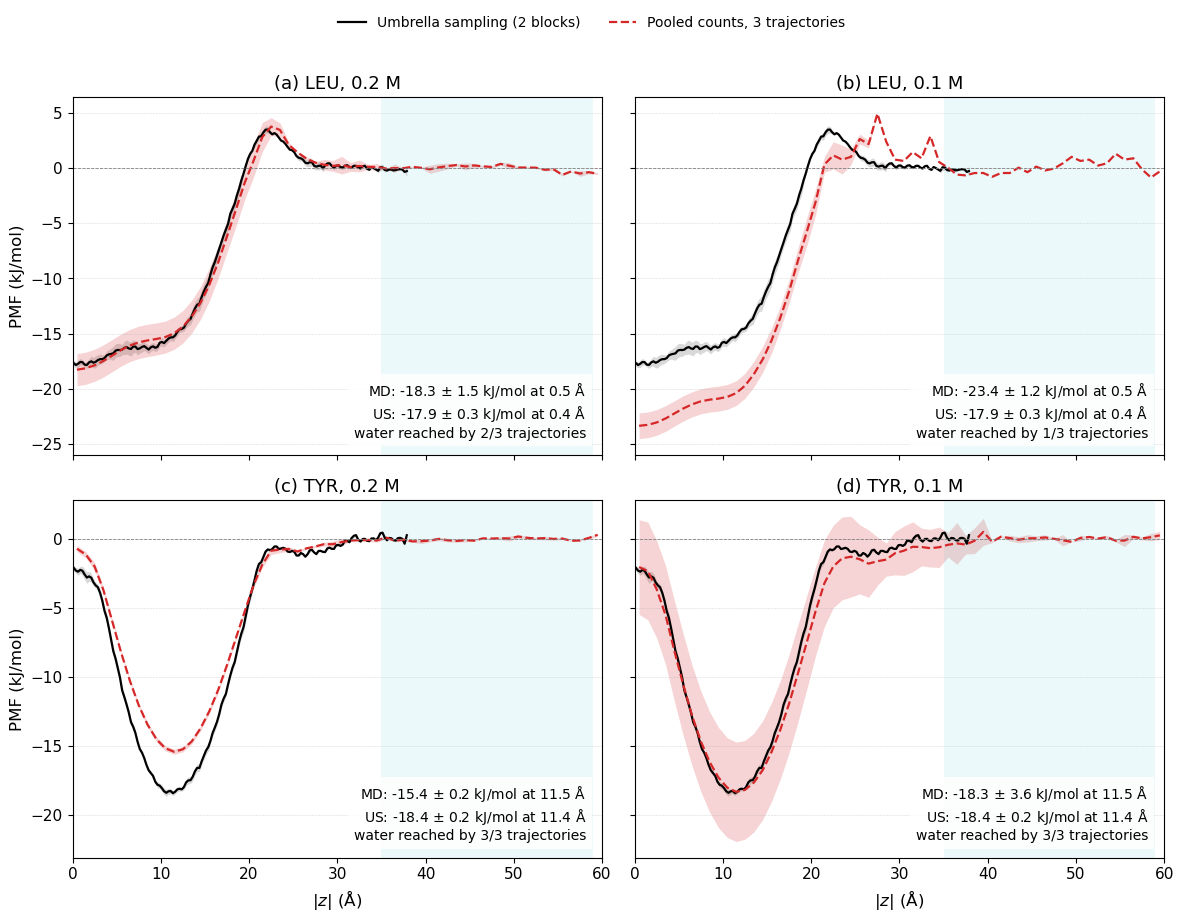

residue analog concentration water_counts_per_trajectory  minimum_kJ_mol  se_at_minimum_kJ_mol  z_minimum_A  US_minimum_kJ_mol  US_se_kJ_mol  minimum_minus_US_kJ_mol  min_defined_resample_fraction
    LEU    scl         0.2 M                 3869 0 7114         -18.281                 1.453          0.5            -17.855         0.253                   -0.426                          0.963
    LEU  scl-1         0.1 M                     688 0 0         -23.374                 1.167          0.5            -17.855         0.253                   -5.519                          0.704
    TYR    scy         0.2 M           12753 14414 11233         -15.410                 0.187         11.5            -18.418         0.181                    3.008                          1.000
    TYR  scy-1         0.1 M                 2936 3269 6         -18.318                 3.603         11.5            -18.418         0.181                    0.100                          0.963
Notes: MD water

In [61]:
# Pooled counts, water reference 35-59 A, 3 trajectory blocks (400-1000 ns each), LEU and TYR at 0.2 and 0.1 M vs US
# (independent cell). Each trajectory's three 200 ns count histograms are summed into one 600 ns block BEFORE the
# log; the PMF is -kT ln[C(z) / <C>_35-59 A]. SE: exact bootstrap over all 3^3 = 27 resamples of the trajectories,
# reference re-estimated in every replicate, x sqrt(3/2); replicates without water counts are excluded.
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESIDUES = {"scl": "LEU", "scy": "TYR"}
CONCENTRATIONS = {"": "0.2 M", "-1": "0.1 M"}
MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
KCAL_TO_KJ = 4.184
WATER_WINDOW = (35.0, 59.0)
GRID = np.arange(0.5, 60.0, 1.0)  # folded |z| bin centres 0.5-59.5 A (bilayer image appears beyond ~60 A)
N_TRAJ = 3
STYLE = {"font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "xtick.labelsize": 11,
         "ytick.labelsize": 11, "legend.fontsize": 10}
SAVE_NAME = f"FigureS_PMF_pooled_3traj_water35-59_leu_tyr_US_{MODE}"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def sampling_depth(analog, trajectory, summary, data_dir):
    size = summary.loc[(summary.residu == analog) & (summary.traj == trajectory), "n_lines"]
    if size.empty:
        raw_path = data_dir / "raw_data" / analog / f"{analog}_contacts_{trajectory}.dat"
        with raw_path.open("rb") as fh:
            if not fh.readline().startswith(b"#"):
                raise ValueError(f"Expected a header in raw data: {raw_path}")
            n_lines = sum(1 for line in fh if line.strip())
    else:
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] != int(size.iloc[0]):
            raise ValueError(f"Invalid sampling depth: {analog}, trajectory {trajectory}")
        n_lines = int(size.iloc[0])
    if n_lines <= 0 or n_lines % 3:
        raise ValueError(f"Invalid three-block sampling depth: {analog}, trajectory {trajectory}")
    return n_lines // 3


def trajectory_counts(analog, summary, data_dir):
    """Exact folded counts, one row per trajectory (3 x 200 ns blocks summed), on GRID."""
    rows = []
    for t in range(1, N_TRAJ + 1):
        arr = np.loadtxt(data_dir / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if (arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all()
                or (arr[:, 1:] < 0).any() or np.any(np.diff(arr[:, 0]) <= 0)):
            raise ValueError(f"Invalid distribution file: {analog}, trajectory {t}")
        if np.abs(arr[:, 0]).max() < GRID[-1]:
            raise ValueError(f"{analog} trajectory {t} does not reach {GRID[-1]} A")
        depth = sampling_depth(analog, t, summary, data_dir)
        keep = np.abs(arr[:, 0]) < GRID[-1] + 0.5
        idx = np.searchsorted(GRID, np.abs(arr[keep, 0]))
        if np.any(idx >= len(GRID)) or not np.allclose(GRID[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        folded = np.zeros(len(GRID))
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            if np.max(np.abs(unrounded - signed)) > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot recover counts: {analog}, trajectory {t}, block {b + 1}")
            np.add.at(folded, idx, signed[keep])
        rows.append(folded)
    return np.array(rows)


def water_referenced_pmf(counts):
    """counts (..., n_blocks, K) -> -kT ln[C / <C>_water]; NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    water = pooled[..., WATER].mean(axis=-1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / water)
    return np.where((pooled > 0) & (water > 0), pmf, np.nan)


def exact_bootstrap_se(values, n_blocks):
    """Population SD over the defined enumerated resamples, x sqrt(n/(n-1)); NaN if < 2 defined."""
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    mean = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    var = (np.where(finite, values - mean, 0.0) ** 2).sum(axis=0) / np.maximum(n_def, 1)
    se = np.sqrt(n_blocks / (n_blocks - 1)) * np.sqrt(var)
    return np.where(n_def > 1, se, np.nan), n_def / len(values)


def read_us(path):
    df = pd.read_csv(path, sep=r"\s+", comment="#", header=None, names=["z", "mean", "se", "n"])
    if (len(df) < 2 or not np.isfinite(df.to_numpy()).all() or (df["se"] < 0).any()
            or np.any(np.diff(df["z"]) <= 0) or df["n"].nunique() != 1 or df["n"].iloc[0] < 2):
        raise ValueError(f"Invalid umbrella PMF: {path}")
    df[["mean", "se"]] *= KCAL_TO_KJ
    return df


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
US_DIR = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
WATER = (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])
summary_table = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
resamples = np.array(list(product(range(N_TRAJ), repeat=N_TRAJ)))  # all 27 resamples

summary_rows, curve_rows = [], []
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(len(RESIDUES), len(CONCENTRATIONS), figsize=(12, 9), sharex=True, sharey="row")
    for r, (base, name) in enumerate(RESIDUES.items()):
        us = read_us(US_DIR / base / f"pmf-us-{base}.dat")
        i_us = int(us["mean"].idxmin())
        for c, (suffix, conc) in enumerate(CONCENTRATIONS.items()):
            analog = base + suffix
            counts = trajectory_counts(analog, summary_table, DATA_DIR)
            water_traj = counts[:, WATER].sum(axis=1).astype(int)
            if water_traj.sum() == 0:
                raise ValueError(f"{analog}: no counts in {WATER_WINDOW} A; water-referenced PMF undefined")
            mean = water_referenced_pmf(counts)
            se, defined = exact_bootstrap_se(water_referenced_pmf(counts[resamples]), N_TRAJ)
            min_defined = float(np.nanmin(np.where(np.isfinite(mean), defined, np.nan)))
            if min_defined < 1:
                print(f"WARNING: {name} {conc}: water counts in {int((water_traj > 0).sum())}/3 trajectories; "
                      f"SE conditional on {100 * min_defined:.1f}% defined resamples.")
            membrane = GRID <= 20
            i_min = int(np.nanargmin(np.where(membrane, mean, np.nan)))
            ax = axes[r, c]
            ax.fill_between(us["z"], us["mean"] - us["se"], us["mean"] + us["se"], color="black", alpha=0.15, lw=0)
            ax.plot(us["z"], us["mean"], color="black", lw=1.6,
                    label=f"Umbrella sampling ({int(us['n'].iloc[0])} blocks)")
            ax.fill_between(GRID, mean - se, mean + se, color="tab:red", alpha=0.2, lw=0)
            ax.plot(GRID, mean, color="tab:red", ls="--", lw=1.6, label="Pooled counts, 3 trajectories")
            ax.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
            ax.axhline(0, color="gray", lw=0.6, ls="--")
            ax.set_xlim(0, 60)
            ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
            ax.set_title(f"({chr(97 + r * len(CONCENTRATIONS) + c)}) {name}, {conc}")
            ax.text(0.97, 0.04,
                    f"MD: {mean[i_min]:.1f} $\\pm$ {se[i_min]:.1f} kJ/mol at {GRID[i_min]:.1f} $\\mathrm{{\\AA}}$\n"
                    f"US: {us['mean'][i_us]:.1f} $\\pm$ {us['se'][i_us]:.1f} kJ/mol at {us['z'][i_us]:.1f} $\\mathrm{{\\AA}}$\n"
                    f"water reached by {int((water_traj > 0).sum())}/3 trajectories",
                    transform=ax.transAxes, ha="right", va="bottom", fontsize=10,
                    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"})
            summary_rows.append({"residue": name, "analog": analog, "concentration": conc,
                                 "water_counts_per_trajectory": " ".join(map(str, water_traj)),
                                 "minimum_kJ_mol": float(mean[i_min]), "se_at_minimum_kJ_mol": float(se[i_min]),
                                 "z_minimum_A": float(GRID[i_min]), "US_minimum_kJ_mol": float(us["mean"][i_us]),
                                 "US_se_kJ_mol": float(us["se"][i_us]),
                                 "minimum_minus_US_kJ_mol": float(mean[i_min] - us["mean"][i_us]),
                                 "min_defined_resample_fraction": min_defined})
            curve_rows.extend({"residue": name, "analog": analog, "concentration": conc, "z_A": z,
                               "mean_kJ_mol": m, "se_kJ_mol": s, "defined_fraction": d}
                              for z, m, s, d in zip(GRID, mean, se, defined))
    for ax in axes[-1]:
        ax.set_xlabel(r"$|z|$ ($\mathrm{\AA}$)")
    for ax in axes[:, 0]:
        ax.set_ylabel("PMF (kJ/mol)")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False,
               bbox_to_anchor=(0.5, 1.03))
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    for extension in ("png", "pdf"):
        fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{extension}", dpi=600, bbox_inches="tight")
    plt.show()

summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_NAME}_summary.csv", index=False)
pd.DataFrame(curve_rows).to_csv(SAVE_DIR / f"{SAVE_NAME}_curves.csv", index=False)
print(summary.round(3).to_string(index=False))
print("Notes: MD water reference = mean pooled count per bin over 35-59 A (24 bins); US keeps its own water "
      "reference (|z| >= 30 A, its grid ends at 37.9 A). Only 3 trajectories: SEs from 3 units are themselves "
      "very uncertain.")


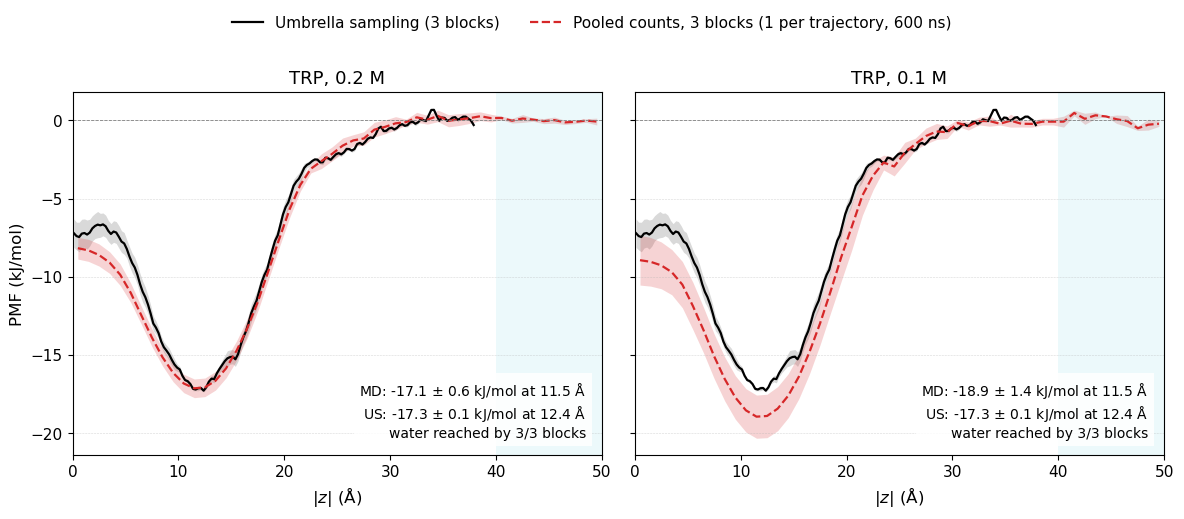

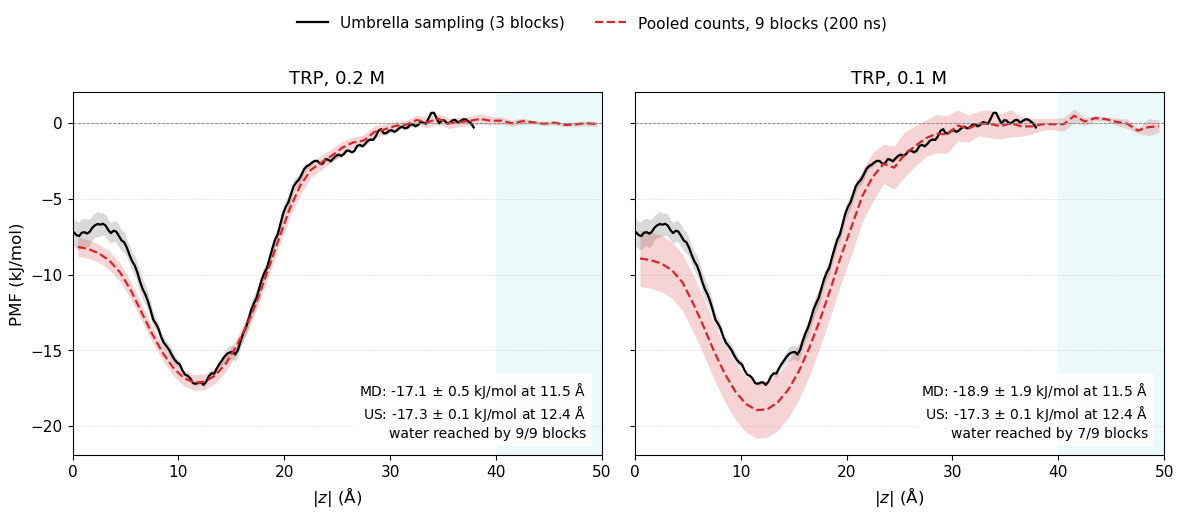

 n_blocks concentration analog  water_blocks  n_resamples  minimum_kJ_mol  se_at_minimum_kJ_mol  z_minimum_A  US_minimum_kJ_mol  US_se_kJ_mol  minimum_minus_US_kJ_mol  min_defined_resample_fraction
        3         0.2 M    scw             3           27         -17.132                 0.597         11.5            -17.281         0.089                    0.149                          1.000
        3         0.1 M  scw-1             3           27         -18.944                 1.381         11.5            -17.281         0.089                   -1.663                          1.000
        9         0.2 M    scw             9        10000         -17.132                 0.522         11.5            -17.281         0.089                    0.149                          1.000
        9         0.1 M  scw-1             7        10000         -18.944                 1.858         11.5            -17.281         0.089                   -1.663                          0.999
Notes: MD 

In [64]:
# TRP (SCW): umbrella sampling vs pooled counts at 0.2 M and 0.1 M, water reference (independent cell).
# Two figures: (1) 3 blocks, one per trajectory (400-1000 ns, three 200 ns histograms summed before the log),
# (2) 9 blocks of 200 ns. PMF = -kT ln[C(z) / <C>_water]; SE: block bootstrap with the reference re-estimated in
# every replicate, x sqrt(n/(n-1)) (3 blocks: all 27 resamples enumerated; 9 blocks: 10,000 resamples, seed 2025).
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALOG, NAME = "scw", "TRP"
CONCENTRATIONS = {"": "0.2 M", "-1": "0.1 M"}
MODE = "total"
K_B, TEMPERATURE = 0.008314, 303.15
KCAL_TO_KJ = 4.184
WATER_WINDOW = (40.0, 50.0)  # MD water reference (production convention)
GRID = np.arange(0.5, 50.0, 1.0)
N_BOOT, SEED = 10000, 2025
BLOCKINGS = {3: "3 blocks (1 per trajectory, 600 ns)", 9: "9 blocks (200 ns)"}
STYLE = {"font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "xtick.labelsize": 11,
         "ytick.labelsize": 11, "legend.fontsize": 11}
SAVE_PREFIX = f"FigureS_PMF_scw_US_pooled"


def find_repo_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "figures" / "data" / "distribution_data" / MODE).is_dir():
            return base
    raise FileNotFoundError("Run from within the Bories_and_Lague_2025 repository")


def sampling_depth(analog, trajectory, summary, data_dir):
    size = summary.loc[(summary.residu == analog) & (summary.traj == trajectory), "n_lines"]
    if size.empty:
        raw_path = data_dir / "raw_data" / analog / f"{analog}_contacts_{trajectory}.dat"
        with raw_path.open("rb") as fh:
            if not fh.readline().startswith(b"#"):
                raise ValueError(f"Expected a header in raw data: {raw_path}")
            n_lines = sum(1 for line in fh if line.strip())
    else:
        if len(size) != 1 or not np.isfinite(size.iloc[0]) or size.iloc[0] != int(size.iloc[0]):
            raise ValueError(f"Invalid sampling depth: {analog}, trajectory {trajectory}")
        n_lines = int(size.iloc[0])
    if n_lines <= 0 or n_lines % 3:
        raise ValueError(f"Invalid three-block sampling depth: {analog}, trajectory {trajectory}")
    return n_lines // 3


def block_counts(analog, summary, data_dir):
    """Exact folded counts of the 9 blocks (T1B1..T3B3) on GRID."""
    counts = []
    for t in (1, 2, 3):
        arr = np.loadtxt(data_dir / MODE / analog / f"trajectory{t}.dat", skiprows=1)
        if (arr.ndim != 2 or arr.shape[1] != 4 or not np.isfinite(arr).all()
                or (arr[:, 1:] < 0).any() or np.any(np.diff(arr[:, 0]) <= 0)):
            raise ValueError(f"Invalid distribution file: {analog}, trajectory {t}")
        depth = sampling_depth(analog, t, summary, data_dir)
        keep = np.abs(arr[:, 0]) < GRID[-1] + 0.5
        idx = np.searchsorted(GRID, np.abs(arr[keep, 0]))
        if np.any(idx >= len(GRID)) or not np.allclose(GRID[idx], np.abs(arr[keep, 0])):
            raise ValueError(f"{analog}: z bins are not centred on 0.5 + n A")
        for b in range(3):
            unrounded = arr[:, b + 1] * depth
            signed = np.rint(unrounded)
            if np.max(np.abs(unrounded - signed)) > 0.45 or signed.sum() != depth:
                raise ValueError(f"Cannot recover counts: {analog}, trajectory {t}, block {b + 1}")
            folded = np.zeros(len(GRID))
            np.add.at(folded, idx, signed[keep])
            counts.append(folded)
    return np.array(counts)


def water_referenced_pmf(counts):
    """counts (..., n_blocks, K) -> -kT ln[C / <C>_water]; NaN where the bin or the reference has no count."""
    pooled = counts.sum(axis=-2)
    water = pooled[..., WATER].mean(axis=-1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        pmf = -K_B * TEMPERATURE * np.log(pooled / water)
    return np.where((pooled > 0) & (water > 0), pmf, np.nan)


def bootstrap(counts):
    """Mean, SE and defined fraction; exact enumeration when n^n <= N_BOOT."""
    n = len(counts)
    exact = n ** n <= N_BOOT
    idx = (np.array(list(product(range(n), repeat=n))) if exact
           else np.random.default_rng(SEED).integers(0, n, size=(N_BOOT, n)))
    values = water_referenced_pmf(counts[idx])
    finite = np.isfinite(values)
    n_def = finite.sum(axis=0)
    centre = np.where(finite, values, 0.0).sum(axis=0) / np.maximum(n_def, 1)
    sq = (np.where(finite, values - centre, 0.0) ** 2).sum(axis=0)
    var = sq / np.maximum(n_def if exact else n_def - 1, 1)
    se = np.where(n_def > 1, np.sqrt(n / (n - 1)) * np.sqrt(var), np.nan)
    return water_referenced_pmf(counts), se, n_def / len(values), len(values)


def read_us(path):
    df = pd.read_csv(path, sep=r"\s+", comment="#", header=None, names=["z", "mean", "se", "n"])
    if (len(df) < 2 or not np.isfinite(df.to_numpy()).all() or (df["se"] < 0).any()
            or np.any(np.diff(df["z"]) <= 0) or df["n"].nunique() != 1 or df["n"].iloc[0] < 2):
        raise ValueError(f"Invalid umbrella PMF: {path}")
    df[["mean", "se"]] *= KCAL_TO_KJ
    return df


ROOT = find_repo_root()
DATA_DIR = ROOT / "figures" / "data" / "distribution_data"
US_PATH = ROOT / "figures" / "data" / "SUPP_umbrella_sampling" / "pmf" / ANALOG / f"pmf-us-{ANALOG}.dat"
SAVE_DIR = ROOT / "figures" / "plot"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
WATER = (GRID >= WATER_WINDOW[0]) & (GRID <= WATER_WINDOW[1])
summary_table = pd.read_csv(DATA_DIR / "raw_data_summary.dat", sep=r"\s+")
us = read_us(US_PATH)
i_us = int(us["mean"].idxmin())
counts9 = {conc: block_counts(ANALOG + suffix, summary_table, DATA_DIR) for suffix, conc in CONCENTRATIONS.items()}

summary_rows, curve_rows = [], []
for n_blocks, blocking in BLOCKINGS.items():
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(1, len(CONCENTRATIONS), figsize=(12, 5), sharey=True)
        for ax, (suffix, conc) in zip(axes, CONCENTRATIONS.items()):
            c9 = counts9[conc]
            counts = c9 if n_blocks == 9 else c9.reshape(3, 3, len(GRID)).sum(axis=1)
            water_blocks = int((counts[:, WATER].sum(axis=1) > 0).sum())
            if water_blocks == 0:
                raise ValueError(f"{ANALOG + suffix}: no counts in the water window")
            mean, se, defined, n_resamples = bootstrap(counts)
            min_defined = float(np.nanmin(np.where(np.isfinite(mean), defined, np.nan)))
            if min_defined < 1:
                print(f"WARNING: {NAME} {conc}, {n_blocks} blocks: SE conditional on "
                      f"{100 * min_defined:.1f}% defined resamples.")
            i_min = int(np.nanargmin(np.where(GRID <= 20, mean, np.nan)))
            ax.fill_between(us["z"], us["mean"] - us["se"], us["mean"] + us["se"], color="black", alpha=0.15, lw=0)
            ax.plot(us["z"], us["mean"], color="black", lw=1.6, label=f"Umbrella sampling ({int(us['n'].iloc[0])} blocks)")
            ax.fill_between(GRID, mean - se, mean + se, color="tab:red", alpha=0.2, lw=0)
            ax.plot(GRID, mean, color="tab:red", ls="--", lw=1.6, label=f"Pooled counts, {blocking}")
            ax.axvspan(*WATER_WINDOW, color="tab:cyan", alpha=0.08, lw=0)
            ax.axhline(0, color="gray", lw=0.6, ls="--")
            ax.set(xlim=(0, 50), xlabel=r"$|z|$ ($\mathrm{\AA}$)", title=f"{NAME}, {conc}")
            ax.grid(axis="y", ls="--", lw=0.4, alpha=0.5)
            ax.text(0.97, 0.04,
                    f"MD: {mean[i_min]:.1f} $\\pm$ {se[i_min]:.1f} kJ/mol at {GRID[i_min]:.1f} $\\mathrm{{\\AA}}$\n"
                    f"US: {us['mean'][i_us]:.1f} $\\pm$ {us['se'][i_us]:.1f} kJ/mol at {us['z'][i_us]:.1f} $\\mathrm{{\\AA}}$\n"
                    f"water reached by {water_blocks}/{n_blocks} blocks",
                    transform=ax.transAxes, ha="right", va="bottom", fontsize=10,
                    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"})
            summary_rows.append({"n_blocks": n_blocks, "concentration": conc, "analog": ANALOG + suffix,
                                 "water_blocks": water_blocks, "n_resamples": n_resamples,
                                 "minimum_kJ_mol": float(mean[i_min]), "se_at_minimum_kJ_mol": float(se[i_min]),
                                 "z_minimum_A": float(GRID[i_min]), "US_minimum_kJ_mol": float(us["mean"][i_us]),
                                 "US_se_kJ_mol": float(us["se"][i_us]),
                                 "minimum_minus_US_kJ_mol": float(mean[i_min] - us["mean"][i_us]),
                                 "min_defined_resample_fraction": min_defined})
            curve_rows.extend({"n_blocks": n_blocks, "concentration": conc, "z_A": z, "mean_kJ_mol": m,
                               "se_kJ_mol": s, "defined_fraction": d} for z, m, s, d in zip(GRID, mean, se, defined))
        axes[0].set_ylabel("PMF (kJ/mol)")
        fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False,
                   bbox_to_anchor=(0.5, 1.05))
        fig.tight_layout(rect=(0, 0, 1, 0.95))
        for extension in ("png", "pdf"):
            fig.savefig(SAVE_DIR / f"{SAVE_PREFIX}_{n_blocks}blocks_{MODE}.{extension}", dpi=600, bbox_inches="tight")
        plt.show()

summary = pd.DataFrame(summary_rows)
summary.to_csv(SAVE_DIR / f"{SAVE_PREFIX}_{MODE}_summary.csv", index=False)
pd.DataFrame(curve_rows).to_csv(SAVE_DIR / f"{SAVE_PREFIX}_{MODE}_curves.csv", index=False)
print(summary.round(3).to_string(index=False))
print("Notes: MD water reference 40-50 A; US keeps its own (|z| >= 30 A, grid ends at 37.9 A). "
      "With 3 blocks the SE is estimated from only three units and is itself very uncertain.")
